## Red Neuronal Convolucional (CNN) entrenada para dataset de detección visual de personajes de los Simpsons

**Evaluación Parcial 3: optimización y auditoría del Pipeline Integrado de Deep Learning.**

> **Dataset nuevo: 64 personajes, una carpeta por personaje. Variante GPU (Windows nativo + RTX 4060 Laptop).** Sigue el
> mismo proceso que el notebook del Perceptrón Multicapa sobre este dataset
> ([`../../PMC/notebooks/LosSimpsons_GPU_4060M.ipynb`](../../PMC/notebooks/LosSimpsons_GPU_4060M.ipynb)):
> la misma partición 70/20/10 sin tope por personaje, las mismas imágenes alteradas y parecidas, la misma
> imagen completa como entrada, los mismos pesos por clase, el mismo bucle de entrenamiento, el mismo criterio de
> acierto y los mismos KPIs. Cambia el modelo:
>
> 1. **Entran los píxeles.** La red recibe el tensor de 128 × 128 × 3 píxeles de la imagen completa, sin
>    aplanarlo y sin resumirlo en descriptores de color y textura elegidos a mano.
> 2. **Capas convolucionales.** Filtros de 3 × 3 que recorren la imagen con los mismos pesos en todas sus
>    posiciones, seguidos de normalización por lotes, ReLU y *max pooling*. La red aprende sus propios filtros.
> 3. **Experimentos propios de una CNN.** Además de los del MLP (activación, tasa de aprendizaje, batch,
>    dropout, pesos por clase, suavizado y alteradas), se comparan la profundidad, la cabeza
>    (pooling global frente a aplanado) y una entrada en escala de grises, que mide cuánto depende la red del
>    color.
> 4. **Grad-CAM.** El análisis de resultados muestra en qué zonas de la imagen se apoya la red para decidir, y
>    la última sección compara la corrida con la del MLP a la misma resolución.
>
> **Primero el modelo, después las cajas.** La red aprende y se evalúa con la imagen completa, y este notebook
> no usa ningún detector. Al final guarda el modelo con todo lo necesario para usarlo fuera de él
> (`cnn_final.keras`, `.json`, `_entrada.py` y `_particion.csv`); con esos archivos,
> `scripts/newDataset/detectar_cajas.py` encuentra después a cada personaje con un detector preentrenado
> (Grounding DINO) y la red nombra cada caja con su confianza, sin anotar nada a mano.
>
> Antes de ejecutarlo hay que correr una vez el script de alteraciones. El de cajas va después, con el modelo
> ya entrenado, y es opcional; los pasos están en [`README.md`](README.md).

#### Integrantes:

    - DIEGO IGNACIO PEÑA Y LILLO LUHRS
    - VINCENT FARENDEN CERÓN
    - RODRIGO IGNACIO MARTÍNEZ BECKER
    - IVÁN MANUEL PAVÓN BARRÍA

#### Asignatura:

    - TÉCNICAS AVANZADAS DE MACHINE LEARNING_001D

#### Profesor:

    - FRANCISCO JAVIER JEREZ SALAZAR

#### Fecha:

    - 19-10-2026

## Introducción

**El problema.** Este notebook vuelve sobre el problema de la Evaluación Parcial 1: dada una imagen RGB de Los
Simpson, decir qué personaje aparece en ella. Es una clasificación multiclase de etiqueta única: el modelo asigna exactamente un
personaje a cada imagen, con su confianza. El escenario de uso es el
de un archivo audiovisual que crece más rápido de lo que un equipo puede catalogarlo (ver «Problema de
negocio, objetivos y KPIs»).

**El conjunto de datos y la variante.** Se usa el dataset Los Simpson de Kaggle, uno de los cuatro que
autoriza la pauta, ampliado por el equipo a **64 personajes y 56.676 imágenes originales**, una carpeta por
personaje. La variante propia del grupo es esta: los 64 personajes con todas sus imágenes, sin tope por
personaje; una partición estratificada 70/20/10 con semilla 42; una variante alterada para un cuarto de las
imágenes de cada personaje, que va siempre al mismo conjunto que su original; las imágenes casi idénticas a
otra, reemplazadas por una versión filtrada; y un criterio de acierto estricto: la predicción acierta si nombra
al personaje de la carpeta. Las cajas alrededor de cada personaje se ponen después, con el modelo ya entrenado y
sin anotar nada a mano (`scripts/newDataset/detectar_cajas.py`). Respecto de la EP1 cambió el dataset: la
justificación técnica y la trazabilidad están en «Cambio de dataset respecto de la Evaluación Parcial 1».

**El objetivo.** Diseñar, entrenar y evaluar una red neuronal convolucional (CNN) que reciba la imagen
completa —el tensor de alto × ancho × 3 píxeles, sin aplanarlo— y aprenda sus propios filtros, en lugar de
recibir características elegidas a mano.

**Qué agrega la EP3.** Esta entrega reutiliza el pipeline de la EP2 y lo optimiza y audita, como piden los
indicadores IL 3.1 e IL 3.2: mide el aporte de cada técnica de regularización —Dropout, Batch Normalization, L2,
aumento de datos, suavizado de etiquetas y parada temprana—, selecciona la configuración con experimentos
controlados, audita el modelo con accuracy, precision, recall, F1, ROC-AUC, matrices de confusión, curvas de
aprendizaje y Grad-CAM, identifica los sesgos del dataset y compara objetivamente la CNN con el MLP.

**Por qué compararla con el Perceptrón Multicapa.** El MLP es la línea base del problema, y sus dos límites
son justamente los que una CNN promete resolver. Sobre los píxeles aplanados, el MLP pierde la vecindad entre
píxeles y su primera capa densa de 512 neuronas necesita 25,2 millones de pesos a 128 × 128; sobre
descriptores de color, confunde a los personajes que comparten paleta, empezando por la familia Simpson. La
CNN ataca esos dos límites con conectividad local, pesos compartidos y pooling. Para que la comparación mida
el efecto de la arquitectura y no de otra cosa, el MLP se volvió a entrenar sobre este mismo dataset con el
mismo proceso: la misma partición, las mismas imágenes alteradas y parecidas, los mismos pesos por clase, el
mismo bucle de entrenamiento, el mismo criterio de acierto y los mismos KPIs. Solo cambia el modelo. En su
corrida de GPU a 128 × 128 con la imagen completa, ese MLP llegó a una accuracy de test de 0,544 y a un F1
macro de 0,551.

**Dónde está cada punto de la pauta.** El notebook cubre lo que pide el encargo de la EP3:

| Requisito de la EP3 | Sección del notebook |
|---|---|
| Pipeline integrado: carga de datos, análisis exploratorio, preprocesamiento, modelo, entrenamiento, regularización, evaluación, auditoría y optimización | «Pipeline integrado», que enlaza cada etapa con su sección y sus funciones |
| Una MLP y una CNN optimizadas, entrenadas en condiciones comparables | «Experimentación: comparación de configuraciones» (CNN), el notebook del MLP (`PMC/notebooks/`) y «Comparación con el MLP» |
| Regularización: Dropout, Early Stopping, Data Augmentation, Batch Normalization y L2 | «Control del entrenamiento», «Efecto de la parada temprana» y «Efecto de las técnicas de regularización» |
| Optimización con experimentos controlados, un hiperparámetro a la vez | «Diseño de los experimentos», las secciones «Efecto de…» y «Selección del modelo final» |
| Auditoría: accuracy, precision, recall, F1, ROC-AUC, matriz de confusión y curvas de aprendizaje | «Curvas de aprendizaje del modelo base» y «Evaluación y métricas de desempeño», con «Curvas ROC y ROC-AUC» |
| XAI y sesgos del dataset | «En qué se apoya el modelo» y «Mapa de activación de cada clase» (Grad-CAM), «Análisis de resultados y de errores» e «Impacto ético» |
| Medidas para la robustez y la confiabilidad | «Limitaciones de la CNN y propuestas de mejora» e «Impacto ético» |
| Comparación objetiva entre la MLP y la CNN | «Comparación con el MLP»: desempeño, capacidad de generalización, interpretabilidad, tiempos y ventajas de cada arquitectura |
| Conclusiones | «Conclusiones» |

El informe técnico de la evaluación está en [`../docs/newDataset/Informe.md`](../docs/newDataset/Informe.md).

## Pipeline integrado

Esta entrega corresponde a la Evaluación Parcial 3: no reconstruye la solución, sino que reutiliza el pipeline de la
EP2 y lo optimiza y audita. El pipeline es el mismo para las dos redes: el MLP (`PMC/notebooks/`) y esta CNN comparten
la partición, las imágenes alteradas y parecidas, los pesos por clase, el bucle de entrenamiento, el criterio de
acierto y el formato del resumen de resultados. Solo cambia la función que construye el modelo.

```
Problema y KPIs
   ↓
Carga de datos ............ construir_indice(), cargar_y_redimensionar()
   ↓
Análisis exploratorio ..... dimensiones, alteradas, parecidas, escenas compartidas y desbalance
   ↓
Preprocesamiento .......... partición estratificada, tensor uint8, one-hot, compute_class_weight()
   ↓
Construcción del modelo ... construir_cnn(), compilar()
   ↓
Entrenamiento ............. entrenar(), _pasada(), a_gpu()
   ↓
Regularización ............ Dropout, Batch Normalization, L2, aumentar_lote(), suavizado y parada temprana
   ↓
Optimización .............. entrenar_configuracion(), registrar(), cabe_en_la_gpu()
   ↓
Evaluación ................ classification_report, confusion_matrix, roc_auc_score
   ↓
Auditoría ................. grad_cam(), mostrar_ejemplos(), confusiones, escenas y sesgos
   ↓
Reporte final ............. resumen JSON, comparación con el MLP y modelo guardado
```

| Etapa | Sección del notebook | Qué deja como evidencia |
|---|---|---|
| Problema | «Introducción», «Problema de negocio, objetivos y KPIs» y «Definición del problema de clasificación» | KPIs con umbrales fijados antes de entrenar |
| Carga de datos | «Carga de imágenes y etiquetas» | El índice de las imágenes, con su personaje, su tipo y su original |
| Análisis exploratorio | De «Dimensiones de las imágenes» a «Síntesis del análisis exploratorio» | Distribución por personaje, tamaños, alteradas, parecidas, escenas compartidas y desbalance |
| Preprocesamiento | «Partición y selección por personaje», «Redimensionado», «Normalización», «La imagen como tensor» y «Codificación de las etiquetas» | Una comprobación automática por paso |
| Construcción del modelo | «Modelo base: red neuronal convolucional (CNN)» | Arquitectura, justificación y resumen de parámetros |
| Entrenamiento | «Entrenamiento del modelo» | Curvas de aprendizaje y diagnóstico de sobreajuste |
| Regularización | «Control del entrenamiento», «Efecto de la parada temprana» y «Efecto de las técnicas de regularización» | Cada técnica con y sin ella, con curvas y la brecha entre entrenamiento y validación |
| Optimización | «Experimentación: comparación de configuraciones» | Tabla de experimentos y selección por F1 macro de validación |
| Evaluación | «Evaluación y métricas de desempeño» | Accuracy, precision, recall, F1, ROC-AUC, matriz de confusión y KPIs |
| Auditoría | «Análisis de resultados y de errores» e «Impacto ético» | Grad-CAM, errores, confusiones, escenas, tipos de imagen y sesgos |
| Reporte final | «Resumen de rendimiento de la corrida en la GPU», «Comparación con el MLP» y «Conclusiones» | `rendimiento_gpu_128x128.json`, `cnn_final.keras` y sus archivos |

**Por qué esta estructura.**

1. **Una responsabilidad por etapa.** Cada etapa recibe lo que produjo la anterior y deja una comprobación o una tabla
   antes de seguir: si algo falla, se sabe en qué etapa.
2. **La partición va antes que los píxeles.** Cada personaje se reparte en entrenamiento, validación y test antes de
   cargar ninguna imagen, y cada alterada sigue a su original: ninguna decisión posterior puede filtrar información
   del test.
3. **Las mismas funciones para todas las configuraciones.** `construir_cnn()` y `entrenar()` reciben como parámetros
   todos los factores que se experimentan —entrada, profundidad, activación, cabeza, dropout, Batch Normalization, L2,
   aumento de datos, pesos por clase y suavizado—, así que la base y cada variante salen del mismo código y lo único
   que las distingue es el factor que cambia.
4. **El mismo pipeline para el MLP y la CNN.** Las dos redes guardan su resumen con las mismas claves, lo que hace
   objetiva la comparación cifra a cifra.
5. **Cada etapa a la vista, en lugar de una función principal que las oculte.** La pauta pide documentar cada paso
   con texto, tablas y gráficos; por eso el pipeline se ejecuta celda a celda, y lo reutilizable queda en funciones
   documentadas y en los archivos del modelo final, que usan después `predecir_imagen()` y
   `scripts/newDataset/detectar_cajas.py`.

**Dónde se ejecuta.** El notebook se ejecuta en Windows sobre una RTX 4060 Laptop (ver «0. Verificación del entorno
GPU»). También corre en Google Colab con un entorno de GPU: la celda «Definición del conjunto de datos a utilizar»
detecta Colab, monta Google Drive y lee el dataset desde `MyDrive/simpsons_dataset`, con los archivos que genera el
script de alteraciones. La comparación con el MLP necesita su resumen en `PMC/resultados/` y la recreación de
personajes, el repositorio completo: sin ellos, esas celdas lo avisan y siguen. La corrida completa toma varias horas
en la RTX 4060 (ver «Resumen de rendimiento de la corrida en la GPU»); en una GPU de Colab puede superar el límite de
una sesión gratuita.


## 0. Verificación del entorno GPU

Antes de cargar datos o entrenar, esta sección confirma que PyTorch ve la GPU, que la
tarjeta responde y que una operación real se ejecuta en ella (no en la CPU).

El notebook corre en **Windows nativo**, sin WSL, con el mismo montaje que el del MLP: Keras 3 sobre el
backend de **PyTorch**, que sí tiene CUDA nativo en Windows (TensorFlow dejó de soportar GPU en Windows en la
versión 2.11). La arquitectura se define con Keras (`Conv2D`, `BatchNormalization`, `MaxPooling2D`, `Dense`)
y el bucle de entrenamiento es el mismo del MLP, escrito a mano sobre PyTorch.

Tres ajustes de rendimiento se activan aquí:

- **TF32**: las multiplicaciones de matrices y las convoluciones en `float32` pasan por los *tensor cores*
  de la arquitectura Ada sin tocar el modelo ni degradar el resultado de forma apreciable.
- **`cudnn.benchmark`**: cuDNN prueba varios algoritmos de convolución la primera vez que ve cada forma de
  tensor y se queda con el más rápido. Como todas las imágenes tienen el mismo tamaño, la prueba se paga una
  sola vez por configuración.
- **No se usa precisión mixta ni el formato `channels_first`**: se midieron en este equipo y apenas cambian el
  tiempo por época: menos de un 7 %. El costo no está en las convoluciones, sino
  en las operaciones elemento a elemento de `BatchNormalization`, que Keras calcula sin fusionar.

In [1]:
import os
import subprocess
import sys

# El backend de Keras debe quedar fijado ANTES de importar keras. El kernel
# "simpsons-gpu-win" ya lo trae en su bloque env; esta linea es la red de
# seguridad para cuando el notebook se abre con otro kernel.
os.environ.setdefault("KERAS_BACKEND", "torch")

import keras
import torch

print(f"Python : {sys.version.split()[0]}")
print(f"Keras  : {keras.__version__}   (backend: {keras.backend.backend()})")
print(f"PyTorch: {torch.__version__}   (compilado para CUDA {torch.version.cuda})")

if keras.backend.backend() != "torch":
    raise RuntimeError(
        f'Keras esta usando el backend "{keras.backend.backend()}". Este notebook '
        "necesita el backend de PyTorch: reinicia el kernel para que KERAS_BACKEND=torch "
        "tenga efecto, o selecciona el kernel 'Python 3.13 (Simpsons GPU Windows)'."
    )

try:
    salida_nvidia_smi = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv,noheader"],
        capture_output=True, text=True, check=True,
    ).stdout.strip()
    print(f"nvidia-smi: {salida_nvidia_smi}")
except (FileNotFoundError, subprocess.CalledProcessError) as error:
    print(f"nvidia-smi no disponible: {error}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "PyTorch no detecta ninguna GPU. Este notebook se ejecuta en Windows nativo "
        "sobre el entorno .venv-gpu: lanzalo con CNN/scripts/newDataset/ejecutar_notebook_gpu.ps1 y "
        "comprueba que 'nvidia-smi' responde en esa misma terminal."
    )

DISPOSITIVO = "cuda"
mayor, menor = torch.cuda.get_device_capability(0)
propiedades = torch.cuda.get_device_properties(0)
print(f"\nGPUs visibles para PyTorch: {torch.cuda.device_count()}")
print(f"  - {torch.cuda.get_device_name(0)}")
print(f"    compute capability : {mayor}.{menor}")
print(f"    VRAM total         : {propiedades.total_memory / 1024 ** 3:.2f} GB")
print(f"    multiprocesadores  : {propiedades.multi_processor_count}")

# TF32: las multiplicaciones de matrices en float32 pasan por los tensor cores de
# Ada. Se gana velocidad sin cambiar una linea del modelo.
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
# cudnn.benchmark: con imagenes de tamano fijo, cuDNN prueba una vez los algoritmos de
# convolucion para cada forma de tensor y reutiliza el mas rapido en todos los pasos.
torch.backends.cudnn.benchmark = True

# Prueba real: una multiplicacion de matrices que debe ejecutarse en la GPU.
prueba = torch.randn(4096, 4096, device=DISPOSITIVO)
resultado = prueba @ prueba
torch.cuda.synchronize()
assert resultado.is_cuda, "La operacion de prueba no se ejecuto en la GPU"
print(f"\nOperacion de prueba ejecutada en: {resultado.device}")
del prueba, resultado
torch.cuda.empty_cache()

# Aviso util: con el portatil desenchufado el firmware recorta la potencia de la
# GPU y los tiempos se duplican. Merece la pena verlo antes de entrenar.
try:
    limite, limite_max = subprocess.run(
        ["nvidia-smi", "--query-gpu=power.limit,power.max_limit", "--format=csv,noheader,nounits"],
        capture_output=True, text=True, check=True,
    ).stdout.strip().split(", ")
    print(f"Limite de potencia de la GPU: {float(limite):.0f} W de {float(limite_max):.0f} W posibles")
    if float(limite) < 0.7 * float(limite_max):
        print("  AVISO: limite bajo. Conecta el equipo a la corriente y pon el plan de "
              "energia en maximo rendimiento antes de medir tiempos.")
except Exception:
    pass

print("\nEntorno GPU verificado correctamente.")

Python : 3.13.15
Keras  : 3.15.1   (backend: torch)
PyTorch: 2.14.0+cu130   (compilado para CUDA 13.0)
nvidia-smi: NVIDIA GeForce RTX 4060 Laptop GPU, 617.42, 8188 MiB

GPUs visibles para PyTorch: 1
  - NVIDIA GeForce RTX 4060 Laptop GPU
    compute capability : 8.9
    VRAM total         : 8.00 GB
    multiprocesadores  : 24



Operacion de prueba ejecutada en: cuda:0

Entorno GPU verificado correctamente.


## Definición del Dataset

Nuestro conjunto de datos es una carpeta por personaje, sin una partición previa en entrenamiento y prueba: cada carpeta reúne imágenes de ese personaje desde varios puntos de vista. Se construyó a partir del dataset público de Kaggle y el equipo lo amplió con más personajes y con fotogramas propios. En algunas carpetas hay imágenes cuyo nombre de archivo corresponde a otro personaje: son fotogramas elegidos porque en ellos el protagonista es el personaje de la carpeta. Por eso **la etiqueta de cada imagen la da siempre su carpeta, nunca el nombre del archivo.**

Nosotros escogimos este dataset debido a la gran popularidad de los personajes y porque tienen una identidad gráfica extremadamente reconocible: piel amarilla, siluetas simples, colores fuertes y personajes fáciles de distinguir incluso con pocos detalles. Su diseño es consistente y memorable, lo que hace que la serie destaque inmediatamente frente a otras animaciones.

| Dato | Valor |
|---|---|
| Personajes | 64 |
| Imágenes originales | 56.676 al 09-11-2026 (unos 3,4 GB), casi todas `.jpg`, con 30 `.png` y 2 `.webp` |
| Imágenes por personaje | De 3.118 (`homer_simpson`) a 151 (`maggie_simpson`) |
| Tamaño de las imágenes | De 38 × 42 a 2.700 × 3.600 píxeles; mediana 960 × 720 |

Además de las originales, el script `scripts/newDataset/generar_imagenes_alteradas.py` guarda en cada carpeta una variante alterada de un cuarto de sus imágenes, con el nombre `<original>__alterada.<ext>`, y, para cada imagen casi idéntica a otra del mismo personaje, una versión filtrada `<original>__parecida.<ext>` que el notebook usa en su lugar. El dataset no se versiona en el repositorio.

**Primero el modelo, después las cajas.** El notebook entrena y evalúa la CNN con la imagen completa: no
necesita cajas, ni el script de cajas, ni ningún archivo que este genere. Las cajas son un paso posterior y
separado: `scripts/newDataset/detectar_cajas.py` carga el modelo final que guarda este notebook (`cnn_final.keras`
y sus archivos), encuentra a cada personaje con un detector preentrenado (Grounding DINO) y le pone nombre con
su confianza, sin anotar nada a mano (ver «Probar el modelo con una imagen cualquiera»).

![Homero](../images/homero.png) ![Lisa](../images/lisa.png)

### Cambio de dataset respecto de la Evaluación Parcial 1

La pauta pide reutilizar preferentemente el conjunto de datos de la EP1 o justificar técnicamente el cambio y
mantener la trazabilidad con el trabajo anterior. Aquí el dataset cambió:

| | EP1 (MLP) | EP2 y EP3 (MLP reentrenado y CNN) |
|---|---|---|
| Fuente | Los Simpson de Kaggle (usuario `alfaro96`), con sus carpetas `train` y `test` | La misma fuente, ampliada por el equipo con más personajes y con fotogramas propios |
| Personajes | 25 | 64 |
| Imágenes originales | 20.074: 16.137 en `train` y 3.937 en `test` | 56.676 |
| Partición | La de Kaggle, de criterio no documentado; `train` se dividió en entrenamiento y validación (12.909 y 3.228) con semilla 42 | Propia: 70 / 20 / 10 por personaje, estratificada y con semilla 42 |
| Casi duplicados entre conjuntos | No se verificaban: el informe de la EP1 deja como supuesto que no hay duplicados entre `train` y `test` | 9.042 imágenes casi idénticas a otra entran con una versión filtrada, y cada alterada va al mismo conjunto que su original |
| Información de escena | No | 43.138 de las 70.855 imágenes de trabajo (el 60,9 %) son fotogramas con episodio e instante en el nombre |

**Por qué se cambió.**

1. **Más cerca del escenario de uso.** Un archivo audiovisual no tiene solo a los 25 personajes más conocidos:
   también a los secundarios. Con 64 personajes aparecen además los que se parecen entre sí —Patty y Selma,
   Carl y Lenny, los Flanders—, que son la prueba más exigente para comparar lo que aprende cada arquitectura.
2. **Más datos para aprender filtros.** Una CNN aprende sus filtros de los píxeles y necesita más ejemplos que
   un MLP sobre descriptores elegidos a mano. El dataset nuevo tiene casi el triple de imágenes originales.
3. **Una partición que se puede auditar.** En la EP1 la separación entre `train` y `test` venía dada y no se
   podía comprobar que una misma escena no estuviera en los dos. Ahora el notebook reparte cada personaje, filtra
   las imágenes casi idénticas y mantiene cada variante alterada en el conjunto de su original, de modo que el
   test no premia haber memorizado una toma.
4. **Escenas compartidas.** Los fotogramas con episodio e instante permiten estimar quién más aparece en cada
   escena (ver «Escenas con varios personajes») y evaluar con justicia las imágenes con varios personajes.

**Trazabilidad.** El trabajo de la EP1 se conserva en el repositorio: su notebook de GPU está en
`PMC/notebooks/oldDataset/`, su informe en `PMC/docs/oldDataset/Informe.md` y sus resultados en
`PMC/resultados/oldDataset/`. Su MLP final (E2, con 51.002.393 parámetros) alcanzó una accuracy de test de
0,517 en la GPU sobre los 25 personajes. Para la comparación de esta evaluación, el MLP se volvió a
entrenar sobre el dataset nuevo (`PMC/notebooks/newDataset/`) con el mismo proceso que esta CNN: ese es el MLP
de «Comparación con el MLP». Las cifras de la EP1 no se comparan con las de este notebook porque miden otros
personajes sobre otra partición. El mismo script, `scripts/newDataset/generar_imagenes_alteradas.py`, prepara
el dataset para las dos redes.

## Problema de negocio, objetivos y KPIs

### Contexto y problema de negocio

Un archivo audiovisual crece mucho mas rapido de lo que un equipo humano puede
catalogarlo. Miles de fotogramas sin etiquetar son material practicamente inservible:
no se pueden buscar, no se pueden reutilizar y no permiten medir nada. Hoy esa
catalogacion se hace a mano, imagen por imagen, y su costo crece de forma lineal con
el tamano del archivo.

**Problema de negocio.** *El archivo de imagenes crece mas rapido de lo que el equipo
puede catalogarlo manualmente, lo que impide buscar material por personaje, encarece
cada proyecto de reutilizacion de contenido y deja sin explotar el catalogo
acumulado.*

Este proyecto aborda ese problema sobre un archivo de **56.676 imagenes (unos 3,4 GB)**
de 64 personajes de Los Simpson: asignar automaticamente el personaje que aparece en
cada imagen, para que el archivo pase de ser un conjunto de ficheros sueltos a un
catalogo consultable.

| Caso de uso | Que habilita el modelo |
|---|---|
| Busqueda en el archivo | Recuperar todos los planos de un personaje para un montaje, un trailer o un recopilatorio tematico. |
| Pre-clasificacion asistida | El modelo propone y una persona valida: convierte trabajo de *etiquetar* en trabajo de *revisar*, que es mucho mas rapido. |
| Metricas de contenido | Cuantificar la presencia en pantalla de cada personaje, dato relevante para licenciamiento y merchandising. |
| Control de uso de marca | Detectar personajes con derechos dentro de material aportado por terceros. |

### Objetivos del proyecto

**Objetivo general.** Implementar y evaluar una red neuronal convolucional (CNN) capaz
de asignar a cada imagen RGB uno de los 64 personajes del catalogo, mediante un flujo
reproducible cuyo desempeno se mida frente a referencias triviales y de forma
sensible al desbalance de clases.

**Objetivos especificos.**

1. Indexar las imagenes disponibles y asociar cada ruta con el personaje de su carpeta.
2. Repartir todas las imagenes de cada personaje en entrenamiento (70 %), validacion
   (20 %) y prueba (10 %) de forma estratificada y con semilla fija; cada variante
   alterada acompana a su imagen original, de modo que los tres conjuntos tienen las
   mismas condiciones.
3. Preparar los datos para la CNN: conversion a RGB, redimensionado a un tamano fijo,
   tensores de imagen sin aplanar, normalizacion y codificacion one-hot de las etiquetas.
4. Entrenar un modelo base y compararlo con variantes controladas de representacion de
   entrada, arquitectura e hiperparametros, cambiando un factor a la vez.
5. Seleccionar la configuracion final por F1 macro de validacion y medirla una sola
   vez sobre el conjunto de prueba.
6. Auditar el resultado: metricas por clase, matriz de confusion, aciertos, errores, zonas
   de la imagen en que se apoya la red (Grad-CAM) y comparacion con el MLP.

### KPIs del proyecto

Los umbrales se fijan **antes** de evaluar el modelo y traducen el escenario de uso a
cantidades medibles sobre los datos. El cumplimiento se verifica al final de la
seccion de evaluacion, con las cifras obtenidas en la prueba final.

**Criterio de acierto.** Cada imagen entra completa al modelo y una prediccion es
correcta solo si nombra al personaje de su carpeta. Con ese criterio se miden la
validacion, todas las metricas de prueba y los KPIs. Nombrar a otro personaje de la
escena no cuenta como acierto: la accuracy por escena, que si lo acepta, se informa
solo como referencia.

| KPI | Que mide en el negocio | Metrica tecnica | Umbral |
|---|---|---|---|
| Cobertura de asistencia | Con que frecuencia el catalogador encuentra la respuesta correcta entre las tres sugerencias del sistema. | Top-3 accuracy en test | >= 0,70 |
| Equidad entre personajes | Que el catalogo sirva para todos los personajes y no solo para los mas frecuentes. | F1 macro en test | >= 0,45 |
| Automatizacion sin revision | Proporcion de imagenes que el sistema resuelve sin intervencion humana. | Accuracy en test | >= 0,50 |
| Ventaja sobre el criterio trivial | Que el sistema aporte informacion real frente a etiquetar todo como el personaje mas comun. | Accuracy / baseline mayoritaria | >= 4x |
| Costo de catalogacion | Capacidad de procesar el archivo completo en un tiempo razonable. | Imagenes por segundo (entrada + inferencia) | >= 1.000 img/s |

La eleccion de **top-3 accuracy** y **F1 macro** como KPIs principales no es casual:
el sistema esta pensado como asistente de un catalogador, no como reemplazo, y un
catalogo que solo reconoce a los personajes mayoritarios no resuelve el problema de
busqueda. Por eso la seleccion de modelo se hace por F1 macro y no por accuracy.

> Las imagenes se trabajan a 128x128. A diferencia del MLP, la CNN recibe la
> imagen completa como un tensor de 128 x 128 x 3 (49.152 valores), sin aplanarlo y sin
> resumirlo en descriptores. Los umbrales de los KPIs son los mismos del MLP, para que
> las dos redes se midan con la misma vara.

## Definición del problema de clasificación

El problema que abordamos es de **clasificación multiclase de etiqueta única**: dada una imagen RGB que contiene a un personaje de Los Simpsons, el modelo debe asignarle **exactamente una** de las 64 clases posibles (una por personaje), con su confianza. El modelo se entrena y se evalúa con la imagen completa. Las cajas alrededor de cada personaje son un paso posterior y separado: con el modelo ya entrenado, `scripts/newDataset/detectar_cajas.py` encuentra a cada personaje con un detector preentrenado (Grounding DINO), que no sabe quién es, y el modelo nombra cada caja —por ejemplo, `Jasper Beardly · 92 %`—. Ese paso no interviene en el entrenamiento ni en la evaluación de este notebook.

**Alcance verificable del trabajo.** El escenario descrito en la sección anterior es el marco de uso declarado del proyecto, no un encargo de un cliente real: no hay contrato, operación comercial ni cifras económicas que permitan calcular un retorno monetario. Por eso los KPIs se expresan en cantidades medibles sobre los datos disponibles y no en unidades de dinero.

**Variante definida: 64 personajes, una carpeta por personaje.** El dataset ya no trae una partición en `train` y `test`: el notebook recorre cada carpeta y reparte todas sus imágenes originales en entrenamiento (70 %), validación (20 %) y prueba (10 %), de forma estratificada y con semilla fija. Los tres conjuntos conservan la distribución real del dataset y tienen las mismas condiciones: las originales que les tocan, la versión filtrada de las que eran casi idénticas a otra del mismo personaje (ver «Imágenes parecidas») y la variante alterada de un cuarto de ellas, que siempre va al mismo conjunto que su original. No hay tope por personaje: el entrenamiento usa todas las originales que le corresponden.

**Criterios de éxito observables.** El desempeño se interpreta frente a tres referencias que calcula el notebook: accuracy aleatoria (1/64 ≈ 1,6 %), accuracy de predecir siempre la clase mayoritaria (en torno al 5,5 %, la proporción de `homer_simpson` en el dataset) y F1 macro, que da el mismo peso a los 64 personajes. También se reportan precision, recall, F1 por clase, matriz de confusión y top-3 accuracy. No se fijan umbrales nuevos a posteriori: los de los KPIs se declaran antes de entrenar, en la sección «Problema de negocio, objetivos y KPIs», y su cumplimiento se verifica al cerrar la sección de evaluación. Lo mismo vale para el criterio de acierto: en la prueba, una predicción es correcta si nombra al personaje de la carpeta.

**Entrada y salida**

- **Entrada (X):** la imagen RGB completa, de tamaño variable (entre 38 × 42 y 2.700 × 3.600 px; mediana 960 × 720). Se redimensiona a 128 × 128 y entra a la red como un tensor de 128 × 128 × 3 píxeles normalizados, sin aplanar: las capas convolucionales trabajan sobre la vecindad de cada píxel.
- **Salida (y):** vector de 64 probabilidades (activación *softmax*); la clase predicha es la de mayor probabilidad.
- **Función de pérdida:** entropía cruzada categórica (*categorical crossentropy*).

**Conjuntos de datos**

| Conjunto | Contenido | Distribución |
|---|---|---|
| Entrenamiento | 70 % de las originales de cada personaje, más sus variantes alteradas | Real |
| Validación | 20 % de las originales de cada personaje, más sus variantes alteradas | Real |
| Prueba | 10 % de las originales de cada personaje, más sus variantes alteradas | Real |

Las cifras exactas de cada conjunto las imprime la sección de pre-procesamiento.

**Desbalance de clases**

En el dataset completo las clases están muy desbalanceadas: desde 3.118 imágenes de `homer_simpson` hasta 151 de `maggie_simpson` (razón aproximada de 21:1). Esa razón se mantiene en entrenamiento, porque se usan todas las imágenes, y se compensa con pesos por clase **suavizados** (la raíz cuadrada de los balanceados): los personajes pequeños pesan más, sin que el modelo deje de reconocer a los frecuentes. Validación y prueba se miden sobre la distribución real, donde la *accuracy* favorece a los personajes frecuentes y el F1 macro a los escasos.

**Baselines de referencia**

- Clasificador aleatorio: 1/64 ≈ **1,6 %** de accuracy.
- Clasificador de clase mayoritaria (predecir siempre `homer_simpson`): en torno al **5,5 %** en prueba, la proporción de ese personaje en el dataset.

Cualquier modelo útil debe superar claramente estos valores.

**Métricas de evaluación**

Además de la *accuracy* global se reportarán **precision, recall y F1-score por clase**, el **F1 macro** (que pondera igual a todas las clases, mostrando el efecto del desbalance) y la **matriz de confusión**, útil para detectar confusiones sistemáticas entre personajes visualmente parecidos (por ejemplo, Bart y Milhouse, o Lisa y Maggie).

**Dificultades esperadas**

Los personajes aparecen en múltiples poses, con distintos encuadres, escalas y fondos, y con variaciones de color debidas a las diferentes temporadas. A esto se suman personajes parcialmente ocluidos o acompañados por otros en la misma escena. Con 64 personajes aparecen además secundarios muy parecidos entre sí —Patty y Selma, o los distintos miembros de la familia Flanders— y cuatro con menos de 250 imágenes en total.

**Supuestos**

Se asume que cada imagen tiene un único personaje **principal**: el que da nombre a su carpeta. Puede haber otros en el encuadre: el modelo aprende y se evalúa con la etiqueta de la carpeta, y nombrar a cada uno por separado queda para el script de cajas, después del entrenamiento. La sección «Escenas con varios personajes» estima quién más aparece a partir de los fotogramas de episodio y de las imágenes casi idénticas guardadas en la carpeta de otro personaje, pero ya no cambia el acierto: solo alimenta una métrica de referencia. Se comprobó que el dataset no contiene archivos duplicados byte a byte, de modo que una misma imagen no puede caer a la vez en entrenamiento y prueba. Sí contiene imágenes casi idénticas —fotogramas seguidos de una escena, recortes repetidos—: el script las detecta y, de cada grupo, todas menos una entran con una versión filtrada, para que el modelo no acierte en prueba solo porque vio casi la misma imagen al entrenar. Cada variante alterada entra al mismo conjunto que su original: nunca hay una imagen en un conjunto y su variante en otro.

## Carga, análisis exploratorio y pre-procesamiento de los datos

En esta sección se cargan y exploran los datos y se preparan para que puedan ser consumidos por una red
convolucional: se indexan las carpetas de los personajes, se reparte cada uno en entrenamiento, validación y prueba,
se analizan las dimensiones de las imágenes, las alteradas y las parecidas, las escenas con varios personajes y el
desbalance de clases (ver «Síntesis del análisis exploratorio»), se cargan y redimensionan las imágenes, se comprueba
la normalización de los píxeles, se dejan como tensores de imagen sin aplanar y se codifican las etiquetas.


### Definición del conjunto de datos a utilizar

In [2]:
import os
import sys
from datetime import datetime
from pathlib import Path

# Marca de inicio de la corrida. La seccion de rendimiento del final del notebook
# la usa para calcular la hora de termino y la duracion total.
INICIO_CORRIDA = datetime.now()
print(f"Inicio de la corrida: {INICIO_CORRIDA:%Y-%m-%d %H:%M:%S}\n")

# En Google Colab el dataset se lee desde Google Drive: se monta la unidad y se busca la carpeta en
# MyDrive/simpsons_dataset, salvo que SIMPSONS_DATASET indique otra ruta
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and "SIMPSONS_DATASET" not in os.environ:
    from google.colab import drive

    drive.mount("/content/drive")
    os.environ["SIMPSONS_DATASET"] = "/content/drive/MyDrive/simpsons_dataset"

# Una carpeta por personaje, sin particion previa. La ruta se puede fijar con la
# variable SIMPSONS_DATASET (la que usa Docker); si no existe, se busca en el escritorio.
DATASET_BASE = Path(
    os.environ.get("SIMPSONS_DATASET", Path.home() / "Desktop" / "simpsons_dataset")
)

SEMILLA = 42
CONJUNTOS = ("train", "val", "test")
# Proporciones sobre TODAS las imagenes originales de cada personaje, sin tope:
# los tres conjuntos conservan la distribucion real del dataset.
PROPORCIONES = {"train": 0.70, "val": 0.20, "test": 0.10}
# Por debajo de este numero de originales un personaje no se puede repartir en tres
# conjuntos estratificados con un minimo de ejemplos en cada uno.
MINIMO_POR_PERSONAJE = 30

if not DATASET_BASE.is_dir():
    raise FileNotFoundError(f"No existe el dataset: {DATASET_BASE}")
if (DATASET_BASE / "train").is_dir() or (DATASET_BASE / "test").is_dir():
    raise ValueError(
        f"{DATASET_BASE} tiene la estructura antigua (train/ y test/). Este notebook trabaja "
        "con una carpeta por personaje; el del dataset anterior esta en PMC/notebooks/oldDataset/."
    )

print(f"Entorno       : {'Google Colab' if EN_COLAB else 'local'}")
print(f"Dataset       : {DATASET_BASE}")
print("Entrada       : la imagen completa (las cajas se ponen después, con el modelo ya entrenado)")
print(f"Particion     : {', '.join(f'{nombre} {proporcion:.0%}' for nombre, proporcion in PROPORCIONES.items())}")
print("Tope de train : ninguno, se usan todas las originales")
print(
    "\nEl conjunto de test se reserva intacto: no se usa para ajustar pesos"
    " ni para elegir hiperparámetros, solo para la comprobación final."
)

Inicio de la corrida: 2026-11-13 21:40:25

Entorno       : local
Dataset       : C:\Users\LaptopWin\Desktop\simpsons_dataset
Entrada       : la imagen completa (las cajas se ponen después, con el modelo ya entrenado)
Particion     : train 70%, val 20%, test 10%
Tope de train : ninguno, se usan todas las originales

El conjunto de test se reserva intacto: no se usa para ajustar pesos ni para elegir hiperparámetros, solo para la comprobación final.


### Carga de imágenes y etiquetas

In [3]:
import pandas as pd

EXTENSIONES_VALIDAS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
# Sufijos con los que el script de alteraciones marca las imagenes que genera: una
# alterada es una variante extra que va al mismo conjunto que su original; una parecida
# reemplaza a su original
MARCA_ALTERADA = "__alterada"
MARCA_PARECIDA = "__parecida"


def construir_indice(directorio):
    """Recorre un directorio con una subcarpeta por personaje y devuelve un DataFrame con
    la ruta de cada imagen, su personaje y, para las alteradas, la original de la que
    provienen. Si el script reemplazó una original casi idéntica a otra por su versión
    __parecida, la fila de esa original apunta a la versión parecida. La etiqueta sale
    siempre de la carpeta, nunca del nombre del archivo."""
    registros = []

    for carpeta_clase in sorted(directorio.iterdir()):
        if not carpeta_clase.is_dir() or carpeta_clase.name.startswith("."):
            continue

        archivos = sorted(carpeta_clase.iterdir())
        nombres = {ruta.name for ruta in archivos}
        for ruta in archivos:
            # Las parecidas no son imágenes nuevas: entran abajo, en el lugar de su original
            if ruta.suffix.lower() not in EXTENSIONES_VALIDAS or ruta.stem.endswith(MARCA_PARECIDA):
                continue
            alterada = ruta.stem.endswith(MARCA_ALTERADA)
            # Para una original, su origen es ella misma
            origen = ruta.stem.removesuffix(MARCA_ALTERADA) + ruta.suffix if alterada else ruta.name
            reemplazo = f"{ruta.stem}{MARCA_PARECIDA}{ruta.suffix}"
            parecida = not alterada and reemplazo in nombres
            registros.append(
                {
                    "ruta": ruta.with_name(reemplazo) if parecida else ruta,
                    "personaje": carpeta_clase.name,
                    "alterada": alterada,
                    "parecida": parecida,
                    "origen": origen,
                }
            )

    if not registros:
        raise FileNotFoundError(f"No se encontraron imagenes en: {directorio}")

    return pd.DataFrame(registros)


# Índice de todo el dataset: originales y alteradas
indice_completo = construir_indice(DATASET_BASE)

resumen = (
    indice_completo.groupby("personaje")
    .agg(
        originales=("alterada", lambda serie: int((~serie).sum())),
        alteradas=("alterada", "sum"),
        parecidas=("parecida", "sum"),
    )
    .astype(int)
    .sort_values("originales", ascending=False)
    .reset_index()
)
resumen["porcentaje"] = (resumen["originales"] / resumen["originales"].sum() * 100).round(2)

n_originales = int(resumen["originales"].sum())
n_alteradas = int(resumen["alteradas"].sum())
n_parecidas = int(resumen["parecidas"].sum())
print(f"Dataset: {n_originales} imagenes originales y {n_alteradas} alteradas en {len(resumen)} personajes")
print(f"De las originales, {n_parecidas} eran casi identicas a otra y entran con su version filtrada (__parecida)")
if n_alteradas == 0:
    print(
        "AVISO: no hay imagenes alteradas. Ejecuta antes "
        "scripts/newDataset/generar_imagenes_alteradas.py; el notebook funciona sin ellas, "
        "pero el entrenamiento no tendra variantes de color y textura."
    )

display(resumen)

Dataset: 56676 imagenes originales y 14179 alteradas en 64 personajes
De las originales, 9042 eran casi identicas a otra y entran con su version filtrada (__parecida)


,personaje,originales,alteradas,parecidas,porcentaje
0,homer_simpson,3118,780,466,5.50
1,bart_simpson,1940,485,316,3.42
2,ned_flanders,1784,446,460,3.15
3,lisa_simpson,1771,443,318,3.12
4,marge_simpson,1766,442,351,3.12
...,...,...,...,...,...
59,dr_nick_riviera,313,78,18,0.55
60,jasper_beardly,247,62,16,0.44
61,judge_snyder,206,52,17,0.36
62,disco_stu,181,45,14,0.32


### Partición y selección por personaje

Con el dataset ya indexado, cada personaje se reparte **antes de cargar ninguna imagen**. Así solo se cargan las imágenes que realmente se van a usar, y la partición no puede depender de nada calculado sobre los píxeles.

1. **Solo se reparten las originales.** Las de cada personaje se dividen en entrenamiento (70 %), validación (20 %) y test (10 %) con `train_test_split` estratificado y semilla fija. Los tres conjuntos conservan así la distribución real del dataset.
2. **Sin tope por personaje.** Se usan todas las originales: ninguna queda fuera del reparto. El desbalance (21:1) no se corrige descartando imágenes de los personajes grandes, sino con pesos por clase (ver «Tratamiento del desbalance de clases»).
3. **Las alteradas siguen a su original.** Cada variante alterada entra al mismo conjunto que su imagen original: entrenamiento, validación o test. Así los tres conjuntos tienen las mismas condiciones —originales, parecidas y alteradas en la misma proporción— y el modelo se mide sobre el mismo tipo de imágenes con que aprende. Nunca hay una imagen en un conjunto y su variante en otro: el modelo no puede acertar en test porque vio casi la misma imagen al entrenar.
4. **Personajes demasiado pequeños.** Un personaje con menos de `MINIMO_POR_PERSONAJE` originales no se puede repartir en tres conjuntos con un mínimo de ejemplos en cada uno; se lista y se excluye.
5. **Las parecidas ocupan el lugar de su original.** Si el script reemplazó una original casi idéntica a otra por su versión filtrada (`__parecida`), esa versión se reparte como cualquier original y puede caer en cualquier conjunto; la original no se usa.

In [4]:
import numpy as np
from sklearn.model_selection import train_test_split

originales = indice_completo[~indice_completo["alterada"]].reset_index(drop=True)
alteradas = indice_completo[indice_completo["alterada"]].reset_index(drop=True)

# Punto 4, que se aplica antes que los demás: personajes con muy pocas originales
# para repartirlos en tres conjuntos
conteo_originales = originales["personaje"].value_counts()
excluidos = sorted(conteo_originales[conteo_originales < MINIMO_POR_PERSONAJE].index)
if excluidos:
    print(f"Personajes excluidos (menos de {MINIMO_POR_PERSONAJE} originales): {', '.join(excluidos)}")
    originales = originales[~originales["personaje"].isin(excluidos)].reset_index(drop=True)
    alteradas = alteradas[~alteradas["personaje"].isin(excluidos)].reset_index(drop=True)

# 1. Reparto estratificado de las originales: primero se separa el 70 % de train, y el
#    30 % restante se divide entre validacion (20 %) y test (10 %).
fraccion_resto = 1 - PROPORCIONES["train"]
indices_train, indices_resto = train_test_split(
    originales.index,
    test_size=fraccion_resto,
    stratify=originales["personaje"],
    random_state=SEMILLA,
)
indices_val, indices_test = train_test_split(
    indices_resto,
    test_size=PROPORCIONES["test"] / fraccion_resto,
    stratify=originales.loc[indices_resto, "personaje"],
    random_state=SEMILLA,
)
originales["conjunto"] = ""
originales.loc[indices_train, "conjunto"] = "train"
originales.loc[indices_val, "conjunto"] = "val"
originales.loc[indices_test, "conjunto"] = "test"

# 2. Sin tope por personaje: todas las originales de train se usan para entrenar.
# 3. Cada alterada va al mismo conjunto que su original, así train, validación y test tienen las
#    mismas condiciones. Solo se descarta una alterada cuya original ya no está en el dataset.
conjunto_de_original = dict(zip(zip(originales["personaje"], originales["origen"]), originales["conjunto"]))
alteradas["conjunto"] = [
    conjunto_de_original.get((personaje, origen), "descartada")
    for personaje, origen in zip(alteradas["personaje"], alteradas["origen"])
]

datos = (
    pd.concat([originales, alteradas], ignore_index=True)
    .query("conjunto != 'descartada'")
    .sort_values(["personaje", "origen", "alterada"])
    .reset_index(drop=True)
)

# Lista ordenada de clases y su mapeo a índices enteros
clases = sorted(datos["personaje"].unique())
clase_a_indice = {clase: indice for indice, clase in enumerate(clases)}
indice_a_clase = {indice: clase for clase, indice in clase_a_indice.items()}

# Etiqueta numérica de cada imagen: la de su carpeta
datos["etiqueta"] = datos["personaje"].map(clase_a_indice)


def contar(filtro):
    """Número de imágenes de cada personaje que cumplen `filtro`, una máscara booleana sobre `datos`."""
    return datos[filtro].groupby("personaje").size()


reparto = (
    pd.DataFrame(
        {
            "disponibles": originales.groupby("personaje").size(),
            "train_originales": contar((datos["conjunto"] == "train") & ~datos["alterada"]),
            "train_alteradas": contar((datos["conjunto"] == "train") & datos["alterada"]),
            "val": contar(datos["conjunto"] == "val"),
            "val_alteradas": contar((datos["conjunto"] == "val") & datos["alterada"]),
            "test": contar(datos["conjunto"] == "test"),
            "test_alteradas": contar((datos["conjunto"] == "test") & datos["alterada"]),
        }
    )
    .fillna(0)
    .astype(int)
)
reparto["train_total"] = reparto["train_originales"] + reparto["train_alteradas"]
reparto = reparto.sort_values("disponibles", ascending=False)
display(reparto)

totales = datos["conjunto"].value_counts()
alteradas_por_conjunto = datos[datos["alterada"]].groupby("conjunto").size()
print(
    "   |   ".join(
        f"{nombre}: {totales[nombre]} imagenes ({int(alteradas_por_conjunto.get(nombre, 0))} alteradas)"
        for nombre in CONJUNTOS
    )
    + f"   |   personajes: {len(clases)}"
)
print(
    f"Desbalance en train: {reparto['train_total'].max() / reparto['train_total'].min():.1f}:1"
    f"   (en el dataset completo: {conteo_originales.max() / conteo_originales.min():.1f}:1)"
)
parecidas_por_conjunto = datos[datos["parecida"]].groupby("conjunto").size()
print(
    "Imagenes parecidas (version filtrada en lugar de la original): "
    + "   |   ".join(f"{nombre} {int(parecidas_por_conjunto.get(nombre, 0))}" for nombre in CONJUNTOS)
)
n_por_conjunto = originales["conjunto"].value_counts()
print(
    "Reparto de las originales: "
    + "   |   ".join(f"{nombre} {n_por_conjunto[nombre] / len(originales):.1%}" for nombre in CONJUNTOS)
)

,disponibles,train_originales,train_alteradas,val,val_alteradas,test,test_alteradas,train_total
personaje,,,,,,,,
homer_simpson,3118,2182,543,782,158,391,79,2725
bart_simpson,1940,1358,338,490,102,239,45,1696
ned_flanders,1784,1249,301,451,94,229,51,1550
lisa_simpson,1771,1240,317,438,84,219,42,1557
marge_simpson,1766,1236,300,446,93,226,49,1536
...,...,...,...,...,...,...,...,...
dr_nick_riviera,313,219,56,79,16,37,6,275
jasper_beardly,247,173,49,58,9,29,4,222
judge_snyder,206,144,35,53,11,26,6,179


train: 49625 imagenes (9952 alteradas)   |   val: 14172 imagenes (2837 alteradas)   |   test: 7058 imagenes (1390 alteradas)   |   personajes: 64
Desbalance en train: 21.0:1   (en el dataset completo: 20.6:1)
Imagenes parecidas (version filtrada en lugar de la original): train 6377   |   val 1800   |   test 865
Reparto de las originales: train 70.0%   |   val 20.0%   |   test 10.0%


### Dimensiones de las imágenes

In [5]:
from PIL import Image
import numpy as np

# Dimensiones originales de cada imagen del conjunto (sin cargar los píxeles)
dimensiones = []
for ruta in datos["ruta"]:
    with Image.open(ruta) as img:
        dimensiones.append(img.size)  # (ancho, alto)

datos["ancho"] = [ancho for ancho, _ in dimensiones]
datos["alto"] = [alto for _, alto in dimensiones]

resumen_dimensiones = datos[["ancho", "alto"]].describe().T
resumen_dimensiones["mediana"] = datos[["ancho", "alto"]].median()
resumen_dimensiones = resumen_dimensiones[
    ["count", "min", "25%", "mediana", "75%", "max", "mean", "std"]
].round(1)

display(resumen_dimensiones)

,count,min,25%,mediana,75%,max,mean,std
ancho,70855.0,28.0,454.0,960.0,960.0,2700.0,777.4,333.0
alto,70855.0,42.0,432.0,720.0,720.0,3600.0,597.4,162.8


### Redimensionado a un tamaño fijo

**Elección y justificación del tamaño objetivo**

Las imágenes del conjunto tienen dimensiones variables, y una red, convolucional o no, necesita que todos los
ejemplos de un lote tengan la misma forma. Por lo tanto, el primer paso del pre-procesamiento consiste en
llevar todas las imágenes a una misma resolución.

En una CNN la resolución no cambia el número de parámetros de las capas convolucionales —un filtro de
3 x 3 tiene los mismos pesos sea cual sea el tamaño de la imagen—, pero sí el **costo de cómputo**: cada
filtro se aplica en todas las posiciones de la imagen, así que el trabajo crece con el número de píxeles,
cuatro veces cada vez que se dobla el lado.

Este notebook trabaja a **128 x 128 píxeles**, en la GPU RTX 4060 Laptop; la resolución se fija en la celda
siguiente. Cada imagen entra con **49.152 valores** y la primera capa, con 32 filtros, produce **524.288
activaciones**. Medido en este equipo con la CNN base y el bucle de entrenamiento del notebook, una época
cuesta **≈ 52 s** en la GPU con 49.625 imágenes de entrenamiento, y la corrida con la imagen completa del
13-11-2026, con quince configuraciones además de la base, tomó 9 h 12 min en total. A
esta resolución la CNN aprovecha los detalles que se pierden al reducir la imagen: los ojos, el peinado y la
ropa de los personajes que ocupan poco del encuadre.

In [6]:
import time

from joblib import Parallel, delayed

ALTO_OBJETIVO, ANCHO_OBJETIVO = 128, 128
TAMANO_OBJETIVO = (ANCHO_OBJETIVO, ALTO_OBJETIVO)  # PIL usa (ancho, alto)


def cargar_y_redimensionar(ruta, tamano=TAMANO_OBJETIVO):
    """Abre una imagen, la convierte a RGB y la redimensiona completa al tamaño fijo."""
    with Image.open(ruta) as img:
        return np.asarray(img.convert("RGB").resize(tamano, Image.Resampling.BILINEAR), dtype=np.uint8)


# Matriz de imágenes redimensionadas: (n_imagenes, alto, ancho, 3). Cada imagen entra completa.
# Decodificar y redimensionar libera el GIL, así que varios hilos cargan en paralelo.
inicio_carga = time.perf_counter()
imagenes = np.stack(
    Parallel(n_jobs=-1, prefer="threads")(delayed(cargar_y_redimensionar)(ruta) for ruta in datos["ruta"])
)
segundos_carga = time.perf_counter() - inicio_carga
etiquetas = datos["etiqueta"].to_numpy()

print(f"imagenes: {imagenes.shape}  dtype={imagenes.dtype}  ({imagenes.nbytes / 1024 ** 3:.2f} GB)")
print(f"etiquetas: {etiquetas.shape}")
print(f"Carga y redimensionado: {segundos_carga:.1f} s ({len(imagenes) / segundos_carga:,.0f} imagenes/s)")

imagenes: (70855, 128, 128, 3)  dtype=uint8  (3.24 GB)
etiquetas: (70855,)
Carga y redimensionado: 691.5 s (102 imagenes/s)


**Comprobación del redimensionado**

In [7]:
comprobaciones = pd.DataFrame(
    [
        ("Número de imágenes", imagenes.shape[0], len(datos), imagenes.shape[0] == len(datos)),
        ("Alto", imagenes.shape[1], ALTO_OBJETIVO, imagenes.shape[1] == ALTO_OBJETIVO),
        ("Ancho", imagenes.shape[2], ANCHO_OBJETIVO, imagenes.shape[2] == ANCHO_OBJETIVO),
        ("Canales", imagenes.shape[3], 3, imagenes.shape[3] == 3),
        ("Tipo de dato", str(imagenes.dtype), "uint8", imagenes.dtype == np.uint8),
        ("Valor mínimo", int(imagenes.min()), ">= 0", imagenes.min() >= 0),
        ("Valor máximo", int(imagenes.max()), "<= 255", imagenes.max() <= 255),
        ("Etiquetas alineadas", len(etiquetas), imagenes.shape[0], len(etiquetas) == imagenes.shape[0]),
    ],
    columns=["comprobacion", "obtenido", "esperado", "ok"],
)

memoria_mb = imagenes.nbytes / 1024**2
print(f"Memoria ocupada por la matriz de imagenes: {memoria_mb:.1f} MB")
print(f"Valores por imagen (alto x ancho x 3): {ALTO_OBJETIVO * ANCHO_OBJETIVO * 3}, sin aplanar")

display(comprobaciones)


Memoria ocupada por la matriz de imagenes: 3321.3 MB
Valores por imagen (alto x ancho x 3): 49152, sin aplanar


,comprobacion,obtenido,esperado,ok
0,Número de imágenes,70855,70855,True
1,Alto,128,128,True
2,Ancho,128,128,True
3,Canales,3,3,True
4,Tipo de dato,uint8,uint8,True
5,Valor mínimo,0,>= 0,True
6,Valor máximo,255,<= 255,True
7,Etiquetas alineadas,70855,70855,True


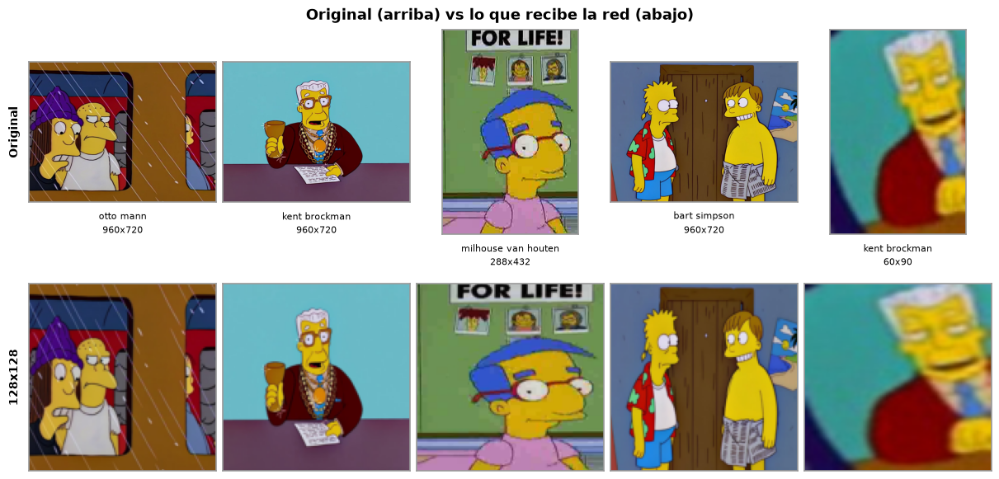

In [8]:
import matplotlib.pyplot as plt

# Comparación visual: la original y lo que recibe la red, para una muestra aleatoria
generador = np.random.default_rng(42)
muestra = generador.choice(len(datos), size=5, replace=False)

figura, ejes = plt.subplots(
    2,
    len(muestra),
    figsize=(2.4 * len(muestra), 5.8),
    layout="constrained",
)
for columna, indice in enumerate(muestra):
    fila = datos.iloc[indice]
    with Image.open(fila["ruta"]) as img:
        original = img.convert("RGB")

    personaje = fila["personaje"].replace("_", " ")
    ejes[0, columna].imshow(original)
    ejes[1, columna].imshow(imagenes[indice])

    # El texto va debajo de la imagen para que no invada la fila de arriba
    ejes[0, columna].set_xlabel(
        f"{personaje}\n{original.size[0]}x{original.size[1]}",
        fontsize=8,
        labelpad=6,
        linespacing=1.5,
    )

    for eje in (ejes[0, columna], ejes[1, columna]):
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in eje.spines.values():
            lado.set_edgecolor("#999999")
            lado.set_linewidth(1.2)

# Etiqueta de fila a la izquierda, en vez de repetir el mismo título en cada columna
ejes[0, 0].set_ylabel("Original", fontsize=10, fontweight="bold", labelpad=8)
ejes[1, 0].set_ylabel(
    f"{ANCHO_OBJETIVO}x{ALTO_OBJETIVO}", fontsize=10, fontweight="bold", labelpad=8
)

figura.suptitle("Original (arriba) vs lo que recibe la red (abajo)", fontsize=13, fontweight="bold")
plt.show()

### Normalización de los píxeles



**Por qué normalizar**
Al dividir por 255 todas las características de entrada quedan en la misma escala acotada
[0, 1]. Esto evita que unos píxeles pesen más que otros por su magnitud, mejora el
condicionamiento del descenso del gradiente y permite que la inicialización estándar de
los pesos funcione como se espera.

**Dónde se aplica**
El escalado **no se materializa aquí**, sino dentro del modelo, en la capa `Rescaling`
que es la primera capa de la CNN (sección del modelo base). El motivo es de memoria y de rendimiento: convertir todas las imágenes a
`float32` multiplica por cuatro el espacio ocupado —la celda siguiente imprime las cifras de
esta corrida— y obliga a alimentar el entrenamiento desde la RAM del equipo, copiando cada
lote por el bus en cada paso.

Manteniendo los píxeles en `uint8`, el conjunto **entero cabe en la VRAM de 8 GB de la
tarjeta** y el escalado lo hace la GPU sobre cada lote, a coste despreciable.

Esta celda comprueba sobre una muestra que el escalado de los píxeles es exactamente el esperado.

In [9]:
# Escalado de [0, 255] a [0, 1]: el rango con el que opera la red.
VALOR_MAXIMO_PIXEL = 255.0

# El escalado real lo aplica la capa Rescaling del modelo, ya sobre la GPU.
# Aqui solo se verifica sobre una muestra que la operacion es la esperada.
TAMANO_MUESTRA_NORMALIZACION = 512
tamano_muestra = min(TAMANO_MUESTRA_NORMALIZACION, len(imagenes))
imagenes_norm = imagenes[:tamano_muestra].astype(np.float32) / VALOR_MAXIMO_PIXEL

print(f"imagenes      : {imagenes.shape}  dtype={imagenes.dtype}"
      f"  ->  {imagenes.nbytes / 1024 ** 3:.2f} GB")
print(f"imagenes_norm : {imagenes_norm.shape}  dtype={imagenes_norm.dtype}"
      f"  (muestra de comprobacion)")
print(f"rango: [{imagenes_norm.min():.3f}, {imagenes_norm.max():.3f}]")
print(f"media: {imagenes_norm.mean():.4f}  desviacion: {imagenes_norm.std():.4f}")
print(
    f"\nEl conjunto completo en float32 ocuparia {imagenes.nbytes * 4 / 1024 ** 3:.2f} GB;"
    f" en uint8 ocupa {imagenes.nbytes / 1024 ** 3:.2f} GB y cabe entero en la VRAM."
)

imagenes      : (70855, 128, 128, 3)  dtype=uint8  ->  3.24 GB
imagenes_norm : (512, 128, 128, 3)  dtype=float32  (muestra de comprobacion)
rango: [0.000, 1.000]
media: 0.4389  desviacion: 0.2392

El conjunto completo en float32 ocuparia 12.97 GB; en uint8 ocupa 3.24 GB y cabe entero en la VRAM.


**Comprobación de la normalización**

In [10]:
indice_prueba = 0

comprobaciones_norm = pd.DataFrame(
    [
        (
            "Forma conservada (sobre la muestra)",
            str(imagenes_norm.shape),
            str(imagenes[:tamano_muestra].shape),
            imagenes_norm.shape == imagenes[:tamano_muestra].shape,
        ),
        (
            "Tipo de dato",
            str(imagenes_norm.dtype),
            "float32",
            imagenes_norm.dtype == np.float32,
        ),
        (
            "Valor mínimo",
            round(float(imagenes_norm.min()), 4),
            ">= 0.0",
            imagenes_norm.min() >= 0.0,
        ),
        (
            "Valor máximo",
            round(float(imagenes_norm.max()), 4),
            "<= 1.0",
            imagenes_norm.max() <= 1.0,
        ),
        (
            "Sin NaN ni infinitos",
            bool(np.isfinite(imagenes_norm).all()),
            True,
            bool(np.isfinite(imagenes_norm).all()),
        ),
        (
            "Escalado exacto (x255 == original)",
            "imagenes_norm * 255",
            "imagenes",
            np.allclose(
                imagenes_norm[indice_prueba] * VALOR_MAXIMO_PIXEL,
                imagenes[indice_prueba].astype(np.float32),
            ),
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_norm)

if not comprobaciones_norm["Correcto"].all():
    raise ValueError("La normalización no cumple alguna de las comprobaciones.")

print("Normalización verificada correctamente.")

,Comprobacion,Obtenido,Esperado,Correcto
0,Forma conservada (sobre la muestra),"(512, 128, 128, 3)","(512, 128, 128, 3)",True
1,Tipo de dato,float32,float32,True
2,Valor mínimo,0.0,>= 0.0,True
3,Valor máximo,1.0,<= 1.0,True
4,Sin NaN ni infinitos,True,True,True
5,Escalado exacto (x255 == original),imagenes_norm * 255,imagenes,True


Normalización verificada correctamente.


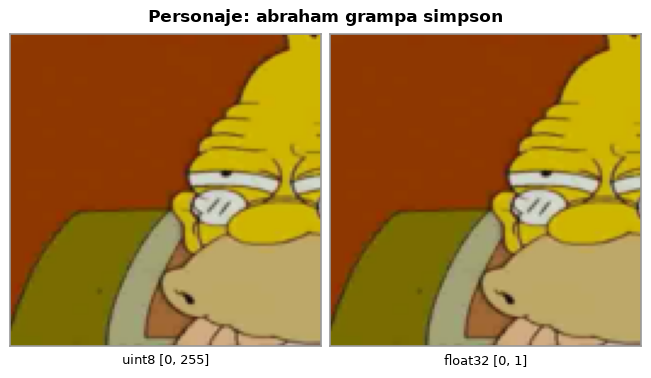

In [11]:
# La imagen normalizada debe verse idéntica a la original: solo cambia la escala numérica
figura, ejes = plt.subplots(1, 2, figsize=(6.4, 3.6), layout="constrained")

paneles = (
    (imagenes[indice_prueba], "uint8 [0, 255]"),
    (imagenes_norm[indice_prueba], "float32 [0, 1]"),
)
for eje, (imagen, etiqueta) in zip(ejes, paneles):
    eje.imshow(imagen)
    eje.set_xticks([])
    eje.set_yticks([])
    for lado in eje.spines.values():
        lado.set_edgecolor("#999999")
        lado.set_linewidth(1.2)
    eje.set_xlabel(etiqueta, fontsize=9, labelpad=6)

personaje = datos.iloc[indice_prueba]["personaje"].replace("_", " ")
figura.suptitle(f"Personaje: {personaje}", fontsize=12, fontweight="bold")
plt.show()


### La imagen como tensor: la CNN no aplana

**Por qué la CNN no aplana la imagen**

El MLP necesitaba un vector: cada neurona de una capa densa se conecta con todas las entradas, y para eso
la imagen de `alto x ancho x 3` se convertía en una lista de `alto * ancho * 3` números. Ese paso es el que
**pierde la estructura espacial**: después de aplanar, la red ya no sabe que el píxel `(0, 0)` y el `(0, 1)`
eran vecinos.

Una capa convolucional trabaja al revés: recibe la imagen con su forma y aplica cada filtro sobre una
vecindad de 3 x 3 píxeles, desplazándolo por toda la imagen. Por eso la entrada de la CNN conserva las tres
dimensiones de cada imagen y el conjunto completo es un **tensor de cuatro dimensiones**:

| Dimensión | Tamaño en esta corrida | Qué cuenta |
|---|---|---|
| 0 | N | Imágenes |
| 1 | 128 | Filas (alto) |
| 2 | 128 | Columnas (ancho) |
| 3 | 3 | Canales de color R, G y B |

Es el formato `channels_last` de Keras: los tres canales de cada píxel van juntos al final. `y` sigue siendo
un vector `(N,)` con el índice de la clase de cada imagen; en «Codificación de las etiquetas» pasa a ser la
matriz one-hot `(N, 64)` que exige `categorical_crossentropy`. Lo único imprescindible es que
`X.shape[0] == y.shape[0]` y que el orden coincida: la etiqueta `y[i]` corresponde a la imagen `X[i]`.

La celda siguiente no copia los datos: `X` es la misma matriz de imágenes redimensionadas, en `uint8`. El
escalado a [0, 1] lo hace la capa `Rescaling` del modelo sobre cada lote.

In [12]:
# La CNN recibe cada imagen con su forma (alto, ancho, 3): el conjunto es un tensor de 4 dimensiones
FORMA_ENTRADA = (ALTO_OBJETIVO, ANCHO_OBJETIVO, 3)
DIMENSION_PIXELES = ALTO_OBJETIVO * ANCHO_OBJETIVO * 3

# Sin copia ni conversion: X es la misma matriz de imagenes en uint8. El escalado a [0, 1]
# lo hace la capa Rescaling del modelo sobre cada lote.
X = imagenes
y = etiquetas

print(f"X: {X.shape}  dtype={X.dtype}  ({X.ndim} dimensiones: imagenes, alto, ancho, canales)")
print(f"y: {y.shape}")
print(f"Forma de cada imagen: {FORMA_ENTRADA}  ->  {DIMENSION_PIXELES} valores, sin aplanar")
print(f"rango de X: [{int(X.min())}, {int(X.max())}]  (uint8; se escala dentro del modelo)")

X: (70855, 128, 128, 3)  dtype=uint8  (4 dimensiones: imagenes, alto, ancho, canales)
y: (70855,)
Forma de cada imagen: (128, 128, 3)  ->  49152 valores, sin aplanar


rango de X: [0, 255]  (uint8; se escala dentro del modelo)


**Comprobación del tensor de entrada**

In [13]:
comprobaciones_tensor = pd.DataFrame(
    [
        ("Número de imágenes", X.shape[0], imagenes.shape[0], X.shape[0] == imagenes.shape[0]),
        ("Número de dimensiones", X.ndim, 4, X.ndim == 4),
        ("Forma de cada imagen", str(X.shape[1:]), str(FORMA_ENTRADA), X.shape[1:] == FORMA_ENTRADA),
        ("Tipo de dato", str(X.dtype), "uint8", X.dtype == np.uint8),
        (
            "Rango conservado [0, 255]",
            f"[{int(X.min())}, {int(X.max())}]",
            "[0, 255]",
            bool(X.min() >= 0 and X.max() <= 255),
        ),
        (
            "Sin copia de las imágenes",
            "np.shares_memory(X, imagenes)",
            True,
            bool(np.shares_memory(X, imagenes)),
        ),
        (
            "Misma imagen que la redimensionada",
            "X[i]",
            "imagenes[i]",
            np.array_equal(X[indice_prueba], imagenes[indice_prueba]),
        ),
        ("Etiquetas alineadas", len(y), X.shape[0], len(y) == X.shape[0]),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_tensor)

if not comprobaciones_tensor["Correcto"].all():
    raise ValueError("El tensor de entrada no cumple alguna de las comprobaciones.")

print("Tensor de entrada verificado correctamente.")

,Comprobacion,Obtenido,Esperado,Correcto
0,Número de imágenes,70855,70855,True
1,Número de dimensiones,4,4,True
2,Forma de cada imagen,"(128, 128, 3)","(128, 128, 3)",True
3,Tipo de dato,uint8,uint8,True
4,"Rango conservado [0, 255]","[0, 255]","[0, 255]",True
5,Sin copia de las imágenes,"np.shares_memory(X, imagenes)",True,True
6,Misma imagen que la redimensionada,X[i],imagenes[i],True
7,Etiquetas alineadas,70855,70855,True


Tensor de entrada verificado correctamente.


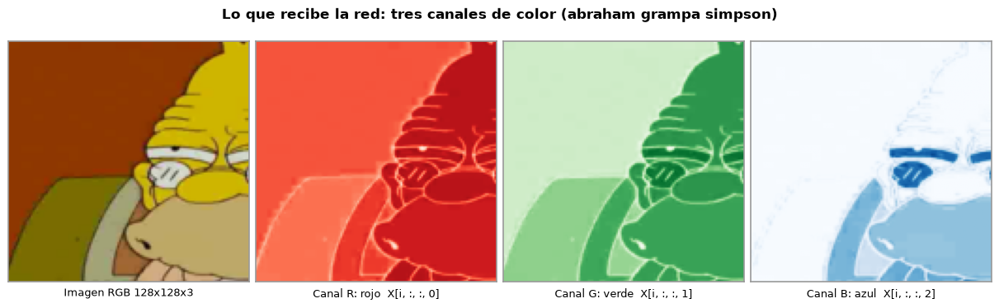

In [14]:
# La red no recibe un vector sino tres matrices de alto x ancho, una por canal de color
figura, ejes = plt.subplots(1, 4, figsize=(12, 3.6), layout="constrained")

ejes[0].imshow(imagenes[indice_prueba])
ejes[0].set_xlabel(f"Imagen RGB {ALTO_OBJETIVO}x{ANCHO_OBJETIVO}x3", fontsize=9, labelpad=6)
for eje, canal, nombre, mapa in zip(
    ejes[1:], range(3), ("R: rojo", "G: verde", "B: azul"), ("Reds", "Greens", "Blues")
):
    eje.imshow(X[indice_prueba, :, :, canal], cmap=mapa, vmin=0, vmax=255)
    eje.set_xlabel(f"Canal {nombre}  X[i, :, :, {canal}]", fontsize=9, labelpad=6)

for eje in ejes:
    eje.set_xticks([])
    eje.set_yticks([])
    for lado in eje.spines.values():
        lado.set_edgecolor("#999999")
        lado.set_linewidth(1.2)

personaje = datos.iloc[indice_prueba]["personaje"].replace("_", " ")
figura.suptitle(f"Lo que recibe la red: tres canales de color ({personaje})", fontsize=12, fontweight="bold")
plt.show()

**Imágenes alteradas por el script**

El script `scripts/newDataset/generar_imagenes_alteradas.py` aplica a cada imagen elegida un giro de 10 a
20 grados (recortando las esquinas que quedan vacías), un cambio de color (brillo, contraste, saturación
o tono) y un filtro de textura (desenfoque, nitidez, ruido o realce de bordes), con rangos moderados para
que el personaje siga siendo reconocible. La galería muestra
algunas parejas de entrenamiento, original arriba y alterada abajo, con la transformación que registró el
script en `_alteraciones.csv`.

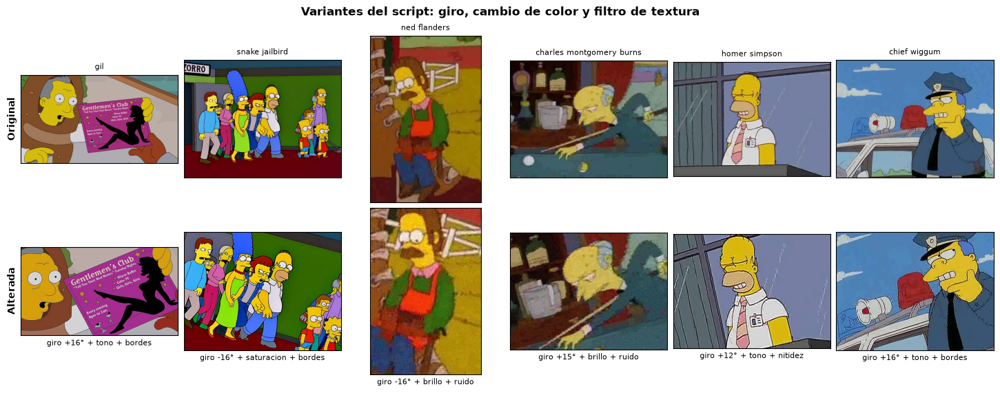

Imagenes alteradas en entrenamiento: 9952 (20.1% del conjunto)


In [15]:
# Parejas original / alterada del conjunto de entrenamiento, con la transformación aplicada
alteradas_train = datos[datos["alterada"] & (datos["conjunto"] == "train")]

if alteradas_train.empty:
    print("No hay imagenes alteradas en entrenamiento: ejecuta antes el script de alteraciones.")
else:
    transformaciones = {}
    registro_alteraciones = DATASET_BASE / "_alteraciones.csv"
    if registro_alteraciones.exists():
        registro_script = pd.read_csv(registro_alteraciones)
        con_giro = "rotacion" in registro_script.columns
        transformaciones = {
            (fila.personaje, fila.alterada): (f"giro {fila.rotacion:+.0f}° + " if con_giro else "")
            + f"{fila.color} + {fila.textura}"
            for fila in registro_script.itertuples()
        }

    muestra_alteradas = alteradas_train.sample(n=min(6, len(alteradas_train)), random_state=SEMILLA)
    figura, ejes = plt.subplots(
        2,
        len(muestra_alteradas),
        figsize=(2.4 * len(muestra_alteradas), 5.6),
        layout="constrained",
        squeeze=False,
    )
    for columna, fila in enumerate(muestra_alteradas.itertuples()):
        ruta_original = fila.ruta.with_name(fila.origen)
        for eje, ruta in ((ejes[0, columna], ruta_original), (ejes[1, columna], fila.ruta)):
            with Image.open(ruta) as img:
                eje.imshow(img.convert("RGB"))
            eje.set_xticks([])
            eje.set_yticks([])
        ejes[0, columna].set_title(fila.personaje.replace("_", " "), fontsize=8)
        ejes[1, columna].set_xlabel(
            transformaciones.get((fila.personaje, fila.ruta.name), "alterada"), fontsize=8
        )

    ejes[0, 0].set_ylabel("Original", fontsize=10, fontweight="bold")
    ejes[1, 0].set_ylabel("Alterada", fontsize=10, fontweight="bold")
    figura.suptitle(
        "Variantes del script: giro, cambio de color y filtro de textura", fontsize=12, fontweight="bold"
    )
    plt.show()

    proporcion = len(alteradas_train) / int((datos["conjunto"] == "train").sum())
    print(f"Imagenes alteradas en entrenamiento: {len(alteradas_train)} ({proporcion:.1%} del conjunto)")

**Imágenes parecidas**

Muchas imágenes del dataset son casi idénticas a otra del mismo personaje: fotogramas seguidos de una
misma escena o recortes repetidos. Si una cae en entrenamiento y su gemela en prueba, el modelo puede
acertar solo porque ya vio casi la misma imagen. El script compara las imágenes de cada personaje con
miniaturas a color de 16 x 16 (similitud coseno, umbral 0,90 por defecto) y agrupa las casi idénticas. En
cada grupo una queda intacta y cada una de las demás se reemplaza por una versión con giro, cambio de
color y filtro de textura (`<original>__parecida.<ext>`), que se vuelve a sortear hasta que deja de
parecerse a las del grupo. El notebook usa esa versión **en lugar** de la original, en cualquier
conjunto. La galería muestra algunos grupos: la imagen que quedó intacta, su casi idéntica y la versión
con la que esta entra al notebook.

Imagenes parecidas reemplazadas: 9042 en 6293 grupos   |   similitud mediana con su gemela: 0.98 antes y 0.55 despues del filtro


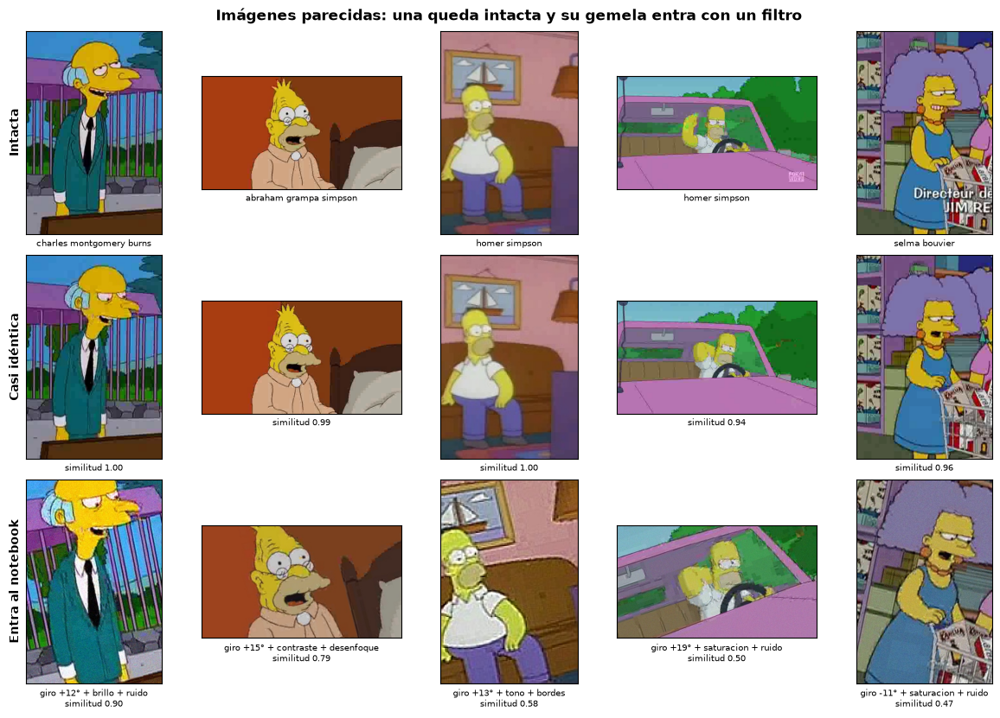

In [16]:
# Grupos de imágenes parecidas: la representante queda intacta y cada casi idéntica entra
# al notebook con su versión filtrada
registro_parecidas = DATASET_BASE / "_parecidas.csv"
if not registro_parecidas.exists():
    print("No hay registro de imagenes parecidas: ejecuta antes el script de alteraciones.")
else:
    parecidas_script = pd.read_csv(registro_parecidas)
    print(
        f"Imagenes parecidas reemplazadas: {len(parecidas_script)} en {parecidas_script['grupo'].nunique()} grupos"
        f"   |   similitud mediana con su gemela: {parecidas_script['similitud_original'].median():.2f} antes"
        f" y {parecidas_script['similitud_final'].median():.2f} despues del filtro"
    )
    muestra_parecidas = parecidas_script.sample(n=min(5, len(parecidas_script)), random_state=SEMILLA)
    figura, ejes = plt.subplots(
        3,
        len(muestra_parecidas),
        figsize=(2.4 * len(muestra_parecidas), 8.2),
        layout="constrained",
        squeeze=False,
    )
    for columna, fila in enumerate(muestra_parecidas.itertuples()):
        carpeta = DATASET_BASE / fila.personaje
        paneles = (
            (fila.representante, fila.personaje.replace("_", " ")),
            (fila.original, f"similitud {fila.similitud_original:.2f}"),
            (
                fila.parecida,
                f"giro {fila.rotacion:+.0f}° + {fila.color} + {fila.textura}\nsimilitud {fila.similitud_final:.2f}",
            ),
        )
        for numero_fila, (nombre_archivo, texto) in enumerate(paneles):
            eje = ejes[numero_fila, columna]
            with Image.open(carpeta / nombre_archivo) as img:
                eje.imshow(img.convert("RGB"))
            eje.set_xticks([])
            eje.set_yticks([])
            eje.set_xlabel(texto, fontsize=7)

    ejes[0, 0].set_ylabel("Intacta", fontsize=10, fontweight="bold")
    ejes[1, 0].set_ylabel("Casi idéntica", fontsize=10, fontweight="bold")
    ejes[2, 0].set_ylabel("Entra al notebook", fontsize=10, fontweight="bold")
    figura.suptitle(
        "Imágenes parecidas: una queda intacta y su gemela entra con un filtro", fontsize=12, fontweight="bold"
    )
    plt.show()

### Codificación de las etiquetas

**De nombre de carpeta a vector one-hot**

Las etiquetas nacen como texto (el nombre de la carpeta, por ejemplo `homer_simpson`) y una red no opera
con texto, así que hay que convertirlas a números. La conversión se hace en dos pasos:

1. **Índice entero.** Ya se construyó en "Carga de imágenes y etiquetas": `clases` es la lista de
   personajes ordenada alfabéticamente y `clase_a_indice` asigna a cada uno un entero de 0 a 63. Ese
   mapeo se reutiliza aquí en lugar de recalcularlo, porque debe ser **idéntico en train y en test**: si
   el índice 3 significara un personaje distinto en cada conjunto, la evaluación no tendría sentido.

2. **One-hot encoding.** El índice entero por sí solo es engañoso para el modelo: sugiere un **orden** y
   una **distancia** que no existen (que la clase 5 este "entre" la 4 y la 6, o que la 63 sea "mayor" que
   la 1). Los personajes son categorías nominales, sin orden. El one-hot elimina ese artefacto
   representando cada etiqueta como un vector de 64 posiciones con un 1 en la clase correcta y 0 en el
   resto, de modo que todas las clases quedan a la misma distancia entre sí.

Además, esta forma es la que corresponde a la salida de la red: la capa final tiene 64 neuronas con
`softmax`, que produce un vector de 64 probabilidades. La pérdida `categorical_crossentropy` compara ese
vector con el one-hot real, penalizando la probabilidad asignada a la clase verdadera.

> Existe la alternativa de dejar `y` como enteros y usar `sparse_categorical_crossentropy`, que es
> equivalente y ahorra memoria. Aquí se usa one-hot explícito porque hace visible la correspondencia con
> las 64 neuronas de salida, que es justamente lo que interesa mostrar en este trabajo.


In [17]:
NUMERO_CLASES = len(clases)

# One-hot: la fila i de la matriz identidad es el vector con un 1 en la posición i
# Equivale a keras.utils.to_categorical(y, NUMERO_CLASES), sin cargar TensorFlow todavía
y_onehot = np.eye(NUMERO_CLASES, dtype=np.float32)[y]

print(f"Numero de clases: {NUMERO_CLASES}")
print(f"y (indices):  {y.shape}  dtype={y.dtype}")
print(f"y_onehot:     {y_onehot.shape}  dtype={y_onehot.dtype}")

# Correspondencia para una imagen concreta
posicion_activa = int(y_onehot[indice_prueba].argmax())
print(
    f"\nEjemplo (imagen {indice_prueba}): '{datos.iloc[indice_prueba]['personaje']}'"
    f" -> indice {y[indice_prueba]} -> posicion activa {posicion_activa}"
)
print(f"vector one-hot: {y_onehot[indice_prueba].astype(int)}")


Numero de clases: 64
y (indices):  (70855,)  dtype=int64
y_onehot:     (70855, 64)  dtype=float32

Ejemplo (imagen 0): 'abraham_grampa_simpson' -> indice 0 -> posicion activa 0
vector one-hot: [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


**Comprobación de la codificación**

In [18]:
comprobaciones_etiquetas = pd.DataFrame(
    [
        (
            "Número de ejemplos",
            y_onehot.shape[0],
            X.shape[0],
            y_onehot.shape[0] == X.shape[0],
        ),
        (
            "Columnas = número de clases",
            y_onehot.shape[1],
            NUMERO_CLASES,
            y_onehot.shape[1] == NUMERO_CLASES,
        ),
        ("Tipo de dato", str(y_onehot.dtype), "float32", y_onehot.dtype == np.float32),
        (
            "Un único 1 por fila",
            float(y_onehot.sum(axis=1).min()),
            1.0,
            bool(np.all(y_onehot.sum(axis=1) == 1.0)),
        ),
        (
            "Solo valores 0 o 1",
            sorted(np.unique(y_onehot).tolist()),
            [0.0, 1.0],
            bool(np.isin(np.unique(y_onehot), [0.0, 1.0]).all()),
        ),
        (
            "Coincide con el índice entero",
            "y_onehot.argmax(axis=1)",
            "y",
            bool(np.array_equal(y_onehot.argmax(axis=1), y)),
        ),
        (
            "Todas las clases presentes",
            int((y_onehot.sum(axis=0) > 0).sum()),
            NUMERO_CLASES,
            int((y_onehot.sum(axis=0) > 0).sum()) == NUMERO_CLASES,
        ),
        (
            "Mapeo estable (índice -> nombre)",
            indice_a_clase[0],
            clases[0],
            indice_a_clase[0] == clases[0],
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_etiquetas)

if not comprobaciones_etiquetas["Correcto"].all():
    raise ValueError("La codificación de etiquetas no cumple alguna de las comprobaciones.")

print("Codificación verificada correctamente.")


,Comprobacion,Obtenido,Esperado,Correcto
0,Número de ejemplos,70855,70855,True
1,Columnas = número de clases,64,64,True
2,Tipo de dato,float32,float32,True
3,Un único 1 por fila,1.0,1.0,True
4,Solo valores 0 o 1,"[0.0, 1.0]","[0.0, 1.0]",True
5,Coincide con el índice entero,y_onehot.argmax(axis=1),y,True
6,Todas las clases presentes,64,64,True
7,Mapeo estable (índice -> nombre),abraham_grampa_simpson,abraham_grampa_simpson,True


Codificación verificada correctamente.


In [19]:
# Diccionario de clases: índice, nombre y ejemplos disponibles
tabla_clases = pd.DataFrame(
    {
        "indice": range(NUMERO_CLASES),
        "personaje": clases,
        "imagenes": [int((y == indice).sum()) for indice in range(NUMERO_CLASES)],
    }
)
tabla_clases["porcentaje"] = (tabla_clases["imagenes"] / len(y) * 100).round(2)

display(tabla_clases)


,indice,personaje,imagenes,porcentaje
0,0,abraham_grampa_simpson,1299,1.83
1,1,agnes_skinner,739,1.04
2,2,apu_nahasapeemapetilon,1001,1.41
3,3,barney_gumble,1196,1.69
4,4,bart_simpson,2425,3.42
...,...,...,...,...
59,59,sideshow_mel,784,1.11
60,60,snake_jailbird,834,1.18
61,61,todd_flanders,405,0.57
62,62,troy_mcclure,755,1.07


### Escenas con varios personajes

La etiqueta de cada imagen es su carpeta, pero un fotograma puede mostrar a más de un personaje: Lou junto
a Wiggum, Smithers junto a Burns, Barney en el bar de Moe. El modelo ve la imagen completa, así que puede
nombrar al otro personaje de la escena; con el criterio de acierto, nombrar a otro es un error.

Esta sección se conserva para una **métrica de referencia**, la accuracy por escena, que acepta como acierto
nombrar a un personaje presente. Es lo que medían como acierto las corridas anteriores, sin su verificación por
imagen, y permite compararlas. Los **fotogramas de episodio** del dataset traen en su nombre el episodio y el
instante (`personaje__S02E15__t0675633.jpg`, con `t` en milisegundos), y con eso se estima quién más aparece en
la escena sin anotar nada a mano:

- **Otro personaje en la misma escena.** Si la carpeta de otro personaje tiene un fotograma del mismo
  episodio a menos de `VENTANA_ESCENA_MS` (3 s), se asume que ese personaje también está en la escena. Es
  una heurística: tres segundos suelen ser el mismo plano, pero un corte de cámara puede caer en medio.
- **Nombre de archivo de otro personaje.** Los fotogramas que el equipo movió a la carpeta de su
  protagonista conservan el nombre del personaje con el que se extrajeron, que también está en el
  encuadre.
- **Gemela en la carpeta de otro personaje.** El script de alteraciones compara las imágenes de carpetas
  distintas y registra en `_gemelas.csv` las casi idénticas (similitud ≥ 0,90): es la misma escena
  guardada dos veces, así que los dos personajes están en ella. Esta fuente también alcanza a las
  imágenes de Kaggle.

Las imágenes que vienen del dataset de Kaggle (`homer_simpson_0001.jpg`) no traen episodio ni instante:
solo tienen acompañantes si tienen una gemela.

**Cómo se usa.** No se usa al entrenar: el objetivo de cada imagen es el one-hot de su carpeta, con el
suavizado de 0,1. Al evaluar, solo alimenta la accuracy por escena, que se informa como referencia. Por eso
la escena se calcula con todos los fotogramas y todas las gemelas: se lee después de predecir y no influye en
el modelo.

In [20]:
import re

# Fotogramas de episodio: <personaje>__<episodio>__t<milisegundos>
PATRON_FOTOGRAMA = re.compile(r"^(?P<nombre>.+?)__(?P<episodio>S\d+E\d+)__t(?P<ms>\d+)$", re.IGNORECASE)
VENTANA_ESCENA_MS = 3000


def leer_fotograma(nombre_archivo):
    """(personaje del nombre, episodio, ms) de un fotograma de episodio, o None si no lo es."""
    coincidencia = PATRON_FOTOGRAMA.match(Path(nombre_archivo).stem)
    if coincidencia is None:
        return None
    return coincidencia["nombre"], coincidencia["episodio"].upper(), int(coincidencia["ms"])


def construir_lineas_tiempo(tabla):
    """Fotogramas de cada episodio ordenados por instante: {episodio: (instantes, personajes)}."""
    por_episodio = {}
    for personaje, origen in zip(tabla["personaje"], tabla["origen"]):
        fotograma = leer_fotograma(origen)
        if fotograma is not None:
            por_episodio.setdefault(fotograma[1], []).append((fotograma[2], personaje))
    lineas = {}
    for episodio, fotogramas in por_episodio.items():
        fotogramas.sort()
        lineas[episodio] = (np.array([ms for ms, _ in fotogramas]), [p for _, p in fotogramas])
    return lineas


def personajes_en_escena(personaje, origen, lineas_tiempo):
    """Personajes que probablemente acompañan al de la carpeta en esa imagen (sin incluirlo)."""
    fotograma = leer_fotograma(origen)
    if fotograma is None:
        return frozenset()
    nombre, episodio, ms = fotograma
    acompanantes = {nombre} if nombre != personaje and nombre in clase_a_indice else set()
    if episodio in lineas_tiempo:
        instantes, personajes = lineas_tiempo[episodio]
        desde = np.searchsorted(instantes, ms - VENTANA_ESCENA_MS, side="left")
        hasta = np.searchsorted(instantes, ms + VENTANA_ESCENA_MS, side="right")
        acompanantes.update(otro for otro in personajes[desde:hasta] if otro != personaje)
    return frozenset(acompanantes)


# Gemelas entre personajes: la misma escena guardada en la carpeta de otro personaje. Las detecta el
# script de alteraciones comparando las originales de carpetas distintas
registro_gemelas = DATASET_BASE / "_gemelas.csv"
GEMELAS = {}
n_pares_gemelas = 0
if registro_gemelas.exists():
    pares_gemelas = pd.read_csv(registro_gemelas)
    pares_gemelas = pares_gemelas[
        pares_gemelas["personaje"].isin(clase_a_indice) & pares_gemelas["otro_personaje"].isin(clase_a_indice)
    ]
    n_pares_gemelas = len(pares_gemelas)
    for fila in pares_gemelas.itertuples():
        GEMELAS.setdefault((fila.personaje, fila.original), set()).add((fila.otro_personaje, fila.otro_original))
        GEMELAS.setdefault((fila.otro_personaje, fila.otro_original), set()).add((fila.personaje, fila.original))
else:
    print("No hay registro de gemelas entre personajes: ejecuta antes el script de alteraciones.")


def personajes_gemelos(personaje, origen):
    """Personajes en cuya carpeta hay una imagen casi idéntica a esta."""
    return frozenset(otro for otro, _ in GEMELAS.get((personaje, origen), ()))


# Línea de tiempo con todos los fotogramas originales del dataset: la escena solo se lee después de predecir,
# para la métrica de referencia, y no influye en el modelo
originales_indexados = indice_completo[
    ~indice_completo["alterada"] & indice_completo["personaje"].isin(clase_a_indice)
]
LINEAS_TIEMPO_COMPLETAS = construir_lineas_tiempo(originales_indexados)
escena_evaluacion = [
    personajes_en_escena(p, o, LINEAS_TIEMPO_COMPLETAS) | personajes_gemelos(p, o)
    for p, o in zip(datos["personaje"], datos["origen"])
]
datos["escena"] = [", ".join(sorted(acompanantes)) for acompanantes in escena_evaluacion]

es_fotograma = np.array([leer_fotograma(origen) is not None for origen in datos["origen"]])
con_gemela = np.array([bool(personajes_gemelos(p, o)) for p, o in zip(datos["personaje"], datos["origen"])])
con_escena_evaluacion = np.array([bool(acompanantes) for acompanantes in escena_evaluacion])

resumen_escena = pd.DataFrame(
    [
        (
            nombre,
            int(mascara.sum()),
            int(es_fotograma[mascara].sum()),
            int(con_gemela[mascara].sum()),
            int(con_escena_evaluacion[mascara].sum()),
        )
        for nombre in CONJUNTOS
        for mascara in [(datos["conjunto"] == nombre).to_numpy()]
    ],
    columns=["conjunto", "imagenes", "fotogramas", "con_gemela", "escena_compartida"],
)
display(resumen_escena)

# Parejas de personajes que más comparten escena (solo originales)
pares_escena = (
    pd.DataFrame(
        [
            (personaje, otro)
            for personaje, acompanantes, alterada in zip(datos["personaje"], escena_evaluacion, datos["alterada"])
            if not alterada
            for otro in acompanantes
        ],
        columns=["personaje", "acompanante"],
    )
    .value_counts()
    .head(10)
    .reset_index(name="imagenes")
)
display(pares_escena)

if not all(p not in a for p, a in zip(datos["personaje"], escena_evaluacion)):
    raise ValueError("Alguna imagen aparece acompañada por el personaje de su propia carpeta.")

print(
    f"Fotogramas de episodio: {int(es_fotograma.sum())} de {len(datos)} imagenes"
    f"   |   con gemela en otra carpeta: {int(con_gemela.sum())} ({n_pares_gemelas} pares)"
    f"   |   con escena compartida: {int(con_escena_evaluacion.sum())}"
)

,conjunto,imagenes,fotogramas,con_gemela,escena_compartida
0,train,49625,30252,6145,12003
1,val,14172,8607,1727,3345
2,test,7058,4279,860,1674


,personaje,acompanante,imagenes
0,lou,chief_wiggum,354
1,chief_wiggum,lou,313
2,patty_bouvier,selma_bouvier,307
3,selma_bouvier,patty_bouvier,299
4,gary_chalmers,principal_skinner,276
5,fat_tony,louie,234
6,louie,fat_tony,220
7,rod_flanders,todd_flanders,212
8,jimbo_jones,kearney_zzyzwicz,201
9,carl_carlson,lenny_leonard,194


Fotogramas de episodio: 43138 de 70855 imagenes   |   con gemela en otra carpeta: 8732 (6222 pares)   |   con escena compartida: 17022


### Partición train / validación / test

**Por qué hacen falta tres conjuntos y no dos**

Entrenar mirando el conjunto de prueba es hacer trampa: en cuanto se usa para decidir cuántas capas
poner, cuándo detener el entrenamiento o qué representación elegir, deja de ser una estimación honesta
del desempeño con datos nuevos, porque esas decisiones ya lo incorporaron. Ese fenómeno se conoce como
fuga de información.

Por eso cada personaje se repartió, en «Partición y selección por personaje», en tres conjuntos:

- **Entrenamiento (70 % de las originales):** las imágenes con las que se ajustan los pesos.
- **Validación (20 % de las originales):** imágenes que nunca actualizan pesos, pero que se miden en
  cada época. Sirven para trazar las curvas de aprendizaje, detectar sobreajuste, activar la parada
  temprana y comparar las configuraciones de la experimentación.
- **Test (10 % de las originales):** se reserva intacto y se abre **una sola vez**, en la evaluación
  final del modelo elegido.

Cada conjunto lleva además las variantes alteradas de sus propias originales y la versión filtrada de las
casi idénticas, así que los tres tienen las mismas condiciones.

**Partición estratificada.** Validación y test conservan, para cada personaje, la misma proporción que
tiene en el dataset completo. Con 64 clases muy desbalanceadas, un reparto aleatorio simple podría dejar
a un personaje minoritario con muy pocos ejemplos de validación —o con ninguno—, y entonces su métrica
sería pura casualidad.

**Semilla fija.** `random_state=SEMILLA` garantiza que la partición sea siempre la misma. Es un
requisito de la metodología de experimentación: al cambiar un solo factor por vez, la diferencia
observada debe deberse a ese factor y no a que le tocó un reparto de datos distinto.

La celda siguiente solo materializa esa partición: separa las filas de cada matriz según el conjunto
que se asignó a cada imagen.

In [21]:
# La partición ya está decidida en la columna "conjunto" de datos: aquí solo se
# separan las imágenes de cada conjunto
MASCARAS = {nombre: (datos["conjunto"] == nombre).to_numpy() for nombre in CONJUNTOS}
PARTICION = {nombre: X[mascara] for nombre, mascara in MASCARAS.items()}

# Etiquetas e imágenes de cada conjunto (las de test se usan en el análisis de errores).
# Los tres conjuntos usan el one-hot de la carpeta: cada imagen es la de su personaje.
y_train, y_val, y_test = (y_onehot[MASCARAS[nombre]] for nombre in CONJUNTOS)
y_train_idx, y_val_idx, y_test_idx = (y[MASCARAS[nombre]] for nombre in CONJUNTOS)
imagenes_test = PARTICION["test"]
datos_test = datos[MASCARAS["test"]].reset_index(drop=True)

# Tensores de imagen de cada conjunto
X_train, X_val, X_test = (PARTICION[nombre] for nombre in CONJUNTOS)

print(f"X_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}   y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}   y_test:  {y_test.shape}")
# Las proporciones se miden sobre las originales: las alteradas son variantes extra que van
# al mismo conjunto que su original
es_alterada = datos["alterada"].to_numpy()
n_originales = {nombre: int((MASCARAS[nombre] & ~es_alterada).sum()) for nombre in CONJUNTOS}
n_alteradas = {nombre: int((MASCARAS[nombre] & es_alterada).sum()) for nombre in CONJUNTOS}
total = sum(n_originales.values())
print(
    "\nReparto de las originales: "
    + " / ".join(f"{n_originales[nombre]} {nombre} ({n_originales[nombre] / total * 100:.1f} %)" for nombre in CONJUNTOS)
)
for nombre in CONJUNTOS:
    print(
        f"{nombre:<5}: {n_originales[nombre]} originales + {n_alteradas[nombre]} alteradas"
        f" = {n_originales[nombre] + n_alteradas[nombre]} imagenes"
    )
print(f"Forma de cada imagen: {X_train.shape[1:]} ({DIMENSION_PIXELES} valores, sin aplanar)")

X_train: (49625, 128, 128, 3)   y_train: (49625, 64)
X_val:   (14172, 128, 128, 3)   y_val:   (14172, 64)
X_test:  (7058, 128, 128, 3)   y_test:  (7058, 64)

Reparto de las originales: 39673 train (70.0 %) / 11335 val (20.0 %) / 5668 test (10.0 %)
train: 39673 originales + 9952 alteradas = 49625 imagenes
val  : 11335 originales + 2837 alteradas = 14172 imagenes
test : 5668 originales + 1390 alteradas = 7058 imagenes
Forma de cada imagen: (128, 128, 3) (49152 valores, sin aplanar)


**Comprobación de la partición**

In [22]:
# Proporción de cada personaje en el dataset completo frente a validación y test
proporcion_dataset = originales["personaje"].value_counts(normalize=True)
proporciones = pd.DataFrame(
    {
        "personaje": clases,
        "dataset_%": [round(float(proporcion_dataset[clase]) * 100, 2) for clase in clases],
        "val_%": [round((y_val_idx == i).mean() * 100, 2) for i in range(NUMERO_CLASES)],
        "test_%": [round((y_test_idx == i).mean() * 100, 2) for i in range(NUMERO_CLASES)],
        "n_train": [int((y_train_idx == i).sum()) for i in range(NUMERO_CLASES)],
        "n_val": [int((y_val_idx == i).sum()) for i in range(NUMERO_CLASES)],
        "n_test": [int((y_test_idx == i).sum()) for i in range(NUMERO_CLASES)],
    }
)
proporciones["desviacion_%"] = (
    proporciones[["val_%", "test_%"]].sub(proporciones["dataset_%"], axis=0).abs().max(axis=1).round(2)
)

display(proporciones)

# Una imagen y sus variantes se identifican por (personaje, original de la que salen)
origenes = {
    nombre: set(zip(datos.loc[MASCARAS[nombre], "personaje"], datos.loc[MASCARAS[nombre], "origen"]))
    for nombre in CONJUNTOS
}
compartidas = (
    len(origenes["train"] & origenes["val"])
    + len(origenes["train"] & origenes["test"])
    + len(origenes["val"] & origenes["test"])
)
# Mismas condiciones en los tres conjuntos: cuántas alteradas y parecidas hay por cada original
TOLERANCIA_CONDICIONES = 0.03


def por_original(columna):
    """Imágenes marcadas en `columna` (alteradas o parecidas) por cada original, en cada conjunto."""
    return {
        nombre: float(datos.loc[MASCARAS[nombre], columna].sum())
        / max(int((MASCARAS[nombre] & ~datos["alterada"].to_numpy()).sum()), 1)
        for nombre in CONJUNTOS
    }


alteradas_por_original = por_original("alterada")
parecidas_por_original = por_original("parecida")
proporciones_obtenidas = {
    nombre: (MASCARAS[nombre] & ~datos["alterada"].to_numpy()).sum() / (~datos["alterada"]).sum()
    for nombre in CONJUNTOS
}
clases_por_conjunto = [len(np.unique(indices)) for indices in (y_train_idx, y_val_idx, y_test_idx)]

comprobaciones_particion = pd.DataFrame(
    [
        (
            "Cada imagen en un solo conjunto",
            int(sum(mascara.sum() for mascara in MASCARAS.values())),
            len(datos),
            int(sum(mascara.sum() for mascara in MASCARAS.values())) == len(datos),
        ),
        ("Sin imágenes compartidas entre conjuntos", compartidas, 0, compartidas == 0),
        *[
            (
                f"{nombre} por original en train / val / test",
                " / ".join(f"{proporciones_tipo[conjunto]:.1%}" for conjunto in CONJUNTOS),
                f"iguales (± {TOLERANCIA_CONDICIONES:.0%})",
                all(
                    abs(proporciones_tipo[conjunto] - proporciones_tipo["train"]) <= TOLERANCIA_CONDICIONES
                    for conjunto in CONJUNTOS
                ),
            )
            for nombre, proporciones_tipo in (
                ("Alteradas", alteradas_por_original),
                ("Parecidas", parecidas_por_original),
            )
        ],
        (
            "Todas las originales repartidas (sin tope)",
            int((~datos["alterada"]).sum()),
            len(originales),
            int((~datos["alterada"]).sum()) == len(originales),
        ),
        (
            "Proporciones train / val / test de las originales",
            " / ".join(f"{proporciones_obtenidas[nombre]:.1%}" for nombre in CONJUNTOS),
            " / ".join(f"{PROPORCIONES[nombre]:.0%}" for nombre in CONJUNTOS),
            all(abs(proporciones_obtenidas[nombre] - PROPORCIONES[nombre]) < 0.005 for nombre in CONJUNTOS),
        ),
        (
            "Forma de las imágenes intacta",
            str(X_train.shape[1:]),
            str(FORMA_ENTRADA),
            X_train.shape[1:] == FORMA_ENTRADA,
        ),
        ("X e y alineados en train", len(y_train), len(X_train), len(y_train) == len(X_train)),
        ("X e y alineados en validación", len(y_val), len(X_val), len(y_val) == len(X_val)),
        ("X e y alineados en test", len(y_test), len(X_test), len(y_test) == len(X_test)),
        (
            "One-hot coherente con índices",
            "y_val.argmax(axis=1)",
            "y_val_idx",
            bool(np.array_equal(np.argmax(y_val, axis=1), y_val_idx)),
        ),
        (
            "Todas las clases en train / val / test",
            " / ".join(str(n) for n in clases_por_conjunto),
            NUMERO_CLASES,
            all(n == NUMERO_CLASES for n in clases_por_conjunto),
        ),
        (
            "Estratificación de val y test (desviación máxima)",
            f"{proporciones['desviacion_%'].max():.2f} %",
            "< 1 %",
            bool(proporciones["desviacion_%"].max() < 1.0),
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_particion)

if not comprobaciones_particion["Correcto"].all():
    raise ValueError("La partición no cumple alguna de las comprobaciones.")

print("Partición verificada correctamente.")

,personaje,dataset_%,val_%,test_%,n_train,n_val,n_test,desviacion_%
0,abraham_grampa_simpson,1.83,1.83,1.88,906,260,133,0.05
1,agnes_skinner,1.04,1.09,1.05,511,154,74,0.05
2,apu_nahasapeemapetilon,1.41,1.45,1.33,702,205,94,0.08
3,barney_gumble,1.69,1.69,1.70,836,240,120,0.01
4,bart_simpson,3.42,3.46,3.39,1696,490,239,0.04
...,...,...,...,...,...,...,...,...
59,sideshow_mel,1.11,1.08,1.05,557,153,74,0.06
60,snake_jailbird,1.18,1.22,1.12,582,173,79,0.06
61,todd_flanders,0.57,0.57,0.54,286,81,38,0.03
62,troy_mcclure,1.07,1.07,1.05,530,151,74,0.02


,Comprobacion,Obtenido,Esperado,Correcto
0,Cada imagen en un solo conjunto,70855,70855,True
1,Sin imágenes compartidas entre conjuntos,0,0,True
2,Alteradas por original en train / val / test,25.1% / 25.0% / 24.5%,iguales (± 3%),True
3,Parecidas por original en train / val / test,16.1% / 15.9% / 15.3%,iguales (± 3%),True
4,Todas las originales repartidas (sin tope),56676,56676,True
5,Proporciones train / val / test de las originales,70.0% / 20.0% / 10.0%,70% / 20% / 10%,True
6,Forma de las imágenes intacta,"(128, 128, 3)","(128, 128, 3)",True
7,X e y alineados en train,49625,49625,True
8,X e y alineados en validación,14172,14172,True
9,X e y alineados en test,7058,7058,True


Partición verificada correctamente.


### Tratamiento del desbalance de clases

**El problema**

Como se describió en "Definición del problema de clasificación", el dataset está muy desbalanceado
(razón aproximada 21:1 entre `homer_simpson` y `maggie_simpson`). Esto sesga el entrenamiento: la pérdida es un
promedio sobre los ejemplos del batch, así que los personajes abundantes dominan el gradiente y el
modelo aprende que, ante la duda, conviene predecir una clase mayoritaria. El resultado típico es un
accuracy global aceptable acompañado de un recall muy bajo en las clases pequeñas, que es precisamente
lo que el **F1 macro** —promedio no ponderado entre clases— deja al descubierto.

**Opciones consideradas**

| Estrategia | Qué hace | Por qué se descarta o se elige |
|---|---|---|
| Submuestreo de mayoritarias | Limita cada personaje a un tope de originales en entrenamiento | Se descarta: una corrida anterior con un tope de 300 dejaba sin usar unas 12.700 imágenes, y los personajes frecuentes, recortados en entrenamiento pero completos en validación y test, caían por debajo de un 20 % de recall (Homero 0,16, Bart 0,15) |
| Sobremuestreo por duplicado | Repite imágenes de las clases pequeñas | Se descarta: los duplicados exactos favorecen el sobreajuste a esas imágenes |
| **Aumento de datos** | Añade variantes alteradas con un giro de 10 a 20°, un cambio de color y un filtro de textura | **Se elige:** las genera una sola vez el script `generar_imagenes_alteradas.py` para un cuarto de las imágenes de cada personaje. Cada una va al mismo conjunto que su original: en entrenamiento aumenta los datos, y en validación y prueba hace que el modelo se mida en las mismas condiciones |
| **Pesos por clase suavizados** | Pondera la pérdida según la frecuencia de cada clase | **Se elige:** compensa el desbalance sin descartar datos. Se usa la raíz cuadrada del peso balanceado: con 21:1 en entrenamiento, el balanceado completo daría a `maggie_simpson` unas 21 veces el peso de Homero y empujaría al modelo a no predecir a los frecuentes. Los experimentos P1 y P2 comparan sin pesos y con los balanceados completos |

**Cómo funciona `class_weight`.** Keras multiplica la pérdida de cada ejemplo por el peso de su clase, de
modo que equivocarse en un personaje raro cuesta más que equivocarse en uno frecuente. Se usa la fórmula
`n_muestras / (n_clases * n_ejemplos_de_la_clase)`, que da peso 1 a una clase de tamaño medio, mayor que 1
a las minoritarias y menor que 1 a las mayoritarias. El modelo base usa su **raíz cuadrada**, reescalada
para que el peso medio por imagen siga siendo 1: la pérdida conserva su escala y la razón entre el peso
mayor y el menor baja de unas 21 a unas 4,6 veces.

**Advertencia importante.** Los pesos se calculan **solo con `y_train`**, nunca con el conjunto completo
ni con validación: usar información de validación para ajustar el entrenamiento sería otra forma de fuga.
Y se aplican **solo durante el entrenamiento**: las métricas de validación y test se miden sin pesos,
porque deben reflejar el desempeño sobre la distribución real de los datos.

El efecto conjunto de estas tres decisiones se lee en la evaluación, comparando la accuracy con el F1
macro en test.

In [23]:
from sklearn.utils.class_weight import compute_class_weight

# Los pesos se calculan SOLO con las etiquetas de entrenamiento
pesos_balanceados = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUMERO_CLASES),
    y=y_train_idx,
)
conteos_train = np.bincount(y_train_idx, minlength=NUMERO_CLASES)

# Pesos suavizados: raíz cuadrada del balanceado, reescalada para que el peso medio por
# imagen de entrenamiento sea 1 y la pérdida conserve su escala
pesos_raiz = np.sqrt(pesos_balanceados)
pesos_raiz = pesos_raiz * len(y_train_idx) / (pesos_raiz * conteos_train).sum()

# Esquemas que compara la experimentación (P1 y P2); el modelo base usa ESQUEMA_PESOS.
# Keras espera un diccionario {indice_de_clase: peso}
ESQUEMA_PESOS = "raiz"
PESOS_POR_ESQUEMA = {
    "ninguno": None,
    "raiz": {indice: float(peso) for indice, peso in enumerate(pesos_raiz)},
    "balanceado": {indice: float(peso) for indice, peso in enumerate(pesos_balanceados)},
}
pesos = pesos_raiz
pesos_por_clase = PESOS_POR_ESQUEMA[ESQUEMA_PESOS]

tabla_pesos = pd.DataFrame(
    {
        "indice": range(NUMERO_CLASES),
        "personaje": clases,
        "n_train": conteos_train,
        "porcentaje": (conteos_train / conteos_train.sum() * 100).round(2),
        "peso_balanceado": np.round(pesos_balanceados, 3),
        "peso": np.round(pesos, 3),
    }
).sort_values("n_train", ascending=False, ignore_index=True)

display(tabla_pesos)

razon_desbalance = conteos_train.max() / conteos_train.min()
print(f"Clase mayoritaria: {clases[int(conteos_train.argmax())]} ({conteos_train.max()} imagenes)")
print(f"Clase minoritaria: {clases[int(conteos_train.argmin())]} ({conteos_train.min()} imagenes)")
print(f"Razon de desbalance: {razon_desbalance:.1f}:1")
print(f"Rango de pesos (raiz, los del modelo base): [{pesos.min():.3f}, {pesos.max():.3f}]")
print(f"Rango de pesos balanceados completos      : [{pesos_balanceados.min():.3f}, {pesos_balanceados.max():.3f}]")


,indice,personaje,n_train,porcentaje,peso_balanceado,peso
0,22,homer_simpson,2725,5.49,0.285,0.554
1,4,bart_simpson,1696,3.42,0.457,0.702
2,33,lisa_simpson,1557,3.14,0.498,0.733
3,46,ned_flanders,1550,3.12,0.500,0.735
4,38,marge_simpson,1536,3.10,0.505,0.738
...,...,...,...,...,...,...
59,14,dr_nick_riviera,275,0.55,2.820,1.744
60,23,jasper_beardly,222,0.45,3.493,1.941
61,25,judge_snyder,179,0.36,4.332,2.162
62,11,disco_stu,159,0.32,4.877,2.294


Clase mayoritaria: homer_simpson (2725 imagenes)
Clase minoritaria: maggie_simpson (130 imagenes)
Razon de desbalance: 21.0:1
Rango de pesos (raiz, los del modelo base): [0.554, 2.537]
Rango de pesos balanceados completos      : [0.285, 5.965]


**Comprobación de los pesos y baselines de referencia**

In [24]:
comprobaciones_pesos = pd.DataFrame(
    [
        (
            "Un peso por clase",
            len(pesos_por_clase),
            NUMERO_CLASES,
            len(pesos_por_clase) == NUMERO_CLASES,
        ),
        (
            "Todos los pesos positivos",
            round(float(pesos.min()), 3),
            "> 0",
            bool((pesos > 0).all()),
        ),
        (
            "Mayor peso a la clase minoritaria",
            clases[int(pesos.argmax())],
            clases[int(conteos_train.argmin())],
            int(pesos.argmax()) == int(conteos_train.argmin()),
        ),
        (
            "Menor peso a la clase mayoritaria",
            clases[int(pesos.argmin())],
            clases[int(conteos_train.argmax())],
            int(pesos.argmin()) == int(conteos_train.argmax()),
        ),
        (
            "Peso inverso a la frecuencia",
            "corr(peso, n_train)",
            "negativa",
            bool(float(np.corrcoef(pesos, conteos_train)[0, 1]) < 0),
        ),
        (
            "Calculados solo con train",
            len(y_train_idx),
            len(X_train),
            len(y_train_idx) == len(X_train),
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_pesos)

if not comprobaciones_pesos["Correcto"].all():
    raise ValueError("Los pesos por clase no cumplen alguna de las comprobaciones.")

# Baselines contra los que se comparará el modelo final. La clase mayoritaria se mide
# sobre validación, que conserva la distribución real del dataset (sus alteradas son un
# cuarto de las originales de cada personaje, igual que en train).
conteos_val = np.bincount(y_val_idx, minlength=NUMERO_CLASES)
baseline_azar = 100 / NUMERO_CLASES
baseline_mayoritaria = conteos_val.max() / conteos_val.sum() * 100

print(f"\nBaseline por azar (1/{NUMERO_CLASES}): {baseline_azar:.1f} % de accuracy")
print(f"Baseline de clase mayoritaria:  {baseline_mayoritaria:.1f} % de accuracy")
print("El modelo solo aporta valor si supera claramente ambos.")


,Comprobacion,Obtenido,Esperado,Correcto
0,Un peso por clase,64,64,True
1,Todos los pesos positivos,0.554,> 0,True
2,Mayor peso a la clase minoritaria,maggie_simpson,maggie_simpson,True
3,Menor peso a la clase mayoritaria,homer_simpson,homer_simpson,True
4,Peso inverso a la frecuencia,"corr(peso, n_train)",negativa,True
5,Calculados solo con train,49625,49625,True



Baseline por azar (1/64): 1.6 % de accuracy
Baseline de clase mayoritaria:  5.5 % de accuracy
El modelo solo aporta valor si supera claramente ambos.


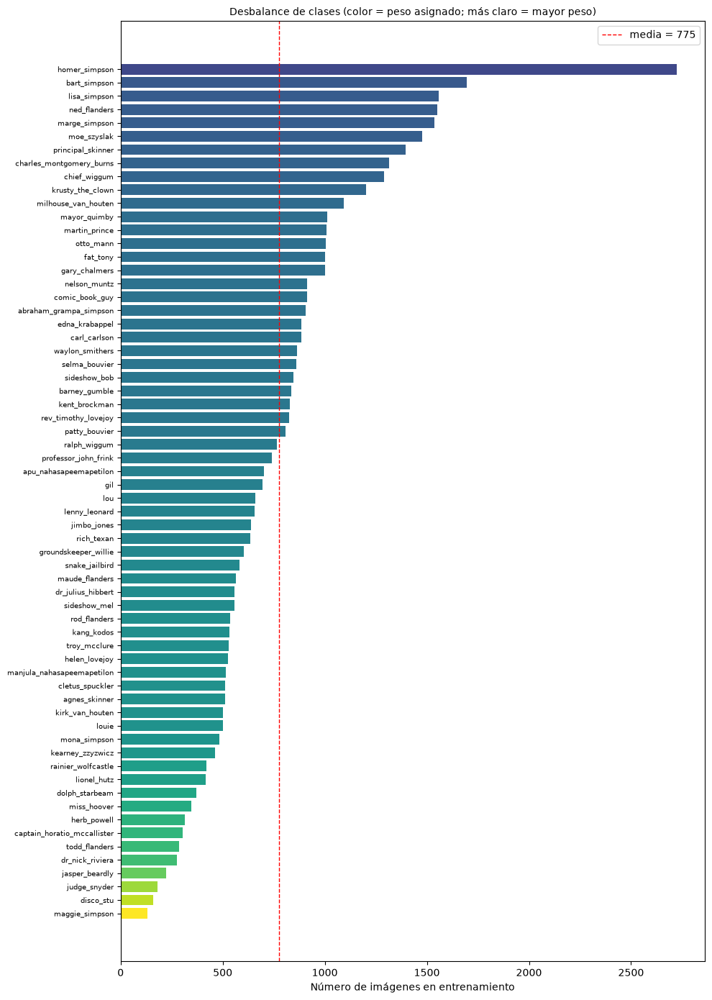

In [25]:
import matplotlib

# Distribución de imágenes por personaje en el conjunto de entrenamiento
figura, eje = plt.subplots(figsize=(10, 14))

orden = np.argsort(conteos_train)
eje.barh(
    [clases[i] for i in orden],
    conteos_train[orden],
    color=matplotlib.colormaps["viridis"](pesos[orden] / pesos.max()),
)
eje.set_xlabel("Número de imágenes en entrenamiento")
eje.set_title("Desbalance de clases (color = peso asignado; más claro = mayor peso)", fontsize=10)
eje.tick_params(axis="y", labelsize=7)
eje.axvline(
    conteos_train.mean(),
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"media = {conteos_train.mean():.0f}",
)
eje.legend()

plt.tight_layout()
plt.show()


### Síntesis del análisis exploratorio

El análisis exploratorio recorre el dataset antes de entrenar, y cada hallazgo se traduce en una decisión del
pipeline:

| Hallazgo | Evidencia | Decisión que motiva |
|---|---|---|
| Desbalance entre personajes | De 3.118 imágenes originales (`homer_simpson`) a 151 (`maggie_simpson`): 20,6:1 en el dataset y 21,0:1 en entrenamiento | Pesos por clase, partición estratificada y selección por F1 macro |
| Tamaños muy distintos | De 28 a 2.700 píxeles de ancho y de 42 a 3.600 de alto, con una mediana de 960 × 720 | Redimensionado de la imagen completa a 128 × 128 |
| Imágenes casi idénticas | 9.042 originales eran casi idénticas a otra del mismo personaje (6.293 grupos, similitud mediana de 0,98) | Se usan con una versión filtrada (similitud mediana de 0,55), para que el test no premie memorizar una toma |
| Variantes alteradas | 14.179 alteradas, una por cada cuarto de las originales | Cada alterada va al mismo conjunto que su original |
| Fotogramas de episodio | 43.138 de las 70.855 imágenes de trabajo (60,9 %) traen el episodio y el instante | Estimación de los personajes presentes en cada escena |
| Escenas con varios personajes | 17.022 imágenes (24,0 %) tienen a otro personaje presente; 8.732 tienen una gemela en otra carpeta (6.222 pares) | Accuracy por escena como referencia y análisis de los errores que nombran a otro personaje |
| Parejas que comparten escena | Lou y Wiggum (354 imágenes), Patty y Selma (307), Chalmers y Skinner (276) | Se anticipan como las confusiones más probables |
| Píxeles | Rango [0, 255]; en una muestra, media de 0,439 y desviación de 0,239 tras escalar | Escalado a [0, 1] dentro del modelo |


## Fundamentos: estructura de una red convolucional

### Capas convolucionales: filtros que recorren la imagen

**Qué hace una capa convolucional**

Una neurona de una capa densa mira **todas** las entradas a la vez, cada una con su propio peso. Una neurona
convolucional mira solo una ventana pequeña —en esta CNN, de 3 × 3 píxeles con sus tres canales— y calcula
lo mismo que cualquier neurona: una combinación lineal de esos valores más un sesgo, seguida de una
activación. Lo que la distingue es que **la misma ventana de pesos, el filtro, se desplaza por toda la
imagen**:

$$z_{f,c} = \sum_{i=-1}^{1}\sum_{j=-1}^{1}\sum_{k=1}^{3} w_{i,j,k}\, x_{f+i,\,c+j,\,k} + b$$

El resultado de aplicar un filtro en todas las posiciones es un **mapa de activación**: una imagen nueva
que vale mucho donde la ventana se parece al patrón del filtro y poco donde no. Una capa con 32 filtros
produce 32 mapas, uno por patrón, y la capa siguiente combina esos mapas en patrones más complejos.

**Tres consecuencias de compartir los pesos**

| Propiedad | Qué significa | Qué limitación del MLP resuelve |
|---|---|---|
| **Conectividad local** | Cada neurona mira una vecindad, no la imagen entera | La red sabe qué píxel está junto a cuál: la estructura espacial no se pierde |
| **Pesos compartidos** | El mismo filtro se usa en todas las posiciones | Un patrón aprendido en una zona se reconoce en cualquier otra: el peinado de Marge es el mismo arriba o al centro del encuadre |
| **Pocos parámetros** | Un filtro de 3 × 3 × 3 tiene 27 pesos, a cualquier resolución | La primera capa del MLP sobre píxeles tiene 25,2 millones de pesos a 128 × 128; la de la CNN tiene 864 a cualquier resolución |

En el MLP los filtros los elegíamos nosotros: los histogramas de color, LBP, Gabor y HOG eran, en el fondo,
filtros fijos. En la CNN **los filtros son pesos** y se aprenden con el mismo descenso del gradiente que el
resto de la red. La celda siguiente aplica a mano tres filtros clásicos sobre una imagen real para ver qué
produce una convolución.

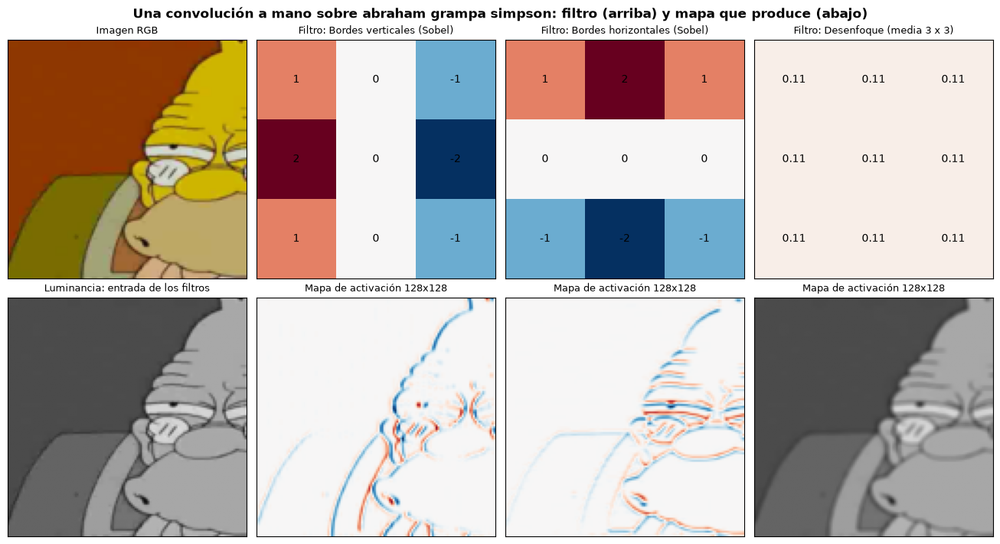

,Paso,Forma,Número de valores
0,Entrada (luminancia),"(128, 128)",16384
1,Filtro,"(3, 3)",9
2,Mapa de activación (padding same),"(128, 128)",16384


Con los mismos 9 pesos el filtro recorre las 16,384 posiciones de la imagen: el mapa vale mucho (rojo o azul) donde la vecindad se
parece al patrón del filtro. En la CNN esos 9 pesos (27 con los tres canales) no se eligen: se aprenden.


In [26]:
# Una convolución hecha a mano: tres filtros clásicos de 3 x 3 sobre una imagen de entrenamiento
from scipy.signal import correlate2d

indice_demo = int(np.flatnonzero(MASCARAS["train"])[0])
imagen_demo = imagenes[indice_demo].astype(np.float32) / VALOR_MAXIMO_PIXEL
# Los filtros de esta demostración trabajan sobre un solo canal: la luminancia de la imagen
gris_demo = imagen_demo @ np.array([0.299, 0.587, 0.114], dtype=np.float32)

FILTROS_DEMO = {
    "Bordes verticales (Sobel)": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], dtype=np.float32),
    "Bordes horizontales (Sobel)": np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], dtype=np.float32),
    "Desenfoque (media 3 x 3)": np.full((3, 3), 1 / 9, dtype=np.float32),
}
# Las capas Conv2D calculan una correlación cruzada (el filtro no se invierte), que es lo que hace
# correlate2d. Con mode="same" el mapa conserva el tamaño de la imagen, como padding="same" en Keras.
mapas_demo = {
    nombre: correlate2d(gris_demo, filtro, mode="same", boundary="symm")
    for nombre, filtro in FILTROS_DEMO.items()
}

figura, ejes = plt.subplots(2, 4, figsize=(13, 7.0), layout="constrained")
ejes[0, 0].imshow(imagenes[indice_demo])
ejes[0, 0].set_title("Imagen RGB", fontsize=9)
ejes[1, 0].imshow(gris_demo, cmap="gray", vmin=0, vmax=1)
ejes[1, 0].set_title("Luminancia: entrada de los filtros", fontsize=9)

for columna, (nombre, filtro) in enumerate(FILTROS_DEMO.items(), start=1):
    eje_filtro, eje_mapa = ejes[0, columna], ejes[1, columna]
    eje_filtro.imshow(filtro, cmap="RdBu_r", vmin=-2, vmax=2)
    for fila_filtro in range(3):
        for columna_filtro in range(3):
            eje_filtro.text(
                columna_filtro, fila_filtro, f"{filtro[fila_filtro, columna_filtro]:.2g}",
                ha="center", va="center", fontsize=10,
            )
    eje_filtro.set_title(f"Filtro: {nombre}", fontsize=9)
    mapa = mapas_demo[nombre]
    limite = float(np.abs(mapa).max()) or 1.0
    if nombre.startswith("Desenfoque"):
        eje_mapa.imshow(mapa, cmap="gray", vmin=0, vmax=1)
    else:
        eje_mapa.imshow(mapa, cmap="RdBu_r", vmin=-limite, vmax=limite)
    eje_mapa.set_title(f"Mapa de activación {mapa.shape[0]}x{mapa.shape[1]}", fontsize=9)

for eje in np.ravel(ejes):
    eje.set_xticks([])
    eje.set_yticks([])

personaje = datos.iloc[indice_demo]["personaje"].replace("_", " ")
figura.suptitle(f"Una convolución a mano sobre {personaje}: filtro (arriba) y mapa que produce (abajo)",
                fontsize=12, fontweight="bold")
plt.show()

recorrido_convolucion = pd.DataFrame(
    [
        ("Entrada (luminancia)", str(gris_demo.shape), gris_demo.size),
        ("Filtro", "(3, 3)", 9),
        ("Mapa de activación (padding same)", str(mapas_demo["Bordes verticales (Sobel)"].shape),
         mapas_demo["Bordes verticales (Sobel)"].size),
    ],
    columns=["Paso", "Forma", "Número de valores"],
)
display(recorrido_convolucion)
print(
    "Con los mismos 9 pesos el filtro recorre las "
    f"{gris_demo.size:,} posiciones de la imagen: el mapa vale mucho (rojo o azul) donde la vecindad se"
    "\nparece al patrón del filtro. En la CNN esos 9 pesos (27 con los tres canales) no se eligen: se aprenden."
)

### Pooling, profundidad y campo receptivo

**Max pooling.** Después de cada bloque convolucional, una capa `MaxPooling2D` de 2 × 2 se queda con el valor
máximo de cada ventana de 2 × 2 del mapa de activación. El mapa queda con la mitad de filas y de columnas
—un cuarto de los valores— y conserva lo importante: si el patrón del filtro apareció en esa zona, aunque no
exactamente en qué píxel. Eso le da a la red una **invarianza aproximada a desplazamientos pequeños** y
abarata las capas siguientes.

**Campo receptivo.** Una neurona de la primera capa ve 3 × 3 píxeles. Una de la segunda ve 3 × 3 valores de
un mapa que ya resume ventanas de la imagen, así que en la imagen original abarca una zona mayor. Cada
bloque convolución + pooling amplía esa zona: las primeras capas detectan bordes y manchas de color, y las
últimas, partes completas —un ojo, el pelo, una camisa— porque ven una porción grande del encuadre. La
celda siguiente calcula el campo receptivo de cada bloque de la CNN base.

**Pooling global.** Al final de los bloques, `GlobalAveragePooling2D` promedia cada mapa de activación en
toda su extensión: de cada filtro queda un número, cuánto se activó en la imagen, sin importar dónde. Es la
entrada de la cabeza clasificadora, una pequeña red densa como el MLP.

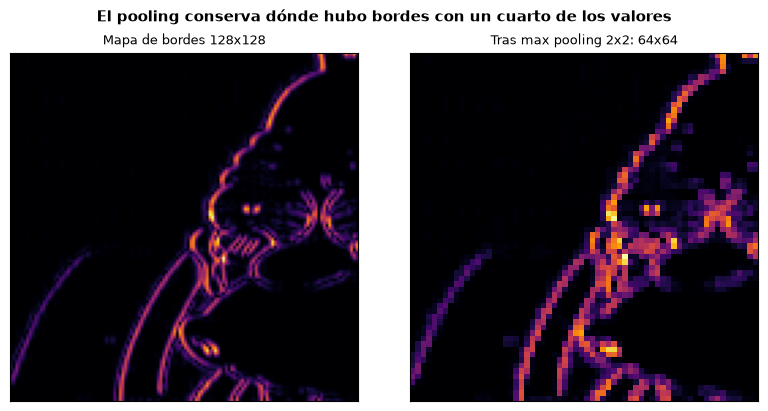

,bloque,filtros,mapa_entrada,mapa_salida,campo_receptivo_px,% del lado de la imagen
0,1,32,128x128,64x64,3x3,2
1,2,64,64x64,32x32,8x8,6
2,3,128,32x32,16x16,18x18,14
3,4,256,16x16,8x8,38x38,30


El ultimo bloque ve zonas de 38x38 pixeles de una imagen de 128x128: sus filtros responden a partes grandes del personaje, no a bordes sueltos.


In [27]:
# Max pooling de 2 x 2 sobre el mapa de bordes verticales: la mitad de filas y de columnas
mapa_bordes = np.abs(mapas_demo["Bordes verticales (Sobel)"])
alto_par, ancho_par = mapa_bordes.shape[0] // 2 * 2, mapa_bordes.shape[1] // 2 * 2
mapa_pooling = (
    mapa_bordes[:alto_par, :ancho_par]
    .reshape(alto_par // 2, 2, ancho_par // 2, 2)
    .max(axis=(1, 3))
)

figura, ejes = plt.subplots(1, 2, figsize=(8, 4.0), layout="constrained")
for eje, mapa, titulo in (
    (ejes[0], mapa_bordes, f"Mapa de bordes {mapa_bordes.shape[0]}x{mapa_bordes.shape[1]}"),
    (ejes[1], mapa_pooling, f"Tras max pooling 2x2: {mapa_pooling.shape[0]}x{mapa_pooling.shape[1]}"),
):
    eje.imshow(mapa, cmap="inferno")
    eje.set_title(titulo, fontsize=9)
    eje.set_xticks([])
    eje.set_yticks([])
figura.suptitle("El pooling conserva dónde hubo bordes con un cuarto de los valores", fontsize=11, fontweight="bold")
plt.show()

# Campo receptivo de la CNN base (sección «Definición de la arquitectura»): cuatro bloques de una
# convolución de 3 x 3 seguida de un max pooling de 2 x 2. Cada capa amplía la zona de la imagen
# original que ve una neurona en (lado del núcleo - 1) x (distancia en píxeles entre dos neuronas vecinas).
filtros_demo = (32, 64, 128, 256)
campo, salto, lado = 1, 1, ALTO_OBJETIVO
filas_campo = []
for bloque, filtros in enumerate(filtros_demo, start=1):
    campo += (3 - 1) * salto           # convolución 3 x 3, paso 1
    campo_convolucion = campo
    campo += (2 - 1) * salto           # max pooling 2 x 2, paso 2
    salto *= 2
    filas_campo.append(
        {
            "bloque": bloque,
            "filtros": filtros,
            "mapa_entrada": f"{lado}x{lado}",
            "mapa_salida": f"{lado // 2}x{lado // 2}",
            "campo_receptivo_px": f"{min(campo_convolucion, ALTO_OBJETIVO)}x{min(campo_convolucion, ALTO_OBJETIVO)}",
            "% del lado de la imagen": round(min(campo_convolucion / ALTO_OBJETIVO, 1) * 100),
        }
    )
    lado //= 2

display(pd.DataFrame(filas_campo))
print(
    f"El ultimo bloque ve zonas de {filas_campo[-1]['campo_receptivo_px']} pixeles de una imagen de "
    f"{ALTO_OBJETIVO}x{ANCHO_OBJETIVO}: sus filtros responden a partes grandes del personaje, no a bordes sueltos."
)

### Por qué una CNN y no un MLP: el costo en parámetros

El MLP sobre píxeles conectaba cada uno de los `alto x ancho x 3` valores con cada neurona de su primera
capa, así que sus pesos crecían con la resolución. Una capa convolucional tiene un número de pesos fijo
—filtros × 3 × 3 × canales de entrada— y lo que crece con la resolución es el número de posiciones en que
se aplica, es decir, el cómputo. La celda siguiente lo cuantifica para la primera capa de cada red.

In [28]:
# Primera capa de cada red: una densa de 512 neuronas sobre los píxeles aplanados (el MLP del
# experimento R1 del PMC) frente a una convolución de 32 filtros de 3 x 3 (la primera de la CNN base)
resoluciones_demo = (32, 64, 128)
tabla_costo = pd.DataFrame(
    {
        "resolucion": [f"{lado}x{lado}" for lado in resoluciones_demo],
        "valores_por_imagen": [lado * lado * 3 for lado in resoluciones_demo],
        "pesos_densa_512 (MLP)": [lado * lado * 3 * 512 for lado in resoluciones_demo],
        "pesos_conv_32 (CNN)": [3 * 3 * 3 * 32 for _ in resoluciones_demo],
        "multiplicaciones_conv_por_imagen": [lado * lado * 3 * 3 * 3 * 32 for lado in resoluciones_demo],
    }
)
tabla_costo["razon_pesos_MLP_CNN"] = (
    tabla_costo["pesos_densa_512 (MLP)"] / tabla_costo["pesos_conv_32 (CNN)"]
).round(0).astype(int)

display(tabla_costo)

fila_trabajo = tabla_costo[tabla_costo["resolucion"] == f"{ALTO_OBJETIVO}x{ANCHO_OBJETIVO}"]
if not fila_trabajo.empty:
    fila_trabajo = fila_trabajo.iloc[0]
    print(
        f"A {fila_trabajo['resolucion']}, la primera capa del MLP sobre pixeles tiene "
        f"{fila_trabajo['pesos_densa_512 (MLP)']:,} pesos y la de la CNN {fila_trabajo['pesos_conv_32 (CNN)']:,}:"
        f" {fila_trabajo['razon_pesos_MLP_CNN']:,} veces menos."
    )
print(
    "Los pesos de la convolucion no cambian con la resolucion; las multiplicaciones, en cambio,"
    "\nse multiplican por 4 cada vez que se dobla el lado. Por eso la CNN cuesta mas tiempo, no mas memoria."
)

,resolucion,valores_por_imagen,pesos_densa_512 (MLP),pesos_conv_32 (CNN),multiplicaciones_conv_por_imagen,razon_pesos_MLP_CNN
0,32x32,3072,1572864,864,884736,1820
1,64x64,12288,6291456,864,3538944,7282
2,128x128,49152,25165824,864,14155776,29127


A 128x128, la primera capa del MLP sobre pixeles tiene 25,165,824 pesos y la de la CNN 864: 29,127 veces menos.
Los pesos de la convolucion no cambian con la resolucion; las multiplicaciones, en cambio,
se multiplican por 4 cada vez que se dobla el lado. Por eso la CNN cuesta mas tiempo, no mas memoria.


### Funciones de activación

**Por qué hace falta la no linealidad**

Si se quitaran las funciones de activación, cada capa sería solo una multiplicación de matrices y la red
entera colapsaría en una sola: la composición de funciones lineales es otra función lineal. Una red de
diez capas sin activaciones tendría exactamente el mismo poder expresivo que una regresión lineal, y sería
incapaz de separar clases que no se puedan dividir con un hiperplano. La activación no lineal es lo que
permite que apilar capas sirva de algo.

**Comparación de las activaciones para las capas ocultas**

| Función | Fórmula | Rango | Ventaja | Problema |
|---|---|---|---|---|
| **Sigmoide** | $1/(1+e^{-z})$ | (0, 1) | Interpretable como probabilidad | Se satura: para $\|z\|$ grande el gradiente tiende a 0 y el aprendizaje se detiene |
| **Tanh** | $(e^z-e^{-z})/(e^z+e^{-z})$ | (-1, 1) | Centrada en cero, converge mejor que la sigmoide | También se satura en los extremos |
| **ReLU** | $\max(0, z)$ | [0, inf) | Gradiente constante 1 para $z>0$: no se satura; muy barata de calcular; produce activaciones dispersas | "Neuronas muertas": si una unidad queda siempre en $z<0$, su gradiente es 0 y no vuelve a aprender |

**Elección: ReLU en las capas ocultas.** El problema de la saturación es decisivo. En una red profunda,
los gradientes se multiplican capa a capa al retropropagarse; si cada factor es menor que 1 -- como pasa
con sigmoide, cuya derivada máxima es 0,25 -- el gradiente se desvanece antes de llegar a las primeras
capas, que son justamente las que deben aprender de los píxeles. ReLU mantiene el gradiente en 1 en toda
su zona activa, y además su cálculo es una simple comparación, lo que acelera el entrenamiento. Es el
valor por defecto razonable para capas ocultas, y de ahí partimos.

**Elección: softmax en la salida.** La capa final no busca una no linealidad cualquiera, sino convertir 64
números sin escala definida en una distribución de probabilidad:

$$\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{64} e^{z_j}}$$

Sus dos propiedades son las que necesita un problema multiclase de etiqueta única: todas las salidas son
positivas y **suman exactamente 1**. Eso introduce competencia entre clases -- si sube la probabilidad de
un personaje, baja la de los demas -- que es correcto aquí, porque cada imagen tiene un único personaje.
Si el problema fuera multietiqueta habría que usar sigmoides independientes en la salida.


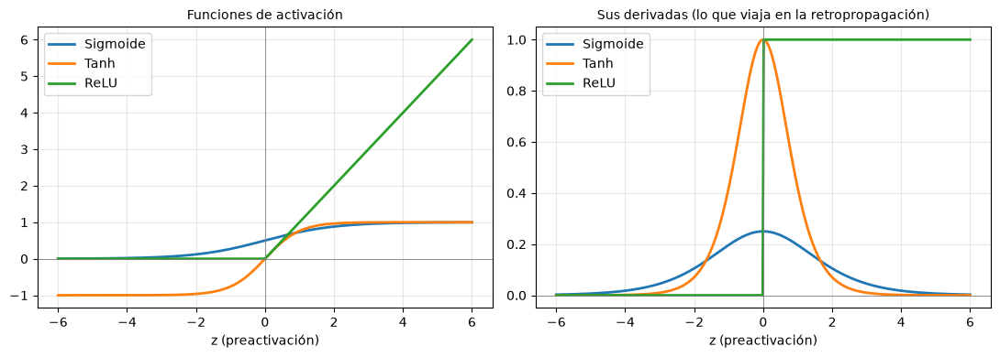

En el gráfico de la derecha se ve el problema de la saturación: las derivadas de sigmoide y tanh
caen a cero en los extremos (el gradiente se desvanece), mientras que la de ReLU vale 1 para
todo z > 0. Nótese además que la derivada de la sigmoide no supera 0.25.


In [29]:
z = np.linspace(-6, 6, 400)

activaciones = {
    "Sigmoide": (1 / (1 + np.exp(-z)), lambda s: s * (1 - s)),
    "Tanh": (np.tanh(z), lambda s: 1 - s ** 2),
    "ReLU": (np.maximum(0, z), lambda s: (z > 0).astype(float)),
}

figura, ejes = plt.subplots(1, 2, figsize=(11, 4))

for nombre, (valores, derivada) in activaciones.items():
    ejes[0].plot(z, valores, label=nombre, linewidth=2)
    ejes[1].plot(z, derivada(valores), label=nombre, linewidth=2)

ejes[0].set_title("Funciones de activación", fontsize=10)
ejes[1].set_title("Sus derivadas (lo que viaja en la retropropagación)", fontsize=10)

for eje in ejes:
    eje.axhline(0, color="gray", linewidth=0.6)
    eje.axvline(0, color="gray", linewidth=0.6)
    eje.set_xlabel("z (preactivación)")
    eje.grid(alpha=0.3)
    eje.legend()

plt.tight_layout()
plt.show()

print(
    "En el gráfico de la derecha se ve el problema de la saturación: las derivadas de sigmoide y tanh"
    "\ncaen a cero en los extremos (el gradiente se desvanece), mientras que la de ReLU vale 1 para"
    "\ntodo z > 0. Nótese además que la derivada de la sigmoide no supera 0.25."
)


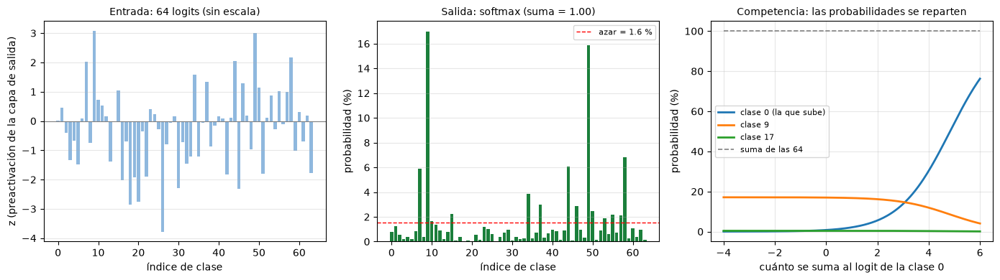

Softmax no se puede dibujar junto a ReLU o tanh porque no transforma un número en otro:
toma el vector completo de logits y devuelve una distribución. El denominador -- la suma
de todas las exponenciales -- es lo que acopla las salidas entre si.

Clase predicha: 9 con 17.0 % de probabilidad   |   suma de las 64 salidas = 1.000000
En el gráfico de la derecha se ve la propiedad clave para etiqueta única: al crecer el logit
de una clase, su probabilidad sube y la de las demas baja, mientras la suma se mantiene en 100 %.


In [30]:
# Softmax se gráfica aparte: no es una activación elemento a elemento como las anteriores,
# sino una función vectorial que mira todas las salidas a la vez y las convierte en una distribución.
generador = np.random.default_rng(7)
logits_demo = generador.normal(0, 1.5, NUMERO_CLASES)
logits_demo[min(9, NUMERO_CLASES - 1)] += 4.0  # una clase claramente favorecida por la red


def softmax(z, temperatura=1.0):
    """Softmax numéricamente estable: se resta el máximo antes de exponenciar."""
    escalado = np.asarray(z, dtype=float) / temperatura
    exponenciales = np.exp(escalado - escalado.max())
    return exponenciales / exponenciales.sum()


probabilidades_demo = softmax(logits_demo)

figura, ejes = plt.subplots(1, 3, figsize=(14, 4))

# 1. Los logits: números sin escala definida, positivos y negativos
ejes[0].bar(range(NUMERO_CLASES), logits_demo, color="#8fb8de")
ejes[0].axhline(0, color="gray", linewidth=0.8)
ejes[0].set_title(f"Entrada: {NUMERO_CLASES} logits (sin escala)", fontsize=10)
ejes[0].set_ylabel("z (preactivación de la capa de salida)")

# 2. La misma información después de softmax: probabilidades que suman 1
ejes[1].bar(range(NUMERO_CLASES), probabilidades_demo * 100, color="#1b7f3b")
ejes[1].axhline(
    100 / NUMERO_CLASES,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"azar = {100 / NUMERO_CLASES:.1f} %",
)
ejes[1].set_title(
    f"Salida: softmax (suma = {probabilidades_demo.sum():.2f})", fontsize=10
)
ejes[1].set_ylabel("probabilidad (%)")
ejes[1].legend(fontsize=8)

for eje in ejes[:2]:
    eje.set_xlabel("índice de clase")
    eje.grid(alpha=0.3, axis="y")

# 3. La competencia entre clases: subir el logit de una hunde a todas las demas
desplazamientos = np.linspace(-4, 6, 200)
seguidas = sorted({0, min(9, NUMERO_CLASES - 1), min(17, NUMERO_CLASES - 1)})  # clases a seguir
curvas = np.array(
    [softmax(np.concatenate(([logits_demo[0] + d], logits_demo[1:]))) for d in desplazamientos]
)

for indice in seguidas:
    ejes[2].plot(
        desplazamientos,
        curvas[:, indice] * 100,
        linewidth=2,
        label=f"clase {indice}" + (" (la que sube)" if indice == 0 else ""),
    )

ejes[2].plot(
    desplazamientos,
    curvas.sum(axis=1) * 100,
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label=f"suma de las {NUMERO_CLASES}",
)
ejes[2].set_title("Competencia: las probabilidades se reparten", fontsize=10)
ejes[2].set_xlabel("cuánto se suma al logit de la clase 0")
ejes[2].set_ylabel("probabilidad (%)")
ejes[2].grid(alpha=0.3)
ejes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(
    "Softmax no se puede dibujar junto a ReLU o tanh porque no transforma un número en otro:"
    "\ntoma el vector completo de logits y devuelve una distribución. El denominador -- la suma"
    "\nde todas las exponenciales -- es lo que acopla las salidas entre si."
)
print(
    f"\nClase predicha: {int(probabilidades_demo.argmax())} con {probabilidades_demo.max() * 100:.1f} %"
    f" de probabilidad   |   suma de las {NUMERO_CLASES} salidas = {probabilidades_demo.sum():.6f}"
)
print(
    "En el gráfico de la derecha se ve la propiedad clave para etiqueta única: al crecer el logit"
    "\nde una clase, su probabilidad sube y la de las demas baja, mientras la suma se mantiene en 100 %."
)


### Función de pérdida, backpropagation y optimizador

El forward pass produce una predicción, pero por sí solo no enseña nada. El aprendizaje necesita tres
piezas más: una forma de **medir** el error, una forma de **repartir la culpa** de ese error entre los
parámetros, y una **regla** para corregirlos.

**1. Función de pérdida: entropía cruzada categórica**

Mide la distancia entre la distribución predicha por softmax y el vector one-hot real. Como el one-hot
tiene un 1 en la clase correcta y 0 en el resto, la suma se reduce a un único término:

$$L = -\sum_{i=1}^{64} y_i \log(\hat{y}_i) = -\log(\hat{y}_{\text{clase correcta}})$$

Es decir: la pérdida de un ejemplo depende **solo de la probabilidad que la red asignó a la clase
verdadera**. Si le dio 0,99, la pérdida es casi 0; si le dio 0,01, la pérdida se dispara. Ese crecimiento
logarítmico penaliza con dureza los errores cometidos con mucha confianza, que es el comportamiento
deseable. La pérdida del batch es el promedio de las pérdidas individuales -- y es ahí donde `class_weight`
interviene, ponderando cada término según la frecuencia de su clase.

Por qué no usar accuracy como función a minimizar: el accuracy es escalonado, su gradiente es cero en casi
todas partes y no distingue entre acertar con 0,51 o con 0,99. Sirve para interpretar resultados, no para
optimizar. Por eso se monitorean ambos: se **optimiza** la pérdida y se **lee** el accuracy.

**2. Backpropagation: de dónde viene el error**

Conocida la pérdida, hace falta saber cuánto contribuyó cada uno de los parámetros. Eso es la derivada
parcial $\partial L / \partial w$, y calcularla directamente para cientos de miles de pesos sería
inviable. La retropropagación lo resuelve aplicando la **regla de la cadena** en sentido inverso: parte
del error en la salida y lo propaga hacia atras capa por capa, reutilizando en cada paso lo ya calculado
en la capa posterior. Esto es lo que hace posible entrenar redes grandes, y también la razón de que la
derivada de la activación importe tanto: aparece como factor multiplicativo en cada capa que se atraviesa
(de ahí el desvanecimiento del gradiente con sigmoide y la ventaja de ReLU).

El resultado es el **gradiente**: un vector que indica, para cada parámetro, en qué dirección habría que
moverlo para que la pérdida aumente. Se avanza en la dirección contraria.

**3. Optimizador: cómo se corrigen los pesos**

La regla básica es el **descenso del gradiente**:

$$w \leftarrow w - \eta \frac{\partial L}{\partial w}$$

donde $\eta$ es la **tasa de aprendizaje** (learning rate), el tamaño del paso. Demasiado grande y el
entrenamiento oscila o diverge; demasiado pequeño y avanza con una lentitud inútil. En la práctica no se
calcula el gradiente sobre todo el dataset (caro) ni sobre un solo ejemplo (ruidoso), sino sobre **batches**
de unas decenas o centenas de imágenes: es el descenso del gradiente por mini-lotes. Una **época** es una
pasada completa por el conjunto de entrenamiento, es decir, muchas actualizaciones de pesos.

**Elección: Adam.** Mejora el descenso del gradiente clásico en dos aspectos: acumula un **momento** de los
gradientes anteriores, lo que suaviza las oscilaciones, y adapta el tamaño del paso **para cada parámetro**
según la magnitud típica de su gradiente. En la práctica converge más rápido y es mucho menos sensible a
la elección inicial del learning rate, razón por la que se usa como punto de partida en la mayoría de los
trabajos. Se parte de su valor por defecto, 0,001, y su efecto se contrasta en la experimentación.

**El ciclo completo de entrenamiento**

Para cada batch, y repitiendolo época tras época:

`forward pass` -> `calcular la perdida` -> `backpropagation` -> `el optimizador actualiza los pesos`


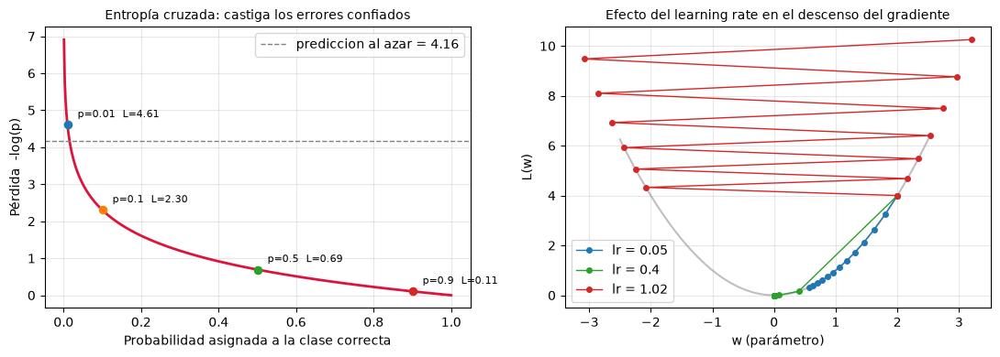

Perdida esperada de un modelo sin entrenar (1/64 a cada clase): 4.159
Es el valor de referencia con el que debería arrancar el entrenamiento en la primera época.

En el gráfico de la derecha: un lr pequeño (azul) converge pero lento, uno adecuado (verde)
llega rápido al mínimo, y uno demasiado grande (rojo) se aleja y diverge.


In [31]:
# Pérdida de un ejemplo según la probabilidad asignada a la clase correcta
probabilidades = np.linspace(0.001, 1.0, 500)
perdidas = -np.log(probabilidades)

figura, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].plot(probabilidades, perdidas, color="crimson", linewidth=2)
ejes[0].set_xlabel("Probabilidad asignada a la clase correcta")
ejes[0].set_ylabel("Pérdida  -log(p)")
ejes[0].set_title("Entropía cruzada: castiga los errores confiados", fontsize=10)
ejes[0].grid(alpha=0.3)

for probabilidad in (0.01, 0.1, 0.5, 0.9):
    ejes[0].scatter([probabilidad], [-np.log(probabilidad)], zorder=3, s=35)
    ejes[0].annotate(
        f"p={probabilidad}  L={-np.log(probabilidad):.2f}",
        (probabilidad, -np.log(probabilidad)),
        textcoords="offset points",
        xytext=(8, 6),
        fontsize=8,
    )

# Referencias del problema: pérdida esperada al predecir al azar entre todas las clases
perdida_azar = -np.log(1 / NUMERO_CLASES)
ejes[0].axhline(
    perdida_azar,
    color="gray",
    linestyle="--",
    linewidth=1,
    label=f"prediccion al azar = {perdida_azar:.2f}",
)
ejes[0].legend()

# Efecto del learning rate sobre el descenso del gradiente en una parabola L(w) = w^2
ejes[1].plot(np.linspace(-2.5, 2.5, 200), np.linspace(-2.5, 2.5, 200) ** 2, color="gray", alpha=0.5)

for tasa, color in ((0.05, "tab:blue"), (0.4, "tab:green"), (1.02, "tab:red")):
    w = 2.0
    trayectoria = [w]
    for _ in range(12):
        w = w - tasa * 2 * w  # derivada de w^2
        trayectoria.append(w)
    trayectoria = np.array(trayectoria)
    ejes[1].plot(
        trayectoria,
        trayectoria ** 2,
        "o-",
        color=color,
        markersize=4,
        linewidth=1,
        label=f"lr = {tasa}",
    )

ejes[1].set_xlabel("w (parámetro)")
ejes[1].set_ylabel("L(w)")
ejes[1].set_title("Efecto del learning rate en el descenso del gradiente", fontsize=10)
ejes[1].grid(alpha=0.3)
ejes[1].legend()

plt.tight_layout()
plt.show()

print(f"Perdida esperada de un modelo sin entrenar (1/{NUMERO_CLASES} a cada clase): {perdida_azar:.3f}")
print("Es el valor de referencia con el que debería arrancar el entrenamiento en la primera época.")
print(
    "\nEn el gráfico de la derecha: un lr pequeño (azul) converge pero lento, uno adecuado (verde)"
    "\nllega rápido al mínimo, y uno demasiado grande (rojo) se aleja y diverge."
)


## Modelo base: red neuronal convolucional (CNN)

### Configuración y alcance de la implementación

El modelo base recibe la imagen completa, un tensor de **128 × 128 × 3** píxeles, y tiene **cuatro bloques
convolucionales** de 32, 64, 128 y 256 filtros de 3 × 3, cada uno con Batch Normalization, ReLU y *max
pooling* de 2 × 2. Un pooling global promedia cada mapa de activación y una cabeza densa de 256 neuronas,
con Dropout de 0,3, lleva a la salida de 64 neuronas con `softmax`. El entrenamiento es el del MLP:
`categorical_crossentropy` con suavizado de etiquetas de 0,1, Adam con tasa `1e-3`,
batch de 128, hasta 60 épocas y pesos por clase suavizados (raíz cuadrada de los balanceados). Todos esos
valores se declaran en las celdas de arquitectura, compilación y entrenamiento que siguen.

El modelo base no se presenta como una elección arbitraria. Se compara con una variante que cambia la
entrada (escala de grises), con siete que cambian una sola decisión de arquitectura u optimización
(profundidad, activación, tasa de aprendizaje, batch, dropout o la cabeza) y con cuatro que cambian el
tratamiento de los datos (pesos por clase, suavizado e imágenes alteradas) y con cuatro que ponen a prueba la
regularización (sin dropout, sin Batch Normalization, L2 y aumento de datos en línea). A 128 × 128, dos de las siete
—dos convoluciones por bloque (E2) y batch 512 (E5)— pueden no caber en la memoria de la GPU; si no caben,
quedan fuera de la comparación. Una última configuración (C1) combina los cambios que mejoran al modelo base,
si son dos o más. La regla de selección es el F1 macro de
validación, como en el MLP.

### Definición de la arquitectura

La arquitectura traduce a código lo descrito en los fundamentos. La imagen entra en `uint8` y una capa
`Rescaling(1/255)` la lleva a [0, 1] dentro del modelo, ya sobre la GPU. Después vienen los bloques
convolucionales, cada uno con cuatro capas:

- **`Conv2D`** con filtros de 3 × 3 y `padding="same"`, para que el mapa conserve el tamaño de su entrada. No
  lleva sesgo: la normalización que sigue resta la media de cada mapa, así que un sesgo se cancelaría.
- **`BatchNormalization`.** Reescala cada mapa de activación para que mantenga una media y una varianza
  estables a lo largo del entrenamiento. Como en el MLP, permite una tasa de aprendizaje mayor y acelera la
  convergencia; en una CNN es además lo que deja entrenar varias convoluciones seguidas sin que la escala de
  las activaciones se dispare o se apague.
- **Activación** (ReLU en el modelo base).
- **`MaxPooling2D`** de 2 × 2, que reduce el mapa a la mitad de filas y de columnas.

Cada bloque duplica el número de filtros mientras el mapa se reduce a la mitad por lado: la red cambia
resolución espacial por número de patrones. Tras el último bloque, `GlobalAveragePooling2D` resume cada
mapa en un número y la **cabeza clasificadora** —Dropout, una capa densa de 256 neuronas con ReLU,
BatchNormalization y Dropout— decide el personaje con una salida `softmax`. El Dropout va solo en la
cabeza: es la parte densa de la red, la que tiende a memorizar.

La entrada en escala de grises del experimento R1 también vive dentro del modelo: una convolución de 1 × 1
con pesos fijos (la luminancia, 0,299 R + 0,587 G + 0,114 B) que no se entrena. Así todas las
configuraciones reciben la misma imagen RGB.

La función `construir_cnn` deja como parámetros los factores que se modificarán en la experimentación
(entrada en color o en grises, filtros por bloque, convoluciones por bloque, activación, tasa de dropout,
tipo de cabeza y si lleva Batch Normalization), de modo que todas las configuraciones comparadas se generen exactamente con el mismo
código.

In [32]:
import keras
from keras import layers

# Fija las semillas de Python, NumPy y PyTorch para que el entrenamiento sea reproducible
keras.utils.set_random_seed(SEMILLA)

FILTROS_POR_BLOQUE = (32, 64, 128, 256)
CONVOLUCIONES_POR_BLOQUE = 1
TAMANO_FILTRO = 3
NEURONAS_DENSAS = 256
ACTIVACION = "relu"
TASA_DROPOUT = 0.3
CABEZA = "pooling_global"
# Batch Normalization tras cada convolución y en la cabeza (el experimento G2 la quita)
NORMALIZACION = True
REPRESENTACION_BASE = "rgb"
# Valores que ven las convoluciones con cada entrada: en grises, un canal en lugar de tres
DIMENSIONES = {"rgb": DIMENSION_PIXELES, "gris": ALTO_OBJETIVO * ANCHO_OBJETIVO}
DIMENSION_ENTRADA = DIMENSIONES[REPRESENTACION_BASE]
# Pesos de la conversión a escala de grises: la luminancia de ITU-R BT.601
PESOS_GRISES = np.array([0.299, 0.587, 0.114], dtype=np.float32)


def construir_cnn(
    filtros_por_bloque=FILTROS_POR_BLOQUE,
    convoluciones_por_bloque=CONVOLUCIONES_POR_BLOQUE,
    activacion=ACTIVACION,
    tasa_dropout=TASA_DROPOUT,
    cabeza=CABEZA,
    normalizacion=NORMALIZACION,
    representacion=REPRESENTACION_BASE,
    numero_clases=NUMERO_CLASES,
    nombre="cnn_base",
):
    """Construye una red convolucional: imagen uint8 -> escalado a [0, 1] -> (escala de grises) ->
    bloques Conv2D + BatchNorm + activación + MaxPooling -> pooling global o aplanado ->
    cabeza densa con Dropout -> salida softmax con una neurona por clase. Con normalizacion=False no lleva
    ninguna capa BatchNormalization y las convoluciones recuperan su sesgo."""
    modelo = keras.Sequential(name=nombre)
    modelo.add(layers.Input(shape=FORMA_ENTRADA, name="entrada"))
    # El escalado a [0, 1] vive dentro del modelo: las imágenes viajan a la GPU en
    # uint8 (cuatro veces menos memoria) y la tarjeta las escala sobre cada lote.
    modelo.add(layers.Rescaling(1.0 / 255, name="escalado"))
    if representacion == "gris":
        # Convolución 1 x 1 con pesos fijos que combina R, G y B en la luminancia. Va dentro del
        # modelo, así que el archivo guardado recibe la misma imagen RGB que las demás configuraciones.
        modelo.add(layers.Conv2D(1, 1, use_bias=False, trainable=False, name="escala_grises"))

    for bloque, filtros in enumerate(filtros_por_bloque, start=1):
        for convolucion in range(1, convoluciones_por_bloque + 1):
            sufijo = f"{bloque}" if convoluciones_por_bloque == 1 else f"{bloque}_{convolucion}"
            # Con BatchNormalization el sesgo sobra: la normalización resta la media de cada mapa
            modelo.add(
                layers.Conv2D(
                    filtros, TAMANO_FILTRO, padding="same", use_bias=not normalizacion, name=f"conv_{sufijo}"
                )
            )
            if normalizacion:
                modelo.add(layers.BatchNormalization(name=f"norm_{sufijo}"))
            modelo.add(layers.Activation(activacion, name=f"activacion_{sufijo}"))
        modelo.add(layers.MaxPooling2D(2, name=f"pooling_{bloque}"))

    if cabeza == "pooling_global":
        # Un número por filtro: cuánto se activó en la imagen, sin importar dónde
        modelo.add(layers.GlobalAveragePooling2D(name="pooling_global"))
    else:
        # Aplanado: la cabeza recibe el último mapa completo, con la posición de cada activación
        modelo.add(layers.Flatten(name="aplanado"))
    modelo.add(layers.Dropout(tasa_dropout, name="dropout_1"))
    modelo.add(layers.Dense(NEURONAS_DENSAS, activation=activacion, name="densa"))
    if normalizacion:
        modelo.add(layers.BatchNormalization(name="norm_densa"))
    modelo.add(layers.Dropout(tasa_dropout, name="dropout_2"))
    modelo.add(layers.Dense(numero_clases, activation="softmax", name="salida"))

    if representacion == "gris":
        modelo.get_layer("escala_grises").set_weights([PESOS_GRISES.reshape(1, 1, 3, 1)])
    return modelo


modelo_base = construir_cnn()

modelo_base = modelo_base.to(DISPOSITIVO)

filtros_texto = " -> ".join(str(n) for n in FILTROS_POR_BLOQUE)
print(f"Keras {keras.__version__} sobre backend {keras.backend.backend()}")
print(f"Entrada: imagen {ALTO_OBJETIVO}x{ANCHO_OBJETIVO}x3 ({REPRESENTACION_BASE}), escalada a [0, 1] dentro del modelo")
print(
    f"Bloques convolucionales: {filtros_texto} filtros de {TAMANO_FILTRO}x{TAMANO_FILTRO},"
    f" {CONVOLUCIONES_POR_BLOQUE} convolucion por bloque, max pooling 2x2"
)
print(f"Cabeza: {CABEZA} -> densa {NEURONAS_DENSAS} -> {NUMERO_CLASES}")
print(f"Activacion: {ACTIVACION}   |   Dropout (cabeza): {TASA_DROPOUT}   |   Salida: softmax")

Keras 3.15.1 sobre backend torch
Entrada: imagen 128x128x3 (rgb), escalada a [0, 1] dentro del modelo
Bloques convolucionales: 32 -> 64 -> 128 -> 256 filtros de 3x3, 1 convolucion por bloque, max pooling 2x2
Cabeza: pooling_global -> densa 256 -> 64
Activacion: relu   |   Dropout (cabeza): 0.3   |   Salida: softmax


### Justificación técnica de la arquitectura y de los hiperparámetros iniciales

Cada decisión del modelo base responde al problema concreto ya descrito: imágenes de 128 × 128 × 3, 64 clases
desbalanceadas y unas 49.600 imágenes de entrenamiento (el 70 % de las originales de cada personaje, más sus
variantes alteradas).

| Hiperparámetro | Valor elegido | Justificación |
|---|---|---|
| **Entrada** | Imagen RGB de 128 × 128, sin aplanar | La convolución aprovecha la vecindad de los píxeles, y el color se conserva porque el MLP mostró que distingue a muchos personajes. La escala de grises se compara en R1 |
| **Bloques convolucionales** | 4, de 32, 64, 128 y 256 filtros | Con cuatro poolings el mapa pasa de 128 × 128 a 8 × 8, y el campo receptivo del último bloque cubre 38 × 38 píxeles, el 30 % del lado de la imagen. Duplicar los filtros en cada bloque compensa la resolución que se pierde. E1 prueba un bloque menos y E2 dos convoluciones por bloque |
| **Convoluciones por bloque** | 1 | Una convolución por bloque cuesta en este equipo la mitad que dos; E2 mide si la segunda compensa su costo, aunque a 128 × 128 no cabe en la memoria de la GPU |
| **Tamaño del filtro** | 3 × 3 | El menor filtro con un centro y vecinos en todas direcciones; dos capas de 3 × 3 ven lo mismo que una de 5 × 5 con menos pesos |
| **Batch Normalization** | Tras cada convolución y en la cabeza | Estabiliza la escala de las activaciones capa a capa y permite usar la tasa de aprendizaje del MLP sin que el entrenamiento se vuelva inestable |
| **Activación oculta** | ReLU | No se satura y es la más barata de calcular (ver «Funciones de activación»); E3 mide el costo de tanh |
| **Cabeza** | Pooling global + densa de 256 | El pooling global da un número por filtro sin importar dónde se activó, así que la capa densa tiene solo 65.536 pesos; E7 la compara con aplanar el último mapa, que conserva la posición |
| **Dropout** | 0,3, en la cabeza | El mismo valor del MLP, en la parte densa de la red; E6 prueba 0,5 |
| **Activación de salida** | Softmax (64 neuronas) | Distribución de probabilidad que suma 1: clasificación multiclase de etiqueta única |
| **Optimizador** | Adam, tasa 0,001 | El del MLP, para que las dos redes se entrenen igual; E4 contrasta 0,0001 |
| **Función de pérdida** | Categorical crossentropy con suavizado 0,1 | Igual que en el MLP; S1 la compara con el one-hot puro |
| **Tamaño de batch** | 128 | El del MLP; E5 prueba 512, que a 128 × 128 no cabe en la memoria de la GPU |
| **`class_weight`** | Raíz cuadrada de los pesos balanceados | Igual que en el MLP: compensa el desbalance de 21:1 sin anular a los personajes frecuentes; P1 y P2 comparan sin pesos y con los balanceados completos |

### Compilación del modelo

In [33]:
TASA_APRENDIZAJE = 1e-3
# Suavizado de etiquetas: fracción del objetivo de entrenamiento que se reparte entre todas las clases
SUAVIZADO_ETIQUETAS = 0.1


def compilar(modelo, tasa_aprendizaje=TASA_APRENDIZAJE):
    """Asocia al modelo la función de pérdida y las métricas.

    El entrenamiento NO usa `fit()`, sino el bucle propio de la sección siguiente.
    Se compila igualmente porque `predict()` y `evaluate()` sí se aprovechan: son
    llamadas puntuales sobre unos pocos miles de imágenes, donde el sobrecoste del
    bucle de Keras es irrelevante, y evitan reescribir código ya verificado."""
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tasa_aprendizaje),
        loss="categorical_crossentropy",
        metrics=[
            keras.metrics.CategoricalAccuracy(name="accuracy"),
            keras.metrics.TopKCategoricalAccuracy(k=3, name="top_3"),
        ],
    )
    return modelo


compilar(modelo_base)

configuracion_base = pd.DataFrame(
    [
        ("Entrada", f"imagen completa, {ALTO_OBJETIVO}x{ANCHO_OBJETIVO}x3"),
        ("Optimizador", "Adam"),
        ("Tasa de aprendizaje", TASA_APRENDIZAJE),
        ("Función de pérdida", "categorical_crossentropy"),
        ("Suavizado de etiquetas (solo entrenamiento)", SUAVIZADO_ETIQUETAS),
        ("Pesos por clase", ESQUEMA_PESOS),
        ("Metricas", "accuracy, top_3"),
        ("Filtros por bloque", str(FILTROS_POR_BLOQUE)),
        ("Convoluciones por bloque", CONVOLUCIONES_POR_BLOQUE),
        ("Tamaño del filtro", f"{TAMANO_FILTRO}x{TAMANO_FILTRO}"),
        ("Cabeza", f"{CABEZA} + densa de {NEURONAS_DENSAS}"),
        ("Activación oculta", ACTIVACION),
        ("Dropout (cabeza)", TASA_DROPOUT),
        ("Neuronas de salida", NUMERO_CLASES),
    ],
    columns=["Elemento", "Valor"],
)

display(configuracion_base)

,Elemento,Valor
0,Entrada,"imagen completa, 128x128x3"
1,Optimizador,Adam
2,Tasa de aprendizaje,0.001
3,Función de pérdida,categorical_crossentropy
4,Suavizado de etiquetas (solo entrenamiento),0.1
5,Pesos por clase,raiz
6,Metricas,"accuracy, top_3"
7,Filtros por bloque,"(32, 64, 128, 256)"
8,Convoluciones por bloque,1
9,Tamaño del filtro,3x3


### Resumen del modelo

In [34]:
modelo_base.summary()

# Reparto de los parámetros entre las capas
detalle_capas = pd.DataFrame(
    [
        (
            capa.name,
            capa.__class__.__name__,
            str(capa.output.shape),
            int(sum(np.prod(peso.shape) for peso in capa.trainable_weights)),
        )
        for capa in modelo_base.layers
    ],
    columns=["capa", "tipo", "forma_salida", "parametros"],
)
detalle_capas["% del total"] = (
    detalle_capas["parametros"] / max(detalle_capas["parametros"].sum(), 1) * 100
).round(1)

display(detalle_capas)

total_parametros = int(detalle_capas["parametros"].sum())
print(f"Parametros entrenables: {total_parametros:,}")
print(f"Imagenes de entrenamiento: {len(X_train):,}")
print(f"Razon parametros / ejemplos: {total_parametros / len(X_train):.0f} a 1")
mayor = detalle_capas.loc[detalle_capas["parametros"].idxmax()]
print(
    f"\nLa capa con mas parametros es {mayor['capa']} ({mayor['% del total']:.0f} % del total): sus"
    f"\nfiltros combinan los {FILTROS_POR_BLOQUE[-2]} mapas del bloque anterior. Las convoluciones no"
    "\ndependen de la resolucion: un filtro de 3x3 tiene los mismos pesos a cualquier resolucion."
)

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ escalado (Rescaling)            │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm_1 (BatchNormalization)     │ (None, 128, 128, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activacion_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_1 (MaxPooling2D)        │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm_2 (BatchNormalization)     │ (None, 64, 64, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activacion_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_2 (MaxPooling2D)        │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm_3 (BatchNormalization)     │ (None, 32, 32, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activacion_3 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_3 (MaxPooling2D)        │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm_4 (BatchNormalization)     │ (None, 16, 16, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activacion_4 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_4 (MaxPooling2D)        │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_global                  │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm_densa (BatchNormalization) │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 64)             │        16,448 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 473,120 (1.80 MB)

 Trainable params: 471,648 (1.80 MB)

 Non-trainable params: 1,472 (5.75 KB)

,capa,tipo,forma_salida,parametros,% del total
0,escalado,Rescaling,"(None, 128, 128, 3)",0,0.0
1,conv_1,Conv2D,"(None, 128, 128, 32)",864,0.2
2,norm_1,BatchNormalization,"(None, 128, 128, 32)",64,0.0
3,activacion_1,Activation,"(None, 128, 128, 32)",0,0.0
4,pooling_1,MaxPooling2D,"(None, 64, 64, 32)",0,0.0
5,conv_2,Conv2D,"(None, 64, 64, 64)",18432,3.9
6,norm_2,BatchNormalization,"(None, 64, 64, 64)",128,0.0
7,activacion_2,Activation,"(None, 64, 64, 64)",0,0.0
8,pooling_2,MaxPooling2D,"(None, 32, 32, 64)",0,0.0
9,conv_3,Conv2D,"(None, 32, 32, 128)",73728,15.6


Parametros entrenables: 471,648
Imagenes de entrenamiento: 49,625
Razon parametros / ejemplos: 10 a 1

La capa con mas parametros es conv_4 (62 % del total): sus
filtros combinan los 128 mapas del bloque anterior. Las convoluciones no
dependen de la resolucion: un filtro de 3x3 tiene los mismos pesos a cualquier resolucion.


## Entrenamiento del modelo

### Configuración del entrenamiento

### Control del entrenamiento

El entrenamiento se controla con tres decisiones y tres mecanismos de parada y ajuste.

| Decisión | Valor | Por qué |
| --- | --- | --- |
| Épocas máximas | 60 | Techo generoso: quien decide cuándo parar es la parada temprana, no este número |
| Tamaño de lote | 128 | El mismo del MLP, para que los tiempos de las dos redes sean comparables |
| Pesos por clase | Raíz cuadrada del `class_weight` balanceado | Compensa el desbalance de 21:1 sin anular a los personajes frecuentes |
| Suavizado de etiquetas | 0,1 | Solo en la pérdida de entrenamiento: la de validación usa la etiqueta estricta, así que la parada temprana se decide con la misma vara en todas las configuraciones |

**Dónde viven los datos.** Las imágenes se suben **enteras a la VRAM de la tarjeta**, en `uint8`:
a 128 × 128 las tres particiones ocupan 3,2 GB, de los que 2,95 GB —entrenamiento y validación— viven en
la tarjeta, y caben en los 8 GB de la RTX 4060 junto con las activaciones de la red: el modelo base llega a
un pico de 6,2 GB. Al estar ya en la GPU, ningún paso tiene que esperar a que le copien el lote desde la RAM
del equipo. El margen es justo: a esta resolución las configuraciones más grandes ya no caben (ver «Diseño
de los experimentos»). Por eso el experimento A1, que entrena solo con las originales, recorre sus índices en lugar de
copiar esas imágenes: una copia de 1,8 GB llena la tarjeta y el driver pasa a usar la RAM del equipo.

**Por qué un bucle propio en lugar de `fit()`.** `fit()` devuelve el control al intérprete
de Python entre paso y paso, y la GPU se queda esperando. Medido en este equipo con el
MLP del dataset anterior y la entrada de píxeles:

| | s/época | utilización GPU | potencia |
| --- | ---: | ---: | ---: |
| `model.fit()`, batch 128 | 1,89 | 65 % | 50 W |
| Bucle propio, batch 128 | 0,81 | 62 % | 53 W |
| `model.fit()`, batch 512 | 0,65 | 67 % | 54 W |
| **Bucle propio, batch 512** | **0,24** | **97 %** | **74 W** |

El modelo se sigue definiendo con Keras (`Conv2D`, `BatchNormalization`, `MaxPooling2D`, `Dense`): un
`keras.Sequential` sobre el backend de PyTorch *es* un `torch.nn.Module`, así que puede
entrenarse con un bucle escrito a mano sin renunciar a la API de Keras para construirlo,
guardarlo o usarlo después.

La función `entrenar()` reproduce el comportamiento de los tres *callbacks* del original:

| Mecanismo | Qué hace | Por qué |
| --- | --- | --- |
| `EarlyStopping` | Detiene el entrenamiento si `val_loss` no mejora en 12 épocas y restaura los pesos de la mejor época | Evita seguir entrenando cuando el modelo ya solo memoriza |
| `ReduceLROnPlateau` | Divide el learning rate a la mitad si `val_loss` se estanca 4 épocas | Pasos grandes al principio y ajustes finos al final, cerca del mínimo |
| `ModelCheckpoint` | Guarda en `models_gpu/newDataset/` los pesos de la mejor época | Deja el modelo persistido en disco, reutilizable sin reentrenar |

**Por qué la paciencia es 12 y no 8.** La paciencia se fijó con el dataset anterior, cuya
`val_loss` era ruidosa: una época afortunada podía marcar un mínimo que tardaba mucho en
repetirse, y la paciencia se consumía esperándolo. Medido entonces sobre
tres barajados distintos, la mejor `val_loss` alcanzada mejora al pasar de 8 a 12 épocas de
paciencia (1,9612 → 1,8735 en uno de ellos; 1,8892 → 1,8684 en otro) y no mejora más al
subir a 16.

El cambio es seguro por construcción: como los pesos devueltos son siempre los de la mejor
época (`restore_best_weights`), **esperar más nunca puede devolver un modelo peor**, sólo
gastar más épocas. En la CNN cada época cuesta unos 57 segundos a 128 × 128, frente a unos dos en el MLP, pero la
paciencia es la misma para que las dos redes se entrenen con el mismo proceso.

**Regularización configurable.** Además de los pesos por clase y el suavizado, `entrenar()` acepta una penalización
L2 (`l2`) sobre los pesos de las convoluciones y de las capas densas, que se suma a la pérdida solo para calcular el
gradiente, y un aumento de datos en línea (`aumento_en_linea`), que transforma cada lote de entrenamiento en la GPU
antes de pasarlo por la red. El modelo base no usa ninguno de los dos; los experimentos G3 y G4 los prueban (ver
«Efecto de las técnicas de regularización»).

In [35]:
import copy
import time
from pathlib import Path

import torch
import torch.nn.functional as F

EPOCAS_MAXIMAS = 60
TAMANO_BATCH = 128
# Modelos de esta corrida. El final, cnn_final.keras, lo usan después pnpm frinkiac clasificar,
# CNN/scripts/newDataset/predecir_imagen.py y scripts/newDataset/detectar_cajas.py; el notebook no usa ninguno
DIRECTORIO_MODELOS = Path("../models_gpu/newDataset")
DIRECTORIO_MODELOS.mkdir(parents=True, exist_ok=True)


class Historial:
    """Misma interfaz que el objeto que devuelve keras.Model.fit(): un atributo
    .history con un diccionario {metrica: [valor por epoca]}."""

    def __init__(self):
        """Historial vacío: las métricas se agregan época a época con anotar()."""
        self.history = {}

    def anotar(self, **metricas):
        """Agrega el valor de cada métrica de una época al final de su lista."""
        for nombre, valor in metricas.items():
            self.history.setdefault(nombre, []).append(float(valor))


def aumentar_lote(lote, generador, giro_maximo=10.0, escala=(0.9, 1.1), desplazamiento=0.08, color=0.15):
    """Aumento de datos en línea sobre un lote de imágenes (n, alto, ancho, 3) que ya está en la GPU.

    A cada imagen le aplica, con valores al azar distintos en cada paso: un espejo horizontal con probabilidad
    0,5, un giro de hasta `giro_maximo` grados, un cambio de escala dentro de `escala`, un desplazamiento de hasta
    `desplazamiento` (fracción del lado) y un cambio de brillo y de contraste de hasta ±`color`. Los bordes que
    quedan vacíos se rellenan reflejando la imagen. Devuelve un tensor float en [0, 255] con la misma forma: la
    capa Rescaling del modelo lo lleva a [0, 1]."""
    n = lote.shape[0]
    dispositivo = lote.device

    def al_azar(minimo, maximo):
        """Un valor uniforme en [minimo, maximo) para cada imagen del lote."""
        return minimo + (maximo - minimo) * torch.rand(n, device=dispositivo, generator=generador)

    imagenes = lote.permute(0, 3, 1, 2).float()  # (n, 3, alto, ancho), como espera grid_sample
    angulo = torch.deg2rad(al_azar(-giro_maximo, giro_maximo))
    factor = al_azar(*escala)
    espejo = torch.where(torch.rand(n, device=dispositivo, generator=generador) < 0.5, -1.0, 1.0)
    # affine_grid trabaja en coordenadas normalizadas [-1, 1]: desplazar una fracción f del lado es moverse 2f
    dx = al_azar(-2 * desplazamiento, 2 * desplazamiento)
    dy = al_azar(-2 * desplazamiento, 2 * desplazamiento)
    coseno, seno = torch.cos(angulo) / factor, torch.sin(angulo) / factor
    theta = torch.stack(
        [
            torch.stack([coseno * espejo, -seno * espejo, dx * espejo], dim=1),
            torch.stack([seno, coseno, dy], dim=1),
        ],
        dim=1,
    )
    rejilla = F.affine_grid(theta, list(imagenes.shape), align_corners=False)
    imagenes = F.grid_sample(imagenes, rejilla, mode="bilinear", padding_mode="reflection", align_corners=False)
    # Contraste alrededor de la media de cada imagen y brillo multiplicativo
    media = imagenes.mean(dim=(1, 2, 3), keepdim=True)
    contraste = al_azar(1 - color, 1 + color).view(n, 1, 1, 1)
    brillo = al_azar(1 - color, 1 + color).view(n, 1, 1, 1)
    imagenes = ((imagenes - media) * contraste + media) * brillo
    return imagenes.clamp(0, 255).permute(0, 2, 3, 1).contiguous()


def _pasada(
    modelo, X, y, batch, entrenando, optimizador=None, pesos=None, generador=None, suavizado=0.0,
    filas=None, l2=0.0, kernels=None, aumento=None,
):
    """Recorre el conjunto una vez y devuelve (perdida, accuracy, top_3).

    `filas` limita la pasada a esos índices sin copiar las imágenes; `l2` suma a la pérdida que se derivada
    la penalización L2 de `kernels`, y `aumento` transforma cada lote de entrenamiento antes de la red.
    La pérdida que se devuelve es siempre la de los datos, sin el término L2, comparable entre configuraciones.

    Los acumuladores son tensores en la GPU: convertirlos a float en cada lote
    obligaria a sincronizar con la CPU en cada paso y es justo lo que se quiere evitar.
    """
    modelo.train(entrenando)
    n = len(X) if filas is None else len(filas)
    if entrenando:
        orden = torch.randperm(n, device=X.device, generator=generador)
        if filas is not None:
            orden = filas[orden]
    else:
        orden = torch.arange(n, device=X.device) if filas is None else filas

    suma_perdida = torch.zeros((), device=X.device)
    suma_top1 = torch.zeros((), device=X.device)
    suma_top3 = torch.zeros((), device=X.device)

    for i in range(0, n, batch):
        indices = orden[i:i + batch]
        lote_x, lote_y = X[indices], y[indices]
        if entrenando and aumento is not None:
            lote_x = aumento(lote_x, generador)
        objetivo = lote_y.argmax(1)
        if entrenando and suavizado:
            # Suavizado de etiquetas: solo al entrenar; validación mide con la etiqueta estricta
            lote_y = lote_y * (1 - suavizado) + suavizado / lote_y.shape[1]

        with torch.set_grad_enabled(entrenando):
            probabilidades = modelo(lote_x, training=entrenando)
            # Entropia cruzada categorica, muestra a muestra
            perdida_muestra = -(lote_y * torch.log(probabilidades.clamp_min(1e-7))).sum(1)
            if pesos is not None:
                # class_weight: cada ejemplo pesa segun su clase real
                perdida_muestra = perdida_muestra * pesos[objetivo]
            perdida = perdida_muestra.mean()
            if entrenando and l2:
                # Regularización L2: el cuadrado de los pesos solo entra en el gradiente
                perdida = perdida + l2 * sum((kernel ** 2).sum() for kernel in kernels)

        if entrenando:
            optimizador.zero_grad(set_to_none=True)
            perdida.backward()
            optimizador.step()

        with torch.no_grad():
            suma_perdida += perdida_muestra.sum()
            suma_top1 += (probabilidades.argmax(1) == objetivo).sum()
            suma_top3 += (probabilidades.topk(3, dim=1).indices
                          == objetivo.unsqueeze(1)).any(1).sum()

    return (float(suma_perdida) / n, float(suma_top1) / n, float(suma_top3) / n)


def entrenar(
    modelo,
    X_entrena,
    y_entrena,
    X_valida,
    y_valida,
    epocas=EPOCAS_MAXIMAS,
    batch=TAMANO_BATCH,
    tasa_aprendizaje=TASA_APRENDIZAJE,
    pesos_por_clase=None,
    suavizado=SUAVIZADO_ETIQUETAS,
    l2=0.0,
    aumento_en_linea=False,
    filas_entrenamiento=None,
    paciencia=12,
    factor_lr=0.5,
    paciencia_lr=4,
    lr_minimo=1e-5,
    ruta_modelo=None,
    semilla=SEMILLA,
    verbose=2,
):
    """Entrena el modelo y devuelve un Historial equivalente al de model.fit().

    Reproduce los tres callbacks del notebook original: EarlyStopping con
    restore_best_weights, ReduceLROnPlateau y el guardado de la mejor epoca.

    Regularización opcional: `l2` penaliza el cuadrado de los pesos de las convoluciones y de las capas
    densas, y `aumento_en_linea` aplica aumentar_lote() a cada lote de entrenamiento. `filas_entrenamiento`
    entrena solo con esos índices de X_entrena, sin copiarlos.
    """
    optimizador = torch.optim.Adam(modelo.parameters(), lr=tasa_aprendizaje, fused=True)
    # Pesos que penaliza L2: los núcleos de las convoluciones y de las capas densas (tensores de más de una
    # dimensión). Sesgos y parámetros de BatchNorm quedan fuera
    kernels = [p for p in modelo.parameters() if p.ndim > 1 and p.requires_grad] if l2 else None

    generador = torch.Generator(device=X_entrena.device)
    generador.manual_seed(semilla)

    pesos = None
    if pesos_por_clase is not None:
        pesos = torch.tensor(
            [pesos_por_clase[i] for i in range(len(pesos_por_clase))],
            dtype=torch.float32, device=X_entrena.device,
        )

    historial = Historial()
    mejor_perdida = float("inf")
    mejor_epoca = 0
    sin_mejora_parada = 0
    sin_mejora_lr = 0
    mejores_pesos = None

    for epoca in range(1, epocas + 1):
        inicio = time.perf_counter()
        perdida, acierto, top3 = _pasada(
            modelo, X_entrena, y_entrena, batch, True, optimizador, pesos, generador, suavizado,
            filas=filas_entrenamiento, l2=l2, kernels=kernels,
            aumento=aumentar_lote if aumento_en_linea else None,
        )
        val_perdida, val_acierto, val_top3 = _pasada(
            modelo, X_valida, y_valida, batch, False
        )
        duracion = time.perf_counter() - inicio

        historial.anotar(
            loss=perdida, accuracy=acierto, top_3=top3,
            val_loss=val_perdida, val_accuracy=val_acierto, val_top_3=val_top3,
            learning_rate=optimizador.param_groups[0]["lr"],
        )

        if val_perdida < mejor_perdida - 1e-6:
            mejor_perdida, mejor_epoca = val_perdida, epoca
            sin_mejora_parada = sin_mejora_lr = 0
            # Los mejores pesos se guardan en la RAM del equipo: una copia de los
            # parametros en la VRAM competiria con el propio entrenamiento.
            mejores_pesos = {
                nombre: tensor.detach().cpu().clone()
                for nombre, tensor in modelo.state_dict().items()
            }
        else:
            sin_mejora_parada += 1
            sin_mejora_lr += 1

        if verbose >= 2:
            print(f"Epoca {epoca:3d}/{epocas}  {duracion:5.2f}s"
                  f"  loss={perdida:.4f}  acc={acierto:.4f}"
                  f"  val_loss={val_perdida:.4f}  val_acc={val_acierto:.4f}")

        # ReduceLROnPlateau
        if sin_mejora_lr >= paciencia_lr:
            lr_actual = optimizador.param_groups[0]["lr"]
            lr_nuevo = max(lr_actual * factor_lr, lr_minimo)
            if lr_nuevo < lr_actual:
                for grupo in optimizador.param_groups:
                    grupo["lr"] = lr_nuevo
                if verbose:
                    print(f"  ReduceLROnPlateau: learning rate {lr_actual:.2e} -> {lr_nuevo:.2e}")
            sin_mejora_lr = 0

        # EarlyStopping
        if sin_mejora_parada >= paciencia:
            if verbose:
                print(f"  EarlyStopping en la epoca {epoca}: val_loss no mejora "
                      f"desde la epoca {mejor_epoca}")
            break

    # restore_best_weights: se vuelve a la mejor epoca antes de devolver el modelo
    if mejores_pesos is not None:
        modelo.load_state_dict({
            nombre: tensor.to(X_entrena.device) for nombre, tensor in mejores_pesos.items()
        })

    # Equivalente a ModelCheckpoint(save_best_only=True): el archivo que queda en
    # disco es el de la mejor epoca. Se escribe una sola vez, al final, en lugar de
    # en cada mejora: el contenido es identico y no se paga la escritura de 100 MB
    # en mitad de la medicion de tiempos.
    if ruta_modelo is not None:
        modelo.save(ruta_modelo)

    return historial


# Los datos se suben ENTEROS a la VRAM: las imagenes en uint8 y las etiquetas en
# float32. Al vivir ya en la tarjeta, ningun paso espera a que le copien el lote
# desde la RAM del equipo.
def a_gpu(arreglo):
    """Copia un arreglo de NumPy a la GPU sin cambiar su tipo."""
    return torch.as_tensor(np.ascontiguousarray(arreglo)).to(DISPOSITIVO)


X_train = a_gpu(PARTICION["train"])
X_val = a_gpu(PARTICION["val"])
y_train = a_gpu(y_train)
y_val = a_gpu(y_val)
# Índices de las filas de train que son originales: el experimento A1 entrena solo con ellas, sin copiarlas
filas_originales_train = torch.nonzero(a_gpu(~datos.loc[MASCARAS["train"], "alterada"].to_numpy())).squeeze(1)

print(f"X_train: {tuple(X_train.shape)}  {X_train.dtype}  en {X_train.device}")
print(f"X_val  : {tuple(X_val.shape)}  {X_val.dtype}  en {X_val.device}")
print(f"VRAM ocupada por los datos: {torch.cuda.memory_allocated() / 1024 ** 3:.2f} GB\n")

# El tiempo se cronometra aquí para el resumen de rendimiento del final del notebook
inicio_entrenamiento_base = time.perf_counter()
historial_base = entrenar(
    modelo_base,
    X_train,
    y_train,
    X_val,
    y_val,
    epocas=EPOCAS_MAXIMAS,
    batch=TAMANO_BATCH,
    pesos_por_clase=pesos_por_clase,
    ruta_modelo=DIRECTORIO_MODELOS / "cnn_base.keras",
)
segundos_entrenamiento_base = time.perf_counter() - inicio_entrenamiento_base

epocas_ejecutadas = len(historial_base.history["loss"])
mejor_epoca = int(np.argmin(historial_base.history["val_loss"])) + 1
print(f"\nEpocas ejecutadas: {epocas_ejecutadas} de {EPOCAS_MAXIMAS} (parada temprana)")
print(f"Mejor epoca segun val_loss: {mejor_epoca}")
print(
    f"Tiempo de entrenamiento: {segundos_entrenamiento_base:.1f} s"
    f"  ({segundos_entrenamiento_base / epocas_ejecutadas:.2f} s por epoca)"
)
print(f"VRAM maxima usada: {torch.cuda.max_memory_allocated() / 1024 ** 3:.2f} GB")

X_train: (49625, 128, 128, 3)  torch.uint8  en cuda:0
X_val  : (14172, 128, 128, 3)  torch.uint8  en cuda:0
VRAM ocupada por los datos: 2.95 GB



Epoca   1/60  58.45s  loss=3.9152  acc=0.1211  val_loss=4.1837  val_acc=0.0579


Epoca   2/60  55.78s  loss=3.3017  acc=0.2488  val_loss=2.8438  val_acc=0.2894


Epoca   3/60  55.79s  loss=2.9694  acc=0.3441  val_loss=2.9440  val_acc=0.2952


Epoca   4/60  55.79s  loss=2.7242  acc=0.4186  val_loss=2.6806  val_acc=0.3445


Epoca   5/60  55.81s  loss=2.5434  acc=0.4701  val_loss=2.4052  val_acc=0.4222


... (43 outputs left out)

Epoca  49/60  56.85s  loss=1.0434  acc=0.9459  val_loss=1.0947  val_acc=0.7311


Epoca  50/60  56.88s  loss=1.0363  acc=0.9480  val_loss=1.0984  val_acc=0.7300


Epoca  51/60  56.86s  loss=1.0367  acc=0.9477  val_loss=1.0995  val_acc=0.7293


Epoca  52/60  56.88s  loss=1.0351  acc=0.9484  val_loss=1.0991  val_acc=0.7305
  ReduceLROnPlateau: learning rate 6.25e-05 -> 3.13e-05
  EarlyStopping en la epoca 52: val_loss no mejora desde la epoca 40

Epocas ejecutadas: 52 de 60 (parada temprana)
Mejor epoca segun val_loss: 40
Tiempo de entrenamiento: 2944.1 s  (56.62 s por epoca)
VRAM maxima usada: 6.20 GB


### Curvas de aprendizaje del modelo base

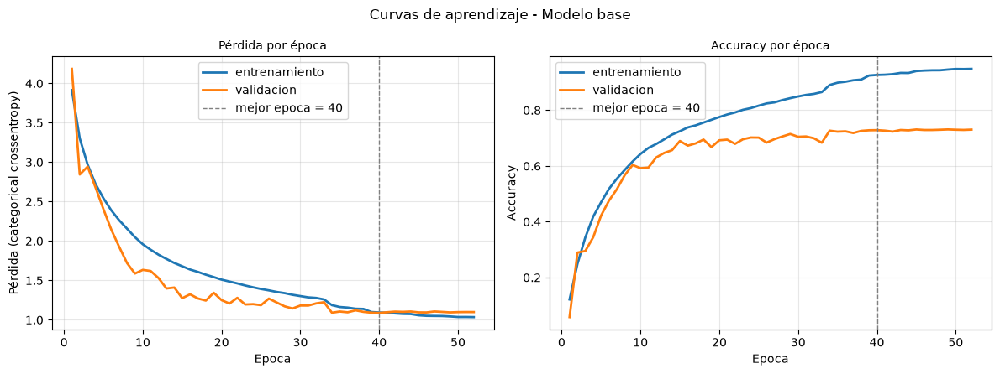

In [36]:
def graficar_curvas(historial, titulo="Modelo base"):
    """Dibuja pérdida y accuracy de entrenamiento y validación por época."""
    registro = historial.history if hasattr(historial, "history") else historial
    epocas = range(1, len(registro["loss"]) + 1)
    epoca_optima = int(np.argmin(registro["val_loss"])) + 1

    figura, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

    ejes[0].plot(epocas, registro["loss"], label="entrenamiento", linewidth=2)
    ejes[0].plot(epocas, registro["val_loss"], label="validacion", linewidth=2)
    ejes[0].set_ylabel("Pérdida (categorical crossentropy)")
    ejes[0].set_title("Pérdida por época", fontsize=10)

    ejes[1].plot(epocas, registro["accuracy"], label="entrenamiento", linewidth=2)
    ejes[1].plot(epocas, registro["val_accuracy"], label="validacion", linewidth=2)
    ejes[1].set_ylabel("Accuracy")
    ejes[1].set_title("Accuracy por época", fontsize=10)

    for eje in ejes:
        eje.axvline(
            epoca_optima,
            color="gray",
            linestyle="--",
            linewidth=1,
            label=f"mejor epoca = {epoca_optima}",
        )
        eje.set_xlabel("Epoca")
        eje.grid(alpha=0.3)
        eje.legend()

    figura.suptitle(f"Curvas de aprendizaje - {titulo}")
    plt.tight_layout()
    plt.show()


graficar_curvas(historial_base)

### Interpretación de las curvas

In [37]:
from sklearn.metrics import f1_score

registro = historial_base.history
indice_optimo = int(np.argmin(registro["val_loss"]))

# F1 macro en validación con los pesos restaurados de la mejor época
probabilidades_val = modelo_base.predict(X_val, batch_size=256, verbose=0)
predicciones_val = probabilidades_val.argmax(axis=1)
f1_macro_val = f1_score(y_val_idx, predicciones_val, average="macro")

diagnostico = pd.DataFrame(
    [
        ("Épocas ejecutadas", len(registro["loss"])),
        ("Mejor época (val_loss)", indice_optimo + 1),
        ("Pérdida entrenamiento", round(registro["loss"][indice_optimo], 4)),
        ("Pérdida validación", round(registro["val_loss"][indice_optimo], 4)),
        ("Accuracy entrenamiento", round(registro["accuracy"][indice_optimo], 4)),
        ("Accuracy validación", round(registro["val_accuracy"][indice_optimo], 4)),
        ("Top-3 accuracy validación", round(registro["val_top_3"][indice_optimo], 4)),
        ("F1 macro validación", round(float(f1_macro_val), 4)),
        (
            "Brecha train - val (accuracy)",
            round(registro["accuracy"][indice_optimo] - registro["val_accuracy"][indice_optimo], 4),
        ),
    ],
    columns=["Indicador", "Valor"],
)

display(diagnostico)

brecha = registro["accuracy"][indice_optimo] - registro["val_accuracy"][indice_optimo]
if brecha > 0.15:
    lectura = "sobreajuste claro: la red memoriza el entrenamiento y generaliza bastante peor"
elif brecha > 0.05:
    lectura = "sobreajuste moderado, contenido por el Dropout y la parada temprana"
else:
    lectura = "sin sobreajuste apreciable; las dos curvas evolucionan juntas"

print(f"Brecha train - val en accuracy: {brecha:.3f} -> {lectura}.")
print(
    f"Accuracy de validacion ({registro['val_accuracy'][indice_optimo]:.3f}) frente a los baselines:"
    f" azar {baseline_azar / 100:.3f} y clase mayoritaria {baseline_mayoritaria / 100:.3f}."
)

,Indicador,Valor
0,Épocas ejecutadas,52.0000
1,Mejor época (val_loss),40.0000
2,Pérdida entrenamiento,1.0936
3,Pérdida validación,1.0873
4,Accuracy entrenamiento,0.9266
5,Accuracy validación,0.7285
6,Top-3 accuracy validación,0.8817
7,F1 macro validación,0.7048
8,Brecha train - val (accuracy),0.1981


Brecha train - val en accuracy: 0.198 -> sobreajuste claro: la red memoriza el entrenamiento y generaliza bastante peor.
Accuracy de validacion (0.729) frente a los baselines: azar 0.016 y clase mayoritaria 0.055.


**Cómo se leen estas curvas**

Hay tres cosas que mirar en los gráficos anteriores:

1. **La separación entre las dos curvas de pérdida.** Mientras ambas bajan juntas, la red está
   aprendiendo estructura real del problema. En cuanto la pérdida de validación se aplana o sube
   mientras la de entrenamiento sigue bajando, lo que la red gana ya es memorización de las imágenes
   concretas del conjunto de entrenamiento: ese punto de cruce es el sobreajuste y es justo lo que
   detecta `EarlyStopping`.
2. **La época en que la validación deja de mejorar** (línea vertical punteada). Es la que se conserva,
   porque `restore_best_weights=True` devuelve los pesos de ese momento, y no los del final.
3. **El efecto de la regularización.** El Dropout de la cabeza hace que la curva de entrenamiento vaya *por
   debajo* de su potencial —parte de la red está apagada en cada paso— y por eso la brecha entre train y
   validación es menor de la que tendría la misma red sin regularizar. El escalón que a veces se ve en las
   curvas corresponde a `ReduceLROnPlateau` bajando el learning rate.

La tabla de arriba resume el diagnóstico: la brecha entre entrenamiento y validación cuantifica el
sobreajuste, y la distancia frente a los baselines (azar y clase mayoritaria, impresos por la celda
anterior) confirma que el modelo efectivamente aprendió algo del problema.

**En la corrida de GPU a 128 × 128 del 13-11-2026** la parada temprana corta el modelo base en la época 52 de
60: la pérdida de validación toca su mínimo en la época 40 (1,087) y no vuelve a bajar en las doce siguientes.
`ReduceLROnPlateau` divide la tasa por dos cinco veces, y el primer escalón es el que más se nota: tras él, en la
época 34, la pérdida de validación baja de 1,224 a 1,091 y la accuracy de validación sube de 0,684 a 0,727. Desde
ahí la validación queda plana en torno a 0,73 mientras el entrenamiento sigue subiendo hasta 0,95. El diagnóstico
es de sobreajuste —0,927 de accuracy en entrenamiento y 0,729 en validación en la mejor época, una brecha de
0,198—, pero la validación no empeora mientras la red memoriza, y `restore_best_weights` se queda con la época 40.
Atacar esa brecha es el objetivo de la sección «Efecto de las técnicas de regularización».

### Efecto de la parada temprana

La parada temprana es una de las técnicas de regularización del modelo base: corta el entrenamiento cuando la pérdida
de validación lleva 12 épocas sin mejorar y devuelve los pesos de su mejor época. Su efecto se lee en el propio
historial del modelo base, sin entrenar otra red: la celda compara la época que restaura con la última que llegó a
entrenar, y cuenta las épocas y el tiempo que ahorra frente al máximo de 60.


,momento,epoca,val_loss,accuracy_entrenamiento,accuracy_validacion,brecha,learning_rate
0,Mejor época: los pesos que restaura,40,1.0873,0.9266,0.7285,0.1981,0.000250
1,Última época entrenada,52,1.0991,0.9484,0.7305,0.2179,0.000063


Paró en la época 52 de 60: ahorró 8 épocas (unos 8 minutos).
Entre la mejor época y la última, la brecha pasa de 0.198 a 0.218 y la pérdida de validación, de 1.0873 a 1.0991.


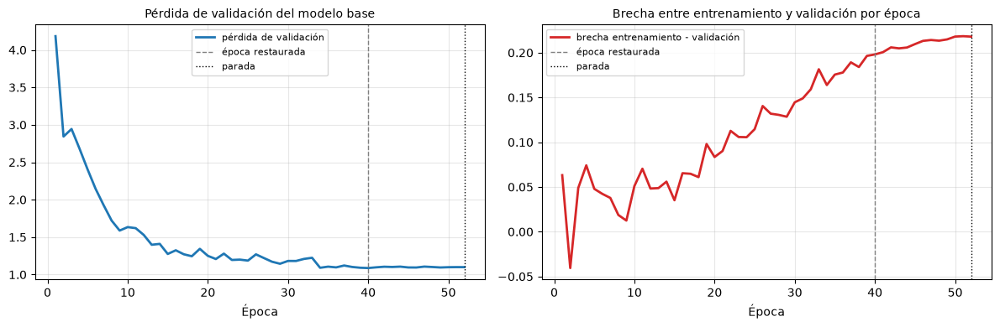

In [38]:
# Efecto de la parada temprana sobre el modelo base, leído en su historial
historia_parada = historial_base.history
indice_mejor_parada = int(np.argmin(historia_parada["val_loss"]))
indice_ultima_parada = len(historia_parada["loss"]) - 1
segundos_por_epoca_parada = segundos_entrenamiento_base / len(historia_parada["loss"])


def estado_en_epoca(indice):
    """Pérdida de validación, accuracy de entrenamiento y de validación, brecha y tasa de aprendizaje del modelo
    base en la época `indice` (contada desde 0)."""
    return {
        "epoca": indice + 1,
        "val_loss": round(historia_parada["val_loss"][indice], 4),
        "accuracy_entrenamiento": round(historia_parada["accuracy"][indice], 4),
        "accuracy_validacion": round(historia_parada["val_accuracy"][indice], 4),
        "brecha": round(historia_parada["accuracy"][indice] - historia_parada["val_accuracy"][indice], 4),
        "learning_rate": historia_parada["learning_rate"][indice],
    }


tabla_parada = pd.DataFrame(
    [
        {"momento": "Mejor época: los pesos que restaura", **estado_en_epoca(indice_mejor_parada)},
        {"momento": "Última época entrenada", **estado_en_epoca(indice_ultima_parada)},
    ]
)
display(tabla_parada)

epocas_ahorradas = EPOCAS_MAXIMAS - len(historia_parada["loss"])
print(
    f"Paró en la época {indice_ultima_parada + 1} de {EPOCAS_MAXIMAS}: ahorró {epocas_ahorradas} épocas"
    f" (unos {epocas_ahorradas * segundos_por_epoca_parada / 60:.0f} minutos)."
)
print(
    f"Entre la mejor época y la última, la brecha pasa de {tabla_parada.loc[0, 'brecha']:.3f} a"
    f" {tabla_parada.loc[1, 'brecha']:.3f} y la pérdida de validación, de {tabla_parada.loc[0, 'val_loss']:.4f}"
    f" a {tabla_parada.loc[1, 'val_loss']:.4f}."
)

epocas_parada = np.arange(1, len(historia_parada["loss"]) + 1)
figura, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(epocas_parada, historia_parada["val_loss"], linewidth=2, label="pérdida de validación")
ejes[1].plot(
    epocas_parada,
    np.array(historia_parada["accuracy"]) - np.array(historia_parada["val_accuracy"]),
    linewidth=2,
    color="tab:red",
    label="brecha entrenamiento - validación",
)
for eje in ejes:
    eje.axvline(indice_mejor_parada + 1, color="gray", linestyle="--", linewidth=1, label="época restaurada")
    eje.axvline(indice_ultima_parada + 1, color="black", linestyle=":", linewidth=1, label="parada")
    eje.set_xlabel("Época")
    eje.grid(alpha=0.3)
    eje.legend(fontsize=8)
ejes[0].set_title("Pérdida de validación del modelo base", fontsize=10)
ejes[1].set_title("Brecha entre entrenamiento y validación por época", fontsize=10)
plt.tight_layout()
plt.show()


**Lectura.** La parada temprana cortó el modelo base en la época 52 de 60 y le ahorró 8 épocas, unos 8
minutos. Lo que aporta, sobre todo, es que devuelve los pesos de la época 40: en las doce épocas siguientes la
pérdida de validación no mejoró (de 1,087 a 1,099) y la brecha entre entrenamiento y validación siguió creciendo
(de 0,198 a 0,218). La red aprendía a reconocer mejor sus imágenes de entrenamiento, no las de validación: sin la
parada temprana, el modelo que queda sería el de la última época, más sobreajustado y no mejor.

En los experimentos, con 35 épocas y una paciencia de 9, la parada no llegó a cortar ninguno, pero la restauración
de la mejor época sí cuenta en los que tocaron su mínimo antes del final: S1 en la época 26, G1 en la 27 y E7 en la
28.

## Experimentación: comparación de configuraciones



### Diseño de los experimentos

La comparación sigue el principio de **un factor a la vez**, igual que en el MLP: cada experimento cambia
exactamente un factor respecto del modelo base y deja el resto idéntico —misma semilla, misma partición,
mismos pesos por clase, mismos criterios de parada—. Así, cualquier diferencia en la métrica de validación
es atribuible al factor modificado y no a la interacción de varios cambios simultáneos.

| Exp. | Factor que cambia | Configuración | Qué pone a prueba |
|---|---|---|---|
| **Base** | — | Imagen RGB completa, 4 bloques (32, 64, 128, 256) de una convolución de 3 × 3, ReLU, pooling global, densa 256, dropout 0,3, lr 0,001, batch 128, pesos raíz, suavizado 0,1, con alteradas y Batch Normalization, sin L2 ni aumento en línea | Referencia |
| **R1** | Representación | Escala de grises | Cuánto depende la CNN del color, que era casi todo lo que usaba el MLP |
| **E1** | Profundidad | 3 bloques (32, 64, 128) | Si un bloque menos basta, con un campo receptivo de 18 × 18 píxeles en lugar de 38 × 38 |
| **E2** | Profundidad | 4 bloques de 2 convoluciones | Si más capas por bloque, al estilo de VGG, mejoran o solo encarecen |
| **E3** | Activación | tanh | El costo de una activación que se satura |
| **E4** | Tasa de aprendizaje | lr 0,0001 | Convergencia lenta pero estable frente al valor por defecto |
| **E5** | Tamaño de batch | batch 512 | Menos ruido por actualización y menos actualizaciones por época |
| **E6** | Regularización | Dropout 0,5 en la cabeza | Si más regularización reduce la brecha entre entrenamiento y validación |
| **E7** | Cabeza | Aplanado (`Flatten`) en lugar de pooling global | Si conservar la posición de cada activación ayuda o lleva a memorizar, como en el MLP |
| **P1** | Pesos por clase | Sin pesos | Cuánto aporta compensar el desbalance |
| **P2** | Pesos por clase | Balanceados completos | Si compensar del todo ayuda a los minoritarios o castiga demasiado a los frecuentes |
| **S1** | Suavizado | One-hot puro, sin suavizado | Si repartir el 10 % del objetivo ayuda con las etiquetas ambiguas |
| **A1** | Aumento de datos | Sin imágenes alteradas | Si las variantes con giro, cambio de color y filtro de textura aportan |
| **G1** | Regularización | Sin dropout en la cabeza | Cuánto aporta el Dropout de la base |
| **G2** | Regularización | Sin Batch Normalization | Cuánto aporta normalizar las activaciones de cada capa |
| **G3** | Regularización | Penalización L2 de 5·10⁻⁴ sobre los pesos | Si limitar el tamaño de los pesos reduce el sobreajuste |
| **G4** | Aumento de datos | Aumento en línea: espejo, giro, escala, desplazamiento, brillo y contraste distintos en cada paso | Si más variedad al entrenar mejora la generalización |
| **C1** | Combinación | Los cambios que superaron a la base, juntos | Si las mejoras individuales se suman |

**Estrategia de búsqueda.** La búsqueda es un *grid search* por ejes: alrededor del modelo base se recorre una
grilla de valores para un factor a la vez, y después C1 combina los mejores. Una grilla completa no es viable:
cada configuración cuesta unos 33 minutos en la GPU, y combinar solo dos valores de cada uno de los 14 factores de
la tabla darían 16.384 configuraciones, más de un año de cómputo. Un *random search* con el mismo presupuesto, unas
15 configuraciones, cambiaría varios factores a la vez y no permitiría atribuir cada diferencia a uno de ellos,
que es lo que pide la auditoría del pipeline. La búsqueda por ejes sí lo permite, y C1 responde si las mejoras se
suman.

Las métricas registradas para cada configuración son la **accuracy** de validación —comparable con los
baselines— y el **F1 macro** de validación, que promedia sin ponderar los 64 personajes y es la métrica
que realmente refleja si el modelo atiende a los minoritarios. La selección final se hace por F1 macro,
por el desbalance ya documentado.

**Combinación final (C1).** Cambiar un factor a la vez dice qué ayuda por separado, pero no si las
mejoras se suman. Por eso, tras los experimentos individuales, C1 toma para cada factor el valor del
experimento que más superó a la base en F1 macro de validación y los aplica todos juntos. Si menos de dos
factores mejoraron, C1 no se entrena: coincidiría con un experimento ya medido.

Para acotar el costo, los experimentos usan un máximo de 35 épocas y una paciencia de 9 (el modelo
base se entrenó con 60 y paciencia 12); todos comparten exactamente ese presupuesto entre sí.

**Memoria de la GPU.** En el notebook de GPU, antes de entrenar cada configuración, un paso de prueba mide
cuánta memoria usa. A 128 × 128, las dos más grandes
—dos convoluciones por bloque (E2) y batch 512 (E5)— pueden no caber, y si no caben se informa y quedan fuera
de la comparación. La prueba hace falta
porque en Windows el driver no da un error al llenarse la VRAM: pasa a usar la RAM del equipo y el
entrenamiento se vuelve decenas de veces más lento.

In [39]:
import time

from sklearn.metrics import precision_recall_fscore_support

EPOCAS_EXPERIMENTO = 35
PACIENCIA_EXPERIMENTO = 9

# Cada entrada cambia UN solo factor respecto del modelo base
experimentos = [
    {"nombre": "R1 - escala de grises", "representacion": "gris"},
    {"nombre": "E1 - 3 bloques (32,64,128)", "filtros": (32, 64, 128)},
    {"nombre": "E2 - 2 convoluciones por bloque", "convoluciones": 2},
    {"nombre": "E3 - activación tanh", "activacion": "tanh"},
    {"nombre": "E4 - learning rate 1e-4", "tasa_aprendizaje": 1e-4},
    {"nombre": "E5 - batch 512", "batch": 512},
    {"nombre": "E6 - dropout 0,5", "tasa_dropout": 0.5},
    {"nombre": "E7 - cabeza con aplanado", "cabeza": "aplanado"},
    {"nombre": "P1 - sin pesos por clase", "esquema_pesos": "ninguno"},
    {"nombre": "P2 - pesos balanceados", "esquema_pesos": "balanceado"},
    {"nombre": "S1 - sin suavizado", "suavizado": 0.0},
    {"nombre": "A1 - sin alteradas", "usar_alteradas": False},
    # Regularización: cada técnica de la base se quita, o se agrega una que la base no usa
    {"nombre": "G1 - sin dropout", "tasa_dropout": 0.0},
    {"nombre": "G2 - sin Batch Normalization", "normalizacion": False},
    {"nombre": "G3 - regularización L2 (5e-4)", "l2": 5e-4},
    {"nombre": "G4 - aumento de datos en línea", "aumento_en_linea": True},
]


def describir_configuracion(
    nombre, representacion, filtros, convoluciones, activacion, tasa_dropout, cabeza,
    tasa_aprendizaje, batch, esquema_pesos, suavizado, usar_alteradas, normalizacion, l2, aumento_en_linea,
):
    """Columnas de la tabla de experimentos que describen una configuración."""
    return {
        "experimento": nombre,
        "representacion": representacion,
        "dimension_entrada": DIMENSIONES[representacion],
        "bloques": len(filtros),
        "filtros": " - ".join(str(n) for n in filtros),
        "convoluciones_por_bloque": convoluciones,
        "cabeza": cabeza,
        "activacion": activacion,
        "dropout": tasa_dropout,
        "learning_rate": tasa_aprendizaje,
        "batch": batch,
        "pesos": esquema_pesos,
        "suavizado": suavizado,
        "alteradas": usar_alteradas,
        "batchnorm": normalizacion,
        "l2": l2,
        "aumento_en_linea": aumento_en_linea,
    }


def metricas_validacion(historia, indice, predicciones):
    """Métricas de una configuración en su mejor época: pérdida y accuracy de validación, accuracy de
    entrenamiento, brecha entre las dos y precision, recall y F1 macro de validación."""
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y_val_idx, predicciones, average="macro", zero_division=0
    )
    return {
        "val_loss": round(historia["val_loss"][indice], 4),
        "train_accuracy": round(historia["accuracy"][indice], 4),
        "val_accuracy": round(historia["val_accuracy"][indice], 4),
        "brecha": round(historia["accuracy"][indice] - historia["val_accuracy"][indice], 4),
        "val_precision_macro": round(float(precision_macro), 4),
        "val_recall_macro": round(float(recall_macro), 4),
        "val_f1_macro": round(float(f1_macro), 4),
    }


def entrenar_configuracion(
    nombre,
    representacion=REPRESENTACION_BASE,
    filtros=FILTROS_POR_BLOQUE,
    convoluciones=CONVOLUCIONES_POR_BLOQUE,
    activacion=ACTIVACION,
    tasa_dropout=TASA_DROPOUT,
    cabeza=CABEZA,
    tasa_aprendizaje=TASA_APRENDIZAJE,
    batch=TAMANO_BATCH,
    epocas=EPOCAS_EXPERIMENTO,
    paciencia=PACIENCIA_EXPERIMENTO,
    esquema_pesos=ESQUEMA_PESOS,
    suavizado=SUAVIZADO_ETIQUETAS,
    usar_alteradas=True,
    normalizacion=NORMALIZACION,
    l2=0.0,
    aumento_en_linea=False,
):
    """Entrena una configuración y devuelve el modelo, su historial y sus métricas de validación."""
    keras.utils.set_random_seed(SEMILLA)  # misma inicialización para todas las configuraciones

    identificador = nombre.split(" - ")[0].strip().lower().replace(" ", "_")
    modelo = construir_cnn(
        filtros_por_bloque=filtros,
        convoluciones_por_bloque=convoluciones,
        activacion=activacion,
        tasa_dropout=tasa_dropout,
        cabeza=cabeza,
        representacion=representacion,
        normalizacion=normalizacion,
        nombre=f"cnn_{identificador}",
    )
    modelo = modelo.to(DISPOSITIVO)
    compilar(modelo, tasa_aprendizaje=tasa_aprendizaje)  # solo para predict()

    # Sin alteradas, el entrenamiento recorre solo las filas originales de train, sin copiarlas: una copia de
    # 1,8 GB llena la VRAM y el driver pasa a usar la RAM del equipo
    filas_entrenamiento = None if usar_alteradas else filas_originales_train

    inicio = time.perf_counter()
    historial = entrenar(
        modelo,
        X_train,
        y_train,
        X_val,
        y_val,
        epocas=epocas,
        batch=batch,
        tasa_aprendizaje=tasa_aprendizaje,
        pesos_por_clase=PESOS_POR_ESQUEMA[esquema_pesos],
        suavizado=suavizado,
        l2=l2,
        aumento_en_linea=aumento_en_linea,
        filas_entrenamiento=filas_entrenamiento,
        paciencia=paciencia,
        ruta_modelo=DIRECTORIO_MODELOS / f"cnn_{identificador}.keras",
        verbose=0,
    )
    duracion = time.perf_counter() - inicio

    indice = int(np.argmin(historial.history["val_loss"]))
    predicciones = modelo.predict(X_val, batch_size=256, verbose=0).argmax(axis=1)

    resultado = {
        **describir_configuracion(
            nombre, representacion, filtros, convoluciones, activacion, tasa_dropout, cabeza,
            tasa_aprendizaje, batch, esquema_pesos, suavizado, usar_alteradas, normalizacion, l2, aumento_en_linea,
        ),
        "epocas": len(historial.history["loss"]),
        "mejor_epoca": indice + 1,
        "parametros": int(modelo.count_params()),
        **metricas_validacion(historial.history, indice, predicciones),
        "segundos": round(duracion, 1),
    }
    return modelo, historial, resultado


modelos = {}
historiales = {}
resultados = []

# El modelo base ya está entrenado: se incorpora a la comparación sin volver a entrenarlo
NOMBRE_BASE = "Base - rgb, 4 bloques (32,64,128,256)"
resultados.append(
    {
        **describir_configuracion(
            NOMBRE_BASE, REPRESENTACION_BASE, FILTROS_POR_BLOQUE, CONVOLUCIONES_POR_BLOQUE, ACTIVACION,
            TASA_DROPOUT, CABEZA, TASA_APRENDIZAJE, TAMANO_BATCH, ESQUEMA_PESOS, SUAVIZADO_ETIQUETAS,
            True, NORMALIZACION, 0.0, False,
        ),
        "epocas": len(historial_base.history["loss"]),
        "mejor_epoca": indice_optimo + 1,
        "parametros": int(modelo_base.count_params()),
        **metricas_validacion(historial_base.history, indice_optimo, predicciones_val),
        "segundos": np.nan,
    }
)
modelos[NOMBRE_BASE] = modelo_base
historiales[NOMBRE_BASE] = historial_base.history


def cabe_en_la_gpu(factores):
    """Estima la memoria que usará un paso de entrenamiento de la configuración y comprueba que cabe en
    la tarjeta. En Windows el driver no da un error cuando la VRAM se llena: pasa a usar la RAM del
    equipo y el entrenamiento se vuelve decenas de veces más lento. Por eso no se prueba el batch
    completo, sino dos lotes pequeños que siempre caben, y se extrapola: la memoria de las
    activaciones crece en línea recta con el tamaño del lote."""
    if DISPOSITIVO != "cuda":
        return True
    keras.utils.set_random_seed(SEMILLA)
    modelo = construir_cnn(
        filtros_por_bloque=factores.get("filtros", FILTROS_POR_BLOQUE),
        convoluciones_por_bloque=factores.get("convoluciones", CONVOLUCIONES_POR_BLOQUE),
        cabeza=factores.get("cabeza", CABEZA),
        representacion=factores.get("representacion", REPRESENTACION_BASE),
        normalizacion=factores.get("normalizacion", NORMALIZACION),
        nombre="cnn_prueba_memoria",
    ).to(DISPOSITIVO)
    picos = {}
    for lote in (8, 32):
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        probabilidades = modelo(X_train[:lote], training=True)
        perdida = -(y_train[:lote] * torch.log(probabilidades.clamp_min(1e-7))).sum(1).mean()
        perdida.backward()
        picos[lote] = torch.cuda.max_memory_allocated()
        modelo.zero_grad(set_to_none=True)
        del probabilidades, perdida
    del modelo
    torch.cuda.empty_cache()
    batch = factores.get("batch", TAMANO_BATCH)
    por_imagen = (picos[32] - picos[8]) / (32 - 8)
    estimada = picos[32] + por_imagen * (batch - 32)
    return estimada < 0.9 * torch.cuda.get_device_properties(0).total_memory


def registrar(nombre, factores):
    """Entrena una configuración y la añade a la comparación. Devuelve su resultado, o None si
    no cabe en la memoria de la GPU."""
    print(f"Entrenando {nombre} ...")
    if not cabe_en_la_gpu(factores):
        print("   no cabe en la memoria de la GPU a esta resolucion: queda fuera de la comparacion")
        return None
    try:
        modelo, historial, resultado = entrenar_configuracion(nombre, **factores)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        print("   sin memoria suficiente en la GPU: la configuracion queda fuera de la comparacion")
        return None
    modelos[nombre] = modelo
    historiales[nombre] = historial.history
    resultados.append(resultado)
    print(
        f"   val_accuracy={resultado['val_accuracy']:.4f}"
        f"   val_f1_macro={resultado['val_f1_macro']:.4f}"
        f"   epocas={resultado['epocas']}   {resultado['segundos']:.0f} s"
    )
    return resultado


resultado_por_experimento = {}
for configuracion in experimentos:
    resultado_por_experimento[configuracion["nombre"]] = registrar(
        configuracion["nombre"],
        {factor: valor for factor, valor in configuracion.items() if factor != "nombre"},
    )

# C1: para cada factor, el valor del experimento que más superó a la base en F1 macro
f1_macro_base = resultados[0]["val_f1_macro"]
mejor_por_factor = {}
for configuracion in experimentos:
    resultado = resultado_por_experimento[configuracion["nombre"]]
    if resultado is None or resultado["val_f1_macro"] <= f1_macro_base:
        continue
    for factor, valor in configuracion.items():
        if factor == "nombre":
            continue
        if factor not in mejor_por_factor or resultado["val_f1_macro"] > mejor_por_factor[factor][1]:
            mejor_por_factor[factor] = (valor, resultado["val_f1_macro"], configuracion["nombre"])

componentes_combinacion = sorted({origen for _, _, origen in mejor_por_factor.values()})
if len(mejor_por_factor) >= 2:
    print(f"\nC1 combina: {' + '.join(componentes_combinacion)}")
    registrar(
        "C1 - combinación de mejoras",
        {factor: valor for factor, (valor, _, _) in mejor_por_factor.items()},
    )
else:
    print(
        f"\nC1 no se entrena: solo {len(mejor_por_factor)} factor(es) superaron a la base"
        f" ({', '.join(componentes_combinacion) or 'ninguno'}), así que no hay nada que combinar."
    )

tabla_experimentos = pd.DataFrame(resultados)
display(tabla_experimentos)

Entrenando R1 - escala de grises ...


   val_accuracy=0.6507   val_f1_macro=0.6193   epocas=35   1994 s
Entrenando E1 - 3 bloques (32,64,128) ...


   val_accuracy=0.6751   val_f1_macro=0.6447   epocas=35   1809 s
Entrenando E2 - 2 convoluciones por bloque ...


   no cabe en la memoria de la GPU a esta resolucion: queda fuera de la comparacion
Entrenando E3 - activación tanh ...


   val_accuracy=0.5660   val_f1_macro=0.5244   epocas=35   2060 s
Entrenando E4 - learning rate 1e-4 ...


   val_accuracy=0.5663   val_f1_macro=0.5216   epocas=35   1990 s
Entrenando E5 - batch 512 ...


... (9 outputs left out)

   val_accuracy=0.7327   val_f1_macro=0.7106   epocas=35   1982 s
Entrenando G4 - aumento de datos en línea ...


   val_accuracy=0.7438   val_f1_macro=0.7239   epocas=35   2031 s

C1 combina: G3 - regularización L2 (5e-4) + G4 - aumento de datos en línea
Entrenando C1 - combinación de mejoras ...


   val_accuracy=0.7387   val_f1_macro=0.7115   epocas=35   2032 s


,experimento,representacion,dimension_entrada,bloques,filtros,convoluciones_por_bloque,cabeza,activacion,dropout,learning_rate,...,mejor_epoca,parametros,val_loss,train_accuracy,val_accuracy,brecha,val_precision_macro,val_recall_macro,val_f1_macro,segundos
0,"Base - rgb, 4 bloques (32,64,128,256)",rgb,49152,4,32 - 64 - 128 - 256,1,pooling_global,relu,0.3,0.0010,...,40,473120,1.0873,0.9266,0.7285,0.1981,0.7167,0.6991,0.7048,NaN
1,R1 - escala de grises,gris,16384,4,32 - 64 - 128 - 256,1,pooling_global,relu,0.3,0.0010,...,32,472547,1.3944,0.8568,0.6507,0.2061,0.6374,0.6156,0.6193,1994.0
2,"E1 - 3 bloques (32,64,128)",rgb,49152,3,32 - 64 - 128,1,pooling_global,relu,0.3,0.0010,...,35,144416,1.3066,0.6762,0.6751,0.0011,0.6642,0.6539,0.6447,1808.8
3,E3 - activación tanh,rgb,49152,4,32 - 64 - 128 - 256,1,pooling_global,tanh,0.3,0.0010,...,33,473120,1.6881,0.6229,0.5660,0.0568,0.5513,0.5391,0.5244,2060.4
4,E4 - learning rate 1e-4,rgb,49152,4,32 - 64 - 128 - 256,1,pooling_global,relu,0.3,0.0001,...,34,473120,1.7604,0.5237,0.5663,-0.0426,0.5537,0.5233,0.5216,1990.3
5,"E6 - dropout 0,5",rgb,49152,4,32 - 64 - 128 - 256,1,pooling_global,relu,0.5,0.0010,...,35,473120,1.1097,0.7953,0.7203,0.0750,0.7020,0.6987,0.6970,1989.1
6,E7 - cabeza con aplanado,rgb,49152,4,32 - 64 - 128 - 256,1,aplanado,relu,0.3,0.0010,...,28,4601888,1.4202,0.9794,0.6796,0.2998,0.6680,0.6422,0.6510,1993.1
7,P1 - sin pesos por clase,rgb,49152,4,32 - 64 - 128 - 256,1,pooling_global,relu,0.3,0.0010,...,35,473120,1.0738,0.9147,0.7257,0.1891,0.7237,0.6900,0.7007,1986.6
8,P2 - pesos balanceados,rgb,49152,4,32 - 64 - 128 - 256,1,pooling_global,relu,0.3,0.0010,...,35,473120,1.1617,0.8426,0.7112,0.1314,0.6959,0.7000,0.6882,1985.7
9,S1 - sin suavizado,rgb,49152,4,32 - 64 - 128 - 256,1,pooling_global,relu,0.3,0.0010,...,26,473120,1.0929,0.8342,0.7202,0.1139,0.7055,0.7047,0.6984,1983.6


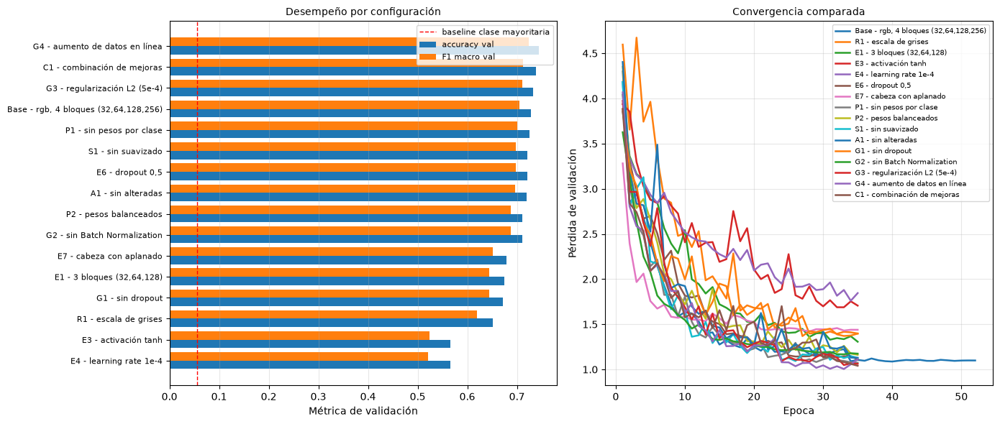

In [40]:
# Comparación visual de las configuraciones por accuracy y F1 macro de validación
orden_resultados = tabla_experimentos.sort_values("val_f1_macro", ascending=True)
posiciones = np.arange(len(orden_resultados))

figura, ejes = plt.subplots(1, 2, figsize=(14, 6))

ejes[0].barh(posiciones - 0.2, orden_resultados["val_accuracy"], height=0.4, label="accuracy val")
ejes[0].barh(posiciones + 0.2, orden_resultados["val_f1_macro"], height=0.4, label="F1 macro val")
ejes[0].set_yticks(posiciones)
ejes[0].set_yticklabels(orden_resultados["experimento"], fontsize=8)
ejes[0].axvline(baseline_mayoritaria / 100, color="red", linestyle="--", linewidth=1, label="baseline clase mayoritaria")
ejes[0].set_xlabel("Métrica de validación")
ejes[0].set_title("Desempeño por configuración", fontsize=10)
ejes[0].legend(fontsize=8)
ejes[0].grid(alpha=0.3, axis="x")

for nombre, registro_historial in historiales.items():
    ejes[1].plot(
        range(1, len(registro_historial["val_loss"]) + 1),
        registro_historial["val_loss"],
        label=nombre,
        linewidth=1.8,
    )
ejes[1].set_xlabel("Epoca")
ejes[1].set_ylabel("Pérdida de validación")
ejes[1].set_title("Convergencia comparada", fontsize=10)
ejes[1].grid(alpha=0.3)
ejes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

### Efecto de la representación de entrada

,experimento,representacion,dimension_entrada,parametros,val_accuracy,val_f1_macro,epocas,segundos
0,"Base - rgb, 4 bloques (32,64,128,256)",rgb,49152,473120,0.7285,0.7048,52,NaN
1,R1 - escala de grises,gris,16384,472547,0.6507,0.6193,35,1994.0


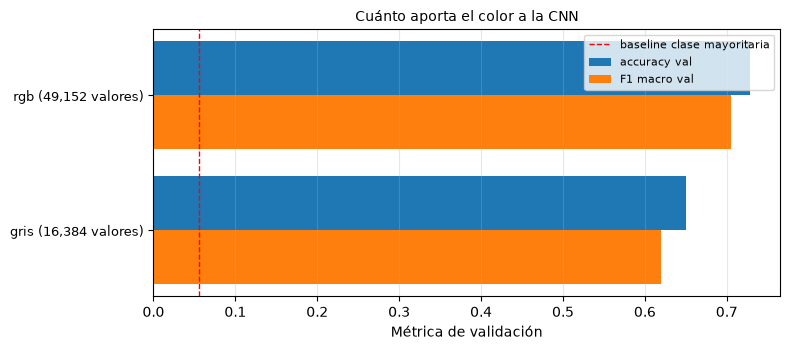

In [41]:
# Solo las configuraciones que cambian la representación (misma arquitectura que el base)
comparacion_representacion = tabla_experimentos[
    tabla_experimentos["experimento"].str.match(r"Base|R\d")
][["experimento", "representacion", "dimension_entrada", "parametros", "val_accuracy", "val_f1_macro", "epocas", "segundos"]]
comparacion_representacion = comparacion_representacion.sort_values(
    "val_f1_macro", ascending=False
).reset_index(drop=True)

display(comparacion_representacion)

figura, eje = plt.subplots(figsize=(8, 3.6))
posiciones = np.arange(len(comparacion_representacion))
eje.barh(posiciones - 0.2, comparacion_representacion["val_accuracy"], height=0.4, label="accuracy val")
eje.barh(posiciones + 0.2, comparacion_representacion["val_f1_macro"], height=0.4, label="F1 macro val")
eje.set_yticks(posiciones)
eje.set_yticklabels(
    [
        f"{fila.representacion} ({fila.dimension_entrada:,} valores)"
        for fila in comparacion_representacion.itertuples()
    ],
    fontsize=9,
)
eje.invert_yaxis()
eje.axvline(
    baseline_mayoritaria / 100,
    color="red",
    linestyle="--",
    linewidth=1,
    label="baseline clase mayoritaria",
)
eje.set_xlabel("Métrica de validación")
eje.set_title("Cuánto aporta el color a la CNN", fontsize=10)
eje.grid(alpha=0.3, axis="x")
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.** El color sigue importando, también para una CNN. Sin él (R1, escala de grises), el F1 macro de
validación cae de 0,705 a 0,619 —8,6 puntos— y la accuracy, de 0,729 a 0,651, con la misma arquitectura y
prácticamente los mismos parámetros. Es una caída grande, pero no la mayor: la tasa de aprendizaje baja
(E4) y tanh (E3) cuestan más. A 128 × 128 la red encuentra en la forma buena parte de lo que le da el color.

La comparación con el MLP es reveladora: el MLP se quedaba con el color y descartaba la textura, mientras
que la CNN en escala de grises, sin ningún color, llega aquí a 0,619 de F1 macro de validación, y con imagen
RGB, que aprovecha las dos cosas, sube a 0,705. Lo que distingue a estos personajes es la combinación: la paleta de
cada uno y la silueta, el peinado y la ropa que la dibujan.

### Efecto de la profundidad de la red

,experimento,bloques,filtros,convoluciones_por_bloque,parametros,val_accuracy,val_f1_macro,epocas,segundos,capas_convolucionales,parametros_millones
0,"E1 - 3 bloques (32,64,128)",3,32 - 64 - 128,1,144416,0.6751,0.6447,35,1808.8,3,0.144
1,"Base - rgb, 4 bloques (32,64,128,256)",4,32 - 64 - 128 - 256,1,473120,0.7285,0.7048,52,NaN,4,0.473


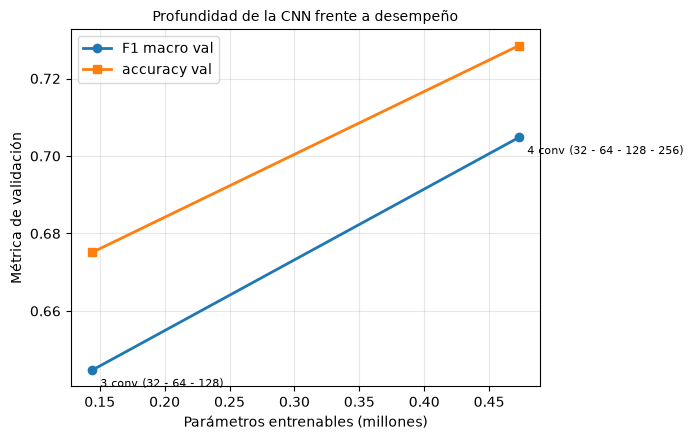

In [42]:
# Solo las configuraciones que cambian la profundidad (misma activación, lr y batch que el base)
comparacion_arquitectura = tabla_experimentos[
    tabla_experimentos["experimento"].str.contains("Base|E1|E2")
][["experimento", "bloques", "filtros", "convoluciones_por_bloque", "parametros", "val_accuracy", "val_f1_macro", "epocas", "segundos"]]
comparacion_arquitectura = comparacion_arquitectura.sort_values("parametros").reset_index(drop=True)

comparacion_arquitectura["capas_convolucionales"] = (
    comparacion_arquitectura["bloques"] * comparacion_arquitectura["convoluciones_por_bloque"]
)
comparacion_arquitectura["parametros_millones"] = (
    comparacion_arquitectura["parametros"] / 1e6
).round(3)

display(comparacion_arquitectura)

figura, eje = plt.subplots(figsize=(7, 4.5))
eje.plot(
    comparacion_arquitectura["parametros_millones"],
    comparacion_arquitectura["val_f1_macro"],
    marker="o",
    linewidth=2,
    label="F1 macro val",
)
eje.plot(
    comparacion_arquitectura["parametros_millones"],
    comparacion_arquitectura["val_accuracy"],
    marker="s",
    linewidth=2,
    label="accuracy val",
)
for _, fila in comparacion_arquitectura.iterrows():
    eje.annotate(
        f"{fila['capas_convolucionales']} conv ({fila['filtros']})",
        (fila["parametros_millones"], fila["val_f1_macro"]),
        textcoords="offset points",
        xytext=(6, -12),
        fontsize=8,
    )
eje.set_xlabel("Parámetros entrenables (millones)")
eje.set_ylabel("Métrica de validación")
eje.set_title("Profundidad de la CNN frente a desempeño", fontsize=10)
eje.grid(alpha=0.3)
eje.legend()
plt.tight_layout()
plt.show()

**Lectura.** A 128 × 128 solo se puede medir la mitad de la pregunta. E2, con dos convoluciones por bloque
(ocho capas convolucionales), no cabe en la memoria de la GPU a esta resolución y queda fuera de la
comparación. Lo que sí se mide es quitar un bloque: E1 cae a un F1 macro de 0,645 frente a 0,705 de la base
—6,0 puntos— y la accuracy, de 0,729 a 0,675. No es sobreajuste: E1 tiene casi la misma accuracy en entrenamiento
que en validación (brecha de 0,001), le falta capacidad. Con tres bloques, las neuronas del último ven zonas de
18 × 18 píxeles, el 14 % del lado de una imagen de 128 × 128, en lugar de 38 × 38 (30 %): cuanto mayor es la imagen,
más falta hace la profundidad para que la red vea partes enteras del personaje.

El cuarto bloque cuesta poco. E1 tiene menos de un tercio de los parámetros de la base (144.416 frente a 473.120),
pero apenas ahorra tiempo (51,7 s por época frente a 56,6 s), porque el costo está en los primeros bloques,
que trabajan sobre los mapas más grandes. E2 tendría 2,7 veces los parámetros de la base (1,26 millones) y el
doble de activaciones por bloque, que a 128 × 128 ya no caben en los 8 GB de la tarjeta.

### Efecto de la función de activación

,experimento,activacion,val_loss,val_accuracy,val_f1_macro,epocas,mejor_epoca
0,"Base - rgb, 4 bloques (32,64,128,256)",relu,1.0873,0.7285,0.7048,52,40
1,E3 - activación tanh,tanh,1.6881,0.5660,0.5244,35,33


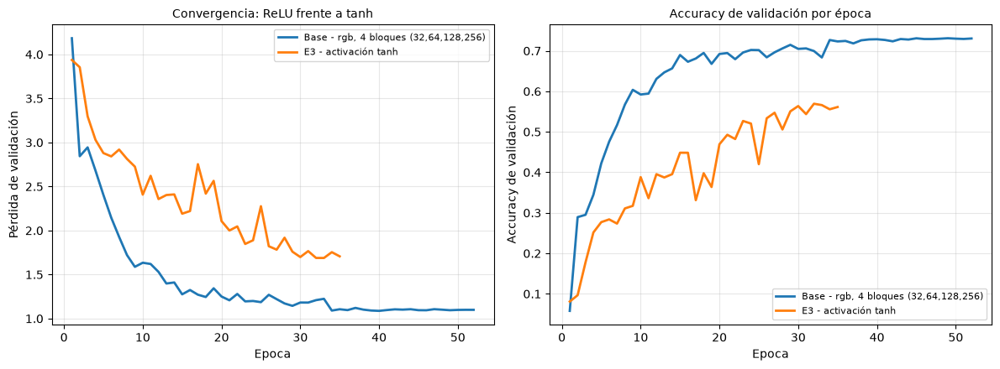

In [43]:
comparacion_activacion = tabla_experimentos[
    tabla_experimentos["experimento"].str.contains("Base|E3")
][["experimento", "activacion", "val_loss", "val_accuracy", "val_f1_macro", "epocas", "mejor_epoca"]]

display(comparacion_activacion.reset_index(drop=True))

figura, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

for nombre in comparacion_activacion["experimento"]:
    registro_historial = historiales[nombre]
    epocas_rango = range(1, len(registro_historial["loss"]) + 1)
    ejes[0].plot(epocas_rango, registro_historial["val_loss"], linewidth=2, label=nombre)
    ejes[1].plot(epocas_rango, registro_historial["val_accuracy"], linewidth=2, label=nombre)

ejes[0].set_ylabel("Pérdida de validación")
ejes[0].set_title("Convergencia: ReLU frente a tanh", fontsize=10)
ejes[1].set_ylabel("Accuracy de validación")
ejes[1].set_title("Accuracy de validación por época", fontsize=10)

for eje in ejes:
    eje.set_xlabel("Epoca")
    eje.grid(alpha=0.3)
    eje.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Lectura.** ReLU gana con claridad. Con tanh (E3) el F1 macro de validación cae 18,0 puntos (0,524 frente a
0,705) y la accuracy, de 0,729 a 0,566. Con más capas apiladas, la saturación de tanh pesa más, porque el
gradiente se atenúa en cada una que atraviesa.

En el recorrido de una imagen por la red entrenada (sección «El modelo en acción sobre el conjunto de
test»), ReLU deja distintos de cero el 47 % de los valores del primer bloque, el 24 % del segundo, el 9 %
del tercero y apenas el 2 % del último: la representación es dispersa, y mucho más selectiva en los bloques
profundos.

### Efecto del número de épocas, el tamaño de batch y la tasa de aprendizaje

,experimento,learning_rate,batch,epocas,mejor_epoca,val_loss,val_accuracy,val_f1_macro,segundos
0,"Base - rgb, 4 bloques (32,64,128,256)",0.0010,128,52,40,1.0873,0.7285,0.7048,NaN
1,E4 - learning rate 1e-4,0.0001,128,35,34,1.7604,0.5663,0.5216,1990.3


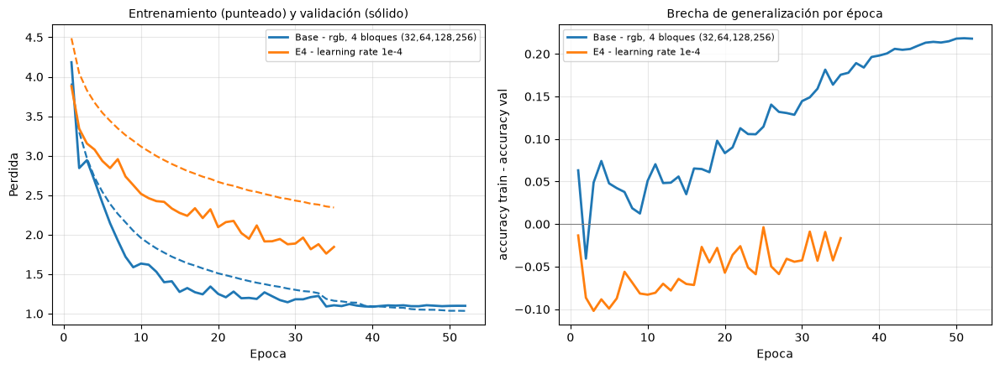

In [44]:
comparacion_optimizacion = tabla_experimentos[
    tabla_experimentos["experimento"].str.contains("Base|E4|E5")
][["experimento", "learning_rate", "batch", "epocas", "mejor_epoca", "val_loss", "val_accuracy", "val_f1_macro", "segundos"]]

display(comparacion_optimizacion.reset_index(drop=True))

figura, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

for nombre in comparacion_optimizacion["experimento"]:
    registro_historial = historiales[nombre]
    epocas_rango = range(1, len(registro_historial["loss"]) + 1)
    ejes[0].plot(epocas_rango, registro_historial["loss"], linewidth=1.6, linestyle="--")
    ejes[0].plot(
        epocas_rango,
        registro_historial["val_loss"],
        linewidth=2,
        label=nombre,
        color=ejes[0].lines[-1].get_color(),
    )
    ejes[1].plot(
        epocas_rango,
        np.array(registro_historial["accuracy"]) - np.array(registro_historial["val_accuracy"]),
        linewidth=2,
        label=nombre,
    )

ejes[0].set_ylabel("Perdida")
ejes[0].set_title("Entrenamiento (punteado) y validación (sólido)", fontsize=10)
ejes[1].axhline(0, color="gray", linewidth=0.8)
ejes[1].set_ylabel("accuracy train - accuracy val")
ejes[1].set_title("Brecha de generalización por época", fontsize=10)

for eje in ejes:
    eje.set_xlabel("Epoca")
    eje.grid(alpha=0.3)
    eje.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Lectura.** Los tres hiperparámetros de optimización están acoplados y conviene leerlos juntos:

- **Tasa de aprendizaje.** Con 1e-4 (E4) el F1 macro de validación cae 18,3 puntos (0,522 frente a 0,705):
  con un paso diez veces menor, 35 épocas no alcanzan. Es la mayor caída de toda la experimentación: una red
  con varias capas tarda mucho más en converger con un paso pequeño. La base,
  en cambio, aprovecha bajar la tasa en el momento justo: el primer escalón de `ReduceLROnPlateau` (tras la
  época 33) sube la accuracy de validación de 0,684 a 0,727 en una sola época.
- **Tamaño de batch.** Con batch 512 (E5) no hay medición: no cabe en la memoria de la GPU. A batch 128 la
  tarjeta ya trabaja el 99,3 % del tiempo (ver «Resumen de rendimiento de la corrida en la GPU»), y el barrido de
  tamaño de lote muestra que batch 256 tampoco cabe. En el MLP la GPU pasa la mayor parte del tiempo esperando y un
  lote mayor abarata cada época; en la CNN, agrandar el lote solo reduciría las actualizaciones por época.
- **Número de épocas.** La base toca su mínimo en la época 40, más allá del presupuesto de 35 épocas de los
  experimentos: en la época 35 su accuracy de validación era de 0,723, por debajo de su 0,729 final. Eso pone a los
  experimentos en desventaja, y seis de ellos —E1, E6, P1, P2, A1 y C1— tienen su mejor época en la última:
  seguían mejorando cuando se acabó el presupuesto. Aun así, G4 supera a la base con 35 épocas frente a sus 52.

### Efecto de la cabeza: pooling global frente a aplanado

La cabeza decide qué parte del último mapa de activación llega a la capa densa. Con **pooling global** (el
modelo base) llega un número por filtro —cuánto se activó en toda la imagen— y la posición se pierde a
propósito: da igual si el pelo de Marge está arriba a la izquierda o al centro. Con **aplanado** (E7) llega
el mapa completo de 8 × 8 × 256, con la posición de cada activación, como entraban los píxeles al MLP: la
capa densa tiene 64 veces más pesos y puede aprender en qué zona del encuadre suele estar cada personaje.

,experimento,cabeza,parametros,val_loss,val_accuracy,val_f1_macro,epocas,mejor_epoca
0,"Base - rgb, 4 bloques (32,64,128,256)",pooling_global,473120,1.0873,0.7285,0.7048,52,40
1,E7 - cabeza con aplanado,aplanado,4601888,1.4202,0.6796,0.6510,35,28


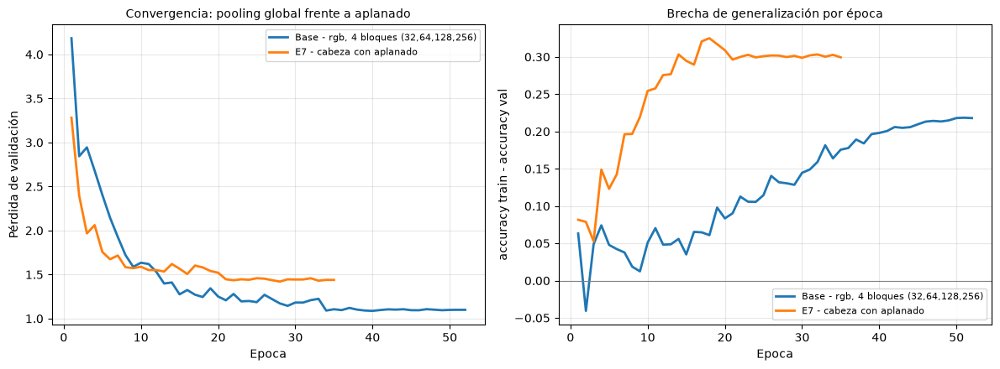

In [45]:
comparacion_cabeza = tabla_experimentos[
    tabla_experimentos["experimento"].str.match(r"Base|E7")
][["experimento", "cabeza", "parametros", "val_loss", "val_accuracy", "val_f1_macro", "epocas", "mejor_epoca"]]

display(comparacion_cabeza.reset_index(drop=True))

figura, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

for nombre in comparacion_cabeza["experimento"]:
    registro_historial = historiales[nombre]
    epocas_rango = range(1, len(registro_historial["loss"]) + 1)
    ejes[0].plot(epocas_rango, registro_historial["val_loss"], linewidth=2, label=nombre)
    ejes[1].plot(
        epocas_rango,
        np.array(registro_historial["accuracy"]) - np.array(registro_historial["val_accuracy"]),
        linewidth=2,
        label=nombre,
    )

ejes[0].set_ylabel("Pérdida de validación")
ejes[0].set_title("Convergencia: pooling global frente a aplanado", fontsize=10)
ejes[1].axhline(0, color="gray", linewidth=0.8)
ejes[1].set_ylabel("accuracy train - accuracy val")
ejes[1].set_title("Brecha de generalización por época", fontsize=10)

for eje in ejes:
    eje.set_xlabel("Epoca")
    eje.grid(alpha=0.3)
    eje.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Lectura.** El pooling global gana. Con aplanado (E7) el F1 macro de validación baja 5,4 puntos (0,651
frente a 0,705) con casi diez veces los parámetros (4,6 millones), y la red memoriza antes: la brecha entre
entrenamiento y validación pasa de 0,25 hacia la época 10, llega a 0,32 en la 18 y ronda 0,30 desde ahí, mientras
la de la base no pasa de 0,22 en 52 épocas. Su pérdida de validación baja más rápido que la de la base en las
primeras épocas, pero se estanca en torno a 1,45 desde la época 15 y toca su mínimo en la 28 (1,420): lo que gana
al principio es memoria, no generalización.

Es lo que se esperaba. Con el mapa completo, la capa densa puede aprender en qué zona del encuadre suele
estar cada personaje, una regularidad de las imágenes de entrenamiento y no del personaje. El pooling global
obliga a decidir por qué patrones aparecen y no por dónde: es la invarianza a la posición que el MLP sobre
píxeles no tenía.

### Efecto de las técnicas de regularización

El modelo base ya combina varias técnicas de regularización: Batch Normalization tras cada convolución, Dropout de 0,3
en la cabeza, suavizado de etiquetas de 0,1, imágenes alteradas y la parada temprana. Esta sección mide el aporte de
cada una con el mismo diseño de un factor a la vez: la base frente a la misma red sin la técnica, o con una técnica
que la base no usa.

| Técnica | Experimentos | Qué se compara |
|---|---|---|
| Dropout | G1 (sin dropout) y E6 (0,5) | 0, 0,3 (la base) y 0,5 en la cabeza |
| Batch Normalization | G2 | La base frente a la misma red sin ninguna capa de Batch Normalization |
| Regularización L2 | G3 | Una penalización de 5·10⁻⁴ por el cuadrado de los pesos de las convoluciones y de las capas densas |
| Aumento de datos | A1 y G4 | Sin las alteradas (A1) y, además de ellas, un aumento en línea distinto en cada paso (G4): espejo, giro de hasta 10°, escala de 0,9 a 1,1, desplazamiento de hasta un 8 % y cambio de brillo y contraste |
| Suavizado de etiquetas | S1 | La base frente al one-hot puro |
| Parada temprana | — | Ver «Efecto de la parada temprana» |

Además de la accuracy y el F1 macro de validación, la tabla mide la **brecha** entre la accuracy de entrenamiento y la
de validación en la mejor época: una técnica que regulariza tiende a achicarla. La accuracy de entrenamiento es la que
registra el bucle, con el Dropout y el aumento activos, como hace Keras; con el aumento en línea se mide sobre imágenes
transformadas, más difíciles, así que su brecha se achica también por esa razón y la conclusión se apoya en la
validación. Las curvas muestran, para cada técnica, la pérdida de validación y la brecha época a época.


,tecnica,experimento,val_accuracy,val_f1_macro,brecha,mejor_epoca,epocas,delta_val_accuracy,delta_val_f1_macro,delta_brecha
0,Ninguna: la base,"Base - rgb, 4 bloques (32,64,128,256)",0.7285,0.7048,0.1981,40,52,0.0000,0.0000,0.0000
1,Dropout,"E6 - dropout 0,5",0.7203,0.6970,0.0750,35,35,-0.0082,-0.0078,-0.1231
2,Dropout,G1 - sin dropout,0.6712,0.6444,0.3117,27,35,-0.0573,-0.0604,0.1136
3,Batch Normalization,G2 - sin Batch Normalization,0.7102,0.6869,0.0624,33,35,-0.0183,-0.0179,-0.1357
4,Regularización L2,G3 - regularización L2 (5e-4),0.7327,0.7106,0.1476,33,35,0.0042,0.0058,-0.0505
5,Aumento de datos,A1 - sin alteradas,0.7190,0.6965,0.1753,35,35,-0.0095,-0.0083,-0.0228
6,Aumento de datos,G4 - aumento de datos en línea,0.7438,0.7239,0.0199,33,35,0.0153,0.0191,-0.1782
7,Suavizado de etiquetas,S1 - sin suavizado,0.7202,0.6984,0.1139,26,35,-0.0083,-0.0064,-0.0842
8,Combinación,C1 - combinación de mejoras,0.7387,0.7115,0.0138,35,35,0.0102,0.0067,-0.1843


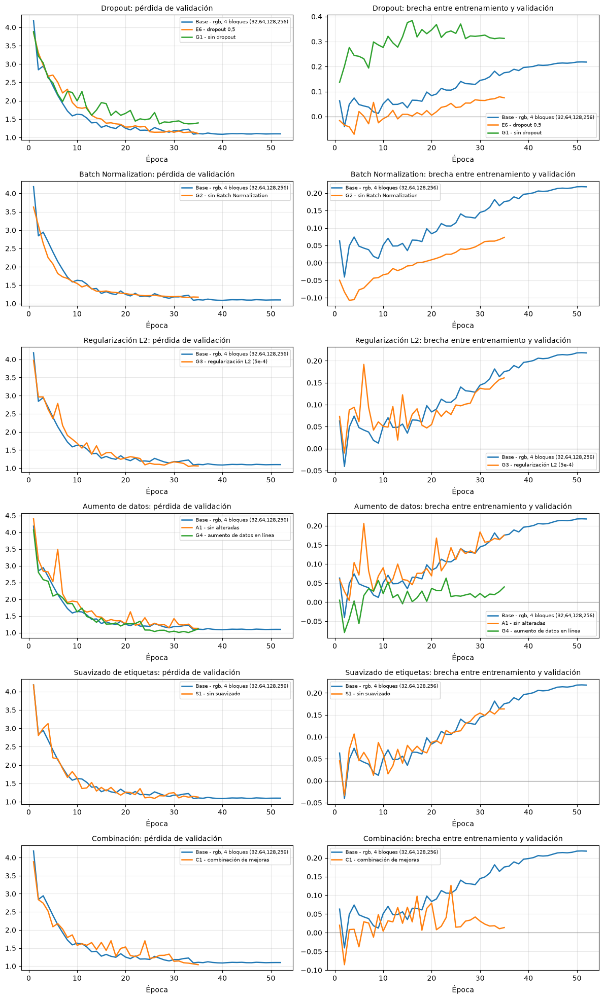

In [46]:
# Efecto de cada técnica de regularización: la base frente a la misma red sin la técnica, o con una que la base no usa
TECNICAS_REGULARIZACION = [
    ("Dropout", ("G1", "E6")),
    ("Batch Normalization", ("G2",)),
    ("Regularización L2", ("G3",)),
    ("Aumento de datos", ("A1", "G4")),
    ("Suavizado de etiquetas", ("S1",)),
    ("Combinación", ("C1",)),
]
COLUMNAS_REGULARIZACION = ["experimento", "val_accuracy", "val_f1_macro", "brecha", "mejor_epoca", "epocas"]
fila_base_regularizacion = tabla_experimentos[tabla_experimentos["experimento"].str.startswith("Base")].iloc[0]


def nombres_de(codigos):
    """Nombres completos de los experimentos entrenados cuyo código está en `codigos`; los que no cupieron en la
    GPU no aparecen."""
    return [nombre for nombre in tabla_experimentos["experimento"] if nombre.split(" - ")[0] in codigos]


filas_regularizacion = [{"tecnica": "Ninguna: la base", **fila_base_regularizacion[COLUMNAS_REGULARIZACION].to_dict()}]
for tecnica, codigos in TECNICAS_REGULARIZACION:
    for nombre in nombres_de(codigos):
        fila = tabla_experimentos[tabla_experimentos["experimento"] == nombre].iloc[0]
        filas_regularizacion.append({"tecnica": tecnica, **fila[COLUMNAS_REGULARIZACION].to_dict()})
tabla_regularizacion = pd.DataFrame(filas_regularizacion)
for columna in ("val_accuracy", "val_f1_macro", "brecha"):
    tabla_regularizacion[f"delta_{columna}"] = (
        tabla_regularizacion[columna].astype(float) - float(fila_base_regularizacion[columna])
    ).round(4)
display(tabla_regularizacion)

tecnicas_medidas = [(tecnica, nombres_de(codigos)) for tecnica, codigos in TECNICAS_REGULARIZACION if nombres_de(codigos)]
figura, ejes = plt.subplots(len(tecnicas_medidas), 2, figsize=(12, 3.3 * len(tecnicas_medidas)), squeeze=False)
for fila_eje, (tecnica, nombres) in enumerate(tecnicas_medidas):
    for nombre in [NOMBRE_BASE, *nombres]:
        historia = historiales[nombre]
        epocas_rango = np.arange(1, len(historia["loss"]) + 1)
        ejes[fila_eje, 0].plot(epocas_rango, historia["val_loss"], linewidth=1.8, label=nombre)
        ejes[fila_eje, 1].plot(
            epocas_rango,
            np.array(historia["accuracy"]) - np.array(historia["val_accuracy"]),
            linewidth=1.8,
            label=nombre,
        )
    ejes[fila_eje, 0].set_title(f"{tecnica}: pérdida de validación", fontsize=10)
    ejes[fila_eje, 1].set_title(f"{tecnica}: brecha entre entrenamiento y validación", fontsize=10)
    ejes[fila_eje, 1].axhline(0, color="gray", linewidth=0.8)
    for eje in ejes[fila_eje]:
        eje.set_xlabel("Época")
        eje.grid(alpha=0.3)
        eje.legend(fontsize=7)
plt.tight_layout()
plt.show()


**Lectura.** La brecha de la base crece con las épocas, así que la comparación justa es con la base en la época
35, el presupuesto de los experimentos: ahí su brecha era de 0,176. Cada técnica deja una huella distinta:

- **Dropout: la que más pesa.** Sin dropout (G1) el F1 macro de validación cae 6,0 puntos y la brecha sube a 0,31:
  la red memoriza el entrenamiento desde las primeras épocas (la brecha supera 0,25 en la tercera) y su pérdida de
  validación se estanca en torno a 1,4. Con 0,5 (E6) la brecha baja a 0,075, pero el F1 cae 0,8 puntos: 0,3 es el
  punto medio.
- **Batch Normalization: ayuda poco y cuesta la mitad del tiempo.** Sin ella (G2) el F1 cae 1,8 puntos y la red
  sobreajusta menos (brecha de 0,062, negativa durante las primeras 17 épocas). Cada época cuesta 27,4 s en lugar
  de 56,6: confirma lo que dice «0. Verificación del entorno GPU», que el costo de esta red está en las operaciones
  elemento a elemento de Batch Normalization y no en las convoluciones.
- **Regularización L2: una mejora pequeña.** Con 5·10⁻⁴ (G3) el F1 sube 0,6 puntos, la accuracy 0,4 y la brecha
  baja a 0,148, con la pérdida de validación más baja después de G4 y C1 (1,048).
- **Aumento de datos: la única mejora clara.** Sin las alteradas (A1) el F1 baja 0,8 puntos. Con el aumento en
  línea además de ellas (G4), sube 1,9 puntos, la accuracy 1,5 y la pérdida de validación llega a la más baja de
  toda la experimentación (1,005). Su brecha es de solo 0,020, pero se mide contra imágenes de entrenamiento
  transformadas, más difíciles que las originales; lo que la respalda es la validación, cuya pérdida queda por
  debajo de la de la base a partir de la época 24.
- **Suavizado de etiquetas.** Sin él (S1) el F1 baja 0,6 puntos y la pérdida de validación toca su mínimo antes
  (época 26).
- **Las mejoras no se suman.** C1, que junta L2 y el aumento en línea, sube el F1 0,7 puntos, menos que G4 solo,
  con la brecha más baja (0,014) y su mejor época en la última: dos restricciones juntas frenan el aprendizaje en 35
  épocas.

En resumen, la regularización sí mejora la generalización, pero no cualquiera: el dropout de la cabeza es
imprescindible, y la mejor forma de bajar la brecha sin perder desempeño es dar más variedad a los datos, no
restringir más los pesos.

### Efecto de los pesos por clase y de la combinación

Estos experimentos no tocan la arquitectura ni la regularización, sino cuánto pesa cada personaje en la pérdida (P1,
P2). La columna `delta_f1_vs_base` es la diferencia de F1 macro de validación frente al modelo base: positiva si el
cambio ayuda. C1, si se entrenó, junta los cambios de toda la experimentación que salieron positivos.

Al leer la tabla conviene mirar también la accuracy: un cambio que sube el F1 macro a costa de bajar mucho
la accuracy está desplazando aciertos de los personajes frecuentes a los escasos, no reconociendo mejor.


,experimento,pesos,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,brecha,epocas,segundos,delta_accuracy_vs_base,delta_f1_vs_base
0,"Base - rgb, 4 bloques (32,64,128,256)",raiz,0.7285,0.7167,0.6991,0.7048,0.1981,52,NaN,0.0000,0.0000
1,P1 - sin pesos por clase,ninguno,0.7257,0.7237,0.6900,0.7007,0.1891,35,1986.6,-0.0028,-0.0041
2,P2 - pesos balanceados,balanceado,0.7112,0.6959,0.7000,0.6882,0.1314,35,1985.7,-0.0173,-0.0166
3,C1 - combinación de mejoras,raiz,0.7387,0.7187,0.7206,0.7115,0.0138,35,2031.9,0.0102,0.0067


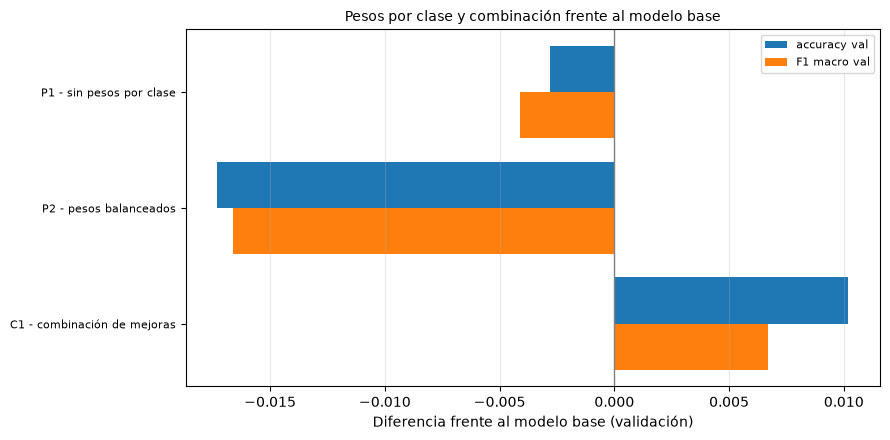

In [47]:
comparacion_datos = tabla_experimentos[
    tabla_experimentos["experimento"].str.match(r"Base|P\d|C\d")
][
    ["experimento", "pesos", "val_accuracy", "val_precision_macro", "val_recall_macro", "val_f1_macro",
     "brecha", "epocas", "segundos"]
].reset_index(drop=True)
fila_base = comparacion_datos["experimento"].str.startswith("Base")
comparacion_datos["delta_accuracy_vs_base"] = (
    comparacion_datos["val_accuracy"] - float(comparacion_datos.loc[fila_base, "val_accuracy"].iloc[0])
).round(4)
comparacion_datos["delta_f1_vs_base"] = (
    comparacion_datos["val_f1_macro"] - float(comparacion_datos.loc[fila_base, "val_f1_macro"].iloc[0])
).round(4)
display(comparacion_datos)

figura, eje = plt.subplots(figsize=(9, 4.5))
otras = comparacion_datos[~fila_base].reset_index(drop=True)
posiciones = np.arange(len(otras))
eje.barh(posiciones - 0.2, otras["delta_accuracy_vs_base"], height=0.4, label="accuracy val")
eje.barh(posiciones + 0.2, otras["delta_f1_vs_base"], height=0.4, label="F1 macro val")
eje.set_yticks(posiciones)
eje.set_yticklabels(otras["experimento"], fontsize=8)
eje.invert_yaxis()
eje.axvline(0, color="gray", linewidth=1)
eje.set_xlabel("Diferencia frente al modelo base (validación)")
eje.set_title("Pesos por clase y combinación frente al modelo base", fontsize=10)
eje.grid(alpha=0.3, axis="x")
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.** Los pesos por clase de la base siguen siendo la mejor opción:

- **Sin pesos (P1)** la accuracy de validación casi no cambia (0,726 frente a 0,729) y el F1 macro baja 0,4
  puntos: los pesos ayudan algo a los personajes con pocas imágenes.
- **Con los balanceados completos (P2)** bajan las dos, 1,7 puntos la accuracy y 1,7 el F1: con un desbalance de
  21:1, compensar del todo castiga a los frecuentes más de lo que ayuda a los escasos. La raíz cuadrada sigue
  siendo el punto medio, como en el MLP.
- **C1** combina los dos cambios que superaron a la base, ambos de regularización (G3 y G4), y sube el F1 0,7
  puntos, menos que G4 solo (ver «Efecto de las técnicas de regularización»).

### Selección del modelo final

In [48]:
import importlib.util
import json

# El criterio de selección es el F1 macro de validación, no la accuracy:
# promedia todas las clases sin ponderar y penaliza ignorar a los personajes minoritarios
ranking = tabla_experimentos.sort_values("val_f1_macro", ascending=False).reset_index(drop=True)
display(
    ranking[
        ["experimento", "filtros", "cabeza", "batchnorm", "dropout", "l2", "aumento_en_linea", "pesos",
         "val_accuracy", "val_precision_macro", "val_recall_macro", "val_f1_macro", "brecha", "val_loss",
         "parametros", "epocas"]
    ]
)

nombre_final = ranking.loc[0, "experimento"]
modelo_final = modelos[nombre_final]
representacion_final = ranking.loc[0, "representacion"]
arquitectura_final = (
    f"{ranking.loc[0, 'filtros']} filtros, {ranking.loc[0, 'convoluciones_por_bloque']} conv. por bloque,"
    f" {ranking.loc[0, 'cabeza']}"
    + ("" if ranking.loc[0, "batchnorm"] else ", sin Batch Normalization")
)

print(f"Configuracion seleccionada: {nombre_final}")
print(f"  entrada             : imagen {ALTO_OBJETIVO}x{ANCHO_OBJETIVO} ({representacion_final})")
print(f"  arquitectura        : {arquitectura_final}")
print(f"  accuracy validacion : {ranking.loc[0, 'val_accuracy']:.4f}")
print(f"  F1 macro validacion : {ranking.loc[0, 'val_f1_macro']:.4f}")
print(f"  brecha train - val  : {ranking.loc[0, 'brecha']:.4f}")
print(f"  parametros          : {ranking.loc[0, 'parametros']:,}")
print(f"\nDiferencia en F1 macro frente a la segunda ({ranking.loc[1, 'experimento']}): {ranking.loc[0, 'val_f1_macro'] - ranking.loc[1, 'val_f1_macro']:+.4f}")

# --- El modelo final, listo para usarse fuera del notebook -----------------------------------------------
# Cuatro archivos con el mismo nombre base. Con ellos, scripts/newDataset/detectar_cajas.py encuentra después a
# cada personaje de una imagen y lo nombra con este modelo, sin volver a ejecutar el notebook. El notebook no
# usa ese script: el modelo se entrena y se evalúa solo con la imagen completa.
NOMBRE_MODELO_FINAL = "cnn_final"
ruta_modelo_final = DIRECTORIO_MODELOS / f"{NOMBRE_MODELO_FINAL}.keras"
ruta_metadatos_final = DIRECTORIO_MODELOS / f"{NOMBRE_MODELO_FINAL}.json"
ruta_entrada_final = DIRECTORIO_MODELOS / f"{NOMBRE_MODELO_FINAL}_entrada.py"
ruta_particion_final = DIRECTORIO_MODELOS / f"{NOMBRE_MODELO_FINAL}_particion.csv"

# 1. La red entrenada
modelo_final.save(ruta_modelo_final)

# 2. Cómo se prepara su entrada. La CNN recibe la imagen RGB redimensionada tal cual: el escalado a [0, 1] y,
#    si el modelo la usa, la conversión a escala de grises van dentro del modelo
codigo_entrada = f'''"""Entrada de {NOMBRE_MODELO_FINAL}.keras: la imagen RGB redimensionada entra tal cual.

Lo generó CNN/notebooks/LosSimpsons_GPU_4060M.ipynb el {datetime.now():%d-%m-%Y %H:%M}. El escalado a [0, 1] y, si
el modelo la usa, la conversión a escala de grises van dentro del modelo. No se edita a mano: se vuelve a generar
al ejecutar el notebook.
"""

import numpy as np

REPRESENTACION = {str(representacion_final)!r}
ALTO, ANCHO = {int(ALTO_OBJETIVO)}, {int(ANCHO_OBJETIVO)}


def preparar(lote):
    """Entrada del modelo para un lote de imágenes RGB (n, ALTO, ANCHO, 3) en uint8, ya redimensionadas con
    interpolación bilineal: la misma imagen, sin aplanar."""
    lote = np.asarray(lote, dtype=np.uint8)
    if lote.ndim != 4 or lote.shape[1:] != (ALTO, ANCHO, 3):
        raise ValueError("Se esperaba un lote (n, %d, %d, 3) y llegó %s" % (ALTO, ANCHO, lote.shape))
    return lote
'''
ruta_entrada_final.write_text(codigo_entrada, encoding="utf-8")

# 3. Comprobación: el archivo generado tiene que dar exactamente la entrada con que se evaluó el modelo
especificacion_entrada = importlib.util.spec_from_file_location(ruta_entrada_final.stem, ruta_entrada_final)
entrada_generada = importlib.util.module_from_spec(especificacion_entrada)
especificacion_entrada.loader.exec_module(entrada_generada)
esperada = np.asarray(imagenes_test[:64])
obtenida = np.asarray(entrada_generada.preparar(imagenes_test[:64]))
diferencia_entrada = (
    float(np.abs(obtenida.astype(np.float64) - esperada.astype(np.float64)).max())
    if obtenida.shape == esperada.shape else float("inf")
)
if diferencia_entrada > 1e-5:
    raise ValueError(
        f"{ruta_entrada_final.name} no reproduce la entrada del modelo (diferencia máxima {diferencia_entrada})"
    )

# 4. A qué conjunto fue cada imagen original: el script de cajas usa por defecto solo las de test, que el
#    modelo no vio al entrenar
(
    datos.loc[~datos["alterada"], ["personaje", "origen", "conjunto"]]
    .rename(columns={"origen": "archivo"})
    .sort_values(["personaje", "archivo"])
    .to_csv(ruta_particion_final, index=False)
)

# 5. Lo que hace falta para repetir el pre-procesamiento sin volver a ejecutar el notebook: la representación,
#    la resolución, el orden de las clases (qué índice de salida es qué personaje) y los otros dos archivos
metadatos_final = {
    "modelo": "cnn",
    "configuracion": str(nombre_final),
    "representacion": str(representacion_final),
    "arquitectura": str(arquitectura_final),
    "normalizacion": bool(ranking.loc[0, "batchnorm"]),
    "entrada": "imagen completa en RGB, redimensionada con interpolación bilineal",
    "alto": int(ALTO_OBJETIVO),
    "ancho": int(ANCHO_OBJETIVO),
    "clases": [str(clase) for clase in clases],
    "preparacion": ruta_entrada_final.name,
    "particion": ruta_particion_final.name,
    "val_accuracy": round(float(ranking.loc[0, "val_accuracy"]), 4),
    "val_f1_macro": round(float(ranking.loc[0, "val_f1_macro"]), 4),
    "notebook": "CNN/notebooks/LosSimpsons_GPU_4060M.ipynb",
    "fecha": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
}
ruta_metadatos_final.write_text(json.dumps(metadatos_final, indent=2, ensure_ascii=False), encoding="utf-8")

display(
    pd.DataFrame(
        [
            (ruta_modelo_final.name, "la red entrenada"),
            (ruta_metadatos_final.name, "clases, resolución y representación de la entrada"),
            (ruta_entrada_final.name, f"preparación de la entrada (comprobada: diferencia {diferencia_entrada:.1e})"),
            (ruta_particion_final.name, "conjunto de cada imagen original"),
        ],
        columns=["Archivo", "Contenido"],
    )
)
print(f"Modelo final y sus archivos en: {DIRECTORIO_MODELOS.resolve()}")
print(
    "Para encontrar y nombrar a cada personaje con su caja, después del notebook y desde la raíz del repositorio:\n"
    "  .venv-gpu\\Scripts\\python.exe scripts\\newDataset\\detectar_cajas.py --modelo cnn ruta\\a\\imagen.jpg"
)


,experimento,filtros,cabeza,batchnorm,dropout,l2,aumento_en_linea,pesos,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,brecha,val_loss,parametros,epocas
0,G4 - aumento de datos en línea,32 - 64 - 128 - 256,pooling_global,True,0.3,0.0000,True,raiz,0.7438,0.7340,0.7250,0.7239,0.0199,1.0049,473120,35
1,C1 - combinación de mejoras,32 - 64 - 128 - 256,pooling_global,True,0.3,0.0005,True,raiz,0.7387,0.7187,0.7206,0.7115,0.0138,1.0406,473120,35
2,G3 - regularización L2 (5e-4),32 - 64 - 128 - 256,pooling_global,True,0.3,0.0005,False,raiz,0.7327,0.7277,0.7053,0.7106,0.1476,1.0484,473120,35
3,"Base - rgb, 4 bloques (32,64,128,256)",32 - 64 - 128 - 256,pooling_global,True,0.3,0.0000,False,raiz,0.7285,0.7167,0.6991,0.7048,0.1981,1.0873,473120,52
4,P1 - sin pesos por clase,32 - 64 - 128 - 256,pooling_global,True,0.3,0.0000,False,ninguno,0.7257,0.7237,0.6900,0.7007,0.1891,1.0738,473120,35
5,S1 - sin suavizado,32 - 64 - 128 - 256,pooling_global,True,0.3,0.0000,False,raiz,0.7202,0.7055,0.7047,0.6984,0.1139,1.0929,473120,35
6,"E6 - dropout 0,5",32 - 64 - 128 - 256,pooling_global,True,0.5,0.0000,False,raiz,0.7203,0.7020,0.6987,0.6970,0.0750,1.1097,473120,35
7,A1 - sin alteradas,32 - 64 - 128 - 256,pooling_global,True,0.3,0.0000,False,raiz,0.7190,0.7083,0.6927,0.6965,0.1753,1.1286,473120,35
8,P2 - pesos balanceados,32 - 64 - 128 - 256,pooling_global,True,0.3,0.0000,False,balanceado,0.7112,0.6959,0.7000,0.6882,0.1314,1.1617,473120,35
9,G2 - sin Batch Normalization,32 - 64 - 128 - 256,pooling_global,False,0.3,0.0000,False,raiz,0.7102,0.6940,0.6879,0.6869,0.0624,1.1674,470656,35


Configuracion seleccionada: G4 - aumento de datos en línea
  entrada             : imagen 128x128 (rgb)
  arquitectura        : 32 - 64 - 128 - 256 filtros, 1 conv. por bloque, pooling_global
  accuracy validacion : 0.7438
  F1 macro validacion : 0.7239
  brecha train - val  : 0.0199
  parametros          : 473,120

Diferencia en F1 macro frente a la segunda (C1 - combinación de mejoras): +0.0124


,Archivo,Contenido
0,cnn_final.keras,la red entrenada
1,cnn_final.json,"clases, resolución y representación de la entrada"
2,cnn_final_entrada.py,preparación de la entrada (comprobada: diferen...
3,cnn_final_particion.csv,conjunto de cada imagen original


Modelo final y sus archivos en: C:\Users\LaptopWin\Desktop\Trabajo\Duoc\3er-Anio\2do Semestre\TECNICAS_ML\Unidad 3\LosSimpsons_DeepLearning\CNN\models_gpu\newDataset
Para encontrar y nombrar a cada personaje con su caja, después del notebook y desde la raíz del repositorio:
  .venv-gpu\Scripts\python.exe scripts\newDataset\detectar_cajas.py --modelo cnn ruta\a\imagen.jpg


**Justificación de la decisión.** La configuración elegida es la que maximiza el **F1 macro de
validación**, y no la que maximiza la accuracy. Validación conserva la distribución real del dataset, con
una razón de desbalance de 21:1: la accuracy premia acertar en los personajes abundantes y apenas se
resiente si el modelo ignora a los escasos; el F1 macro, al promediar los 64 personajes sin ponderarlos,
sí lo penaliza. Como el objetivo declarado es reconocer personajes —los 64, no solo a Homero—, esa es la
métrica coherente con el problema.

En la corrida de GPU a 128 × 128 del 13-11-2026 gana **G4, la CNN base entrenada además con aumento de datos en
línea**: F1 macro de validación de 0,724, frente a 0,712 de C1 y 0,705 de la base. Los tres criterios coinciden:
G4 también tiene la mayor accuracy de validación (0,744) y la menor pérdida (1,005). Su arquitectura es la de la
base —cuatro bloques con una convolución de 3 × 3 cada uno, 473.120 parámetros, poco más de un tercio de los de E2
(1,26 millones)—; solo cambia lo que ve al entrenar. No se combina con L2 porque la combinación (C1) rindió menos.

El margen sobre la base, 1,9 puntos, es del orden de lo que cambió una misma configuración entre las dos corridas
del 13-11-2026 —0,06 puntos la base, pero 1,8 P2 y 1,9 E1—, porque cuDNN no es determinista: confirmarlo exigiría
varias semillas. Dos evidencias más lo respaldan: es coherente con la brecha, que G4 reduce más que ninguna otra
variante, y se confirma en test (sección siguiente).

El modelo seleccionado es el que se evalúa en la sección siguiente sobre el **conjunto de test**, que hasta
este punto no se ha tocado ni para entrenar ni para elegir hiperparámetros.

## Evaluación y métricas de desempeño

El conjunto de evaluación es el **test** reservado en la partición: el 10 % de las imágenes originales de
cada personaje, con la distribución real del dataset y en las mismas condiciones que el entrenamiento: las
imágenes casi idénticas a otra entran con su versión filtrada y un cuarto de las originales viene con su
variante alterada. El modelo nunca vio esas imágenes ni ninguna variante de ellas.

**Criterio de acierto.** Cada imagen de test entra completa, y una predicción es correcta solo si nombra al
personaje de su carpeta. Con ese criterio se calculan la accuracy, el top-3, el F1, el reporte por clase, la
matriz de confusión y los KPIs. Como referencia se informa la accuracy por escena, que también acepta a otro
personaje presente según la escena y las gemelas (sección «Escenas con varios personajes»). Las galerías usan
tres colores: verde si el modelo nombra al personaje de la carpeta, ámbar si se equivoca nombrando a otro
personaje de la escena y rojo en los demás errores.

Ya está cargado y procesado con **exactamente las mismas funciones** que el entrenamiento —el mismo
redimensionado a 128 x 128 y el mismo diccionario `clase_a_indice`—, porque las tres particiones salieron
del mismo índice. La celda siguiente comprueba que las imágenes de test son coherentes con las del
entrenamiento.

In [49]:
# El test sale de la partición: las mismas imágenes de alto x ancho x 3 que entrenamiento y
# validación. La escala de grises, si el modelo final la usa, va dentro del modelo.
print(f"Modelo final: {nombre_final}   |   entrada: {representacion_final}")

X_test = PARTICION["test"]

# Cada alterada de test acompaña a su original, que también está en test
originales_test = set(
    zip(datos_test.loc[~datos_test["alterada"], "personaje"], datos_test.loc[~datos_test["alterada"], "origen"])
)
alteradas_test = datos_test[datos_test["alterada"]]
alteradas_test_con_original = sum(
    (personaje, origen) in originales_test
    for personaje, origen in zip(alteradas_test["personaje"], alteradas_test["origen"])
)

comprobaciones_test = pd.DataFrame(
    [
        (
            "Todas las clases presentes",
            len(np.unique(y_test_idx)),
            NUMERO_CLASES,
            len(np.unique(y_test_idx)) == NUMERO_CLASES,
        ),
        (
            "Forma de las imágenes de test",
            str(X_test.shape[1:]),
            str(FORMA_ENTRADA),
            X_test.shape[1:] == FORMA_ENTRADA,
        ),
        (
            "Alteradas de test con su original en test",
            alteradas_test_con_original,
            len(alteradas_test),
            alteradas_test_con_original == len(alteradas_test),
        ),
        ("Etiquetas alineadas", len(y_test_idx), X_test.shape[0], len(y_test_idx) == X_test.shape[0]),
        ("Imágenes alineadas", len(imagenes_test), X_test.shape[0], len(imagenes_test) == X_test.shape[0]),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_test)

if not comprobaciones_test["Correcto"].all():
    raise ValueError("El conjunto de test no cumple alguna de las comprobaciones.")

print(f"Conjunto de test: {len(datos_test)} imagenes")
print(f"X_test: {X_test.shape}   y_test: {y_test.shape}")

# A la VRAM, como el resto
X_test = a_gpu(X_test)
y_test = a_gpu(y_test)
print(f"X_test en {X_test.device}  |  VRAM total ocupada: "
      f"{torch.cuda.memory_allocated() / 1024 ** 3:.2f} GB")

Modelo final: G4 - aumento de datos en línea   |   entrada: rgb


,Comprobacion,Obtenido,Esperado,Correcto
0,Todas las clases presentes,64,64,True
1,Forma de las imágenes de test,"(128, 128, 3)","(128, 128, 3)",True
2,Alteradas de test con su original en test,1390,1390,True
3,Etiquetas alineadas,7058,7058,True
4,Imágenes alineadas,7058,7058,True


Conjunto de test: 7058 imagenes
X_test: (7058, 128, 128, 3)   y_test: (7058, 64)
X_test en cuda:0  |  VRAM total ocupada: 3.37 GB


### Predicciones sobre las imágenes de test

El modelo final nombra el personaje de cada imagen de test. El criterio es uno solo: la predicción acierta si
nombra al personaje de la carpeta. La escena del episodio (±3 s) y las gemelas no cambian el acierto; quedan
para la accuracy por escena, de referencia.


In [50]:
# Predicciones del modelo final sobre las imágenes de test
probabilidades_test = modelo_final.predict(X_test, batch_size=256, verbose=0)
predicciones_test = probabilidades_test.argmax(axis=1)
confianza_test = probabilidades_test.max(axis=1)
# Personajes de la escena (±3 s y gemelas): no cambian el acierto, solo la accuracy por escena de referencia
acompanantes_test = [set(texto.split(", ")) if texto else set() for texto in datos_test["escena"]]

# Colores de las galerías de evaluación y de análisis de errores
COLOR_ACIERTO, COLOR_ESCENA, COLOR_ERROR = "#1b7f3b", "#d68910", "#c0392b"
TEXTO_RESULTADO = {
    COLOR_ACIERTO: "correcto",
    COLOR_ESCENA: "error: otro personaje de la escena",
    COLOR_ERROR: "incorrecto",
}

print(f"Imágenes de test: {len(predicciones_test)}   |   confianza media: {confianza_test.mean():.3f}")

Imágenes de test: 7058   |   confianza media: 0.662


### Accuracy global sobre el conjunto de prueba

In [51]:
perdida_test, accuracy_estricta_test, top3_estricto_test = modelo_final.evaluate(
    X_test, y_test, batch_size=256, verbose=0
)

# Criterio de acierto: la predicción es correcta si nombra al personaje de la carpeta, que es la etiqueta
# con la que se evalúa
acierto_estricto = predicciones_test == y_test_idx
acierto_test = acierto_estricto
y_test_eval = y_test_idx
accuracy_test = float(acierto_test.mean())
top3_por_imagen = (np.argsort(-probabilidades_test, axis=1)[:, :3] == y_test_idx[:, None]).any(axis=1)
top3_test = float(top3_por_imagen.mean())

# Referencia por escena: además acepta a otro personaje presente según la escena (±3 s) y las gemelas, que
# con la imagen completa también sale en el encuadre. No cambia el acierto
acierto_por_escena = np.array(
    [clases[predicho] in presentes for predicho, presentes in zip(predicciones_test, acompanantes_test)]
)
accuracy_por_escena_test = float((acierto_test | acierto_por_escena).mean())


def color_resultado(indice):
    """Verde si el modelo nombró al personaje de la carpeta, ámbar si se equivocó nombrando a otro personaje
    de la escena y rojo en los demás errores."""
    if acierto_estricto[indice]:
        return COLOR_ACIERTO
    return COLOR_ESCENA if acierto_por_escena[indice] else COLOR_ERROR


def rotulo_escena(indice):
    """Rótulo de un error que nombra a otro personaje de la escena."""
    return "error: otro personaje de la escena"


# Baselines definidos en "Definición del problema de clasificación"
conteos_test = np.bincount(y_test_idx, minlength=NUMERO_CLASES)
baseline_azar = 1 / NUMERO_CLASES
baseline_mayoritaria = conteos_test.max() / conteos_test.sum()
f1_macro_test = f1_score(y_test_idx, predicciones_test, average="macro")
f1_ponderado_test = f1_score(y_test_idx, predicciones_test, average="weighted")
f1_macro_estricto_test = f1_macro_test

comparacion_baselines = pd.DataFrame(
    [
        ("Clasificador aleatorio", baseline_azar, "-"),
        ("Clase mayoritaria siempre", baseline_mayoritaria, "-"),
        ("CNN final", accuracy_test, round(float(f1_macro_test), 4)),
    ],
    columns=["Modelo", "Accuracy test", "F1 macro test"],
)
comparacion_baselines["Accuracy test"] = comparacion_baselines["Accuracy test"].round(4)

display(comparacion_baselines)

print(f"Perdida en test      : {perdida_test:.4f}")
print(f"Accuracy en test     : {accuracy_test:.4f}   (nombra al personaje de la carpeta)")
print(f"Top-3 accuracy       : {top3_test:.4f}")
print(f"F1 macro en test     : {f1_macro_test:.4f}")
print(f"F1 ponderado en test : {f1_ponderado_test:.4f}")
print(f"Referencia           : accuracy por escena {accuracy_por_escena_test:.4f}")
print(
    f"\nMejora sobre el azar: x{accuracy_test / baseline_azar:.1f}   |   "
    f"sobre la clase mayoritaria: x{accuracy_test / baseline_mayoritaria:.1f}"
)

,Modelo,Accuracy test,F1 macro test
0,Clasificador aleatorio,0.0156,-
1,Clase mayoritaria siempre,0.0554,-
2,CNN final,0.7470,0.7305


Perdida en test      : 0.9980
Accuracy en test     : 0.7470   (nombra al personaje de la carpeta)
Top-3 accuracy       : 0.8913
F1 macro en test     : 0.7305
F1 ponderado en test : 0.7469
Referencia           : accuracy por escena 0.8237

Mejora sobre el azar: x47.8   |   sobre la clase mayoritaria: x13.5


### Precision, Recall y F1-Score por clase

In [52]:
from sklearn.metrics import classification_report, precision_recall_fscore_support

# Con el criterio de acierto: la clase evaluada es la de la carpeta, o el personaje presente
# que nombró el modelo
reporte = classification_report(
    y_test_eval,
    predicciones_test,
    labels=range(NUMERO_CLASES),
    target_names=clases,
    digits=3,
    zero_division=0,
)
print(reporte)

precision, recall, f1, soporte = precision_recall_fscore_support(
    y_test_eval, predicciones_test, labels=range(NUMERO_CLASES), zero_division=0
)

metricas_por_clase = pd.DataFrame(
    {
        "personaje": clases,
        "n_test": soporte,
        "n_train": conteos_train,
        "precision": precision.round(3),
        "recall": recall.round(3),
        "f1": f1.round(3),
    }
).sort_values("f1", ascending=False, ignore_index=True)

display(metricas_por_clase)

correlacion = float(np.corrcoef(conteos_train, f1)[0, 1])
print(f"Correlacion entre imagenes de entrenamiento y F1 por clase: {correlacion:.3f}")

                             precision    recall  f1-score   support

     abraham_grampa_simpson      0.918     0.842     0.878       133
              agnes_skinner      0.881     0.797     0.837        74
     apu_nahasapeemapetilon      0.932     0.723     0.814        94
              barney_gumble      0.603     0.733     0.662       120
               bart_simpson      0.717     0.711     0.714       239
captain_horatio_mccallister      0.723     0.829     0.773        41
               carl_carlson      0.665     0.850     0.746       133
   charles_montgomery_burns      0.927     0.792     0.854       192
               chief_wiggum      0.859     0.692     0.766       185
            cletus_spuckler      0.671     0.803     0.731        71
             comic_book_guy      0.912     0.832     0.870       125
                  disco_stu      0.885     0.958     0.920        24
             dolph_starbeam      0.435     0.536     0.480        56
          dr_julius_hibbert      

,personaje,n_test,n_train,precision,recall,f1
0,krusty_the_clown,157,1201,0.893,0.962,0.926
1,disco_stu,24,159,0.885,0.958,0.920
2,kent_brockman,118,828,0.938,0.890,0.913
3,milhouse_van_houten,157,1093,0.932,0.873,0.901
4,groundskeeper_willie,84,605,0.867,0.929,0.897
...,...,...,...,...,...,...
59,helen_lovejoy,70,527,0.476,0.429,0.451
60,jimbo_jones,88,637,0.396,0.500,0.442
61,kearney_zzyzwicz,71,463,0.491,0.394,0.438
62,maude_flanders,79,564,0.388,0.418,0.402


Correlacion entre imagenes de entrenamiento y F1 por clase: 0.208


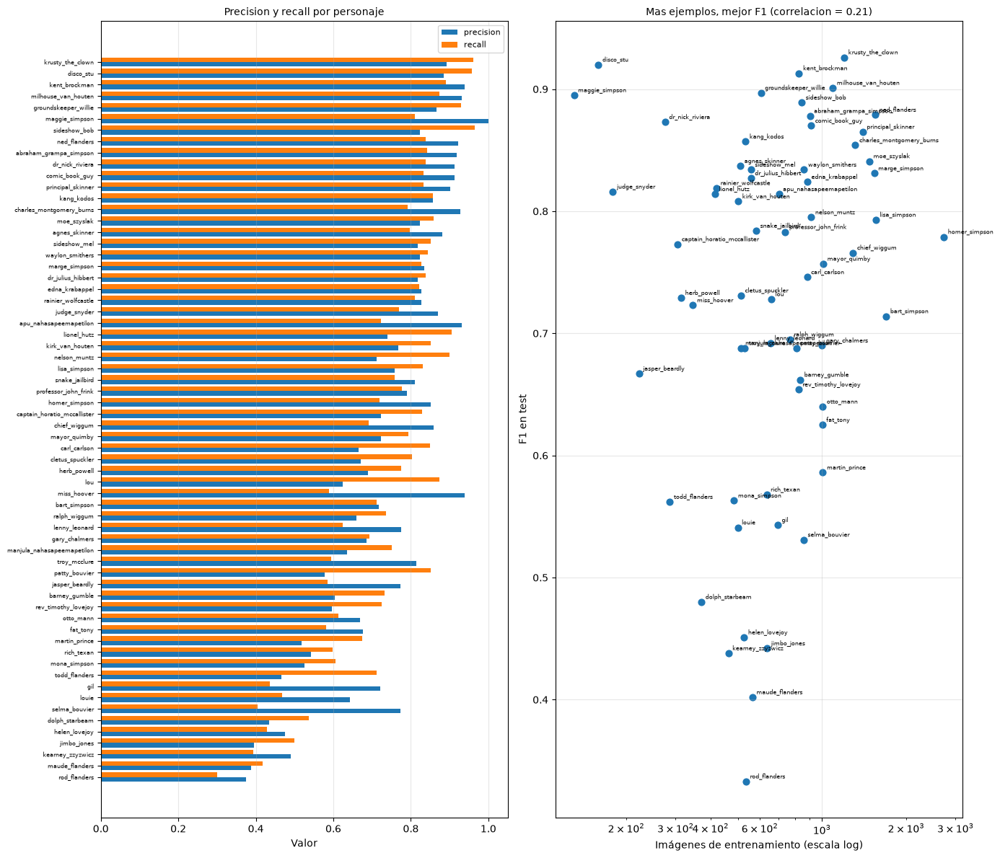

In [53]:
# Relación entre la cantidad de ejemplos de entrenamiento y el F1 alcanzado por cada clase
figura, ejes = plt.subplots(1, 2, figsize=(14, 12))

orden_f1 = metricas_por_clase.sort_values("f1")
posiciones = np.arange(len(orden_f1))
ejes[0].barh(posiciones - 0.2, orden_f1["precision"], height=0.4, label="precision")
ejes[0].barh(posiciones + 0.2, orden_f1["recall"], height=0.4, label="recall")
ejes[0].set_yticks(posiciones)
ejes[0].set_yticklabels(orden_f1["personaje"], fontsize=6)
ejes[0].set_xlabel("Valor")
ejes[0].set_title("Precision y recall por personaje", fontsize=10)
ejes[0].legend(fontsize=8)
ejes[0].grid(alpha=0.3, axis="x")

ejes[1].scatter(metricas_por_clase["n_train"], metricas_por_clase["f1"], s=40)
for _, fila in metricas_por_clase.iterrows():
    ejes[1].annotate(
        fila["personaje"],
        (fila["n_train"], fila["f1"]),
        textcoords="offset points",
        xytext=(4, 3),
        fontsize=6,
    )
ejes[1].set_xscale("log")
ejes[1].set_xlabel("Imágenes de entrenamiento (escala log)")
ejes[1].set_ylabel("F1 en test")
ejes[1].set_title(f"Mas ejemplos, mejor F1 (correlacion = {correlacion:.2f})", fontsize=10)
ejes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Lectura.** La CNN reconoce bien a la mayoría de los personajes: 51 de los 64 tienen un F1 de 0,60 o más, y
ninguno queda por debajo de 0,30. Los mejores son Krusty (0,93), Disco Stu (0,92), Kent Brockman (0,91), Milhouse
(0,90) y Willie (0,90). La familia Simpson, que el MLP confundía por la piel amarilla compartida, queda en la parte
media y alta: Marge 0,83, Lisa 0,79, Homero 0,78 y Bart 0,71, que pierde sobre todo hacia Martin Prince (el 5,0 %
de sus imágenes).

Los cinco peores son Rod Flanders (0,33), Maude Flanders (0,40), Kearney (0,44), Jimbo (0,44) y Helen Lovejoy
(0,45), y no son los que tienen menos imágenes: tienen entre 463 y 637 de entrenamiento, mientras que Maggie, con
130, y Disco Stu, con 159, llegan a 0,90 y 0,92. La correlación entre imágenes de entrenamiento y F1 es de solo
0,21. Lo que comparten los peores es que se parecen a otro personaje o salen casi siempre con él: Rod se confunde
con su hermano Todd, y Jimbo, Kearney y Dolph entre sí; Helen tiene una precisión de 0,48 y un recall de 0,43. Patty
muestra el otro lado del mismo problema: recall de 0,85 y precisión de 0,58, porque el modelo le asigna casi la
mitad de las imágenes de su gemela Selma (ver «Confusiones más frecuentes y posibles causas»).

### Matriz de confusión

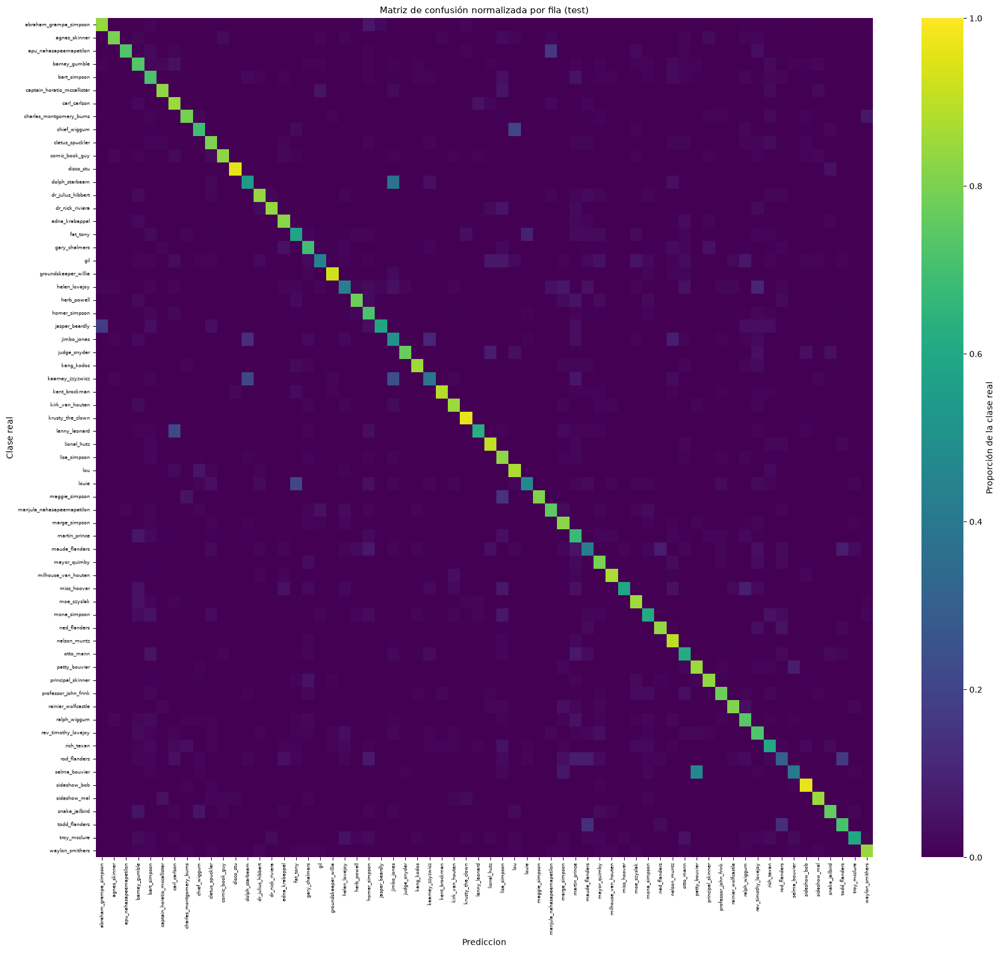

Recall medio (diagonal): 0.734
Clase mejor reconocida : sideshow_bob (0.964)
Clase peor reconocida  : rod_flanders (0.300)


In [54]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Filas: la clase evaluada (la de la carpeta, o el personaje presente que nombró el modelo)
matriz = confusion_matrix(y_test_eval, predicciones_test, labels=range(NUMERO_CLASES))
# Normalizada por fila: cada fila suma 1, de modo que el desbalance no distorsione la lectura
totales_fila = matriz.sum(axis=1, keepdims=True)
matriz_normalizada = np.divide(matriz, totales_fila, out=np.zeros(matriz.shape), where=totales_fila > 0)

figura, eje = plt.subplots(figsize=(18, 16))
sns.heatmap(
    matriz_normalizada,
    annot=False,
    cmap="viridis",
    vmin=0,
    vmax=1,
    xticklabels=clases,
    yticklabels=clases,
    cbar_kws={"label": "Proporción de la clase real"},
    ax=eje,
)
eje.set_xlabel("Prediccion")
eje.set_ylabel("Clase real")
eje.set_title("Matriz de confusión normalizada por fila (test)", fontsize=11)
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.show()

aciertos_diagonal = np.diag(matriz_normalizada)
print(f"Recall medio (diagonal): {aciertos_diagonal.mean():.3f}")
print(f"Clase mejor reconocida : {clases[int(aciertos_diagonal.argmax())]} ({aciertos_diagonal.max():.3f})")
print(f"Clase peor reconocida  : {clases[int(aciertos_diagonal.argmin())]} ({aciertos_diagonal.min():.3f})")

### Curvas ROC y ROC-AUC

La matriz de confusión mira solo la clase ganadora. La curva ROC mira toda la probabilidad: para cada personaje,
recorre todos los umbrales posibles sobre la probabilidad que el modelo le asigna y compara la tasa de verdaderos
positivos con la de falsos positivos. El área bajo la curva (ROC-AUC) resume cuánto separa el modelo las imágenes de
ese personaje de todas las demás: 0,5 es el azar y 1, una separación perfecta.

Con 64 clases se calcula uno contra el resto y se promedia de tres formas: macro (cada personaje pesa igual),
ponderada (por el número de imágenes de test de cada personaje) y micro (todas las decisiones juntas). Es una métrica
complementaria: no depende de quedarse con la clase más probable, así que un personaje puede tener un ROC-AUC alto y un
F1 bajo si el modelo suele dejarlo en segundo lugar.


,personaje,n_test,roc_auc,f1
0,maggie_simpson,21,1.0000,0.895
1,disco_stu,24,0.9998,0.920
2,sideshow_bob,112,0.9995,0.889
3,dr_nick_riviera,37,0.9992,0.873
4,judge_snyder,26,0.9990,0.816
59,otto_mann,142,0.9563,0.640
60,martin_prince,141,0.9553,0.586
61,rod_flanders,80,0.9519,0.333
62,louie,77,0.9483,0.541
63,helen_lovejoy,70,0.9270,0.451


ROC-AUC macro     : 0.9860
ROC-AUC ponderado : 0.9851
ROC-AUC micro     : 0.9878
Personajes con ROC-AUC < 0,90: 0 de 64
Correlación entre el ROC-AUC y el F1 de cada personaje: 0.643


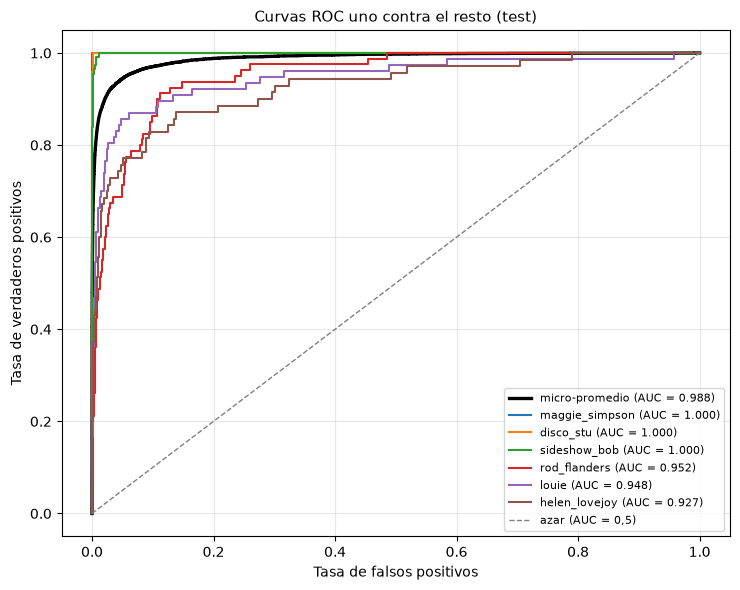

In [55]:
from sklearn.metrics import roc_auc_score, roc_curve

# ROC-AUC uno contra el resto, con la etiqueta de la carpeta en formato binario (una columna por personaje)
y_test_binario = np.eye(NUMERO_CLASES)[y_test_idx]
auc_por_clase = roc_auc_score(y_test_binario, probabilidades_test, average=None)
roc_auc_macro_test = float(np.mean(auc_por_clase))
roc_auc_ponderado_test = float(roc_auc_score(y_test_binario, probabilidades_test, average="weighted"))
roc_auc_micro_test = float(roc_auc_score(y_test_binario, probabilidades_test, average="micro"))

tabla_auc = pd.DataFrame(
    {"personaje": clases, "n_test": conteos_test, "roc_auc": auc_por_clase.round(4), "f1": f1.round(3)}
).sort_values("roc_auc", ascending=False, ignore_index=True)
display(pd.concat([tabla_auc.head(5), tabla_auc.tail(5)]))

print(f"ROC-AUC macro     : {roc_auc_macro_test:.4f}")
print(f"ROC-AUC ponderado : {roc_auc_ponderado_test:.4f}")
print(f"ROC-AUC micro     : {roc_auc_micro_test:.4f}")
print(f"Personajes con ROC-AUC < 0,90: {int((auc_por_clase < 0.90).sum())} de {NUMERO_CLASES}")
print(f"Correlación entre el ROC-AUC y el F1 de cada personaje: {np.corrcoef(auc_por_clase, f1)[0, 1]:.3f}")

# Curva micro-promedio y las de los tres personajes con mayor y menor ROC-AUC
figura, eje = plt.subplots(figsize=(7.5, 6))
tasa_fp, tasa_vp, _ = roc_curve(y_test_binario.ravel(), probabilidades_test.ravel())
eje.plot(tasa_fp, tasa_vp, color="black", linewidth=2.4, label=f"micro-promedio (AUC = {roc_auc_micro_test:.3f})")
for personaje in [*tabla_auc["personaje"].head(3), *tabla_auc["personaje"].tail(3)]:
    indice = clase_a_indice[personaje]
    tasa_fp, tasa_vp, _ = roc_curve(y_test_binario[:, indice], probabilidades_test[:, indice])
    eje.plot(tasa_fp, tasa_vp, linewidth=1.5, label=f"{personaje} (AUC = {auc_por_clase[indice]:.3f})")
eje.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="azar (AUC = 0,5)")
eje.set_xlabel("Tasa de falsos positivos")
eje.set_ylabel("Tasa de verdaderos positivos")
eje.set_title("Curvas ROC uno contra el resto (test)", fontsize=11)
eje.grid(alpha=0.3)
eje.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()


**Lectura.** La ROC-AUC es alta en los 64 personajes: 0,986 de media macro, 0,985 ponderada y 0,988 micro, y
ninguno queda por debajo de 0,90. Los que mejor separa son Maggie (1,000), Disco Stu, Sideshow Bob, el doctor Nick y
el juez Snyder (0,999); los que peor, Helen Lovejoy (0,927), Louie (0,948), Rod Flanders (0,952), Martin Prince y
Otto (0,96).

La distancia con el F1 dice dónde está el problema. Rod tiene una ROC-AUC de 0,95 y un F1 de 0,33: el modelo da a
sus imágenes más probabilidad de ser Rod que a casi todas las demás, pero casi nunca la mayor, porque Todd, que se
le parece, queda por delante. La correlación entre la ROC-AUC y el F1 de cada personaje es de 0,64: los dos miran
lo mismo, pero la ROC-AUC no castiga quedar segundo. Es la misma lectura que la top-3 (0,891): el modelo casi
siempre tiene al personaje entre sus candidatos, y lo que falla es desempatar entre personajes parecidos o que
comparten escena.

### Interpretación crítica de las métricas

In [56]:
# Comparación de las tres lecturas globales y su distancia
resumen_metricas = pd.DataFrame(
    [
        ("Accuracy (test)", round(float(accuracy_test), 4), "Imágenes en que nombra al personaje de la carpeta; domina por las clases grandes"),
        ("Accuracy por escena (test)", round(float(accuracy_por_escena_test), 4), "También acepta a otro personaje presente, como con la imagen completa; referencia"),
        ("F1 ponderado (test)", round(float(f1_ponderado_test), 4), "Promedio de F1 pesado por el tamaño de cada clase"),
        ("F1 macro (test)", round(float(f1_macro_test), 4), "Promedio simple de todas las clases; cada personaje pesa igual"),
        ("Top-3 accuracy (test)", round(float(top3_test), 4), "El personaje de la carpeta está entre las 3 más probables"),
        ("ROC-AUC macro (test)", round(float(roc_auc_macro_test), 4), "Cuánto separa la probabilidad de cada personaje sus imágenes de las demás; 0,5 = azar"),
    ],
    columns=["Metrica", "Valor", "Que mide"],
)
display(resumen_metricas)

brecha_metricas = float(accuracy_test) - float(f1_macro_test)

# Clases que el modelo prácticamente no reconoce
clases_debiles = metricas_por_clase[metricas_por_clase["f1"] < 0.30]
clases_fuertes = metricas_por_clase[metricas_por_clase["f1"] >= 0.60]

print(f"Brecha accuracy - F1 macro: {brecha_metricas:.3f}")
print(f"Clases con F1 >= 0.60 : {len(clases_fuertes)} de {NUMERO_CLASES}")
print(f"Clases con F1 <  0.30 : {len(clases_debiles)} de {NUMERO_CLASES}")
if len(clases_debiles):
    print("  " + ", ".join(clases_debiles["personaje"].tolist()))
print(
    f"\nMediana de imagenes de entrenamiento en las clases fuertes: "
    f"{clases_fuertes['n_train'].median():.0f}"
)
if len(clases_debiles):
    print(
        f"Mediana de imagenes de entrenamiento en las clases debiles : "
        f"{clases_debiles['n_train'].median():.0f}"
    )

,Metrica,Valor,Que mide
0,Accuracy (test),0.7470,Imágenes en que nombra al personaje de la carp...
1,Accuracy por escena (test),0.8237,"También acepta a otro personaje presente, como..."
2,F1 ponderado (test),0.7469,Promedio de F1 pesado por el tamaño de cada clase
3,F1 macro (test),0.7305,Promedio simple de todas las clases; cada pers...
4,Top-3 accuracy (test),0.8913,El personaje de la carpeta está entre las 3 má...
5,ROC-AUC macro (test),0.9860,Cuánto separa la probabilidad de cada personaj...


Brecha accuracy - F1 macro: 0.016
Clases con F1 >= 0.60 : 51 de 64
Clases con F1 <  0.30 : 0 de 64

Mediana de imagenes de entrenamiento en las clases fuertes: 809


**Qué revela la distancia entre las métricas.** La accuracy (0,747) y el F1 macro (0,731) quedan a 1,6 puntos, y
el F1 ponderado (0,747) coincide con la accuracy: el desempeño está repartido de forma pareja entre personajes
grandes y pequeños. En la corrida del 19-10-2026, con el mismo criterio, la distancia era de 5,9 puntos: con el
dataset ampliado, los personajes con menos imágenes ya no son los que más fallan.

Todas estas métricas usan el criterio de la carpeta. La accuracy por escena, que también acepta a otro personaje
presente, sube a 0,824: son las 542 imágenes en las que el modelo nombró a otro personaje que sí está en la escena
(sección «Escenas con varios personajes: errores que nombran a otro personaje»).

La **top-3 accuracy** llega a 0,891: en el 57 % de los errores el personaje correcto está entre las tres candidatas
más probables. En el escenario de asistencia, el catalogador encuentra la respuesta entre las tres sugerencias en
casi nueve de cada diez imágenes. La **ROC-AUC macro** (0,986, ver «Curvas ROC y ROC-AUC») dice lo mismo desde la
probabilidad: aunque no quede primero, el personaje correcto casi siempre recibe más probabilidad que los demás.

### Tolerancia por escena (referencia)

Las métricas anteriores usan el criterio de la carpeta: la única respuesta correcta es el personaje de la
carpeta. Con la imagen completa el fotograma suele mostrar a varios personajes, y nombrar a otro que está
presente cuenta como error. La celda siguiente calcula las mismas métricas aceptando también a cualquier
personaje presente en la escena, solo como referencia, y muestra qué personajes cambian más de un criterio al
otro.


In [57]:
# Las mismas métricas con la tolerancia por escena (referencia)
y_test_escena = np.where(acierto_por_escena & ~acierto_estricto, predicciones_test, y_test_idx)


def promedios_criterio(y_real):
    """Accuracy y promedios macro y ponderado de precision, recall y F1 frente a la etiqueta indicada."""
    valores = {"Accuracy": float((predicciones_test == y_real).mean())}
    for promedio, sufijo_femenino, sufijo_masculino in (
        ("macro", "macro", "macro"),
        ("weighted", "ponderada", "ponderado"),
    ):
        p, r, f, _ = precision_recall_fscore_support(
            y_real, predicciones_test, labels=range(NUMERO_CLASES), average=promedio, zero_division=0
        )
        valores[f"Precision {sufijo_femenino}"] = float(p)
        valores[f"Recall {sufijo_masculino}"] = float(r)
        valores[f"F1 {sufijo_masculino}"] = float(f)
    return valores


resumen_criterios = pd.DataFrame(
    {
        "Criterio de la carpeta": promedios_criterio(y_test_idx),
        "Tolerancia por escena (referencia)": promedios_criterio(y_test_escena),
    }
)
resumen_criterios["Diferencia (puntos)"] = (
    (resumen_criterios["Tolerancia por escena (referencia)"] - resumen_criterios["Criterio de la carpeta"]) * 100
).round(1)
display(resumen_criterios.round(4))

# Personajes cuyo F1 más cambia con la tolerancia: los que suelen compartir el plano con otro
_, recall_carpeta, f1_carpeta, _ = precision_recall_fscore_support(
    y_test_idx, predicciones_test, labels=range(NUMERO_CLASES), zero_division=0
)
_, recall_escena, f1_escena, _ = precision_recall_fscore_support(
    y_test_escena, predicciones_test, labels=range(NUMERO_CLASES), zero_division=0
)
cambios_por_clase = pd.DataFrame(
    {
        "personaje": clases,
        "n_test": conteos_test,
        "recall_carpeta": recall_carpeta.round(3),
        "recall_escena": recall_escena.round(3),
        "f1_carpeta": f1_carpeta.round(3),
        "f1_escena": f1_escena.round(3),
    }
)
cambios_por_clase["diferencia_f1"] = (f1_escena - f1_carpeta).round(3)
display(cambios_por_clase.sort_values("diferencia_f1", ascending=False).head(10).reset_index(drop=True))
print(f"Clases con F1 >= 0.60: {int((f1_carpeta >= 0.60).sum())} de {NUMERO_CLASES}"
      f"   |   con F1 < 0.30: {int((f1_carpeta < 0.30).sum())}")

,Criterio de la carpeta,Tolerancia por escena (referencia),Diferencia (puntos)
Accuracy,0.7470,0.8237,7.7
Precision macro,0.7406,0.8264,8.6
Recall macro,0.7340,0.8126,7.9
F1 macro,0.7305,0.8160,8.6
Precision ponderada,0.7588,0.8278,6.9
Recall ponderado,0.7470,0.8237,7.7
F1 ponderado,0.7469,0.8231,7.6


,personaje,n_test,recall_carpeta,recall_escena,f1_carpeta,f1_escena,diferencia_f1
0,dolph_starbeam,56,0.536,0.821,0.480,0.809,0.329
1,kearney_zzyzwicz,71,0.394,0.694,0.438,0.723,0.285
2,todd_flanders,38,0.711,0.956,0.562,0.835,0.272
3,jimbo_jones,88,0.500,0.774,0.442,0.706,0.264
4,rod_flanders,80,0.300,0.525,0.333,0.583,0.250
5,jasper_beardly,29,0.586,0.759,0.667,0.863,0.196
6,louie,77,0.468,0.653,0.541,0.734,0.193
7,lou,95,0.874,0.917,0.728,0.917,0.189
8,helen_lovejoy,70,0.429,0.615,0.451,0.625,0.174
9,patty_bouvier,114,0.851,0.907,0.688,0.859,0.171


Clases con F1 >= 0.60: 51 de 64   |   con F1 < 0.30: 0


**Lectura.** La tabla mide cuánto subirían las métricas si nombrar a otro personaje de la escena contara como
acierto: 7,7 puntos la accuracy (de 0,747 a 0,824) y 8,6 el F1 macro (de 0,731 a 0,816). La diferencia son los
errores que nombran al otro personaje del plano, que la imagen completa también muestra. Los personajes que
encabezan la segunda tabla son los que más la aprovechan, y son casi los mismos que peor F1 tienen: Dolph, Kearney
y Jimbo, que salen juntos; Todd y Rod Flanders, y Louie, que sale con Fat Tony. Con la tolerancia, Dolph pasaría de
0,48 a 0,81 de F1, Todd de 0,56 a 0,84 y Jimbo de 0,44 a 0,71. Nombrar a cada uno en su propia caja es lo que hace
después el script de cajas.

### Cumplimiento de los KPIs definidos

Los cinco KPIs declarados al inicio se contrastan aqui con las cifras de la prueba
final. El umbral de cada uno se fijo antes de entrenar, de modo que la tabla es una
verificacion y no una justificacion a posteriori del resultado obtenido.

In [58]:
# Verificacion de los KPIs definidos al inicio del notebook: cada umbral se fijo
# antes de evaluar, y aqui se contrasta con las cifras obtenidas en la prueba final.
import time

# Costo de catalogación de extremo a extremo: llevar las imágenes ya redimensionadas al
# dispositivo y pasarlas por la red. La CNN no calcula descriptores: su entrada son los píxeles.
# La lectura del disco no se incluye, igual que en el MLP.
inicio_inferencia = time.perf_counter()
entrada_inferencia = a_gpu(imagenes_test)
modelo_final.predict(entrada_inferencia, batch_size=256, verbose=0)
segundos_inferencia = time.perf_counter() - inicio_inferencia
imagenes_por_segundo = len(imagenes_test) / segundos_inferencia

ventaja_mayoritaria = float(accuracy_test) / baseline_mayoritaria

kpis = [
    ("Cobertura de asistencia", "Top-3 accuracy", 0.70, float(top3_test), "{:.4f}"),
    ("Equidad entre personajes", "F1 macro", 0.45, float(f1_macro_test), "{:.4f}"),
    ("Automatizacion sin revision", "Accuracy", 0.50, float(accuracy_test), "{:.4f}"),
    ("Ventaja sobre criterio trivial", "Accuracy / mayoritaria", 4.0, ventaja_mayoritaria, "x{:.1f}"),
    ("Costo de catalogacion", "Imagenes por segundo (entrada + red)", 1000.0, imagenes_por_segundo, "{:,.0f}"),
]

tabla_kpis = pd.DataFrame(
    [
        {
            "KPI": nombre,
            "Metrica": metrica,
            "Umbral": formato.format(umbral),
            "Obtenido": formato.format(obtenido),
            "Cumple": "SI" if obtenido >= umbral else "NO",
        }
        for nombre, metrica, umbral, obtenido, formato in kpis
    ]
)

cumplidos = sum(1 for _, _, umbral, obtenido, _ in kpis if obtenido >= umbral)
print(f"KPIs cumplidos: {cumplidos} de {len(kpis)}\n")
display(tabla_kpis)

KPIs cumplidos: 5 de 5



,KPI,Metrica,Umbral,Obtenido,Cumple
0,Cobertura de asistencia,Top-3 accuracy,0.7000,0.8913,SI
1,Equidad entre personajes,F1 macro,0.4500,0.7305,SI
2,Automatizacion sin revision,Accuracy,0.5000,0.7470,SI
3,Ventaja sobre criterio trivial,Accuracy / mayoritaria,x4.0,x13.5,SI
4,Costo de catalogacion,Imagenes por segundo (entrada + red),"1,000","2,649",SI


## Análisis de resultados y de errores

### El modelo en acción sobre el conjunto de test

Las métricas anteriores resumen miles de decisiones en cuatro números. Esta sección hace lo contrario:
toma imágenes concretas del conjunto de test —las que el modelo nunca vio— y muestra el proceso completo,
desde la imagen de entrada hasta la distribución de probabilidad de salida.

El primer gráfico recorre una imagen a través de la red **ya entrenada**. En los fundamentos se aplicaron a
mano tres filtros elegidos por nosotros; aquí se ven los mapas de activación que producen los filtros que la
red aprendió, bloque por bloque: los del primer bloque responden a bordes y manchas de color en posiciones
precisas, y los del último, con mucha menos resolución, a zonas grandes de la imagen.

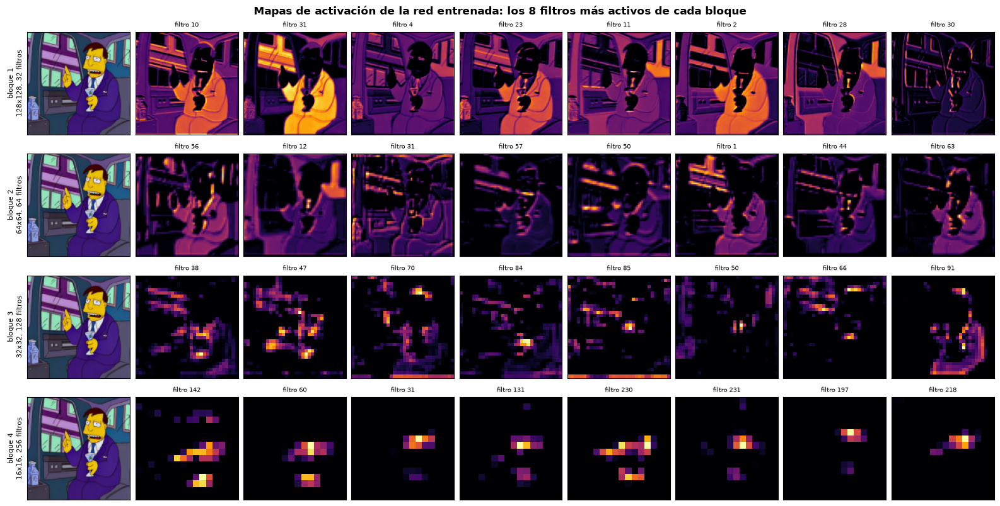

,bloque,capa,mapa,filtros,valores_activos_%,filtros_que_se_activan_%
0,1,activacion_1,128x128,32,47.2,100.0
1,2,activacion_2,64x64,64,24.4,100.0
2,3,activacion_3,32x32,128,9.2,100.0
3,4,activacion_4,16x16,256,1.7,64.5


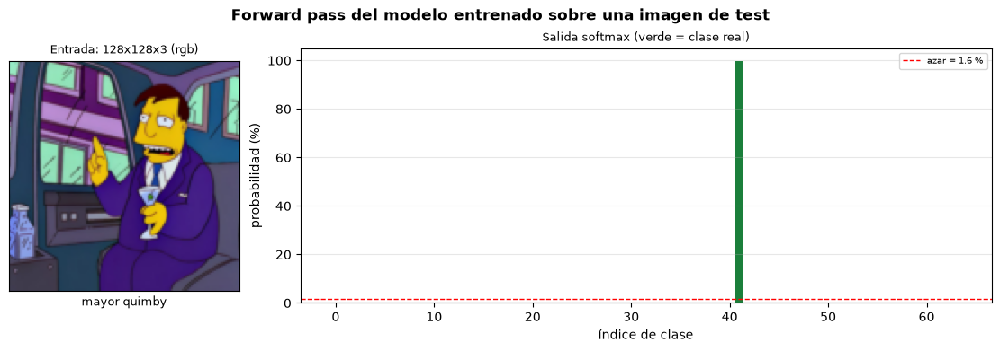

Prediccion: mayor_quimby con 99.9 % de confianza   |   clase real: mayor_quimby
Frente al 1.6 % que asignaria el azar: la red ya no reparte la probabilidad, la concentra.


In [59]:
# Recorrido de una imagen del conjunto de test por la red entrenada:
# de la imagen a los mapas de activación de cada bloque y a las probabilidades de salida
demo_aciertos = np.flatnonzero(predicciones_test == y_test_idx)
demo_indice = int(demo_aciertos[np.argsort(-confianza_test[demo_aciertos])][0])

# Activaciones capa a capa: cada capa se aplica sobre la salida de la anterior.
# training=False apaga el Dropout y hace que BatchNormalization use sus estadísticas acumuladas.
# Los tensores viven en la VRAM: hay que traerlos a la RAM del equipo antes de
# convertirlos a NumPy para graficarlos.
activaciones = {}
tensor_demo = X_test[demo_indice : demo_indice + 1]
with torch.no_grad():
    for capa in modelo_final.layers:
        tensor_demo = capa(tensor_demo, training=False)
        activaciones[capa.name] = tensor_demo.detach().cpu().numpy()[0]

# Mapas de cada bloque: la salida de su última activación, justo antes del pooling
mapas_por_bloque = []
ultima_activacion = None
for capa in modelo_final.layers:
    if isinstance(capa, layers.Activation):
        ultima_activacion = capa.name
    elif isinstance(capa, layers.MaxPooling2D):
        mapas_por_bloque.append(ultima_activacion)

MAPAS_POR_FILA = 8
figura, ejes = plt.subplots(
    len(mapas_por_bloque),
    MAPAS_POR_FILA + 1,
    figsize=(1.75 * (MAPAS_POR_FILA + 1), 2.0 * len(mapas_por_bloque)),
    layout="constrained",
)
filas_activos = []
for fila, nombre_capa in enumerate(mapas_por_bloque):
    mapas = activaciones[nombre_capa]  # (alto, ancho, filtros)
    # Los filtros que más se activaron con esta imagen
    mas_activos = np.argsort(-mapas.mean(axis=(0, 1)))[:MAPAS_POR_FILA]
    filas_activos.append(
        {
            "bloque": fila + 1,
            "capa": nombre_capa,
            "mapa": f"{mapas.shape[0]}x{mapas.shape[1]}",
            "filtros": mapas.shape[2],
            "valores_activos_%": round(float((mapas > 0).mean()) * 100, 1),
            "filtros_que_se_activan_%": round(float((mapas.max(axis=(0, 1)) > 0).mean()) * 100, 1),
        }
    )
    ejes[fila, 0].imshow(imagenes_test[demo_indice])
    ejes[fila, 0].set_ylabel(
        f"bloque {fila + 1}\n{mapas.shape[0]}x{mapas.shape[1]}, {mapas.shape[2]} filtros", fontsize=8
    )
    for columna, filtro in enumerate(mas_activos, start=1):
        ejes[fila, columna].imshow(mapas[..., filtro], cmap="inferno")
        ejes[fila, columna].set_title(f"filtro {filtro}", fontsize=7)
for eje in np.ravel(ejes):
    eje.set_xticks([])
    eje.set_yticks([])
figura.suptitle(
    f"Mapas de activación de la red entrenada: los {MAPAS_POR_FILA} filtros más activos de cada bloque",
    fontsize=12,
    fontweight="bold",
)
plt.show()

display(pd.DataFrame(filas_activos))

# Salida: distribución softmax sobre todas las clases
salida_demo = activaciones["salida"]
real_demo = int(y_test_idx[demo_indice])
figura, (eje_entrada, eje_salida) = plt.subplots(
    1, 2, figsize=(11, 3.8), layout="constrained", gridspec_kw={"width_ratios": [1, 3]}
)
eje_entrada.imshow(imagenes_test[demo_indice])
eje_entrada.set_title(f"Entrada: {ALTO_OBJETIVO}x{ANCHO_OBJETIVO}x3 ({representacion_final})", fontsize=9)
eje_entrada.set_xlabel(clases[real_demo].replace("_", " "), fontsize=9)
eje_entrada.set_xticks([])
eje_entrada.set_yticks([])

eje_salida.bar(
    range(NUMERO_CLASES),
    salida_demo * 100,
    color=["#1b7f3b" if i == real_demo else "#8fb8de" for i in range(NUMERO_CLASES)],
)
eje_salida.axhline(
    100 / NUMERO_CLASES,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"azar = {100 / NUMERO_CLASES:.1f} %",
)
eje_salida.set_title("Salida softmax (verde = clase real)", fontsize=9)
eje_salida.set_xlabel("índice de clase")
eje_salida.set_ylabel("probabilidad (%)")
eje_salida.legend(fontsize=7)
eje_salida.grid(alpha=0.3, axis="y")

figura.suptitle(
    "Forward pass del modelo entrenado sobre una imagen de test",
    fontsize=12,
    fontweight="bold",
)
plt.show()

print(
    f"Prediccion: {clases[int(salida_demo.argmax())]} con {salida_demo.max() * 100:.1f} % de confianza"
    f"   |   clase real: {clases[real_demo]}"
)
print(
    f"Frente al {100 / NUMERO_CLASES:.1f} % que asignaria el azar: la red ya no reparte la"
    " probabilidad, la concentra."
)

**Qué muestra el recorrido.** Los mapas siguen la jerarquía que describen los fundamentos. La imagen es del
alcalde Quimby, el acierto más seguro del test. El primer bloque responde a zonas de color con la resolución
completa: varios filtros se encienden con el traje morado y con las ventanas del fondo, y dejan a oscuras la piel
amarilla de la cara y la mano. En el segundo los mapas marcan bordes —los de las ventanas y el contorno del traje—,
y en el tercero se fragmentan en combinaciones de bordes más específicas; uno de ellos sigue el contorno del brazo y
de la copa. En el cuarto, de 16 × 16, los filtros más activos se encienden en unas pocas manchas sobre la boca, la
barbilla y la mano con la copa. A esa profundidad cada valor del mapa ve 38 × 38 píxeles de la imagen, y lo que
codifica ya no es un borde sino una parte del personaje.

La representación además se vuelve más selectiva: el 47 % de los valores del primer bloque es distinto de cero, el
9 % de los del tercero y apenas el 2 % de los del último, donde más de un tercio de los filtros ni siquiera se
activa con esta imagen. A la salida, la red asigna a Quimby un 99,9 % de probabilidad, frente al 1,6 % del azar.

#### Mapas de activación de cuatro imágenes de test

El recorrido anterior sigue una sola imagen. Aquí se siguen cuatro a la vez, para ver qué cambia de una a otra
a medida que la red se hace más profunda: Homero, Marge, Bart y Lisa, los cuatro personajes de la familia que
el MLP confundía por la piel amarilla. De cada uno se toma la imagen original de test —ni alterada ni
parecida— que el modelo acierta con mayor confianza.

Cada columna muestra **el mismo filtro** en las cuatro imágenes, con la misma escala de color: en cada bloque,
los dos filtros más activos en promedio sobre las cuatro. La tabla mide, por bloque, qué parte de los valores y
de los filtros se activa y cuánto se parecen las respuestas de la red a las cuatro imágenes: la correlación
media, entre cada par de imágenes, de la activación media de cada filtro. Vale 1 si los mismos filtros se
activan en la misma proporción para los cuatro personajes. La última fila es el vector del pooling global, lo
que recibe la cabeza densa para decidir.

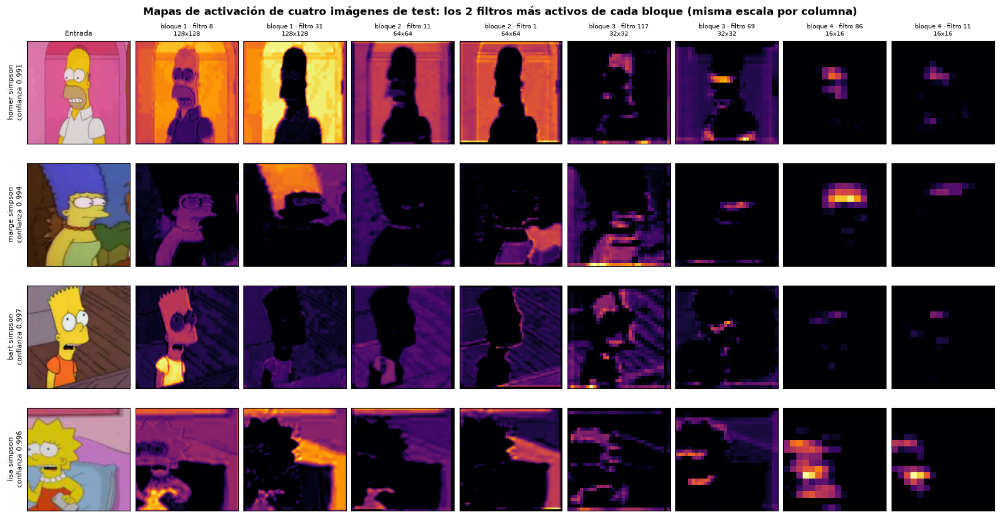

,bloque,capa,mapa,filtros,valores_activos_%,filtros_que_se_activan_%,correlacion_entre_imagenes
0,1,activacion_1,128x128,32,40.2,99.2,0.499
1,2,activacion_2,64x64,64,32.7,100.0,0.345
2,3,activacion_3,32x32,128,9.2,99.6,0.501
3,4,activacion_4,16x16,256,1.6,58.4,0.227
4,cabeza,pooling_global,1x1,256,58.4,58.4,0.213


Correlacion entre las cuatro imagenes: 1: 0.499   |   2: 0.345   |   3: 0.501   |   4: 0.227   |   cabeza: 0.213
Valores activos (%): 1: 40.2   |   2: 32.7   |   3: 9.2   |   4: 1.6   |   cabeza: 58.4
homer_simpson   -> prediccion homer_simpson con 99.1 % de confianza
marge_simpson   -> prediccion marge_simpson con 99.4 % de confianza
bart_simpson    -> prediccion bart_simpson con 99.7 % de confianza
lisa_simpson    -> prediccion lisa_simpson con 99.6 % de confianza


In [60]:
# Recorrido de cuatro imágenes de test por la red entrenada: Homero, Marge, Bart y Lisa, los cuatro
# personajes de la familia que el MLP confundía por la piel amarilla. De cada uno se toma la imagen
# original (ni alterada ni parecida) que el modelo acierta con mayor confianza.
PERSONAJES_RECORRIDO = ("homer_simpson", "marge_simpson", "bart_simpson", "lisa_simpson")
FILTROS_RECORRIDO = 2

original_test = ~datos_test["alterada"].to_numpy() & ~datos_test["parecida"].to_numpy()
indices_recorrido = []
for personaje in PERSONAJES_RECORRIDO:
    candidatas = np.flatnonzero((y_test_idx == clase_a_indice[personaje]) & acierto_estricto & original_test)
    indices_recorrido.append(int(candidatas[np.argmax(confianza_test[candidatas])]))

# Las cuatro imágenes pasan juntas por la red, capa a capa. Se guardan los mapas de cada bloque
# (la salida de su activación, antes del pooling) y el vector del pooling global, que es lo que
# recibe la cabeza densa.
capa_pooling_global = next(
    capa.name for capa in modelo_final.layers if isinstance(capa, layers.GlobalAveragePooling2D)
)
activaciones_recorrido = {}
tensor_recorrido = X_test[indices_recorrido]
with torch.no_grad():
    for capa in modelo_final.layers:
        tensor_recorrido = capa(tensor_recorrido, training=False)
        if capa.name in mapas_por_bloque or capa.name == capa_pooling_global:
            activaciones_recorrido[capa.name] = tensor_recorrido.detach().cpu().numpy()

# En cada bloque, los filtros más activos en promedio sobre las cuatro imágenes: así cada columna
# muestra el MISMO filtro para los cuatro personajes, con la misma escala de color
filtros_recorrido = {
    nombre: np.argsort(-activaciones_recorrido[nombre].mean(axis=(0, 1, 2)))[:FILTROS_RECORRIDO]
    for nombre in mapas_por_bloque
}

columnas = 1 + len(mapas_por_bloque) * FILTROS_RECORRIDO
figura, ejes = plt.subplots(
    len(indices_recorrido),
    columnas,
    figsize=(1.75 * columnas, 2.05 * len(indices_recorrido)),
    layout="constrained",
)
for fila, indice in enumerate(indices_recorrido):
    ejes[fila, 0].imshow(imagenes_test[indice])
    ejes[fila, 0].set_ylabel(
        f"{clases[y_test_idx[indice]].replace('_', ' ')}\nconfianza {confianza_test[indice]:.3f}", fontsize=8
    )
columna = 1
for bloque, nombre in enumerate(mapas_por_bloque, start=1):
    mapas = activaciones_recorrido[nombre]  # (imagenes, alto, ancho, filtros)
    for filtro in filtros_recorrido[nombre]:
        maximo = max(float(mapas[..., filtro].max()), 1e-8)
        for fila in range(len(indices_recorrido)):
            ejes[fila, columna].imshow(mapas[fila, :, :, filtro], cmap="inferno", vmin=0, vmax=maximo)
        ejes[0, columna].set_title(
            f"bloque {bloque} · filtro {filtro}\n{mapas.shape[1]}x{mapas.shape[2]}", fontsize=7
        )
        columna += 1
ejes[0, 0].set_title("Entrada", fontsize=8)
for eje in np.ravel(ejes):
    eje.set_xticks([])
    eje.set_yticks([])
figura.suptitle(
    f"Mapas de activación de cuatro imágenes de test: los {FILTROS_RECORRIDO} filtros más activos de cada bloque"
    " (misma escala por columna)",
    fontsize=12,
    fontweight="bold",
)
plt.show()


def correlacion_media(vectores):
    """Correlación de Pearson media entre todos los pares de filas: cuánto se parecen las respuestas
    de los filtros a las cuatro imágenes (1 = los mismos filtros se activan en la misma proporción)."""
    matriz_correlacion = np.corrcoef(vectores)
    return float(matriz_correlacion[np.triu_indices(len(vectores), k=1)].mean())


correlaciones_bloque = []
for bloque, nombre in enumerate(mapas_por_bloque, start=1):
    mapas = activaciones_recorrido[nombre]
    correlaciones_bloque.append(
        {
            "bloque": bloque,
            "capa": nombre,
            "mapa": f"{mapas.shape[1]}x{mapas.shape[2]}",
            "filtros": mapas.shape[3],
            "valores_activos_%": round(float((mapas > 0).mean()) * 100, 1),
            "filtros_que_se_activan_%": round(float((mapas.max(axis=(1, 2)) > 0).mean()) * 100, 1),
            # Activación media de cada filtro en cada imagen: un vector de 'filtros' valores por imagen
            "correlacion_entre_imagenes": round(correlacion_media(mapas.mean(axis=(1, 2))), 3),
        }
    )
vector_global = activaciones_recorrido[capa_pooling_global]
correlaciones_bloque.append(
    {
        "bloque": "cabeza",
        "capa": capa_pooling_global,
        "mapa": "1x1",
        "filtros": vector_global.shape[1],
        "valores_activos_%": round(float((vector_global > 0).mean()) * 100, 1),
        "filtros_que_se_activan_%": round(float((vector_global > 0).mean()) * 100, 1),
        "correlacion_entre_imagenes": round(correlacion_media(vector_global), 3),
    }
)
display(pd.DataFrame(correlaciones_bloque))

print(
    "Correlacion entre las cuatro imagenes: "
    + "   |   ".join(f"{fila['bloque']}: {fila['correlacion_entre_imagenes']:.3f}" for fila in correlaciones_bloque)
)
print(
    "Valores activos (%): "
    + "   |   ".join(f"{fila['bloque']}: {fila['valores_activos_%']:.1f}" for fila in correlaciones_bloque)
)
for indice in indices_recorrido:
    print(
        f"{clases[y_test_idx[indice]]:15s} -> prediccion {clases[predicciones_test[indice]]}"
        f" con {confianza_test[indice] * 100:.1f} % de confianza"
    )

**Lectura.** Las cuatro imágenes confirman lo que mostraba la de Quimby, y agregan lo que una sola no
podía mostrar: cómo la representación deja de ser común a los cuatro personajes.

- **Bloques 1 y 2: color, sobre todo del fondo.** Los dos filtros del primer bloque se encienden con el fondo de
  color —la pared rosada de Homero, la parte alta del fondo de Marge, el de Lisa— y el 8 también con la ropa y la
  piel de Bart. Los del segundo bloque responden casi solo a la pared de Homero.
- **Bloque 3: bordes sueltos.** Los mapas de 32 × 32 marcan contornos repartidos entre el personaje y el fondo.
- **Bloque 4: pocas manchas, sobre el personaje.** A 16 × 16 solo el 1,6 % de los valores es distinto de cero, y
  lo que queda cae sobre las cabezas. Un mismo filtro ya no responde igual a todos: el 86 se enciende con fuerza en
  el pelo de Marge y en la cara de Lisa, menos en la cabeza de Homero y casi nada con Bart; el 11, sobre todo con
  Lisa.

La tabla lo cuantifica. En los tres primeros bloques, la activación media de los filtros tiene una correlación de
0,35 a 0,50 entre las cuatro imágenes: en parte, los mismos filtros se activan con todas. En el cuarto bloque
cae a 0,23, y en el vector del pooling global, el que recibe la cabeza densa, a 0,21: cada personaje activa su
propio conjunto de filtros. Es la extracción automática de características que el MLP no tenía: sus
histogramas de color se parecían entre los cuatro por la piel amarilla compartida, mientras que la CNN, en su
último bloque, los representa con patrones distintos. La red los acierta a los cuatro con más de 99 % de confianza.

#### Predicciones individuales: las cinco clases más probables

En lugar de quedarse con la clase ganadora, aquí se abre la distribución completa. La barra de cada
candidata muestra cuánta probabilidad le asignó el modelo, lo que permite distinguir entre una decisión
tomada con holgura y una en la que dos personajes quedaron casi empatados.

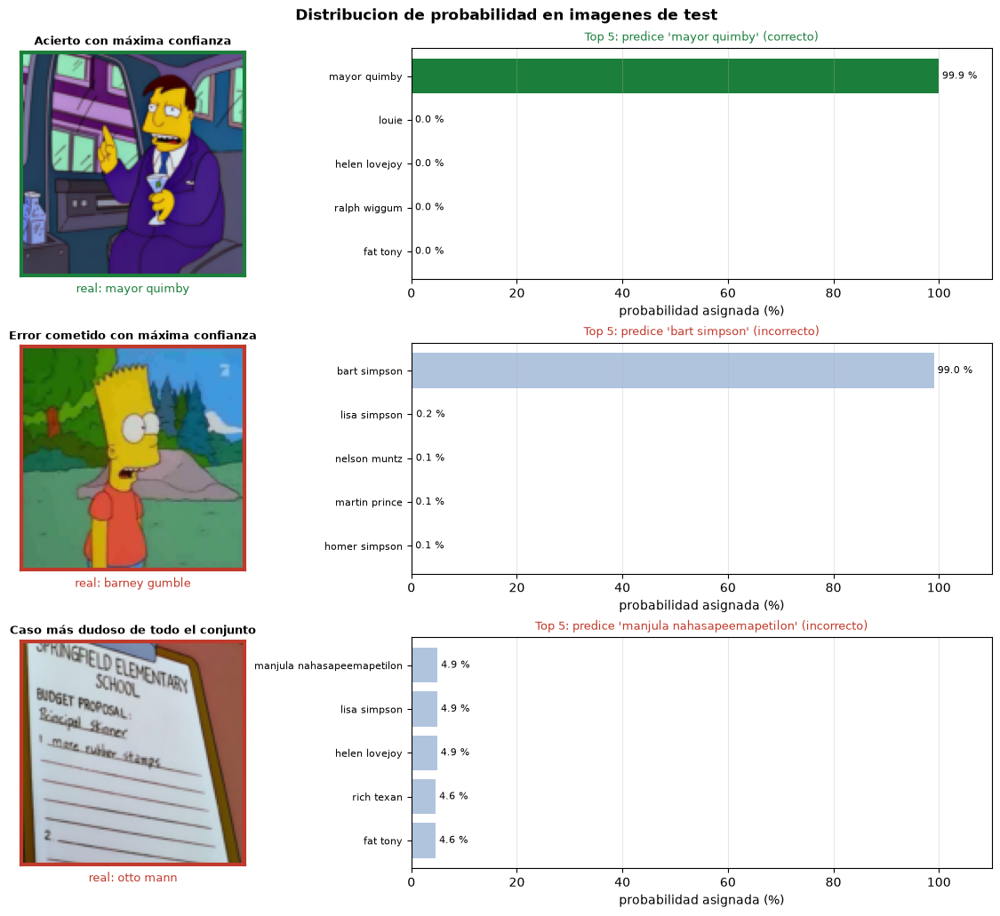

In [61]:
# Tres casos representativos: un acierto seguro, un error seguro y un caso donde el modelo dudó
# Errores según el criterio de acierto: nombrar a otro personaje es un error aunque esté en la escena
demo_errores = np.flatnonzero(~acierto_test)

casos = [
    (int(demo_aciertos[np.argmax(confianza_test[demo_aciertos])]), "Acierto con máxima confianza"),
    (int(demo_errores[np.argmax(confianza_test[demo_errores])]), "Error cometido con máxima confianza"),
    (int(np.argmin(confianza_test)), "Caso más dudoso de todo el conjunto"),
]

TOP_K = 5
figura, ejes = plt.subplots(
    len(casos),
    2,
    figsize=(11, 3.4 * len(casos)),
    layout="constrained",
    gridspec_kw={"width_ratios": [1, 2.6]},
)

for fila, (indice, descripcion) in enumerate(casos):
    real = int(y_test_idx[indice])
    predicho = int(predicciones_test[indice])
    color = color_resultado(indice)

    eje_imagen = ejes[fila, 0]
    eje_imagen.imshow(imagenes_test[indice])
    eje_imagen.set_xticks([])
    eje_imagen.set_yticks([])
    for lado in eje_imagen.spines.values():
        lado.set_edgecolor(color)
        lado.set_linewidth(3)
    eje_imagen.set_xlabel(
        f"real: {clases[real].replace('_', ' ')}", fontsize=9, labelpad=6, color=color
    )
    eje_imagen.set_title(descripcion, fontsize=9, fontweight="bold")

    # Las TOP_K clases con mayor probabilidad, dibujadas de mayor a menor
    mejores = np.argsort(-probabilidades_test[indice])[:TOP_K][::-1]
    etiquetas = [clases[i].replace("_", " ") for i in mejores]
    colores = [
        COLOR_ACIERTO if i == real else COLOR_ESCENA if clases[i] in acompanantes_test[indice] else "#b0c4de"
        for i in mejores
    ]

    eje_barras = ejes[fila, 1]
    barras = eje_barras.barh(etiquetas, probabilidades_test[indice][mejores] * 100, color=colores)
    eje_barras.bar_label(barras, fmt="%.1f %%", fontsize=8, padding=3)
    eje_barras.set_xlim(0, 110)
    eje_barras.set_xlabel("probabilidad asignada (%)")
    eje_barras.tick_params(axis="y", labelsize=8)
    eje_barras.grid(alpha=0.3, axis="x")
    eje_barras.set_title(
        f"Top {TOP_K}: predice '{clases[predicho].replace('_', ' ')}'"
        f" ({TEXTO_RESULTADO[color]})",
        fontsize=9,
        color=color,
    )

figura.suptitle(
    "Distribucion de probabilidad en imagenes de test",
    fontsize=12,
    fontweight="bold",
)
plt.show()

#### Muestra aleatoria: el modelo trabajando sin filtros

Los ejemplos anteriores están elegidos a propósito por ser extremos. La rejilla siguiente toma una
muestra **al azar** del conjunto de test, sin seleccionar nada: es la imagen más honesta del
comportamiento real del modelo, y la proporción de marcos verdes debería parecerse a la accuracy global.

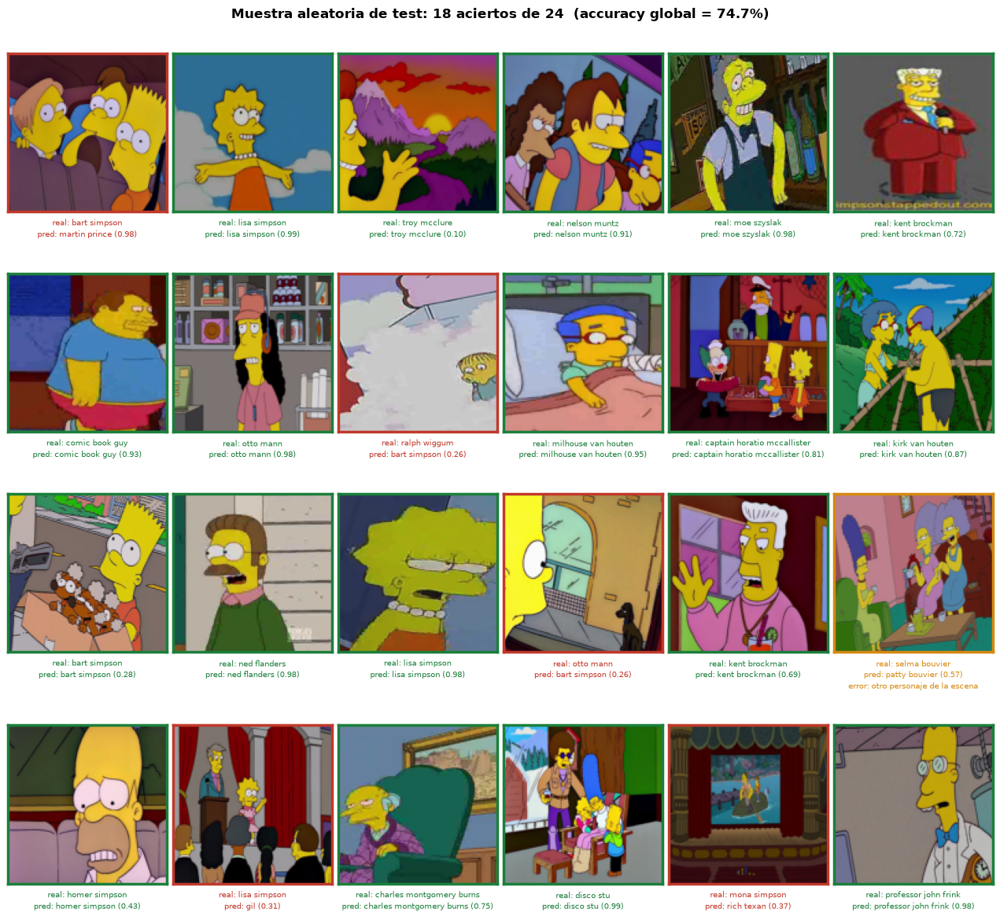

In [62]:
# Muestra aleatoria sin seleccionar: marco verde si acertó, ámbar si se equivocó nombrando a otro
# personaje de la escena y rojo en los demás errores
FILAS_MOSAICO, COLUMNAS_MOSAICO = 4, 6
generador_muestra = np.random.default_rng(SEMILLA)
muestra_aleatoria = generador_muestra.choice(
    len(y_test_idx), size=FILAS_MOSAICO * COLUMNAS_MOSAICO, replace=False
)

figura, ejes = plt.subplots(
    FILAS_MOSAICO,
    COLUMNAS_MOSAICO,
    figsize=(2.1 * COLUMNAS_MOSAICO, 2.9 * FILAS_MOSAICO),
    layout="constrained",
)

for eje, indice in zip(np.ravel(ejes), muestra_aleatoria):
    real = clases[y_test_idx[indice]].replace("_", " ")
    predicho = clases[predicciones_test[indice]].replace("_", " ")
    color = color_resultado(indice)

    eje.imshow(imagenes_test[indice])
    eje.set_xticks([])
    eje.set_yticks([])
    for lado in eje.spines.values():
        lado.set_edgecolor(color)
        lado.set_linewidth(2.5)
    eje.set_xlabel(
        f"real: {real}\npred: {predicho} ({confianza_test[indice]:.2f})"
        + (f"\n{rotulo_escena(indice)}" if color == COLOR_ESCENA else ""),
        fontsize=7,
        color=color,
        labelpad=5,
        linespacing=1.5,
    )

aciertos_muestra = int(acierto_test[muestra_aleatoria].sum())
figura.suptitle(
    f"Muestra aleatoria de test: {aciertos_muestra} aciertos"
    f" de {len(muestra_aleatoria)}  (accuracy global = {accuracy_test:.1%})",
    fontsize=12,
    fontweight="bold",
)
plt.show()

#### Rendimiento por personaje, con una imagen de cada uno

La tabla de métricas por clase es precisa pero abstracta. Esta galería le pone cara: un ejemplo real de
cada uno de los 64 personajes, con el marco coloreado según el **recall** que el modelo alcanza en esa
clase —verde si la reconoce casi siempre, rojo si se le escapa casi siempre—. Se ve de un vistazo que
las clases en rojo son, sobre todo, las minoritarias.

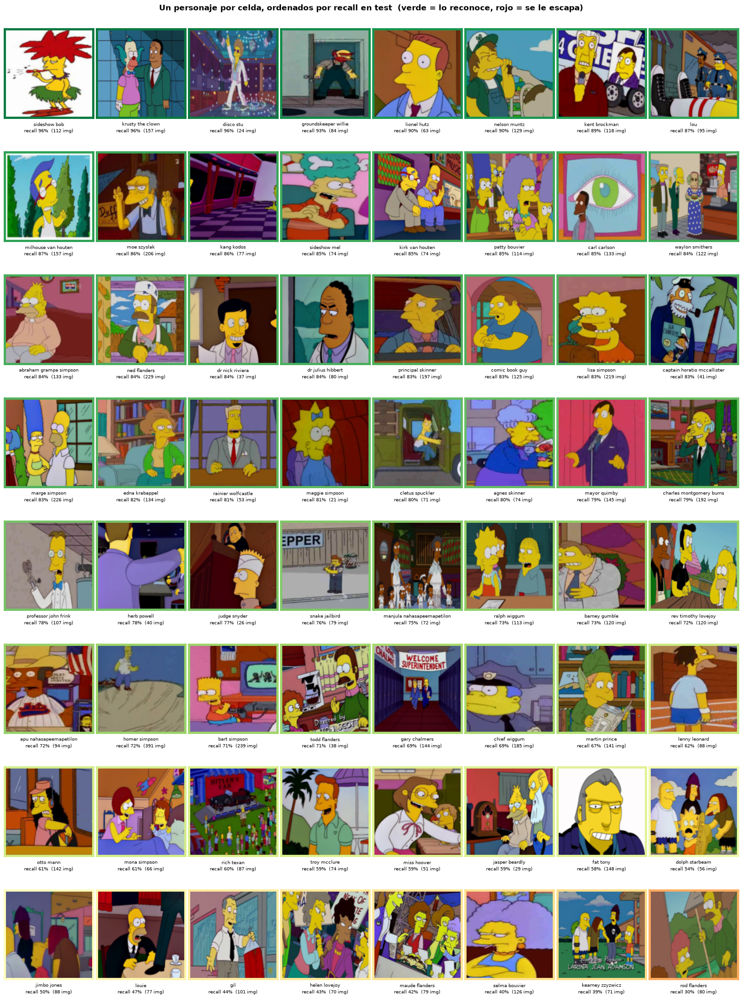

Recall medio sobre las 64 clases: 73.4%
Mejor: sideshow_bob (96%)   |   Peor: rod_flanders (30%)


In [63]:
# Una imagen por personaje, con el marco coloreado según el recall de esa clase
recall_por_clase = np.diag(matriz_normalizada)
mapa_color = plt.get_cmap("RdYlGn")

FILAS_GALERIA = 8
COLUMNAS_GALERIA = int(np.ceil(NUMERO_CLASES / FILAS_GALERIA))

figura, ejes = plt.subplots(
    FILAS_GALERIA,
    COLUMNAS_GALERIA,
    figsize=(2.0 * COLUMNAS_GALERIA, 2.7 * FILAS_GALERIA),
    layout="constrained",
)
ejes = np.ravel(ejes)

# Se recorren las clases de mejor a peor recall, para que la degradación sea visible
orden_clases = np.argsort(-recall_por_clase)

for eje, clase in zip(ejes, orden_clases):
    indices_clase = np.flatnonzero(y_test_idx == clase)
    # Se prefiere una imagen acertada; si el modelo no acierta ninguna, se usa la primera disponible
    correctas = indices_clase[predicciones_test[indices_clase] == clase]
    indice = int(correctas[0]) if len(correctas) else int(indices_clase[0])

    eje.imshow(imagenes_test[indice])
    eje.set_xticks([])
    eje.set_yticks([])
    for lado in eje.spines.values():
        lado.set_edgecolor(mapa_color(recall_por_clase[clase]))
        lado.set_linewidth(3.5)
    eje.set_xlabel(
        f"{clases[clase].replace('_', ' ')}\nrecall {recall_por_clase[clase]:.0%}"
        f"  ({len(indices_clase)} img)",
        fontsize=7,
        labelpad=5,
        linespacing=1.5,
    )

for eje in ejes[NUMERO_CLASES:]:
    eje.axis("off")

figura.suptitle(
    "Un personaje por celda, ordenados por recall en test"
    "  (verde = lo reconoce, rojo = se le escapa)",
    fontsize=12,
    fontweight="bold",
)
plt.show()

print(f"Recall medio sobre las {NUMERO_CLASES} clases: {recall_por_clase.mean():.1%}")
print(
    f"Mejor: {clases[int(orden_clases[0])]} ({recall_por_clase[orden_clases[0]]:.0%})"
    f"   |   Peor: {clases[int(orden_clases[-1])]} ({recall_por_clase[orden_clases[-1]]:.0%})"
)

#### En qué se apoya el modelo

Hasta aquí se ha visto **qué** responde el modelo; este último análisis muestra **en qué zonas de la
imagen se apoya** para responderlo. En una CNN la herramienta habitual es **Grad-CAM** (Selvaraju et al.,
2017):

1. Se toman los mapas de activación del último bloque convolucional, que todavía conservan la posición y ya
   responden a partes grandes de la imagen.
2. Se calcula el gradiente de la probabilidad de la clase predicha respecto de cada uno de esos mapas. Su
   promedio dice cuánto empuja cada filtro hacia esa clase.
3. Se suman los mapas ponderados por ese peso, se descartan los valores negativos y el resultado se amplía
   al tamaño de la imagen: las zonas cálidas son las que más aumentan la probabilidad de la clase elegida.

El MLP solo podía responder esta pregunta por bloques de descriptores, con la importancia por permutación;
la CNN la responde sobre la propia imagen. La segunda figura promedia Grad-CAM sobre todo el test: muestra en
qué zonas del encuadre se apoya la red en general.

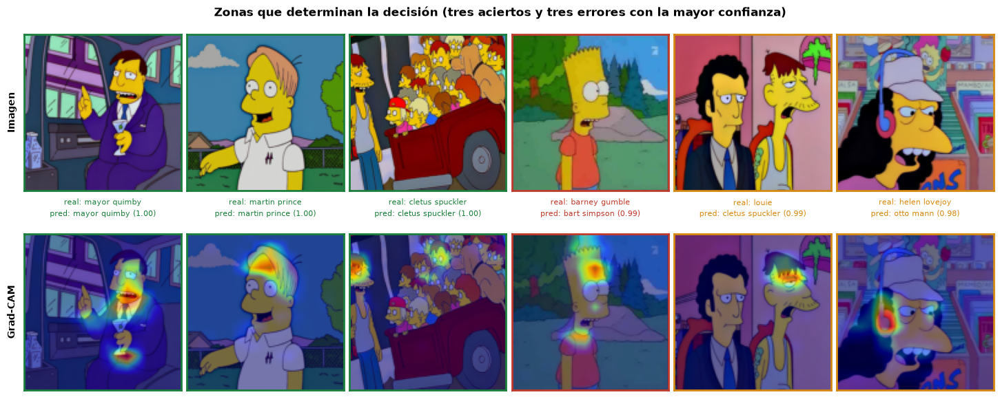

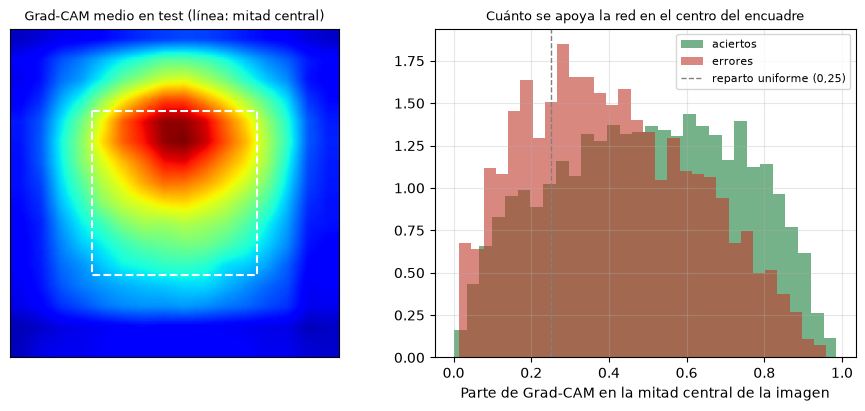

,Indicador,Valor,Referencia
0,Imágenes de test,7058.000,
1,Parte de Grad-CAM en el 10 % de píxeles más cá...,0.730,"0,100 si la red mirara toda la imagen por igual"
2,Parte de Grad-CAM en la mitad central (aciertos),0.498,"0,250 con un reparto uniforme"
3,Parte de Grad-CAM en la mitad central (errores),0.407,"0,250 con un reparto uniforme"


In [64]:
# Grad-CAM sobre el último bloque convolucional: qué zonas de la imagen empujan la decisión
import torch.nn.functional as F

indices_gradcam = list(demo_aciertos[np.argsort(-confianza_test[demo_aciertos])][:3]) + list(
    demo_errores[np.argsort(-confianza_test[demo_errores])][:3]
)

# Los mapas del último bloque: la salida de su última activación, antes del pooling
capas_modelo = list(modelo_final.layers)
corte = [capa.name for capa in capas_modelo].index(mapas_por_bloque[-1]) + 1


def grad_cam(indices, clases_objetivo=None):
    """Mapas Grad-CAM (n, alto, ancho) en [0, 1] de las imágenes de test indicadas: para la clase predicha de
    cada una o, si se indica `clases_objetivo`, para esas clases."""
    with torch.no_grad():
        mapas = X_test[indices]
        for capa in capas_modelo[:corte]:
            mapas = capa(mapas, training=False)
    # El gradiente se toma respecto de los mapas, no de los pesos
    mapas = mapas.detach().requires_grad_(True)  # (n, alto, ancho, filtros)
    salida = mapas
    for capa in capas_modelo[corte:]:
        salida = capa(salida, training=False)
    if clases_objetivo is None:
        clases_objetivo = predicciones_test[indices]
    objetivo = torch.as_tensor(np.asarray(clases_objetivo), dtype=torch.long, device=salida.device)
    puntajes = salida.gather(1, objetivo.unsqueeze(1)).sum()
    (gradientes,) = torch.autograd.grad(puntajes, mapas)
    # Peso de cada filtro: el gradiente medio sobre todas las posiciones del mapa
    pesos_filtros = gradientes.mean(dim=(1, 2), keepdim=True)
    cam = torch.relu((pesos_filtros * mapas).sum(dim=-1))
    cam = F.interpolate(
        cam.unsqueeze(1), size=(ALTO_OBJETIVO, ANCHO_OBJETIVO), mode="bilinear", align_corners=False
    )[:, 0]
    cam = cam / cam.amax(dim=(1, 2), keepdim=True).clamp_min(1e-8)
    return cam.detach().cpu().numpy()


mapas_gradcam = grad_cam(indices_gradcam)

figura, ejes = plt.subplots(
    2, len(indices_gradcam), figsize=(2.4 * len(indices_gradcam), 5.8), layout="constrained"
)
for columna, (indice, cam) in enumerate(zip(indices_gradcam, mapas_gradcam)):
    color = color_resultado(indice)
    ejes[0, columna].imshow(imagenes_test[indice])
    ejes[1, columna].imshow(imagenes_test[indice])
    ejes[1, columna].imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ejes[0, columna].set_xlabel(
        f"real: {clases[y_test_idx[indice]].replace('_', ' ')}\n"
        f"pred: {clases[predicciones_test[indice]].replace('_', ' ')} ({confianza_test[indice]:.2f})",
        fontsize=8,
        color=color,
        labelpad=6,
        linespacing=1.5,
    )
    for eje in (ejes[0, columna], ejes[1, columna]):
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in eje.spines.values():
            lado.set_edgecolor(color)
            lado.set_linewidth(2)

ejes[0, 0].set_ylabel("Imagen", fontsize=10, fontweight="bold", labelpad=8)
ejes[1, 0].set_ylabel("Grad-CAM", fontsize=10, fontweight="bold", labelpad=8)
figura.suptitle(
    "Zonas que determinan la decisión (tres aciertos y tres errores con la mayor confianza)",
    fontsize=12,
    fontweight="bold",
)
plt.show()

# Grad-CAM medio sobre todo el test, por lotes: en qué zonas del encuadre se apoya la red en general
TAMANO_LOTE_GRADCAM = 256
suma_cam = np.zeros((ALTO_OBJETIVO, ANCHO_OBJETIVO))
concentracion_test = []
centro_test = []
margen_alto, margen_ancho = ALTO_OBJETIVO // 4, ANCHO_OBJETIVO // 4
for desde in range(0, len(y_test_idx), TAMANO_LOTE_GRADCAM):
    lote_cam = grad_cam(list(range(desde, min(desde + TAMANO_LOTE_GRADCAM, len(y_test_idx)))))
    suma_cam += lote_cam.sum(axis=0)
    plano = lote_cam.reshape(len(lote_cam), -1)
    umbral = np.quantile(plano, 0.90, axis=1, keepdims=True)
    total_cam = np.maximum(plano.sum(axis=1), 1e-8)
    concentracion_test.append((plano * (plano >= umbral)).sum(axis=1) / total_cam)
    centro_test.append(
        lote_cam[:, margen_alto:ALTO_OBJETIVO - margen_alto, margen_ancho:ANCHO_OBJETIVO - margen_ancho].sum(axis=(1, 2))
        / total_cam
    )
cam_medio = suma_cam / len(y_test_idx)
concentracion_test = np.concatenate(concentracion_test)
centro_test = np.concatenate(centro_test)

figura, ejes = plt.subplots(1, 2, figsize=(9, 4.0), layout="constrained")
ejes[0].imshow(cam_medio / cam_medio.max(), cmap="jet", vmin=0, vmax=1)
ejes[0].add_patch(
    plt.Rectangle(
        (margen_ancho - 0.5, margen_alto - 0.5), ANCHO_OBJETIVO - 2 * margen_ancho, ALTO_OBJETIVO - 2 * margen_alto,
        fill=False, edgecolor="white", linestyle="--", linewidth=1.5,
    )
)
ejes[0].set_title("Grad-CAM medio en test (línea: mitad central)", fontsize=9)
ejes[0].set_xticks([])
ejes[0].set_yticks([])
ejes[1].hist(centro_test[acierto_test], bins=30, alpha=0.6, label="aciertos", color=COLOR_ACIERTO, density=True)
ejes[1].hist(centro_test[~acierto_test], bins=30, alpha=0.6, label="errores", color=COLOR_ERROR, density=True)
ejes[1].axvline(0.25, color="gray", linestyle="--", linewidth=1, label="reparto uniforme (0,25)")
ejes[1].set_xlabel("Parte de Grad-CAM en la mitad central de la imagen")
ejes[1].set_title("Cuánto se apoya la red en el centro del encuadre", fontsize=9)
ejes[1].legend(fontsize=8)
ejes[1].grid(alpha=0.3)
plt.show()

tabla_gradcam = pd.DataFrame(
    [
        ("Imágenes de test", len(y_test_idx), ""),
        (
            "Parte de Grad-CAM en el 10 % de píxeles más cálidos",
            round(float(concentracion_test.mean()), 3),
            "0,100 si la red mirara toda la imagen por igual",
        ),
        (
            "Parte de Grad-CAM en la mitad central (aciertos)",
            round(float(centro_test[acierto_test].mean()), 3),
            "0,250 con un reparto uniforme",
        ),
        (
            "Parte de Grad-CAM en la mitad central (errores)",
            round(float(centro_test[~acierto_test].mean()), 3),
            "0,250 con un reparto uniforme",
        ),
    ],
    columns=["Indicador", "Valor", "Referencia"],
)
display(tabla_gradcam)

**Lectura de Grad-CAM.** La red mira a los personajes. En los aciertos más seguros, la zona cálida cae sobre
el personaje aunque ocupe poco del encuadre: la boca y la mano con la copa de Quimby, el pelo y la frente de Martin
Prince, y la cara de Cletus, pequeño, en el borde de una multitud. El Grad-CAM medio de todo el test se concentra
en la parte central y superior de la imagen, donde suelen estar las cabezas: el 10 % de píxeles más cálidos reúne
el 73,0 % de la influencia (sería el 10 % si la red mirara toda la imagen por igual), y la mitad central, el 49,8 %
en los aciertos (25 % con un reparto uniforme).

Los errores más confiados no son de una red que mira el fondo: en los tres de la figura, la red mira a un
personaje que sí está en la imagen. En una imagen de la carpeta de Barney nombra a Bart, que es el único que
aparece; en una de Louie, a Cletus, que está a su lado, y en una de Helen Lovejoy, a Otto, que ocupa el primer
plano. Los dos últimos los detectó la escena del episodio (marco ámbar); el primero no (marco rojo). En los
errores, la parte de Grad-CAM en la mitad central baja al 40,7 %, sin acercarse al reparto uniforme.

#### Mapa de activación de cada clase

Hasta aquí Grad-CAM explica la clase **predicha** de unas pocas imágenes. Esta sección lo calcula para la clase
**de la carpeta** de cada uno de los 64 personajes, de dos formas:

1. **Un ejemplo por personaje.** Su imagen original de test acertada con la mayor probabilidad para su clase,
   con el Grad-CAM de esa clase encima. Si un personaje no tuviera ninguna original acertada, se usaría otra
   imagen suya; la última línea de la salida dice cuántas veces pasó.
2. **El mapa medio de cada clase.** El Grad-CAM de la clase sobre todas sus imágenes de test, promediado: en qué
   zona del encuadre suele estar la evidencia de cada personaje.

La tabla resume, por personaje, qué parte del Grad-CAM cae en el 10 % de píxeles más cálidos y en la mitad
central de la imagen, junto a su recall: los cinco personajes con el calor más concentrado y los cinco con el
más disperso.

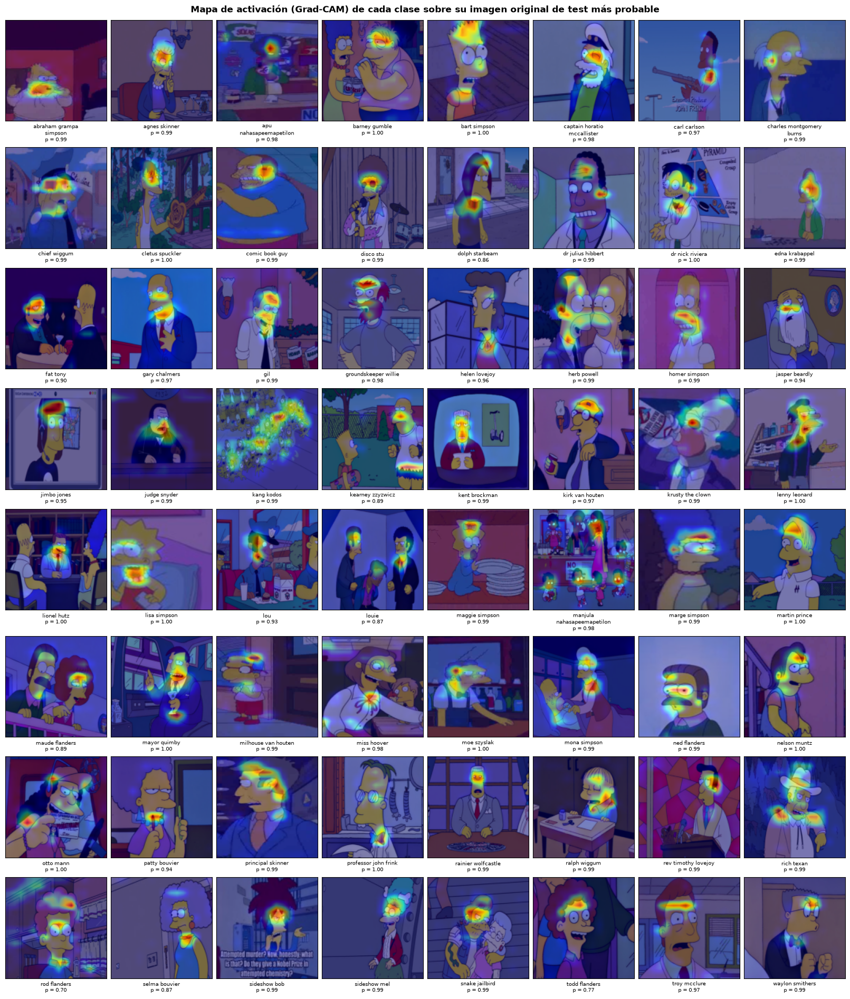

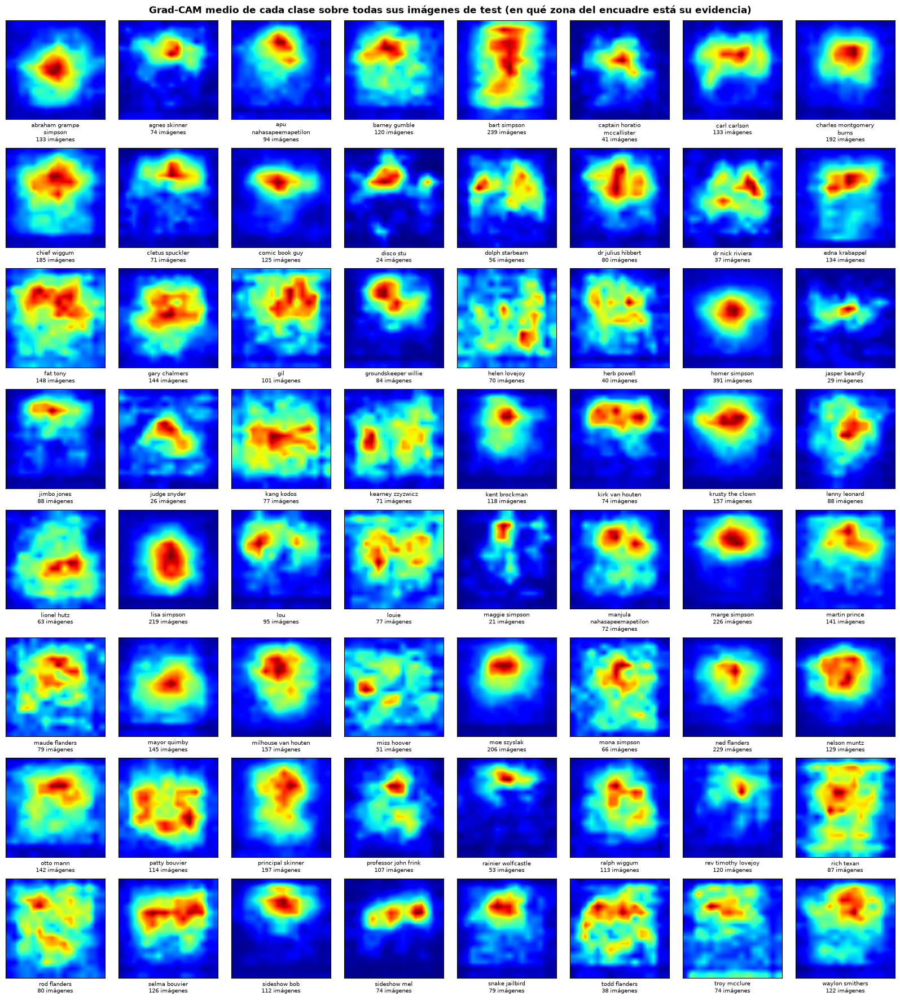

,personaje,n_test,recall,concentracion_10%,mitad_central,ejemplo
0,sideshow_mel,74,0.851,0.863,0.537,original acertada
1,groundskeeper_willie,84,0.929,0.858,0.478,original acertada
2,disco_stu,24,0.958,0.831,0.426,original acertada
3,agnes_skinner,74,0.797,0.798,0.468,original acertada
4,rainier_wolfcastle,53,0.811,0.797,0.302,original acertada
59,mona_simpson,66,0.606,0.621,0.425,original acertada
60,rich_texan,87,0.598,0.615,0.404,original acertada
61,rod_flanders,80,0.300,0.614,0.394,original acertada
62,kang_kodos,77,0.857,0.604,0.401,original acertada
63,judge_snyder,26,0.769,0.585,0.469,original acertada


Parte del Grad-CAM de la clase en el 10 % de píxeles más cálidos: media 0.724 (0,100 si la red mirara toda la imagen por igual)
Parte en la mitad central: media 0.472 (0,250 con un reparto uniforme)
Correlacion entre la concentracion media de cada personaje y su recall: 0.505
Calor mas concentrado: sideshow_mel, groundskeeper_willie, disco_stu, agnes_skinner, rainier_wolfcastle
Calor mas disperso   : judge_snyder, kang_kodos, rod_flanders, rich_texan, mona_simpson
Ejemplos por tipo: {'original acertada': 64}


In [65]:
# Mapa de activación de cada clase: Grad-CAM de la clase de la carpeta sobre las imágenes de test
import textwrap


# grad_cam() (sección anterior) calcula el mapa de la clase que se le indique


# Un ejemplo por personaje: su imagen original de test acertada con la mayor probabilidad para su clase.
# Si no hubiera ninguna original acertada, se usa cualquier imagen acertada y, en último caso, la de
# mayor probabilidad para su clase.
probabilidad_propia = probabilidades_test[np.arange(len(y_test_idx)), y_test_idx]
ejemplo_por_clase = []
for clase in range(NUMERO_CLASES):
    de_la_clase = y_test_idx == clase
    for origen_ejemplo, mascara in (
        ("original acertada", de_la_clase & original_test & acierto_estricto),
        ("acertada", de_la_clase & acierto_estricto),
        ("mayor probabilidad", de_la_clase),
    ):
        candidatas = np.flatnonzero(mascara)
        if len(candidatas):
            break
    ejemplo_por_clase.append((int(candidatas[np.argmax(probabilidad_propia[candidatas])]), origen_ejemplo))
indices_por_clase = [indice for indice, _ in ejemplo_por_clase]
mapas_por_clase = grad_cam(indices_por_clase, y_test_idx[indices_por_clase])

COLUMNAS_CLASES = 8
filas_clases = int(np.ceil(NUMERO_CLASES / COLUMNAS_CLASES))
figura, ejes = plt.subplots(
    filas_clases,
    COLUMNAS_CLASES,
    figsize=(2.0 * COLUMNAS_CLASES, 2.35 * filas_clases),
    layout="constrained",
)
ejes = np.ravel(ejes)
for clase, (eje, indice, cam) in enumerate(zip(ejes, indices_por_clase, mapas_por_clase)):
    eje.imshow(imagenes_test[indice])
    eje.imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    eje.set_xticks([])
    eje.set_yticks([])
    eje.set_xlabel(
        textwrap.fill(clases[clase].replace("_", " "), 20) + f"\np = {probabilidad_propia[indice]:.2f}",
        fontsize=7,
        labelpad=3,
        linespacing=1.3,
    )
for eje in ejes[NUMERO_CLASES:]:
    eje.axis("off")
figura.suptitle(
    "Mapa de activación (Grad-CAM) de cada clase sobre su imagen original de test más probable",
    fontsize=12,
    fontweight="bold",
)
plt.show()

# Grad-CAM de la clase de la carpeta en TODAS las imágenes de test, por lotes: el mapa medio de cada
# personaje y cuánto se concentra su calor
cam_medio_clase = np.zeros((NUMERO_CLASES, ALTO_OBJETIVO, ANCHO_OBJETIVO))
concentracion_clase_test = []
centro_clase_test = []
for desde in range(0, len(y_test_idx), TAMANO_LOTE_GRADCAM):
    lote = np.arange(desde, min(desde + TAMANO_LOTE_GRADCAM, len(y_test_idx)))
    lote_cam = grad_cam(lote.tolist(), y_test_idx[lote])
    np.add.at(cam_medio_clase, y_test_idx[lote], lote_cam)
    plano = lote_cam.reshape(len(lote_cam), -1)
    umbral = np.quantile(plano, 0.90, axis=1, keepdims=True)
    total_cam = np.maximum(plano.sum(axis=1), 1e-8)
    concentracion_clase_test.append((plano * (plano >= umbral)).sum(axis=1) / total_cam)
    centro_clase_test.append(
        lote_cam[:, margen_alto:ALTO_OBJETIVO - margen_alto, margen_ancho:ANCHO_OBJETIVO - margen_ancho].sum(axis=(1, 2))
        / total_cam
    )
cam_medio_clase /= conteos_test[:, None, None]
concentracion_clase_test = np.concatenate(concentracion_clase_test)
centro_clase_test = np.concatenate(centro_clase_test)

figura, ejes = plt.subplots(
    filas_clases,
    COLUMNAS_CLASES,
    figsize=(2.0 * COLUMNAS_CLASES, 2.2 * filas_clases),
    layout="constrained",
)
ejes = np.ravel(ejes)
for clase, eje in enumerate(ejes[:NUMERO_CLASES]):
    eje.imshow(cam_medio_clase[clase] / max(cam_medio_clase[clase].max(), 1e-8), cmap="jet", vmin=0, vmax=1)
    eje.set_xticks([])
    eje.set_yticks([])
    eje.set_xlabel(
        textwrap.fill(clases[clase].replace("_", " "), 20) + f"\n{conteos_test[clase]} imágenes",
        fontsize=7,
        labelpad=3,
        linespacing=1.3,
    )
for eje in ejes[NUMERO_CLASES:]:
    eje.axis("off")
figura.suptitle(
    "Grad-CAM medio de cada clase sobre todas sus imágenes de test (en qué zona del encuadre está su evidencia)",
    fontsize=12,
    fontweight="bold",
)
plt.show()

# Resumen por personaje: concentración del calor y parte en la mitad central, frente al recall
tabla_gradcam_clases = pd.DataFrame(
    {
        "personaje": clases,
        "n_test": conteos_test,
        "recall": np.diag(matriz_normalizada).round(3),
        "concentracion_10%": [
            round(float(concentracion_clase_test[y_test_idx == clase].mean()), 3) for clase in range(NUMERO_CLASES)
        ],
        "mitad_central": [
            round(float(centro_clase_test[y_test_idx == clase].mean()), 3) for clase in range(NUMERO_CLASES)
        ],
        "ejemplo": [origen for _, origen in ejemplo_por_clase],
    }
).sort_values("concentracion_10%", ascending=False, ignore_index=True)
display(pd.concat([tabla_gradcam_clases.head(5), tabla_gradcam_clases.tail(5)]))

print(
    f"Parte del Grad-CAM de la clase en el 10 % de píxeles más cálidos: media {concentracion_clase_test.mean():.3f}"
    f" (0,100 si la red mirara toda la imagen por igual)"
)
print(f"Parte en la mitad central: media {centro_clase_test.mean():.3f} (0,250 con un reparto uniforme)")
print(
    "Correlacion entre la concentracion media de cada personaje y su recall: "
    f"{np.corrcoef(tabla_gradcam_clases['concentracion_10%'], tabla_gradcam_clases['recall'])[0, 1]:.3f}"
)
print(f"Calor mas concentrado: {', '.join(tabla_gradcam_clases['personaje'].head(5))}")
print(f"Calor mas disperso   : {', '.join(tabla_gradcam_clases['personaje'].tail(5)[::-1])}")
print(f"Ejemplos por tipo: {pd.Series([origen for _, origen in ejemplo_por_clase]).value_counts().to_dict()}")

**Lectura.** La red se apoya en el personaje en las 64 clases, y sobre todo en su cabeza.

- **Un ejemplo por personaje.** Los 64 ejemplos son originales acertadas, y en casi todos la zona más cálida
  cae sobre la cabeza: el pelo de Marge y de Sideshow Bob, la cara de Homero, de Krusty y del abuelo. En unos
  pocos cae sobre la ropa, que también distingue al personaje: la corbata de Gary Chalmers y la de Lionel Hutz. La
  probabilidad de la clase en su mejor ejemplo va de 0,70 (Rod Flanders) a 1,00.
- **El mapa medio de cada clase.** En los personajes que la red reconoce bien —Homero, Marge, Lisa, Krusty, Moe,
  Burns, el abuelo— es una mancha compacta en el centro y la parte alta del encuadre, donde suelen estar las
  cabezas. En los que más le cuestan —Helen Lovejoy, Maude, Rod y Todd Flanders, Louie— sale disperso por todo el
  encuadre, aunque tienen de 38 a 80 imágenes de test: su evidencia no está siempre en el mismo lugar.
- **Concentración por personaje.** Con la clase de la carpeta, el 10 % de píxeles más cálidos reúne de media el
  72,4 % del Grad-CAM —casi lo mismo que el 73,0 % con la clase predicha, y sería el 10 % si la red mirara
  toda la imagen por igual— y la mitad central el 47,2 % (25 % con un reparto uniforme). El calor más concentrado
  es el de Sideshow Mel, Willie, Disco Stu, Agnes Skinner y Rainier Wolfcastle (de 0,80 a 0,86); el más disperso,
  el del juez Snyder, Kang y Kodos, Rod Flanders, el Rico Texano y Mona Simpson (de 0,59 a 0,62).

Concentrar el calor acompaña al reconocimiento: la correlación entre la concentración media de cada personaje y su
recall es de 0,51. Rod (recall de 0,30), el Rico Texano (0,60) y Mona (0,61) están entre los de calor más disperso.
Hay excepciones: el juez Snyder (0,77) y Kang y Kodos (0,86) tienen el calor disperso y un buen recall, porque su
evidencia se reparte entre varias zonas —Kang y Kodos son dos personajes, y aparecen a menudo en multitudes—. Es la
otra cara de lo que muestra «Confusiones más frecuentes y posibles causas»: cuando un personaje sale casi siempre
con otro parecido, la red reparte la evidencia entre los dos.

### Ejemplos correctamente clasificados

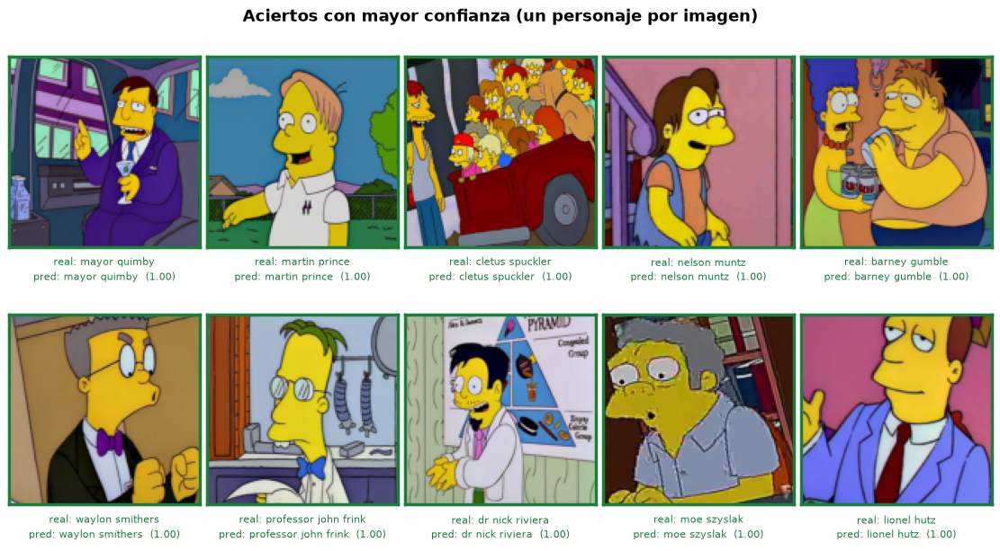

Aciertos totales: 5272 de 7058 (74.7%)
Confianza media en los aciertos: 0.756


In [66]:
def mostrar_ejemplos(indices, titulo, filas=2, columnas=5):
    """Dibuja una rejilla de imágenes de test con su etiqueta real, la predicha y la confianza."""
    indices = list(indices)
    figura, ejes = plt.subplots(
        filas,
        columnas,
        figsize=(2.2 * columnas, 3.0 * filas),
        layout="constrained",
    )
    ejes = np.ravel(ejes)

    for eje, indice in zip(ejes, indices):
        real = clases[y_test_idx[indice]].replace("_", " ")
        predicho = clases[predicciones_test[indice]].replace("_", " ")
        color = color_resultado(indice)

        eje.imshow(imagenes_test[indice])
        eje.set_xticks([])
        eje.set_yticks([])
        # Marco de color: verde si acertó, ámbar si nombró a otro personaje de la escena, rojo si falló
        for lado in eje.spines.values():
            lado.set_edgecolor(color)
            lado.set_linewidth(2.5)

        # Las etiquetas van debajo de la imagen para que no invadan la fila superior
        eje.set_xlabel(
            f"real: {real}\npred: {predicho}  ({confianza_test[indice]:.2f})"
            + (f"\n{rotulo_escena(indice)}" if color == COLOR_ESCENA else ""),
            fontsize=8,
            color=color,
            labelpad=6,
            linespacing=1.5,
        )

    for eje in ejes[len(indices):]:
        eje.axis("off")

    figura.suptitle(titulo, fontsize=13, fontweight="bold")
    plt.show()


aciertos = np.flatnonzero(acierto_test)
# Aciertos con mayor confianza, sin repetir personaje, para ver variedad de clases
aciertos_ordenados = aciertos[np.argsort(-confianza_test[aciertos])]
vistos = set()
seleccion_aciertos = []
for indice in aciertos_ordenados:
    personaje = y_test_eval[indice]
    if personaje not in vistos:
        vistos.add(personaje)
        seleccion_aciertos.append(indice)
    if len(seleccion_aciertos) == 10:
        break

mostrar_ejemplos(seleccion_aciertos, "Aciertos con mayor confianza (un personaje por imagen)")

print(f"Aciertos totales: {len(aciertos)} de {len(y_test_idx)} ({len(aciertos) / len(y_test_idx):.1%})")
print(f"Confianza media en los aciertos: {confianza_test[aciertos].mean():.3f}")

**Qué está aprovechando el modelo.** Los aciertos más seguros, todos con una confianza de 1,00 redondeada,
muestran lo que el MLP no podía hacer: reconocer a un personaje por su forma. Aparecen Quimby, Martin Prince,
Nelson, Smithers, Frink, el doctor Nick, Moe y Lionel Hutz, que comparten la piel amarilla con la familia Simpson;
Cletus, pequeño, en el borde de una multitud, y Barney junto a Marge. El MLP, con histogramas de color, acertaba con
más seguridad en los planos donde el personaje llenaba la imagen y su paleta era única; la CNN acierta aunque el
personaje comparta colores, sea pequeño o esté acompañado, porque reconoce el peinado, la ropa y los rasgos de la
cara.

### Ejemplos mal clasificados

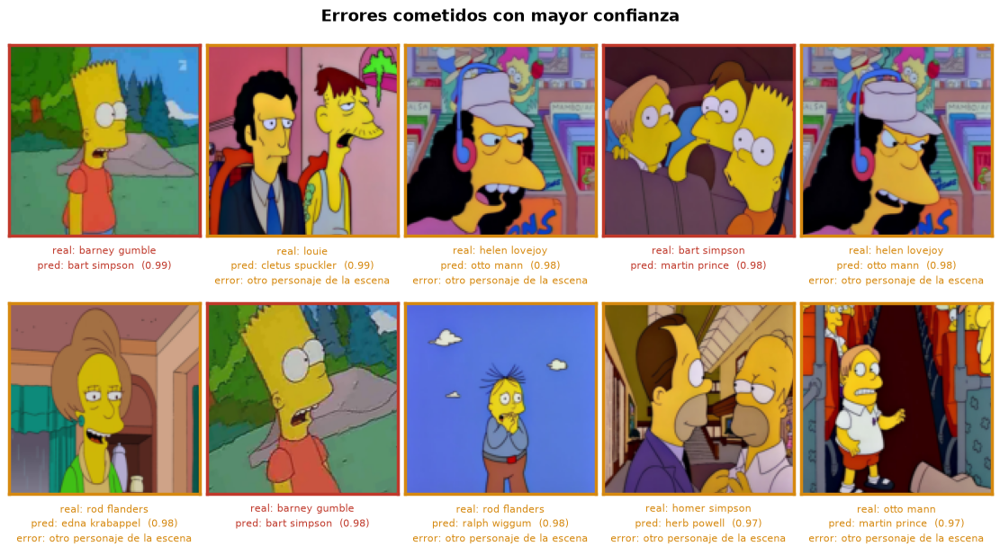

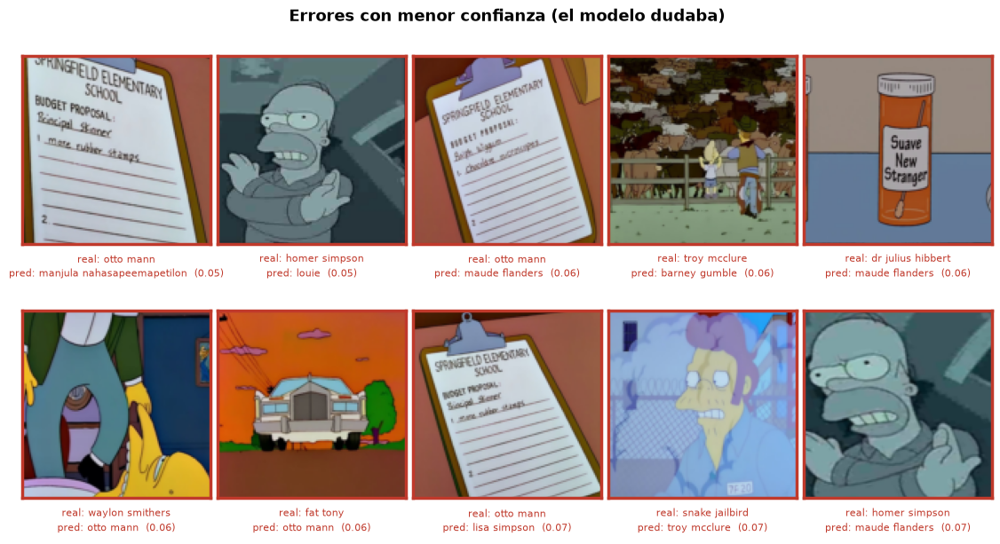

,Indicador,Valor,Detalle
0,Errores totales,1786.000,25.3% del test
1,Confianza media en aciertos,0.756,
2,Confianza media en errores,0.384,
3,Errores con confianza > 0.90,40.000,2.2% de los errores
4,Errores que nombran a otro personaje de la escena,542.000,30.3% de los errores (referencia)


In [67]:
# Errores según el criterio de acierto: el modelo no nombró al personaje de la carpeta
errores = np.flatnonzero(~acierto_test)

# Los errores más graves: equivocaciones cometidas con la mayor confianza
errores_confiados = errores[np.argsort(-confianza_test[errores])][:50]
mostrar_ejemplos(errores_confiados, "Errores cometidos con mayor confianza")

# Errores con baja confianza: el modelo tampoco sabía
errores_dudosos = errores[np.argsort(confianza_test[errores])][:10]
mostrar_ejemplos(errores_dudosos, "Errores con menor confianza (el modelo dudaba)")

resumen_errores = pd.DataFrame(
    [
        ("Errores totales", len(errores), f"{len(errores) / len(y_test_idx):.1%} del test"),
        ("Confianza media en aciertos", round(float(confianza_test[aciertos].mean()), 3), ""),
        ("Confianza media en errores", round(float(confianza_test[errores].mean()), 3), ""),
        (
            "Errores con confianza > 0.90",
            int((confianza_test[errores] > 0.90).sum()),
            f"{(confianza_test[errores] > 0.90).mean():.1%} de los errores",
        ),
        (
            "Errores que nombran a otro personaje de la escena",
            int(acierto_por_escena[errores].sum()),
            f"{acierto_por_escena[errores].mean():.1%} de los errores (referencia)" if len(errores) else "",
        ),
    ],
    columns=["Indicador", "Valor", "Detalle"],
)
display(resumen_errores)

**Dos tipos de error muy distintos.** La confianza separa bien aciertos de errores: es de 0,76 en los
aciertos y de 0,38 en los errores, y solo 40 de los 1.786 errores superan 0,90. Las predicciones con confianza
baja son las que conviene mandar a revisión humana.

Los **errores con confianza alta** (más de 0,80) son 104, el 1,5 % del test, y la galería muestra que casi todos
son aciertos que el criterio no alcanza a reconocer. En las diez imágenes de la figura sale el personaje que
nombra el modelo. En siete, la escena del episodio o las gemelas lo confirman (marco ámbar): Cletus junto a Louie,
Otto en dos imágenes de la carpeta de Helen Lovejoy, Edna Krabappel y Ralph Wiggum en dos de la de Rod Flanders,
Herb Powell junto a Homero y Martin Prince en una de Otto. En las otras tres (marco rojo) la escena no lo detectó:
dos imágenes de la carpeta de Barney en las que solo se ve a Bart, y una de Bart en la que aparece junto a otro
niño, que el modelo toma por Martin Prince. Varias de estas imágenes ni siquiera muestran al personaje de su
carpeta: son **ruido en las etiquetas** del dataset, y la accuracy es, por eso, una cota inferior de lo que acierta
la red. La CNN comete además bastantes menos errores confiados que el MLP entrenado con las mismas imágenes (104
frente a 261).

Los **errores con baja confianza** son imágenes difíciles o sin personaje: tres veces la misma hoja de un
presupuesto escolar en la carpeta de Otto, un frasco de pastillas en la del doctor Hibbert, un auto en la de Fat
Tony, Homero en blanco y negro, Troy McClure diminuto entre una manada de vacas y Smithers casi fuera del encuadre.
Ahí la confianza baja es la respuesta correcta: el modelo no sabe, y lo dice.

### Confusiones más frecuentes y posibles causas

,real,predicho,casos,% de la clase real,n_train_real,n_train_predicho
0,selma_bouvier,patty_bouvier,59,46.8,860,809
1,chief_wiggum,lou,38,20.5,1291,659
2,dolph_starbeam,jimbo_jones,21,37.5,371,637
3,lenny_leonard,carl_carlson,19,21.6,655,884
4,kearney_zzyzwicz,jimbo_jones,17,23.9,463,637
5,louie,fat_tony,16,20.8,500,1002
6,kearney_zzyzwicz,dolph_starbeam,15,21.1,463,371
7,apu_nahasapeemapetilon,manjula_nahasapeemapetilon,15,16.0,702,515
8,fat_tony,louie,13,8.8,1002,500
9,rod_flanders,todd_flanders,13,16.2,535,286


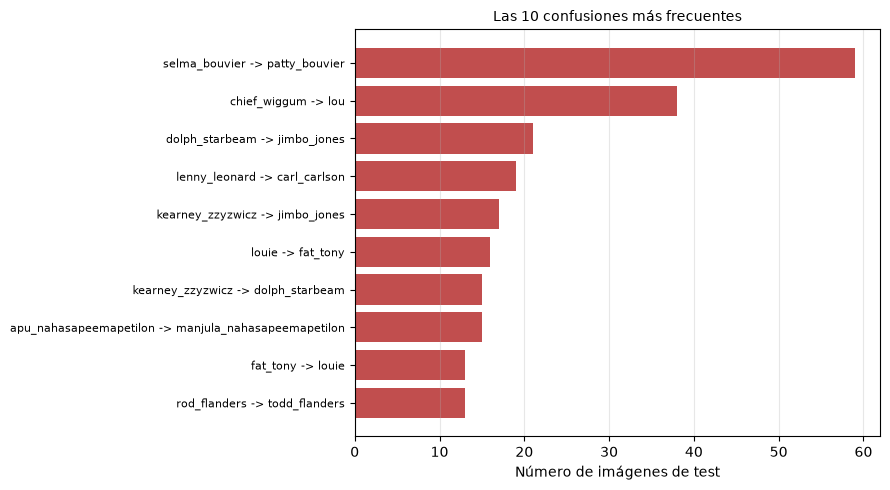

Clases que más absorben errores de otras (el modelo las usa como respuesta por defecto):
  patty_bouvier: 59 imagenes de otras clases predichas como esta
  lou: 38 imagenes de otras clases predichas como esta
  jimbo_jones: 38 imagenes de otras clases predichas como esta
  dolph_starbeam: 26 imagenes de otras clases predichas como esta
  carl_carlson: 19 imagenes de otras clases predichas como esta


In [68]:
# Pares (clase real, clase predicha) más frecuentes, excluyendo la diagonal
pares = []
for real in range(NUMERO_CLASES):
    for predicho in range(NUMERO_CLASES):
        if real != predicho and matriz[real, predicho] > 0:
            pares.append(
                {
                    "real": clases[real],
                    "predicho": clases[predicho],
                    "casos": int(matriz[real, predicho]),
                    "% de la clase real": round(float(matriz_normalizada[real, predicho]) * 100, 1),
                    "n_train_real": int(conteos_train[real]),
                    "n_train_predicho": int(conteos_train[predicho]),
                }
            )

confusiones = pd.DataFrame(pares).sort_values("casos", ascending=False, ignore_index=True).head(15)
display(confusiones)

figura, eje = plt.subplots(figsize=(9, 5))
etiquetas_pares = confusiones.head(10).apply(
    lambda fila: f"{fila['real']} -> {fila['predicho']}", axis=1
)
eje.barh(etiquetas_pares[::-1], confusiones.head(10)["casos"][::-1], color="firebrick", alpha=0.8)
eje.set_xlabel("Número de imágenes de test")
eje.set_title("Las 10 confusiones más frecuentes", fontsize=10)
eje.tick_params(axis="y", labelsize=8)
eje.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

destino_frecuente = confusiones.groupby("predicho")["casos"].sum().sort_values(ascending=False)
print("Clases que más absorben errores de otras (el modelo las usa como respuesta por defecto):")
for personaje, casos in destino_frecuente.head(5).items():
    print(f"  {personaje}: {casos} imagenes de otras clases predichas como esta")

**Causas detrás de las confusiones.** Las confusiones que quedan son de personajes que se parecen de verdad
o que comparten escena:

- **Personajes dibujados casi iguales.** Selma se predice como Patty en el 46,8 % de los casos (59 imágenes): son
  gemelas, con el mismo diseño, y el modelo se inclina hacia Patty. Carl y Lenny (Lenny como Carl en el 21,6 %) y
  Rod y Todd Flanders (Rod como Todd en el 16,2 %) son variaciones de un mismo dibujo.
- **Grupos que salen juntos.** Jimbo, Dolph y Kearney, los tres matones de la escuela, se confunden entre sí: Dolph
  como Jimbo en el 37,5 % de sus imágenes, Kearney como Jimbo en el 23,9 % y como Dolph en el 21,1 %. Wiggum se
  predice como Lou en el 20,5 % de los casos (38 imágenes), Louie como Fat Tony en el 20,8 % y Apu como Manjula en
  el 16,0 %. Con el criterio de la carpeta son errores aunque el personaje predicho esté en la imagen (ver «Escenas
  con varios personajes: errores que nombran a otro personaje»).
- **La familia ya no es el problema.** La única confusión de la familia entre las quince más frecuentes es Bart
  como Martin Prince (5,0 %). Homero ya no es destino de errores: lo son Patty (59 imágenes entre los pares de la
  tabla), Lou y Jimbo (38 cada uno) y Dolph (26), los compañeros de escena de los personajes que más fallan.

### Escenas con varios personajes: errores que nombran a otro personaje (referencia)

Con el criterio de la carpeta, nombrar a otro personaje es un error aunque ese personaje esté en la escena.
Esta sección separa esos errores de los demás, como referencia: la imagen completa puede mostrar a varios
personajes, y la escena (±3 s) o las gemelas dicen si el personaje que nombró el modelo estaba en el fotograma.
La accuracy por escena suma estos casos a los aciertos.

La escena se estima con una ventana de tiempo y no con una anotación manual: un corte de cámara dentro de la
ventana puede dar por presente a alguien que no sale en el encuadre. Las gemelas son más seguras, porque son la
misma imagen guardada en dos carpetas. La galería permite comprobarlo a ojo.

,Indicador,Valor,Detalle
0,Imágenes de test,7058.0000,
1,con otro personaje presente (escena o gemela),1674.0000,23.7% del test
2,Errores: no nombra al personaje de la carpeta,1786.0000,25.3% del test
3,que nombran a otro personaje presente,542.0000,30.3% de los errores
4,Accuracy (personaje de la carpeta),0.7470,
5,Accuracy por escena (referencia),0.8237,+0.0768
6,Accuracy en imágenes con otro personaje presente,0.5072,
7,Accuracy en el resto del test,0.8215,


,carpeta,predicho,casos
0,chief_wiggum,lou,35
1,selma_bouvier,patty_bouvier,33
2,lenny_leonard,carl_carlson,16
3,apu_nahasapeemapetilon,manjula_nahasapeemapetilon,13
4,louie,fat_tony,12
5,dolph_starbeam,jimbo_jones,11
6,kearney_zzyzwicz,jimbo_jones,11
7,ned_flanders,rod_flanders,11
8,fat_tony,louie,9
9,rod_flanders,todd_flanders,9


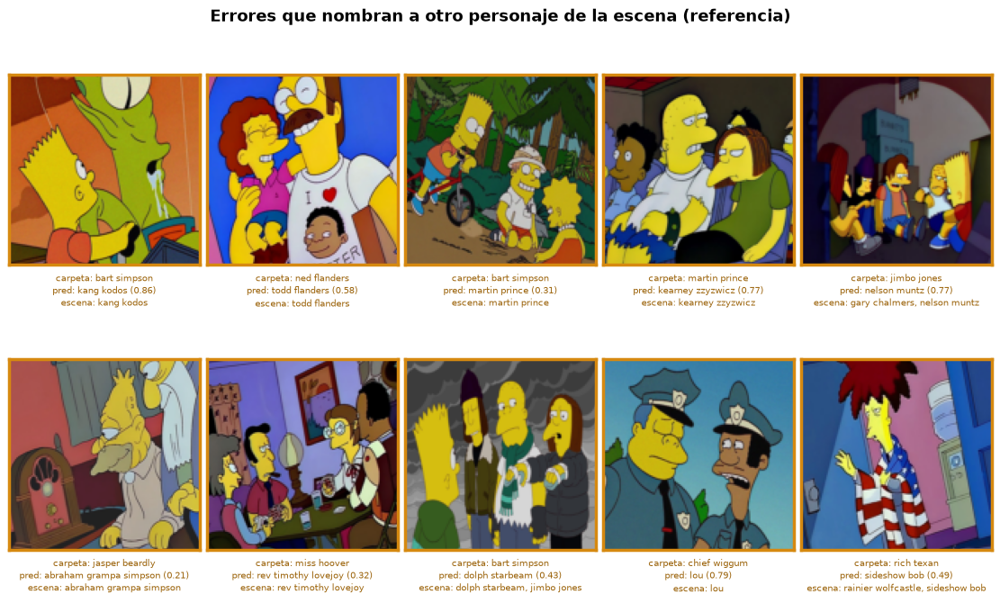

In [69]:
# Errores que nombran a otro personaje de la escena (referencia): el criterio de acierto ya se aplicó en la
# evaluación (acierto_estricto); aquí solo se separan esos errores de los demás
nombres_predichos = [clases[indice] for indice in predicciones_test]
con_escena_test = np.array([bool(presentes) for presentes in acompanantes_test])
errores_escena = np.flatnonzero(acierto_por_escena)
distintos_de_carpeta = int((~acierto_estricto).sum())


def proporcion(valores):
    """Media de una máscara booleana redondeada a cuatro decimales, o NaN si está vacía."""
    return round(float(valores.mean()), 4) if len(valores) else np.nan


resumen_escena_test = pd.DataFrame(
    [
        ("Imágenes de test", len(y_test_idx), ""),
        (
            "   con otro personaje presente (escena o gemela)",
            int(con_escena_test.sum()),
            f"{con_escena_test.mean():.1%} del test",
        ),
        (
            "Errores: no nombra al personaje de la carpeta",
            distintos_de_carpeta,
            f"{distintos_de_carpeta / len(y_test_idx):.1%} del test",
        ),
        (
            "   que nombran a otro personaje presente",
            len(errores_escena),
            f"{len(errores_escena) / max(distintos_de_carpeta, 1):.1%} de los errores",
        ),
        ("Accuracy (personaje de la carpeta)", round(accuracy_test, 4), ""),
        (
            "Accuracy por escena (referencia)",
            round(accuracy_por_escena_test, 4),
            f"{accuracy_por_escena_test - accuracy_test:+.4f}",
        ),
        ("Accuracy en imágenes con otro personaje presente", proporcion(acierto_estricto[con_escena_test]), ""),
        ("Accuracy en el resto del test", proporcion(acierto_estricto[~con_escena_test]), ""),
    ],
    columns=["Indicador", "Valor", "Detalle"],
)
display(resumen_escena_test)

pares_en_escena = (
    pd.DataFrame(
        {
            "carpeta": [clases[y_test_idx[indice]] for indice in errores_escena],
            "predicho": [nombres_predichos[indice] for indice in errores_escena],
        }
    )
    .value_counts()
    .head(10)
    .reset_index(name="casos")
)
display(pares_en_escena)

if len(errores_escena):
    generador = np.random.default_rng(SEMILLA)
    muestra_escena = generador.choice(errores_escena, size=min(10, len(errores_escena)), replace=False)
    figura, ejes = plt.subplots(2, 5, figsize=(11, 6.6), layout="constrained")
    ejes = np.ravel(ejes)
    for eje, indice in zip(ejes, muestra_escena):
        eje.imshow(imagenes_test[indice])
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in eje.spines.values():
            lado.set_edgecolor(COLOR_ESCENA)
            lado.set_linewidth(2.5)
        escena_visible = sorted(acompanantes_test[indice])
        resto = f" +{len(escena_visible) - 2}" if len(escena_visible) > 2 else ""
        eje.set_xlabel(
            f"carpeta: {clases[y_test_idx[indice]].replace('_', ' ')}\n"
            f"pred: {nombres_predichos[indice].replace('_', ' ')} ({confianza_test[indice]:.2f})\n"
            f"escena: {', '.join(n.replace('_', ' ') for n in escena_visible[:2])}{resto}",
            fontsize=7,
            color="#9c640c",
            labelpad=6,
            linespacing=1.4,
        )
    for eje in ejes[len(muestra_escena):]:
        eje.axis("off")
    figura.suptitle(
        "Errores que nombran a otro personaje de la escena (referencia)", fontsize=13, fontweight="bold"
    )
    plt.show()

**Lectura.** Con la imagen completa, una parte grande de los errores es el otro personaje de la escena: de los
1.786 errores, 542 (el 30,3 %) nombran a un personaje que la escena o las gemelas dan por presente. El 23,7 % del
test tiene a otro personaje presente, y ahí la accuracy cae a 0,507, frente a 0,822 en el resto: casi la mitad de
los errores (unos 825 de 1.786) está en esas imágenes. Los pares que más se repiten son los de personajes que salen
pegados en el mismo plano —Wiggum y Lou (35), Selma y Patty (33), Lenny y Carl (16), Apu y Manjula (13), Louie y Fat
Tony (12)—. Es lo que resuelve el script de cajas después del entrenamiento, al nombrar a cada personaje en su
propia caja.

### Originales, parecidas y alteradas en test

El test tiene las mismas condiciones que el entrenamiento: originales sin transformar, versiones filtradas
de las imágenes casi idénticas a otra (parecidas) y variantes alteradas de un cuarto de las originales.
Esta tabla mide el modelo por separado en cada tipo:

- **Originales.** Las imágenes tal como están en el dataset. Es la fila comparable con las corridas
  anteriores, cuyo test no tenía alteradas.
- **Parecidas.** Antes del filtro, las imágenes de test con una gemela casi idéntica en entrenamiento se
  acertaban en torno al 95 % de las veces, frente a un 53 % del resto. Si las versiones filtradas se siguen
  acertando mucho más que las originales, el modelo reconoce la escena a pesar del filtro.
- **Alteradas.** Miden si el modelo resiste el giro, el cambio de color y el filtro de textura con los
  que aprendió.

In [70]:
es_alterada_test = datos_test["alterada"].to_numpy()
es_parecida_test = datos_test["parecida"].to_numpy()
es_original_test = ~es_alterada_test & ~es_parecida_test

resumen_tipos_test = pd.DataFrame(
    [
        (
            nombre,
            int(mascara.sum()),
            proporcion(acierto_test[mascara]),
            proporcion((acierto_test | acierto_por_escena)[mascara]),
            proporcion(top3_por_imagen[mascara]),
        )
        for nombre, mascara in (
            ("Original, sin transformar", es_original_test),
            ("Parecida: versión filtrada de una casi idéntica a otra", es_parecida_test),
            ("Alterada: variante de una original de test", es_alterada_test),
        )
    ],
    columns=["Imágenes de test", "n", "accuracy", "accuracy por escena (referencia)", "top-3"],
)
display(resumen_tipos_test)
accuracy_originales_test, accuracy_parecidas_test, accuracy_alteradas_test = resumen_tipos_test["accuracy"]

,Imágenes de test,n,accuracy,accuracy por escena (referencia),top-3
0,"Original, sin transformar",4803,0.7533,0.8239,0.8901
1,Parecida: versión filtrada de una casi idéntic...,865,0.7711,0.8832,0.9434
2,Alterada: variante de una original de test,1390,0.7101,0.7863,0.8633


**Lectura.** El orden es el mismo del MLP —parecidas por encima, alteradas por debajo—, pero las
distancias son más cortas:

- **Alteradas: 4,3 puntos por debajo de las originales** (0,710 frente a 0,753), frente a 8,7 en el MLP. El giro,
  el cambio de color y el filtro de textura cuestan algo, aunque el modelo final se entrenó además con un aumento
  en línea.
- **Parecidas: 1,8 puntos por encima** (0,771), frente a los 6,3 del MLP. La CNN casi no depende de haber visto
  una toma parecida: reconoce al personaje y no la paleta de la toma.

La fila de **originales** (0,753 de accuracy) es la medida más limpia del modelo, y queda 0,6 puntos por encima
de la global.

### Fortalezas y debilidades del modelo

In [71]:
segundos_por_epoca_base = float(globals().get("segundos_entrenamiento_base", np.nan)) / len(
    historial_base.history["loss"]
)
sintesis = pd.DataFrame(
    [
        (
            "Fortaleza",
            "Supera con holgura los baselines",
            f"accuracy {accuracy_test:.3f} frente a {baseline_azar:.3f} (azar) y {baseline_mayoritaria:.3f} (clase mayoritaria)",
        ),
        (
            "Fortaleza",
            "Buena señal en el top-3",
            f"top-3 accuracy {top3_test:.3f}: la clase correcta suele estar entre las candidatas",
        ),
        (
            "Fortaleza",
            "Reconoce con solidez a los personajes principales",
            f"{len(clases_fuertes)} clases con F1 >= 0.60",
        ),
        (
            "Fortaleza",
            "La confianza es informativa",
            f"confianza media {confianza_test[aciertos].mean():.2f} en aciertos y "
            f"{confianza_test[errores].mean():.2f} en errores",
        ),
        (
            "Fortaleza",
            "Aprende sus propios filtros con pocos parámetros",
            f"{modelo_final.count_params():,} parametros para {len(X_train):,} imagenes de entrenamiento",
        ),
        (
            "Debilidad",
            "Desempeño desigual entre clases",
            f"brecha accuracy - F1 macro = {brecha_metricas:.3f}; {len(clases_debiles)} clases con F1 < 0.30",
        ),
        (
            "Debilidad",
            "Depende del volumen de datos por clase",
            f"correlacion entre n_train y F1 por clase = {correlacion:.2f}",
        ),
        (
            "Debilidad",
            "Resolución de trabajo baja",
            f"a {ALTO_OBJETIVO}x{ANCHO_OBJETIVO} los personajes pequeños en el encuadre ocupan pocos pixeles",
        ),
        (
            "Debilidad",
            "Entrenada desde cero",
            "los filtros salen solo de este dataset; una red preentrenada partiria de filtros ya aprendidos",
        ),
        (
            "Debilidad",
            "No siempre mira al personaje",
            f"en los errores, {centro_test[~acierto_test].mean():.0%} de Grad-CAM cae en la mitad central"
            f" (aciertos: {centro_test[acierto_test].mean():.0%})",
        ),
        (
            "Debilidad",
            "Costo de entrenamiento",
            f"{segundos_por_epoca_base:.1f} s por epoca del modelo base en {DISPOSITIVO}",
        ),
    ],
    columns=["Tipo", "Aspecto", "Evidencia"],
)

display(sintesis)

,Tipo,Aspecto,Evidencia
0,Fortaleza,Supera con holgura los baselines,accuracy 0.747 frente a 0.016 (azar) y 0.055 (...
1,Fortaleza,Buena señal en el top-3,top-3 accuracy 0.891: la clase correcta suele ...
2,Fortaleza,Reconoce con solidez a los personajes principales,51 clases con F1 >= 0.60
3,Fortaleza,La confianza es informativa,confianza media 0.76 en aciertos y 0.38 en err...
4,Fortaleza,Aprende sus propios filtros con pocos parámetros,"473,120 parametros para 49,625 imagenes de ent..."
5,Debilidad,Desempeño desigual entre clases,brecha accuracy - F1 macro = 0.016; 0 clases c...
6,Debilidad,Depende del volumen de datos por clase,correlacion entre n_train y F1 por clase = 0.21
7,Debilidad,Resolución de trabajo baja,a 128x128 los personajes pequeños en el encuad...
8,Debilidad,Entrenada desde cero,los filtros salen solo de este dataset; una re...
9,Debilidad,No siempre mira al personaje,"en los errores, 41% de Grad-CAM cae en la mita..."


**Síntesis.** La CNN resuelve lo que el MLP no podía: reconocer a los personajes por su forma. Con el mismo
proceso, los mismos datos y la misma resolución (128 × 128), sube la accuracy de test de 0,544 a 0,747 y el
F1 macro de 0,551 a 0,731, con una ROC-AUC macro de 0,986, y cumple los cinco KPIs con margen y sin ningún personaje
por debajo de 0,30 de F1. Lo que queda son personajes dibujados casi iguales o que salen casi siempre juntos
—Patty y Selma, Rod y Todd, Jimbo, Dolph y Kearney, Louie y Fat Tony—, imágenes cuya carpeta no corresponde al
personaje que muestran, y escenas con varios personajes que el criterio de la carpeta cuenta como error. Sus
límites son ahora de datos y de costo: el aumento en línea bajó la brecha del modelo base (0,198) casi a cero, pero
el entrenamiento es 26 veces más caro que el del MLP.

## Resumen de rendimiento de la corrida en la GPU

Esta sección no añade nada al modelo: mide **cuánto costó obtenerlo** en la RTX 4060 Laptop. Las
secciones anteriores responden qué tan bien clasifica la red; esta responde cuánto tardó cada etapa y cuánto
de la tarjeta se aprovechó.

Se reportan tres cosas:

1. **El entorno y las marcas de tiempo.** El dispositivo que ejecutó realmente las operaciones, con su
   nombre, el sistema operativo y la versión del framework, además de la resolución de entrada, la **fecha y
   hora de inicio** de la corrida (la fija la primera celda del notebook), la **hora de término** y la
   duración total. Es el dato que da sentido a todos los tiempos.
2. **Los tiempos de la corrida.** Segundos y segundos por época de cada configuración entrenada, más un
   *benchmark* corto de tres épocas sobre la arquitectura base y una medición de inferencia sobre el
   conjunto de test. El benchmark existe porque los tiempos de las secciones anteriores no son
   comparables entre sí: la parada temprana hace que cada configuración corra un número distinto de
   épocas. Entrenar unas pocas épocas con la misma arquitectura, el mismo batch y sin *callbacks* sí da
   una cifra homogénea. De esas épocas se descarta la primera, que incluye la compilación del grafo y el
   traslado inicial de los datos a la tarjeta. Un barrido de tamaño de lote mide además cuánto margen
   queda en la GPU a batch 128.
3. **El resumen de la corrida.** Se guarda en
   `../resultados/newDataset/GPU/rendimiento_gpu_128x128.json`, con las mismas claves que el del
   MLP, para comparar las dos redes cifra a cifra. Cada corrida reemplaza el archivo de la anterior: la
   del 19-10-2026 queda en el historial de Git y resumida al final del notebook.

Conviene recordar al leer las cifras que una CNN es, sobre todo, convoluciones: la misma operación
repetida en todas las posiciones de la imagen, exactamente el tipo de cálculo que una GPU paraleliza
bien. A diferencia del MLP sobre descriptores, aquí el cómputo crece con el número de píxeles, así que a
128 × 128 la tarjeta trabaja casi todo el tiempo. La sección siguiente compara esta corrida con la del MLP, y un
anexo al final del notebook la compara con la corrida del 19-10-2026.

In [72]:
# Resumen de rendimiento de la corrida en la GPU: entorno de ejecución, marcas de tiempo,
# tiempos y métricas finales. Se guarda en
# ../resultados/newDataset/GPU/rendimiento_gpu_128x128.json.
import json
import platform
import subprocess
import threading
import time
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import keras

DIRECTORIO_RESULTADOS = Path("../resultados/newDataset")
DIRECTORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

# La resolución de entrada forma parte del nombre del archivo.
RESOLUCION = f"{ALTO_OBJETIVO}x{ANCHO_OBJETIVO}"

# La marca de inicio la fija la primera celda del notebook; si esa celda no se
# ejecutó en esta sesión, se toma el arranque de esta sección como referencia.
INICIO_CORRIDA = globals().get("INICIO_CORRIDA") or datetime.now()

# Re-entrena unas pocas épocas para medir un tiempo por época comparable entre
# corridas (misma arquitectura, mismo batch, sin parada temprana). False para omitirlo.
EJECUTAR_BENCHMARK = True
EPOCAS_BENCHMARK = 3

# Barrido de tamaño de lote: evidencia de cuánta GPU queda sin usar a batch 128.
# No cambia la configuración del estudio, solo la mide.
MEDIR_ESCALADO_BATCH = True
BATCHES_A_MEDIR = (128, 256, 512, 1024, 2048)

# --- 1. Entorno de ejecución -------------------------------------------------
def describir_cpu():
    """Nombre del procesador, en Windows y en Linux."""
    if platform.system() == "Windows":
        try:
            nombre = subprocess.run(
                ["wmic", "cpu", "get", "name"], capture_output=True, text=True, timeout=10
            ).stdout.strip().splitlines()
            if len(nombre) > 1 and nombre[1].strip():
                return nombre[1].strip()
        except (OSError, subprocess.SubprocessError):
            pass
        return platform.processor() or platform.machine()
    try:
        for linea in Path("/proc/cpuinfo").read_text().splitlines():
            if linea.startswith("model name"):
                return linea.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()


def describir_gpu():
    """Nombre comercial y capacidad de cómputo de la GPU que ve PyTorch."""
    mayor, menor = torch.cuda.get_device_capability(0)
    return f"{torch.cuda.get_device_name(0)} (CC {mayor}.{menor})"


usa_gpu = torch.cuda.is_available()
ENTORNO = "GPU" if usa_gpu else "CPU"
dispositivo = describir_gpu() if usa_gpu else describir_cpu()

entorno = pd.DataFrame(
    [
        ("Entorno", ENTORNO),
        ("Modelo", "Red neuronal convolucional (CNN)"),
        ("Dispositivo de cómputo", dispositivo),
        ("CPU del equipo", describir_cpu()),
        ("GPUs visibles para PyTorch", torch.cuda.device_count()),
        ("Sistema operativo", f"{platform.system()} {platform.release()}"),
        ("Python", platform.python_version()),
        ("Framework", f"Keras {keras.__version__} sobre PyTorch {torch.__version__}"),
        ("Resolución de trabajo", RESOLUCION),
        ("Entrada del modelo base", f"imagen {RESOLUCION}x3 ({REPRESENTACION_BASE})"),
        ("Entrada del modelo final", f"imagen {RESOLUCION}x3 ({representacion_final})"),
        ("Arquitectura del modelo final", arquitectura_final),
        ("Inicio de la corrida", INICIO_CORRIDA.strftime("%Y-%m-%d %H:%M:%S")),
    ],
    columns=["Concepto", "Valor"],
)
display(entorno)


# --- 2. Tiempos de entrenamiento --------------------------------------------
# El tiempo del modelo base lo mide la celda de entrenamiento; si esa celda no se
# volvió a ejecutar, queda como desconocido en lugar de inventar un valor.
segundos_base = float(globals().get("segundos_entrenamiento_base", np.nan))
epocas_base = len(historial_base.history["loss"])

tiempos = tabla_experimentos[["experimento", "epocas", "parametros", "segundos"]].copy()
# El modelo base entra en la tabla de experimentos sin tiempo: se completa aquí
tiempos.loc[tiempos["experimento"].str.startswith("Base"), "segundos"] = segundos_base
tiempos["segundos_por_epoca"] = (tiempos["segundos"] / tiempos["epocas"]).round(2)
tiempos["imagenes_por_segundo"] = (
    len(X_train) * tiempos["epocas"] / tiempos["segundos"]
).round(0)

display(tiempos)

segundos_experimentos = float(
    tabla_experimentos.loc[
        ~tabla_experimentos["experimento"].str.startswith("Base"), "segundos"
    ].sum()
)
segundos_totales = float(np.nansum([segundos_base, segundos_experimentos]))
segundos_por_epoca_medio = float(tiempos["segundos_por_epoca"].mean(skipna=True))
epocas_totales = int(tiempos["epocas"].sum())


# --- 3. Benchmark comparable: entrenamiento e inferencia ---------------------
# Ventana mínima de muestreo. Una época puede durar 0,2 s: medir la utilización
# sobre una sola es leer ruido, así que se repiten épocas hasta cubrir este tiempo.
SEGUNDOS_MINIMOS_MUESTREO = 4.0
INTERVALO_MUESTREO = 0.05


class MuestreadorGPU(threading.Thread):
    """Lee nvidia-smi en paralelo para saber cuánto de la tarjeta se está usando.

    La utilización responde a "¿la GPU está ocupada o esperando?". Ojo: no mide
    potencia entregada. Una tarjeta limitada por consumo puede marcar 100 % y
    rendir la mitad, y dos implementaciones con la misma utilización pueden
    diferir en velocidad si una desperdicia más tiempo dentro de cada paso.
    """

    def __init__(self, intervalo=INTERVALO_MUESTREO):
        """Hilo en segundo plano que lee nvidia-smi cada `intervalo` segundos hasta que se activa `parar`."""
        super().__init__(daemon=True)
        self.parar = threading.Event()
        self.intervalo = intervalo
        self.muestras = []

    def run(self):
        """Guarda (utilización, potencia, reloj) en cada lectura; ignora las que fallan."""
        while not self.parar.is_set():
            try:
                salida = subprocess.run(
                    ["nvidia-smi",
                     "--query-gpu=utilization.gpu,power.draw,clocks.sm",
                     "--format=csv,noheader,nounits"],
                    capture_output=True, text=True, timeout=5,
                ).stdout.strip()
                self.muestras.append(tuple(float(v) for v in salida.split(",")))
            except Exception:
                pass
            time.sleep(self.intervalo)

    def resumen(self):
        """Media sobre la ventana muestreada, con el número de muestras.

        No se descartan lecturas bajas: filtrar por "utilizacion > 5" sesgaría la
        media justo en los casos que interesan, los de tarjeta infrautilizada.
        """
        if len(self.muestras) < 5:
            return {"muestras_utilizacion": len(self.muestras)}
        util, potencia, reloj = (np.array(v) for v in zip(*self.muestras))
        return {
            "utilizacion_gpu_media": round(float(util.mean()), 1),
            "potencia_media_w": round(float(potencia.mean()), 1),
            "reloj_medio_mhz": round(float(reloj.mean())),
            "muestras_utilizacion": len(util),
        }


def cronometrar_epocas(modelo, X, y, batch, epocas, muestrear=False):
    """Entrena `epocas` épocas seguidas y devuelve el tiempo medio por época.

    Se descarta la primera: incluye la reserva de memoria y el calentamiento de
    los kernels, que no se repiten en las siguientes.
    """
    optimizador = torch.optim.Adam(modelo.parameters(), lr=TASA_APRENDIZAJE,
                                   fused=(X.device.type == "cuda"))
    generador = torch.Generator(device=X.device)
    generador.manual_seed(SEMILLA)

    # Fase 1: cronometrar. Se descarta la primera epoca, que incluye la reserva
    # de memoria y el calentamiento de los kernels.
    duraciones = []
    for _ in range(epocas):
        inicio = time.perf_counter()
        _pasada(modelo, X, y, batch, True, optimizador, None, generador)
        if X.device.type == "cuda":
            torch.cuda.synchronize()
        duraciones.append(time.perf_counter() - inicio)
    utiles = duraciones[1:] or duraciones
    segundos_epoca = float(np.mean(utiles))

    # Fase 2: medir la utilizacion en una ventana aparte, lo bastante larga para
    # que el muestreo tenga sentido. Mezclarla con la fase 1 daba medias de dos o
    # tres lecturas cuando la epoca duraba decimas de segundo.
    estado = {}
    if muestrear:
        repeticiones = max(2, int(np.ceil(SEGUNDOS_MINIMOS_MUESTREO / max(segundos_epoca, 1e-6))))
        muestreador = MuestreadorGPU()
        muestreador.start()
        for _ in range(repeticiones):
            _pasada(modelo, X, y, batch, True, optimizador, None, generador)
        if X.device.type == "cuda":
            torch.cuda.synchronize()
        muestreador.parar.set()
        muestreador.join(timeout=2)
        estado = muestreador.resumen()

    return segundos_epoca, estado


benchmark_segundos_epoca = np.nan
estado_gpu = {}
memoria_por_imagen = None
if EJECUTAR_BENCHMARK:
    keras.utils.set_random_seed(SEMILLA)
    modelo_benchmark = construir_cnn(nombre="cnn_benchmark").to(DISPOSITIVO)
    # Memoria por imagen a batch TAMANO_BATCH: dice qué batches caben en el barrido de más abajo
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    memoria_previa = torch.cuda.memory_allocated()
    benchmark_segundos_epoca, estado_gpu = cronometrar_epocas(
        modelo_benchmark, X_train, y_train, TAMANO_BATCH, EPOCAS_BENCHMARK, muestrear=True
    )
    memoria_por_imagen = (torch.cuda.max_memory_allocated() - memoria_previa) / TAMANO_BATCH
    del modelo_benchmark
    torch.cuda.empty_cache()

# Inferencia sobre el conjunto de evaluación completo, tras una pasada de calentamiento
modelo_final.predict(X_test[:256], batch_size=256, verbose=0)
inicio_inferencia = time.perf_counter()
modelo_final.predict(X_test, batch_size=256, verbose=0)
segundos_inferencia = time.perf_counter() - inicio_inferencia

filas_benchmark = [
    (
        f"Entrenamiento: segundos por epoca (arquitectura base, batch {TAMANO_BATCH})",
        round(benchmark_segundos_epoca, 2) if EJECUTAR_BENCHMARK else "no ejecutado",
    ),
    (
        "Entrenamiento: imágenes por segundo",
        round(len(X_train) / benchmark_segundos_epoca) if EJECUTAR_BENCHMARK else "-",
    ),
    (
        f"Inferencia: segundos para las {len(X_test):,} imagenes de test",
        round(segundos_inferencia, 2),
    ),
    ("Inferencia: imágenes por segundo", round(len(X_test) / segundos_inferencia)),
]
for clave, etiqueta in (
    ("utilizacion_gpu_media", "GPU: utilización media durante el entrenamiento (%)"),
    ("potencia_media_w", "GPU: potencia media (W)"),
    ("reloj_medio_mhz", "GPU: reloj medio (MHz)"),
):
    if clave in estado_gpu:
        filas_benchmark.append((etiqueta, estado_gpu[clave]))

display(pd.DataFrame(filas_benchmark, columns=["Medicion", "Valor"]))


# --- 3b. Escalado del tamaño de lote ----------------------------------------
# A batch pequeño la GPU pasa más tiempo esperando instrucciones que calculando.
# Esta tabla lo cuantifica sin tocar la configuración con la que se entrenó.
escalado_batch = {}
if MEDIR_ESCALADO_BATCH:
    filas_escalado = []
    for tamano in BATCHES_A_MEDIR:
        # Una CNN necesita mucha más memoria por lote que el MLP. En Windows el driver no da un
        # error cuando la VRAM se llena: pasa a usar la RAM del equipo, todo se vuelve decenas de
        # veces más lento y la medición deja de tener sentido. Por eso se salta el batch cuya
        # memoria, proyectada desde la del benchmark, no cabe en la memoria libre de la tarjeta.
        torch.cuda.empty_cache()
        # El batch del estudio siempre se mide: con él se entrenó todo el notebook
        if (
            tamano != TAMANO_BATCH
            and memoria_por_imagen is not None
            and memoria_por_imagen * tamano * 1.1 > torch.cuda.mem_get_info()[0]
        ):
            filas_escalado.append({"batch": tamano, "segundos_por_epoca": "no cabe en la VRAM"})
            continue
        keras.utils.set_random_seed(SEMILLA)
        modelo_escalado = construir_cnn(nombre=f"cnn_batch_{tamano}").to(DISPOSITIVO)
        try:
            segundos, estado = cronometrar_epocas(
                modelo_escalado, X_train, y_train, tamano, 3, muestrear=True
            )
            escalado_batch[tamano] = round(len(X_train) / segundos, 1)
            filas_escalado.append({
                "batch": tamano,
                "segundos_por_epoca": round(segundos, 3),
                "imagenes_por_segundo": round(len(X_train) / segundos),
                "utilizacion_gpu_%": estado.get("utilizacion_gpu_media", "-"),
                "potencia_W": estado.get("potencia_media_w", "-"),
            })
        except torch.cuda.OutOfMemoryError:
            filas_escalado.append({"batch": tamano, "segundos_por_epoca": "sin VRAM"})
        del modelo_escalado
        torch.cuda.empty_cache()

    tabla_escalado = pd.DataFrame(filas_escalado)
    display(tabla_escalado)
    if len(escalado_batch) > 1:
        menor, mayor = min(escalado_batch), max(escalado_batch)
        print(
            f"De batch {menor} a batch {mayor} el rendimiento pasa de "
            f"{escalado_batch[menor]:,.0f} a {escalado_batch[mayor]:,.0f} imagenes/s "
            f"(x{escalado_batch[mayor] / escalado_batch[menor]:.1f}). El estudio se hace a "
            f"batch {TAMANO_BATCH} porque es el valor con el que se comparan las corridas; "
            f"esta tabla solo mide cuanto margen queda en la tarjeta."
        )


# --- 4. Resumen de la corrida ------------------------------------------------
# El término se marca aquí, después del benchmark y de la medición de inferencia:
# es el último trabajo real de la corrida.
FIN_CORRIDA = datetime.now()
duracion_corrida_segundos = (FIN_CORRIDA - INICIO_CORRIDA).total_seconds()
duracion_corrida = str(timedelta(seconds=round(duracion_corrida_segundos)))

def cuatro_decimales(valor):
    """Métrica redondeada; la de un subconjunto vacío queda como None (null en el JSON)."""
    return None if np.isnan(valor) else round(float(valor), 4)


resumen_corrida = {
    "modelo": "CNN",
    "entorno": ENTORNO,
    "dispositivo": dispositivo,
    "cpu": describir_cpu(),
    "sistema_operativo": f"{platform.system()} {platform.release()}",
    "framework": "PyTorch",
    "framework_version": torch.__version__,
    "keras": keras.__version__,
    "inicio_corrida": INICIO_CORRIDA.strftime("%Y-%m-%d %H:%M:%S"),
    "fin_corrida": FIN_CORRIDA.strftime("%Y-%m-%d %H:%M:%S"),
    "duracion_corrida": duracion_corrida,
    "duracion_corrida_segundos": round(duracion_corrida_segundos, 1),
    "resolucion": RESOLUCION,
    "dimension_entrada": int(DIMENSION_ENTRADA),
    "representacion_base": REPRESENTACION_BASE,
    "representacion_final": representacion_final,
    "dimension_entrada_final": int(DIMENSIONES[representacion_final]),
    "personajes": int(NUMERO_CLASES),
    "proporciones_train_val_test": " / ".join(f"{PROPORCIONES[nombre]:.0%}" for nombre in CONJUNTOS),
    "esquema_pesos": ESQUEMA_PESOS,
    "suavizado_etiquetas": SUAVIZADO_ETIQUETAS,
    "entrada": "imagen completa",
    "imagenes_train_alteradas": int(datos.loc[MASCARAS["train"], "alterada"].sum()),
    "imagenes_val_alteradas": int(datos.loc[MASCARAS["val"], "alterada"].sum()),
    "imagenes_test_alteradas": int(datos.loc[MASCARAS["test"], "alterada"].sum()),
    "imagenes_parecidas": int(datos["parecida"].sum()),
    "pares_gemelas": int(n_pares_gemelas),
    "segundos_carga_imagenes": round(segundos_carga, 1),
    # La CNN no calcula descriptores: su entrada son los pixeles
    "segundos_descriptores": 0.0,
    "imagenes_train": int(len(X_train)),
    "imagenes_val": int(len(X_val)),
    "imagenes_test": int(len(X_test)),
    "batch": int(TAMANO_BATCH),
    "configuracion_final": nombre_final,
    "arquitectura_final": arquitectura_final,
    "parametros_modelo_final": int(modelo_final.count_params()),
    "epocas_modelo_base": int(epocas_base),
    "segundos_modelo_base": None if np.isnan(segundos_base) else round(segundos_base, 1),
    "segundos_experimentos": round(segundos_experimentos, 1),
    "segundos_entrenamiento_total": round(segundos_totales, 1),
    "epocas_totales": epocas_totales,
    "segundos_por_epoca_medio": round(segundos_por_epoca_medio, 2),
    "benchmark_segundos_por_epoca": (
        None if np.isnan(benchmark_segundos_epoca) else round(benchmark_segundos_epoca, 2)
    ),
    "escalado_batch_imagenes_por_segundo": escalado_batch,
    "segundos_inferencia_test": round(segundos_inferencia, 2),
    "inferencia_imagenes_por_segundo": round(len(X_test) / segundos_inferencia, 1),
    "criterio_acierto": "personaje de la carpeta",
    "errores_confiados_test": int(((predicciones_test != y_test_idx) & (confianza_test > 0.80)).sum()),
    "accuracy_test": round(float(accuracy_test), 4),
    "accuracy_estricta_test": round(float(accuracy_estricta_test), 4),
    "top3_test": round(float(top3_test), 4),
    "accuracy_por_escena_test": round(accuracy_por_escena_test, 4),
    "accuracy_originales_test": cuatro_decimales(accuracy_originales_test),
    "accuracy_parecidas_test": cuatro_decimales(accuracy_parecidas_test),
    "accuracy_alteradas_test": cuatro_decimales(accuracy_alteradas_test),
    "f1_macro_test": round(float(f1_macro_test), 4),
    "f1_macro_estricto_test": round(float(f1_macro_estricto_test), 4),
    "f1_ponderado_test": round(float(f1_ponderado_test), 4),
    "perdida_test": round(float(perdida_test), 4),
    "roc_auc_macro_test": round(float(roc_auc_macro_test), 4),
    "roc_auc_ponderado_test": round(float(roc_auc_ponderado_test), 4),
    "brecha_train_val_base": round(float(brecha), 4),
    **estado_gpu,
}

# Una carpeta por entorno y un archivo por resolución:
# ../resultados/newDataset/GPU/rendimiento_gpu_128x128.json
directorio_entorno = DIRECTORIO_RESULTADOS / ENTORNO
directorio_entorno.mkdir(parents=True, exist_ok=True)
ruta_resumen = directorio_entorno / f"rendimiento_{ENTORNO.lower()}_{RESOLUCION}.json"
ruta_resumen.write_text(json.dumps(resumen_corrida, indent=2, ensure_ascii=False), encoding="utf-8")

display(
    pd.DataFrame(
        [
            (clave, valor if valor is not None else "desconocido")
            for clave, valor in resumen_corrida.items()
        ],
        columns=["Concepto", "Valor"],
    )
)
print(f"Resumen guardado en: {ruta_resumen.resolve()}")

,Concepto,Valor
0,Entorno,GPU
1,Modelo,Red neuronal convolucional (CNN)
2,Dispositivo de cómputo,NVIDIA GeForce RTX 4060 Laptop GPU (CC 8.9)
3,CPU del equipo,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
4,GPUs visibles para PyTorch,1
5,Sistema operativo,Windows 11
6,Python,3.13.15
7,Framework,Keras 3.15.1 sobre PyTorch 2.14.0+cu130
8,Resolución de trabajo,128x128
9,Entrada del modelo base,imagen 128x128x3 (rgb)


,experimento,epocas,parametros,segundos,segundos_por_epoca,imagenes_por_segundo
0,"Base - rgb, 4 bloques (32,64,128,256)",52,473120,2944.127309,56.62,876.0
1,R1 - escala de grises,35,472547,1994.000000,56.97,871.0
2,"E1 - 3 bloques (32,64,128)",35,144416,1808.800000,51.68,960.0
3,E3 - activación tanh,35,473120,2060.400000,58.87,843.0
4,E4 - learning rate 1e-4,35,473120,1990.300000,56.87,873.0
5,"E6 - dropout 0,5",35,473120,1989.100000,56.83,873.0
6,E7 - cabeza con aplanado,35,4601888,1993.100000,56.95,871.0
7,P1 - sin pesos por clase,35,473120,1986.600000,56.76,874.0
8,P2 - pesos balanceados,35,473120,1985.700000,56.73,875.0
9,S1 - sin suavizado,35,473120,1983.600000,56.67,876.0


,Medicion,Valor
0,Entrenamiento: segundos por epoca (arquitectur...,52.11
1,Entrenamiento: imágenes por segundo,952.00
2,"Inferencia: segundos para las 7,058 imagenes d...",1.98
3,Inferencia: imágenes por segundo,3569.00
4,GPU: utilización media durante el entrenamient...,99.30
5,GPU: potencia media (W),72.70
6,GPU: reloj medio (MHz),2349.00


,batch,segundos_por_epoca,imagenes_por_segundo,utilizacion_gpu_%,potencia_W
0,128,52.416,947.0,99.4,71.1
1,256,no cabe en la VRAM,NaN,NaN,NaN
2,512,no cabe en la VRAM,NaN,NaN,NaN
3,1024,no cabe en la VRAM,NaN,NaN,NaN
4,2048,no cabe en la VRAM,NaN,NaN,NaN


,Concepto,Valor
0,modelo,CNN
1,entorno,GPU
2,dispositivo,NVIDIA GeForce RTX 4060 Laptop GPU (CC 8.9)
3,cpu,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
4,sistema_operativo,Windows 11
...,...,...
61,brecha_train_val_base,0.1981
62,utilizacion_gpu_media,99.3
63,potencia_media_w,72.7
64,reloj_medio_mhz,2349


Resumen guardado en: C:\Users\LaptopWin\Desktop\Trabajo\Duoc\3er-Anio\2do Semestre\TECNICAS_ML\Unidad 3\LosSimpsons_DeepLearning\CNN\resultados\newDataset\GPU\rendimiento_gpu_128x128.json


## Comparación con el MLP

Las dos redes se entrenan con el mismo proceso sobre las mismas imágenes: la misma partición, los mismos pesos
por clase, el mismo bucle de entrenamiento y el mismo criterio de acierto. La celda siguiente busca el resumen
del MLP en la GPU a 128 × 128 (`PMC/resultados/newDataset/GPU/`) y pone las dos corridas lado
a lado. Si no existe, avisa.

Una diferencia al leer los tiempos de inferencia: los del MLP miden solo la red sobre los descriptores ya
calculados, y los de la CNN, la red sobre los píxeles. El costo completo de clasificar una imagen nueva con el
MLP incluye además calcular sus descriptores, que se hace en la CPU.

,Concepto,MLP (PMC),CNN,Diferencia
0,Configuración final,C1 - combinación de mejoras,G4 - aumento de datos en línea,-
1,Parámetros del modelo final,1059648,473120,-
2,Accuracy en test,0.5442,0.747,+0.2028
3,Accuracy por escena en test (referencia),0.6319,0.8237,+0.1918
4,Top-3 accuracy en test,0.7358,0.8913,+0.1555
5,F1 macro en test,0.5507,0.7305,+0.1798
6,ROC-AUC macro en test,desconocido,0.986,-
7,Accuracy en originales,0.5536,0.7533,+0.1997
8,Accuracy en parecidas,0.6162,0.7711,+0.1549
9,Accuracy en alteradas,0.4669,0.7101,+0.2432


MLP: corrida del 2026-11-09 16:20:13, entrada color (370 valores).   CNN: entrada imagen 128x128x3 (rgb).


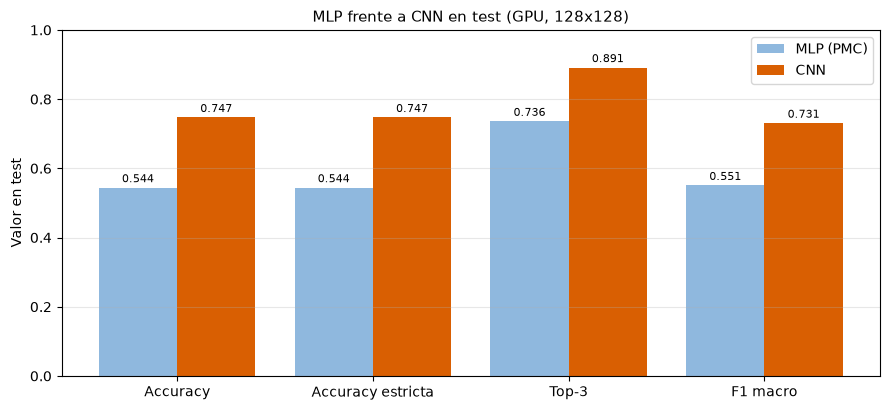

In [73]:
# Resumen del MLP (PMC) con el mismo entorno y la misma resolución que esta corrida
DIRECTORIO_RESULTADOS_PMC = Path("../../PMC/resultados/newDataset")
directorio_pmc = DIRECTORIO_RESULTADOS_PMC / ENTORNO
ruta_pmc = directorio_pmc / f"rendimiento_{ENTORNO.lower()}_{RESOLUCION}.json"

if not ruta_pmc.exists():
    print(f"No hay resumen del MLP en {ENTORNO} a {RESOLUCION}: {ruta_pmc.resolve()}")
    print("Ejecuta antes PMC/notebooks/LosSimpsons_GPU_4060M.ipynb.")
else:
    pmc = json.loads(ruta_pmc.read_text(encoding="utf-8"))
    cnn = resumen_corrida

    # (etiqueta, clave, "mayor" = más es mejor, "menor" = menos es mejor, None = no se compara)
    filas_mlp = [
        ("Configuración final", "configuracion_final", None),
        ("Parámetros del modelo final", "parametros_modelo_final", None),
        ("Accuracy en test", "accuracy_test", "mayor"),
        ("Accuracy por escena en test (referencia)", "accuracy_por_escena_test", "mayor"),
        ("Top-3 accuracy en test", "top3_test", "mayor"),
        ("F1 macro en test", "f1_macro_test", "mayor"),
        ("ROC-AUC macro en test", "roc_auc_macro_test", "mayor"),
        ("Accuracy en originales", "accuracy_originales_test", "mayor"),
        ("Accuracy en parecidas", "accuracy_parecidas_test", "mayor"),
        ("Accuracy en alteradas", "accuracy_alteradas_test", "mayor"),
        ("Errores con confianza > 0,80", "errores_confiados_test", None),
        ("Segundos: entrenamiento total", "segundos_entrenamiento_total", "menor"),
        ("Segundos por época (benchmark)", "benchmark_segundos_por_epoca", "menor"),
        ("Inferencia: imágenes por segundo", "inferencia_imagenes_por_segundo", "mayor"),
        ("Duración de la corrida", "duracion_corrida", None),
    ]
    registros_mlp = []
    for etiqueta, clave, direccion in filas_mlp:
        valor_mlp, valor_cnn = pmc.get(clave), cnn.get(clave)
        diferencia = "-"
        comparables = isinstance(valor_mlp, (int, float)) and isinstance(valor_cnn, (int, float))
        if direccion == "mayor" and comparables:
            diferencia = (
                f"{valor_cnn - valor_mlp:+.4f}" if valor_mlp <= 1 and valor_cnn <= 1
                else f"CNN x{valor_cnn / valor_mlp:.2f}"
            )
        elif direccion == "menor" and comparables and valor_mlp > 0:
            diferencia = f"CNN x{valor_cnn / valor_mlp:.2f} el tiempo del MLP"
        registros_mlp.append(
            {
                "Concepto": etiqueta,
                "MLP (PMC)": valor_mlp if valor_mlp is not None else "desconocido",
                "CNN": valor_cnn if valor_cnn is not None else "desconocido",
                "Diferencia": diferencia,
            }
        )
    comparacion_mlp = pd.DataFrame(registros_mlp)
    display(comparacion_mlp)
    print(
        f"MLP: corrida del {pmc.get('inicio_corrida', '?')}, entrada {pmc.get('representacion_final', '?')}"
        f" ({pmc.get('dimension_entrada_final', '?')} valores).   CNN: entrada imagen {RESOLUCION}x3"
        f" ({representacion_final})."
    )

    metricas_mlp = [
        ("Accuracy", "accuracy_test"),
        ("Accuracy estricta", "accuracy_estricta_test"),
        ("Top-3", "top3_test"),
        ("F1 macro", "f1_macro_test"),
    ]
    posiciones = np.arange(len(metricas_mlp))
    figura, eje = plt.subplots(figsize=(9, 4.2))
    barras_mlp = eje.bar(posiciones - 0.2, [pmc[clave] for _, clave in metricas_mlp], width=0.4,
                         label="MLP (PMC)", color="#8fb8de")
    barras_cnn = eje.bar(posiciones + 0.2, [cnn[clave] for _, clave in metricas_mlp], width=0.4,
                         label="CNN", color="#d95f02")
    for barras in (barras_mlp, barras_cnn):
        eje.bar_label(barras, fmt="%.3f", fontsize=8, padding=2)
    eje.set_xticks(posiciones)
    eje.set_xticklabels([etiqueta for etiqueta, _ in metricas_mlp])
    eje.set_ylim(0, 1)
    eje.set_ylabel("Valor en test")
    eje.set_title(f"MLP frente a CNN en test ({ENTORNO}, {RESOLUCION})", fontsize=11)
    eje.legend()
    eje.grid(alpha=0.3, axis="y")
    plt.tight_layout()
    plt.show()

**Lectura.** Con el mismo proceso, los mismos datos y la misma resolución, la CNN supera al MLP en todas las
métricas de calidad y en los tres tipos de imagen: 20,0 puntos de accuracy en las originales, 24,3 en las
alteradas y 15,5 en las parecidas. La ventaja es menor en las parecidas porque ahí el MLP ya rendía mejor
—su paleta se parece a la de una toma de entrenamiento— y mayor en las alteradas, donde el cambio de color
desordena los histogramas pero no la forma del personaje.

El precio está en el entrenamiento: 26,1 veces más tiempo (522 minutos frente a 20) y 24,8 veces más por época en
el benchmark (52,1 s frente a 2,1). En inferencia la comparación depende de qué se mida: la red del MLP sola es 21
veces más rápida que la CNN (74.000 frente a 3.600 imágenes por segundo), pero antes hay que calcular sus
descriptores en la CPU —165,8 s para las 70.855 imágenes, unas 430 por segundo—, que es lo que limita al MLP de
extremo a extremo; la CNN clasifica 2.649 imágenes por segundo de extremo a extremo. La CNN también comete menos
errores confiados (104 frente a 261), y casi todos nombran a un personaje presente en la imagen (ver «Ejemplos
mal clasificados»). El resumen del MLP no guarda su ROC-AUC: la tabla la deja como desconocida.

### Capacidad de generalización

La tabla anterior compara cuánto acierta cada red en test. La capacidad de generalización pregunta otra cosa:
cuánto de lo que aprendió cada red sirve con imágenes que no vio. Se mide de tres maneras, con el mismo
proceso para las dos redes:

1. **La brecha entre entrenamiento y validación del modelo base**: cuánto mejor rinde la red con las imágenes
   con que aprendió que con las de validación. Mide la memorización.
2. **La caída en las imágenes alteradas**: las alteradas de test son variantes —con giro, cambio de color y
   filtro de textura— de originales de test, que la red no vio ni en su forma original.
3. **La ventaja de las imágenes parecidas**: las parecidas son versiones filtradas de imágenes casi idénticas a
   otra del mismo personaje, que puede haber caído en entrenamiento. Cuanto más se aciertan frente a las
   originales, más depende la red de haber visto casi la misma toma.

La celda siguiente calcula las dos últimas, junto con la accuracy estricta y los errores cometidos con
confianza alta, a partir de los dos resúmenes de la celda anterior.

,MLP (PMC),CNN,Diferencia CNN - MLP
Accuracy en originales,0.5536,0.7533,0.1997
Accuracy en alteradas,0.4669,0.7101,0.2432
Caída en alteradas frente a originales (puntos),8.6700,4.3200,-4.3500
Accuracy en parecidas,0.6162,0.7711,0.1549
Ventaja de las parecidas sobre las originales (puntos),6.2600,1.7800,-4.4800
Accuracy estricta en test,0.5442,0.7470,0.2028
"Errores con confianza > 0,80 por cada 1.000 imágenes de test",36.9793,14.7351,-22.2442


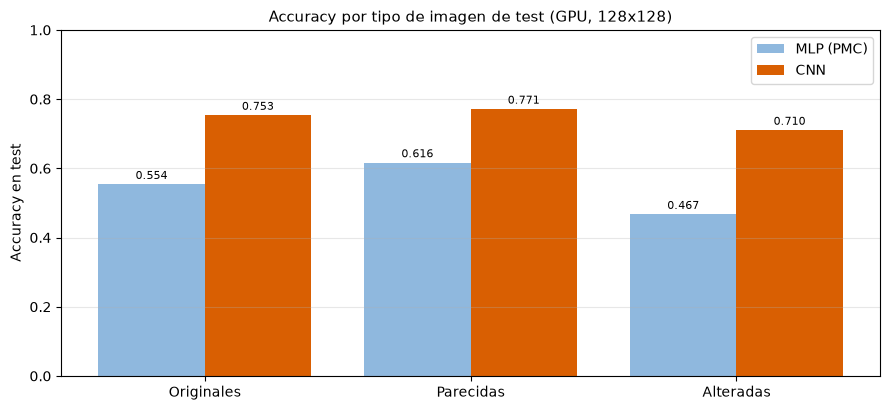

In [74]:
# Capacidad de generalización de los dos modelos, con los resúmenes de la celda anterior (mismo entorno y
# misma resolución): cómo rinden en imágenes que no vieron y cuánto dependen de haber visto casi la misma
if not ruta_pmc.exists():
    print(f"No hay resumen del MLP en {ENTORNO} a {RESOLUCION}: no se puede comparar la generalización.")
else:
    def indicadores_generalizacion(resumen):
        """Accuracy por tipo de imagen, caída en alteradas, ventaja de las parecidas, accuracy y errores
        confiados por cada 1.000 imágenes de test, leídos del resumen JSON de una red."""
        originales = resumen["accuracy_originales_test"]
        return {
            "Accuracy en originales": originales,
            "Accuracy en alteradas": resumen["accuracy_alteradas_test"],
            "Caída en alteradas frente a originales (puntos)": (originales - resumen["accuracy_alteradas_test"]) * 100,
            "Accuracy en parecidas": resumen["accuracy_parecidas_test"],
            "Ventaja de las parecidas sobre las originales (puntos)": (resumen["accuracy_parecidas_test"] - originales) * 100,
            "Accuracy estricta en test": resumen["accuracy_estricta_test"],
            "Errores con confianza > 0,80 por cada 1.000 imágenes de test": (
                resumen["errores_confiados_test"] / resumen["imagenes_test"] * 1000
            ),
        }

    generalizacion = pd.DataFrame(
        {"MLP (PMC)": indicadores_generalizacion(pmc), "CNN": indicadores_generalizacion(cnn)}
    ).round(4)
    generalizacion["Diferencia CNN - MLP"] = (generalizacion["CNN"] - generalizacion["MLP (PMC)"]).round(4)
    display(generalizacion)

    tipos_imagen = [
        ("Originales", "accuracy_originales_test"),
        ("Parecidas", "accuracy_parecidas_test"),
        ("Alteradas", "accuracy_alteradas_test"),
    ]
    posiciones = np.arange(len(tipos_imagen))
    figura, eje = plt.subplots(figsize=(9, 4.2))
    barras_mlp = eje.bar(posiciones - 0.2, [pmc[clave] for _, clave in tipos_imagen], width=0.4,
                         label="MLP (PMC)", color="#8fb8de")
    barras_cnn = eje.bar(posiciones + 0.2, [cnn[clave] for _, clave in tipos_imagen], width=0.4,
                         label="CNN", color="#d95f02")
    for barras in (barras_mlp, barras_cnn):
        eje.bar_label(barras, fmt="%.3f", fontsize=8, padding=2)
    eje.set_xticks(posiciones)
    eje.set_xticklabels([etiqueta for etiqueta, _ in tipos_imagen])
    eje.set_ylim(0, 1)
    eje.set_ylabel("Accuracy en test")
    eje.set_title(f"Accuracy por tipo de imagen de test ({ENTORNO}, {RESOLUCION})", fontsize=11)
    eje.legend()
    eje.grid(alpha=0.3, axis="y")
    plt.tight_layout()
    plt.show()

**Lectura.** A 128 × 128 las cuatro medidas favorecen a la CNN:

- **Memorización.** La CNN base deja una brecha de 0,198 entre la accuracy de entrenamiento (0,927) y la de
  validación (0,729); el MLP base, de 0,378 (0,857 frente a 0,479). El modelo final de la CNN, con aumento en
  línea, la baja a 0,020, medida contra imágenes de entrenamiento transformadas.
- **Tomas casi idénticas.** Las parecidas le dan al MLP 6,3 puntos de ventaja sobre las originales y a la CNN
  1,8: el MLP depende más de haber visto casi la misma toma; la CNN reconoce al personaje.
- **Imágenes alteradas.** La CNN pierde 4,3 puntos con el giro, el cambio de color y el filtro de textura, y el
  MLP 8,7.
- **Errores confiados.** Por cada 1.000 imágenes de test, la CNN comete 14,7 errores con confianza mayor que
  0,80 y el MLP 37,0, y casi todos los de la CNN nombran a un personaje que sí está en la imagen (ver «Ejemplos
  mal clasificados»).

**Todas las métricas de la pauta, para los dos modelos.** El resumen JSON del MLP no guarda la precision, el
recall ni la brecha entre entrenamiento y validación; las cifras de esas filas salen de las salidas guardadas de
su notebook (corrida del 09-11-2026). El MLP no calcula la ROC-AUC.

| Métrica en test | MLP · GPU 128 × 128 (C1) | CNN · GPU 128 × 128 (G4) |
|---|---:|---:|
| Accuracy | 0,544 | 0,747 |
| Precision macro | 0,560 | 0,741 |
| Recall macro | 0,550 | 0,734 |
| F1 macro | 0,551 | 0,731 |
| Precision ponderada | 0,545 | 0,759 |
| Recall ponderado | 0,544 | 0,747 |
| F1 ponderado | 0,542 | 0,747 |
| Top-3 accuracy | 0,736 | 0,891 |
| ROC-AUC macro | no medida | 0,986 |
| Accuracy por escena (referencia) | 0,632 | 0,824 |
| Modelo base: accuracy de entrenamiento / validación | 0,857 / 0,479 | 0,927 / 0,729 |
| Modelo base: brecha entre entrenamiento y validación | 0,378 | 0,198 |

Precision, recall y F1 usan el criterio de la carpeta, el mismo en las dos redes. Fuentes: las salidas de este
notebook y del notebook del MLP, y el resumen `rendimiento_gpu_128x128.json` de cada red. La matriz de confusión de cada
red está en su notebook.

En la CNN la precision macro (0,741) y el recall macro (0,734) quedan prácticamente iguales: en promedio por
personaje, se equivoca tanto por no reconocer una imagen de un personaje como por nombrarlo cuando no está.

### Ventajas y desventajas de cada arquitectura

La tabla reúne la evidencia de todo el notebook. Las cifras son de las corridas de GPU a 128 × 128 de las dos
redes con las mismas imágenes y la imagen completa: la del MLP del 09-11-2026 y la de la CNN del 13-11-2026.

| Aspecto | MLP (`PMC/`) | CNN (este notebook) | A favor de |
|---|---|---|---|
| Desempeño en test | Accuracy 0,544 y F1 macro 0,551 | Accuracy 0,747, F1 macro 0,731 y ROC-AUC macro 0,986 | CNN |
| Desempeño con la tolerancia por escena (referencia) | Accuracy 0,632 | Accuracy 0,824 | CNN |
| Qué aprende | Solo a combinar características que no aprende: 370 histogramas de color calculados con reglas fijas | Sus propios filtros de 3 × 3 sobre los píxeles: reconoce peinados, ropa y caras | CNN |
| Personajes que comparten paleta | Confunde a la familia Simpson por la piel amarilla compartida: F1 de 0,34 a 0,64 para Homero, Marge, Bart y Lisa | F1 de 0,71 a 0,83 para Homero, Marge, Bart y Lisa | CNN |
| Parámetros del modelo final | 1.059.648 | 473.120 | CNN |
| Caída en las imágenes alteradas | 8,7 puntos | 4,3 puntos | CNN |
| Ventaja de las imágenes parecidas sobre las originales | 6,3 puntos: depende más de haber visto casi la misma toma | 1,8 puntos | CNN |
| Brecha entre entrenamiento y validación del modelo base | 0,378 | 0,198 | CNN |
| Errores con confianza mayor que 0,80 | 261 | 104 | CNN |
| Tiempo de entrenamiento | 20,0 minutos | 522,2 minutos: 26,1 veces más | MLP |
| Uso de la GPU | La ocupa el 29,5 % del tiempo, a unos 11 W: la red es pequeña para la tarjeta | La ocupa el 99,3 % del tiempo, a unos 73 W, y dos configuraciones no caben en sus 8 GB | MLP |
| Inferencia de la red sola | 74.193 imágenes por segundo, sobre descriptores ya calculados | 3.570 imágenes por segundo | MLP |
| Explicación de la decisión | Importancia por permutación de cada bloque de descriptores | Grad-CAM sobre la propia imagen, de cada predicción y de cada clase | CNN |

**Síntesis.** La ventaja de la CNN es de representación: ve la forma, generaliza mejor y comete otro tipo de
errores. La del MLP es de costo: entrena 26 veces más rápido y apenas ocupa la tarjeta. Para este problema, donde
lo que separa a los personajes es su dibujo, la diferencia de desempeño —20 puntos de accuracy y 18 de F1 macro—
justifica el costo de entrenamiento, que además se paga una sola vez: **la CNN es la arquitectura seleccionada**.

## Limitaciones de la CNN y propuestas de mejora

### Limitaciones de esta CNN

La CNN resuelve las limitaciones estructurales que tenía el MLP: no aplana la imagen, comparte los filtros en
todas las posiciones, gana invarianza aproximada a desplazamientos con el pooling y aprende sus propias
características en lugar de recibirlas elegidas a mano. Las que siguen son las que quedan.

**1. Resolución de trabajo.** Incluso a 128 x 128 un personaje en un plano general ocupa unas pocas decenas
de píxeles, y los detalles que distinguen a dos personajes parecidos —los ojos, el peinado, un accesorio— se
pierden en el redimensionado. Subir la resolución multiplica el costo por cuatro cada vez que se dobla el
lado, y a 128 x 128 las configuraciones más grandes ya no caben en la memoria de la GPU.

**2. Entrenada desde cero.** Todos los filtros salen de unas 49.600 imágenes de entrenamiento, con 64
personajes y el menor con 130. Las redes preentrenadas en corpus de millones de imágenes parten de
filtros ya aprendidos —bordes, texturas, partes de objetos— y solo ajustan los últimos.

**3. Sensibilidad al fondo.** La red ve el fotograma completo, así que puede apoyarse en el escenario —la
taberna de Moe, la central nuclear— y no solo en el personaje. Grad-CAM permite ver dónde se apoya, pero no lo
corrige. Por la misma razón, cuando el script de cajas le pasa después el recorte de un solo personaje, la red
pierde ese contexto y su confianza baja.

**4. Invarianza solo aproximada.** El pooling tolera desplazamientos pequeños, no rotaciones grandes ni
cambios de escala fuertes. Los cubren en parte las imágenes alteradas, con un giro de 10 a 20° para un cuarto de las
imágenes, y el aumento en línea del modelo final, con giros de hasta 10° y escalas de 0,9 a 1,1: giros y
cambios de escala mayores siguen fuera de lo que vio al entrenar.

**5. Una etiqueta por imagen.** La salida `softmax` obliga a elegir un personaje por imagen aunque el fotograma
muestre a varios. El script de cajas lo atenúa después nombrando cada caja por separado, pero solo el personaje
de la carpeta tiene etiqueta para medir el acierto.

**6. Costo de cómputo.** Cada imagen pasa por cuatro bloques de convoluciones: entrenar la CNN cuesta
bastante más que entrenar el MLP sobre descriptores: 26 veces más en la misma GPU.

**7. Ruido en las etiquetas.** La etiqueta de cada imagen es su carpeta, y algunas carpetas tienen imágenes
que no muestran a su personaje: entre los errores más confiados hay imágenes de la carpeta de Barney en las que
solo se ve a Bart, y entre los menos confiados, la misma hoja de un presupuesto escolar tres veces en la carpeta
de Otto. El modelo aprende de esas imágenes como si fueran del personaje de la carpeta, y en test cuentan como
errores.

### Propuestas de mejora para futuras iteraciones

| Propuesta | En qué consiste | Qué limitación ataca |
|---|---|---|
| **Transfer learning** | Partir de una red preentrenada (MobileNet, ResNet, EfficientNet) y ajustar sus últimas capas a los 64 personajes | Es la mejora principal: filtros aprendidos sobre millones de imágenes (2), que suelen dar un salto grande de desempeño con pocos datos propios |
| **Aumento de datos más fuerte y más épocas** | El modelo final ya usa aumento en línea (G4). Ampliarlo con recortes aleatorios, giros mayores y cambios de tono, y entrenarlo con el presupuesto de la base: G4 tocó su mejor época en la 33 de 35, y C1 en la última | Es la técnica que más mejoró la generalización (+1,9 puntos de F1 macro de validación); más variedad cubre la invarianza que falta (4) |
| **Regularización de las capas convolucionales** | `SpatialDropout2D` tras cada bloque, que apaga mapas de activación completos, y un barrido de la intensidad de L2 o del *weight decay* de AdamW | G3, con un único valor de L2, mejoró 0,6 puntos de F1 y bajó la brecha de 0,176 a 0,148; más Dropout en la cabeza (E6) baja la brecha pero también el F1 |
| **Medir lo que no cupo** | Acumular gradientes en lotes más chicos o entrenar con precisión mixta (`bfloat16`) para reducir la memoria de las activaciones | A 128 x 128, E2 (dos convoluciones por bloque) y E5 (batch 512) no caben en los 8 GB de la tarjeta; también permitiría probar resoluciones mayores (1, 6) |
| **Arquitecturas residuales** | Bloques con conexiones residuales (ResNet) o convoluciones separables (MobileNet) | Permiten redes más profundas sin que el gradiente se degrade, y abaratan cada capa (6) |
| **Salida multietiqueta** | Sigmoides independientes en la salida, entrenadas con los personajes de la escena | Permite nombrar a todos los personajes presentes en lugar de uno solo (5) |
| **Validación cruzada y varias semillas** | Repetir el entrenamiento con varias particiones y varias semillas, reportando media y desviación | Entre las dos corridas del 13-11-2026 una misma configuración cambió hasta 1,9 puntos de F1 macro de validación: sin varias semillas no se puede saber si una diferencia de esa magnitud es real |
| **Limpieza de las etiquetas** | Revisar las imágenes con errores de confianza muy alta o muy baja y sacar de su carpeta las que no muestran al personaje | Ataca el ruido en las etiquetas (7): mejora lo que aprende el modelo y hace más fiel la evaluación |
| **Partición por grupo o por episodio** | Repartir en un mismo conjunto cada grupo de imágenes casi idénticas, o todos los fotogramas de un episodio | Evita que tomas de una misma escena caigan a la vez en entrenamiento y test |

## Impacto ético

El modelo reconoce personajes de dibujos animados, así que no trata datos personales. Aun así, su uso tiene
consecuencias que hay que declarar, con las cifras de la corrida de GPU a 128 × 128.

**Derechos de autor.** Los personajes y los fotogramas de la serie son obras protegidas, también los que el
equipo extrajo de los episodios para ampliar el dataset. Se usan solo con fines académicos: el dataset vive fuera
del repositorio y no se versiona, y los modelos entrenados tampoco (`.gitignore` excluye `models_gpu/` y los
archivos `.keras`). Un uso comercial del catálogo exigiría la licencia del titular, también sobre las imágenes
de entrenamiento. Y detectar a un personaje en material de terceros no prueba una infracción: la cita, la
crítica o la parodia pueden estar permitidas, así que el caso de uso «control de uso de marca» solo puede
proponer casos para que los revise una persona.

**Sesgo por el desbalance y por el parecido.** La razón de 21:1 entre Homero y Maggie no desaparece con los
pesos por clase, aunque con el dataset ampliado ya no es lo que más pesa: la correlación entre imágenes de
entrenamiento y F1 por personaje es de 0,21, y los personajes con peor F1 son los que se parecen a otro o salen
casi siempre con él. El sesgo cambia de forma, pero no desaparece. Si el catálogo se usara para medir la presencia
en pantalla —uno de los casos de uso declarados—, contaría a Patty Bouvier 1,47 veces sus apariciones reales
(recall / precision = 0,851 / 0,577) y a su gemela Selma solo 0,52 veces (0,405 / 0,773); a Homero, 0,84 veces
(0,719 / 0,852), y a Gil, 0,60 (0,436 / 0,721): un sesgo que llegaría directamente a decisiones de licencias o de
merchandising.

**Ruido en las etiquetas.** La auditoría de los errores encontró imágenes cuya carpeta no corresponde al personaje
que muestran —Bart en la carpeta de Barney, una hoja de papel en la de Otto—. El modelo aprende de ellas, y la
evaluación las cuenta como errores: antes de usar el catálogo para medir algo, hay que limpiar esas carpetas.

**Revisión humana.** El modelo se equivoca en el 25,3 % del test (1.786 de 7.058 imágenes) y siempre responde
con alguno de sus 64 personajes, aunque la imagen no tenga a ninguno: no existe la opción «ninguno de los
anteriores». 104 errores superan una confianza de 0,80, así que una confianza alta no basta para automatizar.
El uso responsable es el de asistente, el que definen los KPIs: mostrar las tres sugerencias, que contienen la
respuesta en el 89,1 % del test; mandar a revisión las predicciones de confianza baja (la media es 0,76 en los
aciertos y 0,38 en los errores); y revisar siempre a mano lo que afecte a terceros, como un reclamo, un pago de
licencias o el retiro de material.

**Fuera del dominio.** La red solo conoce dibujos de Los Simpson. Aplicada a fotos de personas reales sería un
sistema de reconocimiento facial, con problemas de privacidad y de consentimiento que este proyecto no aborda:
no debe usarse así.

**Transparencia.** Las decisiones se pueden auditar. Grad-CAM muestra en qué zona de cada imagen se apoya la
red (ver «En qué se apoya el modelo» y «Mapa de activación de cada clase»), la accuracy por escena se informa
siempre como referencia junto a las métricas del criterio de la carpeta, y el notebook, los resultados y el informe
documentan cada decisión del proceso.

## Conclusiones

In [75]:
# Cifras finales del trabajo, tomadas de las secciones anteriores
conclusiones = pd.DataFrame(
    [
        ("Personajes (clases)", NUMERO_CLASES),
        ("Imágenes de entrenamiento", len(X_train)),
        ("   de ellas, alteradas", int(datos.loc[MASCARAS["train"], "alterada"].sum())),
        ("Imágenes de validación", len(X_val)),
        ("   de ellas, alteradas", int(datos.loc[MASCARAS["val"], "alterada"].sum())),
        ("Imágenes de test", len(X_test)),
        ("   de ellas, alteradas", int(datos.loc[MASCARAS["test"], "alterada"].sum())),
        ("Imágenes parecidas, con filtro (todos los conjuntos)", int(datos["parecida"].sum())),
        ("Pares de gemelas entre personajes", n_pares_gemelas),
        ("Reparto de las originales", " / ".join(f"{PROPORCIONES[nombre]:.0%}" for nombre in CONJUNTOS)),
        ("Resolución de trabajo", f"{ALTO_OBJETIVO}x{ANCHO_OBJETIVO}"),
        ("Entrada del modelo final", f"imagen completa {ALTO_OBJETIVO}x{ANCHO_OBJETIVO}x3 ({representacion_final})"),
        ("Configuración final", nombre_final),
        ("Arquitectura del modelo final", arquitectura_final),
        ("Parámetros del modelo final", f"{modelo_final.count_params():,}"),
        ("Accuracy en test (personaje de la carpeta)", round(float(accuracy_test), 4)),
        ("Accuracy por escena en test (referencia)", round(accuracy_por_escena_test, 4)),
        (
            "   en originales / parecidas / alteradas",
            " / ".join(
                f"{valor:.4f}"
                for valor in (accuracy_originales_test, accuracy_parecidas_test, accuracy_alteradas_test)
            ),
        ),
        ("Top-3 accuracy en test", round(float(top3_test), 4)),
        ("F1 macro en test", round(float(f1_macro_test), 4)),
        ("F1 ponderado en test", round(float(f1_ponderado_test), 4)),
        ("ROC-AUC macro en test", round(float(roc_auc_macro_test), 4)),
        ("Brecha train - val del modelo base", round(float(brecha), 4)),
        ("Baseline azar", round(baseline_azar, 4)),
        ("Baseline clase mayoritaria", round(float(baseline_mayoritaria), 4)),
    ],
    columns=["Concepto", "Valor"],
)

display(conclusiones)

,Concepto,Valor
0,Personajes (clases),64
1,Imágenes de entrenamiento,49625
2,"de ellas, alteradas",9952
3,Imágenes de validación,14172
4,"de ellas, alteradas",2837
5,Imágenes de test,7058
6,"de ellas, alteradas",1390
7,"Imágenes parecidas, con filtro (todos los conj...",9042
8,Pares de gemelas entre personajes,6222
9,Reparto de las originales,70% / 20% / 10%


**Sobre los resultados.** En la corrida de GPU a 128 × 128 del 13-11-2026, con 56.676 imágenes originales y el
criterio de la carpeta, la CNN alcanza una accuracy de test de 0,747, una top-3 de 0,891, un F1 macro de 0,731 y una
ROC-AUC macro de 0,986: 48 veces el azar y 13,5 veces la clase mayoritaria. Los cinco KPIs se cumplen con margen; el
de costo, con 2.649 imágenes por segundo, 2,6 veces el umbral. Frente al MLP entrenado con las mismas imágenes, a la
misma resolución y en el mismo dispositivo, la accuracy sube 20,3 puntos, la top-3 15,6 y el F1 macro 18,0.

**Sobre los objetivos planteados.** Se cumplieron los seis objetivos específicos: indexar el dataset con la
etiqueta de cada carpeta; repartirlo 70/20/10 de forma estratificada, con cada alterada en el mismo conjunto
que su original; preparar las imágenes como tensores sin aplanar; entrenar el modelo base y quince variantes
controladas, entre ellas siete de regularización y una combinación (las otras dos no caben en la GPU a esta
resolución); seleccionar por F1 macro de validación y medir una sola vez en test; y auditar el resultado por clase,
por tipo de imagen, por escena, con la ROC-AUC y con Grad-CAM, comparándolo con el MLP.

**Sobre lo que aprendimos.**

1. **La representación decide más que el ajuste fino.** Pasar de descriptores elegidos a mano a filtros
   aprendidos sube el F1 macro de test 18 puntos; dentro de la CNN, la mejor variante sube el F1 macro de
   validación 1,9.
2. **La regularización que sirve es la que da variedad.** El dropout de la cabeza es imprescindible —sin él el F1
   cae 6 puntos y la brecha sube a 0,31—, Batch Normalization aporta 1,8 puntos y L2, 0,6. El aumento de datos en
   línea es la única mejora clara (+1,9 puntos), con la brecha casi en cero, y combinarlo con L2 no suma.
3. **El color sigue importando, pero la forma pesa más.** Sin color, la misma CNN pierde 8,6 puntos de F1
   macro de validación; color y forma juntos son los que separan a los personajes.
4. **Las decisiones propias de una CNN se notan.** El pooling global supera al aplanado por 5,4 puntos y quitar un
   bloque cuesta 6,0: invarianza a la posición y profundidad son las dos propiedades que el MLP no tenía.
   E2, con una segunda convolución por bloque, no cabe en la memoria de la GPU a 128 × 128.
5. **Lo difícil ya no es tener pocas imágenes, sino parecerse a otro.** Maggie y Disco Stu, con menos de 160
   imágenes de entrenamiento, llegan a 0,90 y 0,92 de F1, mientras que Rod y Maude Flanders, Kearney, Jimbo y Helen
   Lovejoy, con 463 a 637, quedan por debajo de 0,46: se confunden con el personaje al que se parecen o con el que
   comparten escena.
6. **El criterio de acierto y las etiquetas se quedan cortos.** Casi todos los errores confiados nombran a un
   personaje que está en la imagen, la accuracy por escena sube a 0,824 y algunas imágenes no muestran al personaje
   de su carpeta: la accuracy de 0,747 es una cota inferior.
7. **El costo se mueve al entrenamiento.** A esta resolución la CNN tarda 26 veces más en entrenar que el
   MLP (9 h 12 min la corrida completa), pero clasifica 2.649 imágenes nuevas por segundo de extremo a
   extremo, sin calcular descriptores en la CPU como el MLP.

**Sobre las mejoras por regularización.** El modelo base memoriza parte del entrenamiento (brecha de 0,198), y la
experimentación mostró dónde está la solución: apretar los pesos (L2, más dropout) ayuda poco o nada, mientras que
dar más variedad a los datos baja la brecha casi a cero y mejora la validación. Los próximos pasos siguen esa línea:
un aumento más fuerte —recortes aleatorios, giros mayores, cambios de tono—, el presupuesto de épocas de la base
para G4 y C1 (C1 tocó su mejor época en la última de sus 35) y `SpatialDropout2D` tras cada bloque. Cada uno debe medirse con el mismo
diseño de un factor a la vez y con varias semillas: entre las dos corridas del 13-11-2026 una misma configuración
cambió hasta 1,9 puntos de F1 macro de validación.

## Probar el modelo con una imagen cualquiera

Esta sección empaqueta todo lo anterior en una función de uso directo. Recibe la ruta de una imagen —del
dataset o de cualquier otro origen— y la clasifica **igual que en el entrenamiento**: la imagen completa se convierte a RGB y se redimensiona a
128 x 128; el escalado a [0, 1] y, si el modelo la usa, la conversión a escala de grises van dentro del
modelo. Devuelve el
personaje más probable con su confianza, `Personaje · 92 %`, y las otras candidatas.

Si el modelo ya está en memoria se reutiliza; si no, se carga desde `models_gpu/newDataset/cnn_final.keras`,
junto con `cnn_final.json`, que guarda la resolución y el orden de las clases, y `cnn_final_entrada.py`, que repite
la preparación de la entrada. Los escribe la celda «Selección del modelo final».

**Cada personaje en su caja, después del notebook.** Para encontrar a cada personaje de un fotograma y nombrarlo
por separado se usa el script de cajas con el modelo guardado, desde la raíz del repositorio:

```powershell
.\.venv-gpu\Scripts\python.exe scripts\newDataset\detectar_cajas.py --modelo cnn ruta\a\imagen.jpg
.\.venv-gpu\Scripts\python.exe scripts\newDataset\detectar_cajas.py --modelo cnn --dataset --muestra 5
```

Un detector preentrenado (Grounding DINO) encuentra las cajas y este modelo nombra cada una con su confianza. El
script lee los archivos del modelo; el notebook no depende de él.


In [76]:
# Utilidad de predicción: clasifica una imagen cualquiera con el modelo final, igual que en el entrenamiento.
# Autosuficiente: reutiliza lo que ya esté en memoria y carga lo que falte
import importlib.util
import json
import os
from pathlib import Path

os.environ.setdefault("KERAS_BACKEND", "torch")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
import keras

DIRECTORIO_MODELO_FINAL = Path("../models_gpu/newDataset")
NOMBRE_MODELO = "cnn_final"

# 1. El modelo: si no se ejecutó el notebook completo, se carga el archivo guardado
if "modelo_final" not in globals():
    ruta_guardada = DIRECTORIO_MODELO_FINAL / f"{NOMBRE_MODELO}.keras"
    if not ruta_guardada.exists():
        raise FileNotFoundError(
            f"No hay modelo en memoria ni en {ruta_guardada}. "
            "Ejecuta antes la selección del modelo final o entrena el notebook completo."
        )
    # compile=False: esta celda solo predice. El entrenamiento usa un optimizador
    # de PyTorch, asi que el optimizador de Keras guardado en el archivo esta vacio
    # y cargarlo solo produciria un aviso sin utilidad.
    modelo_final = keras.models.load_model(ruta_guardada, compile=False)
    if torch.cuda.is_available():
        modelo_final = modelo_final.to("cuda")
    print(f"Modelo cargado desde {ruta_guardada}")

# 2. El pre-procesamiento con el que se entrenó: la resolución, el orden de las clases, que define qué índice de
#    salida corresponde a qué personaje, y la preparación de la entrada que escribió «Selección del modelo final»
metadatos_modelo = json.loads((DIRECTORIO_MODELO_FINAL / f"{NOMBRE_MODELO}.json").read_text(encoding="utf-8"))
clases = metadatos_modelo["clases"]
ALTO_OBJETIVO, ANCHO_OBJETIVO = metadatos_modelo["alto"], metadatos_modelo["ancho"]
ruta_preparacion = DIRECTORIO_MODELO_FINAL / metadatos_modelo.get("preparacion", f"{NOMBRE_MODELO}_entrada.py")
if ruta_preparacion.is_file():
    especificacion_preparacion = importlib.util.spec_from_file_location(ruta_preparacion.stem, ruta_preparacion)
    modulo_preparacion = importlib.util.module_from_spec(especificacion_preparacion)
    especificacion_preparacion.loader.exec_module(modulo_preparacion)
    preparar_entrada = modulo_preparacion.preparar
elif metadatos_modelo.get("representacion", "rgb") in ("rgb", "gris"):
    preparar_entrada = lambda lote: lote  # noqa: E731 - la imagen RGB entra tal cual
else:
    raise FileNotFoundError(
        f"Falta {ruta_preparacion}: ejecuta antes la celda «Selección del modelo final», que lo genera."
    )

# Nombres que no salen bien de la carpeta con title()
NOMBRES_ESPECIALES = {
    "kang_kodos": "Kang y Kodos",
    "krusty_the_clown": "Krusty the Clown",
    "captain_horatio_mccallister": "Captain Horatio McCallister",
    "dr_julius_hibbert": "Dr. Julius Hibbert",
    "dr_nick_riviera": "Dr. Nick Riviera",
    "rev_timothy_lovejoy": "Rev. Timothy Lovejoy",
}


def nombre_legible(personaje):
    """'jasper_beardly' -> 'Jasper Beardly'."""
    return NOMBRES_ESPECIALES.get(personaje, personaje.replace("_", " ").title())


def rotulo(personaje, confianza):
    """El personaje y la confianza del modelo: 'Jasper Beardly · 92 %'."""
    return f"{nombre_legible(personaje)} · {round(100 * float(confianza))} %"


def predecir_imagen(ruta_imagen, top_k=3, mostrar=True):
    """Clasifica una imagen completa con el modelo final.

    ruta_imagen : ruta a un archivo de imagen (jpg, png, ...).
    top_k       : cuántas candidatas devolver, de mayor a menor probabilidad.
    Devuelve un DataFrame con una fila por candidata: el personaje, su confianza y su rótulo."""
    ruta_imagen = Path(str(ruta_imagen).strip().strip('"').strip("'"))
    if not ruta_imagen.is_file():
        raise FileNotFoundError(f"No se encontro la imagen: {ruta_imagen}")
    with Image.open(ruta_imagen) as archivo:
        imagen = archivo.convert("RGB")

    # --- Mismo pre-procesamiento que en el entrenamiento: la imagen completa, redimensionada con bilineal ---
    reducida = np.array(imagen.resize((ANCHO_OBJETIVO, ALTO_OBJETIVO), Image.Resampling.BILINEAR), dtype=np.uint8)
    entrada = np.ascontiguousarray(preparar_entrada(reducida[np.newaxis]))
    dispositivo = next(modelo_final.parameters()).device
    probabilidades = modelo_final.predict(torch.as_tensor(entrada).to(dispositivo), verbose=0)[0]
    mejores = np.argsort(-probabilidades)[:top_k]
    resultado = pd.DataFrame(
        [
            {
                "puesto": puesto,
                "personaje": nombre_legible(clases[indice]),
                "confianza": round(float(probabilidades[indice]), 4),
                "rotulo": rotulo(clases[indice], probabilidades[indice]),
            }
            for puesto, indice in enumerate(mejores, start=1)
        ]
    )

    if mostrar:
        carpeta = ruta_imagen.parent.name if ruta_imagen.parent.name in clases else None
        prediccion = clases[int(mejores[0])]
        color = "#1f77b4" if carpeta is None else ("#1b7f3b" if prediccion == carpeta else "#c0392b")
        figura, eje = plt.subplots(figsize=(9, 6.5))
        eje.imshow(imagen)
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in eje.spines.values():
            lado.set_edgecolor(color)
            lado.set_linewidth(4)
        titulo = f"{resultado.loc[0, 'rotulo']}   |   {ruta_imagen.name}"
        if carpeta is not None:
            titulo += f"   |   carpeta: {nombre_legible(carpeta)} ({'acierto' if prediccion == carpeta else 'error'})"
        eje.set_title(titulo, fontsize=11, fontweight="bold")
        eje.set_xlabel("Otras candidatas: " + ", ".join(resultado["rotulo"].iloc[1:]), fontsize=10)
        plt.show()

    return resultado


print(f"Listo ({metadatos_modelo.get('representacion', 'rgb')}). Usa predecir_imagen(<ruta>) en la celda siguiente.")


Listo (rgb). Usa predecir_imagen(<ruta>) en la celda siguiente.


**Cómo usarla.** Basta con reemplazar la ruta de `RUTA_IMAGEN` por la de cualquier imagen del disco y
ejecutar la celda; se puede repetir tantas veces como se quiera sin volver a cargar el modelo. La `r`
delante de las comillas indica a Python que no interprete las barras invertidas de las rutas de Windows,
así que la ruta se puede pegar tal cual.

Cuando la imagen proviene de una carpeta con nombre de personaje —como ocurre en el dataset—, la función
lo detecta y compara la predicción con esa etiqueta. Si la imagen viene de cualquier otro lugar,
simplemente muestra la respuesta del modelo.

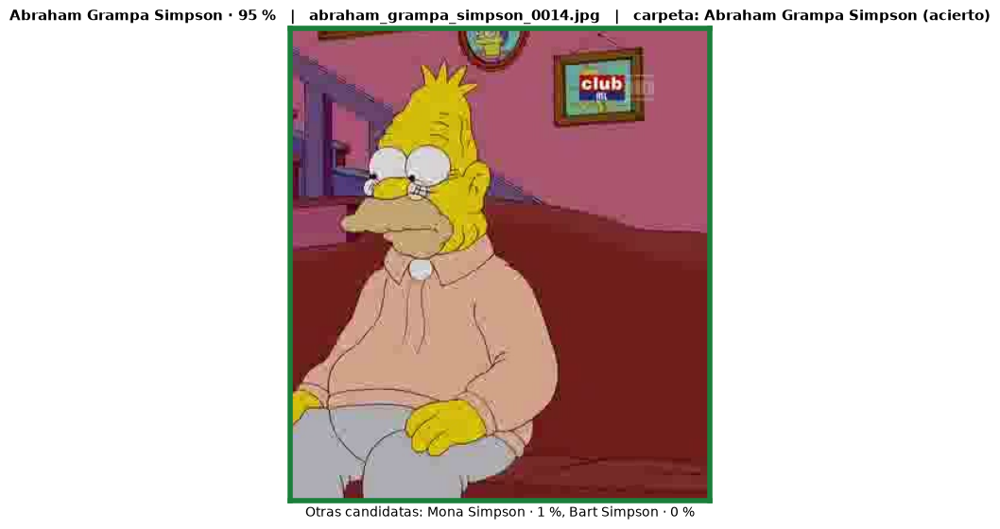

,puesto,personaje,confianza,rotulo
0,1,Abraham Grampa Simpson,0.9465,Abraham Grampa Simpson · 95 %
1,2,Mona Simpson,0.0067,Mona Simpson · 1 %
2,3,Bart Simpson,0.0042,Bart Simpson · 0 %


In [77]:
# Cambia esta ruta por la de la imagen que quieras clasificar y vuelve a ejecutar la celda.
# Por defecto se usa una imagen original de test, que el modelo no vio al entrenar.
if "datos_test" in globals():
    RUTA_IMAGEN = datos_test.loc[~datos_test["alterada"], "ruta"].iloc[0]
else:
    RUTA_IMAGEN = r"C:\ruta\a\una\imagen.jpg"

candidatas_imagen = predecir_imagen(RUTA_IMAGEN)
display(candidatas_imagen)


**Advertencia sobre la interpretación.** La red siempre responde algo: el softmax reparte
probabilidad entre los 64 personajes conocidos y devuelve la mayor, aunque la imagen no contenga a ningún
personaje de Los Simpson. No existe una opción "ninguno de los anteriores". Por eso la confianza es tan
informativa como el nombre: un valor cercano al 100 % indica una decisión clara, mientras que una
ganadora con 15 % frente a candidatas de 12 % significa que el modelo no tiene criterio para decidir.

Conviene recordar también los límites vistos en la evaluación: el modelo reconoce con solidez a los
personajes con muchas imágenes de entrenamiento y rinde peor en los minoritarios, y es sensible
al encuadre y al fondo. Una foto con el personaje pequeño dentro de una escena cargada tiene bastantes
menos probabilidades de clasificarse bien que un primer plano.

## Anexo: recreación de cada personaje desde la CNN

Las secciones anteriores explican decisiones sobre imágenes de test. Esta hace la pregunta al revés: **¿qué
aprendió la red de cada personaje?** Para responderla se genera una imagen de cada uno de los 64 **solo desde el
modelo**, sin leer ni promediar imágenes del dataset, con la técnica DeepInversion (Yin et al., 2020): se parte de
ruido y se optimizan los píxeles de un lote de 64 imágenes, una por personaje, con tres objetivos:

1. **La clase.** Que cada imagen maximice la clase de su personaje: entropía cruzada sobre los logits de la capa
   `salida`, antes del softmax.
2. **Lo que la red vio al entrenar.** Que la media y la varianza de la entrada de cada BatchNorm, medidas en el
   lote (`norm_1` a `norm_4` y `norm_densa`), coincidan con las que esa capa guardó al entrenar (`moving_mean` y
   `moving_variance`). Esas cifras son el promedio del entrenamiento que quedó dentro del modelo. Es lo que
   DeepInversion agrega a la imagen que maximiza una clase de Simonyan et al. (2014), que solo penalizaba la
   norma L2: sin él, la red reconoce la imagen mucho antes de que se parezca a algo.
3. **Suavidad.** Variación total y norma L2, más un desplazamiento de hasta 16 píxeles y un volteo al azar en
   cada paso, para que la imagen no dependa de la posición exacta de cada píxel.

Los pesos no cambian: solo se optimizan los píxeles, con Adam (betas 0,5 y 0,9, tasa 0,05 con decaimiento
coseno) durante 2.000 pasos. Después, cada recreación se cuantiza a `uint8`, como una imagen cualquiera, y la
clasifican todas las redes guardadas. Una red siempre reconoce lo que generó; lo que demuestra el entrenamiento es
que **otra** red, que nunca vio esos gradientes, nombre al mismo personaje. Al azar acertaría 1 de 64 (1,6 %).

Se usan las redes que ya están en disco, sin reentrenar ninguna. **Solo las dos CNN generan imágenes**: este
notebook no recrea con el modelo del MLP, que tiene su propia recreación en el notebook del MLP. El MLP solo
juzga lo que generan las CNN:

| Red | Papel | Modelo | Entrada |
|---|---|---|---|
| CNN, fotograma completo | genera y juzga | `CNN/models_gpu/newDataset/cnn_final.keras`, el modelo final de este notebook | imagen 128 × 128 × 3 |
| CNN, recortes | genera y juzga | `CNN/models_gpu/newDataset/cajas/cnn_final.keras` o, si no existe, `cajas/maestra_recortes.keras` | imagen 128 × 128 × 3 |
| MLP, píxeles (R1) | solo juzga | `PMC/models_gpu/newDataset/mlp_r1.keras`, que guarda el notebook del MLP | píxeles aplanados |

El código está en `scripts/newDataset/recrear_personajes.py`, que la celda importa; sus pruebas, en
`scripts/newDataset/tests/test_recrear_personajes.py`. Las salidas quedan en
`CNN/resultados/newDataset/recreaciones/`: un PNG por personaje y una lámina por red, un JSON con el modelo y su
sha256, los hiperparámetros, la semilla, el tiempo y la matriz, y las figuras `comparacion.png` y `evolucion.png`,
solo con las CNN.

> Celda agregada el 09-11-2026. En la corrida del 13-11-2026 se ejecutó al final, con el `cnn_final.keras` recién
> entrenado; la CNN de recortes y el MLP son los modelos que ya estaban en disco. No reentrena ninguno ni lee el
> dataset, no depende de ninguna variable del notebook y se puede ejecutar sola. El punto de partida de la
> variación total (α_tv = 1e-4) dejaba ruido; en el piloto se subió a 1e-3, que deja formas sin cambiar el
> reconocimiento.

AVISO: mlp_robusto (MLP robusto, píxeles): no hay modelo que reciba píxeles en PMC/models_gpu/newDataset/mlp_r1_robusto.keras; se sigue sin él.
Redes: cnn (CNN/models_gpu/newDataset/cnn_final.keras), cnn_recortes (CNN/models_gpu/newDataset/cajas/maestra_recortes.keras), mlp (PMC/models_gpu/newDataset/mlp_r1.keras) | cuda
Generan: cnn, cnn_recortes | solo juzgan: mlp
64 personajes, semilla 42
  cnn           2000 pasos, lr 0.05, α_bn 0.01, α_tv 0.001, desplazamiento 16, volteo sí, escalas ninguna, reinicios 1
  cnn_recortes  2000 pasos, lr 0.05, α_bn 0.01, α_tv 0.001, desplazamiento 16, volteo sí, escalas ninguna, reinicios 1


  cnn           paso     1/2000  pérdida 10.336  (entropía 5.709, BN 174.70, TV 2878.6)


  cnn           paso   501/2000  pérdida 0.758  (entropía 0.004, BN 20.89, TV 544.2)


  cnn           paso  1001/2000  pérdida 0.669  (entropía 0.001, BN 23.61, TV 430.9)


  cnn           paso  1501/2000  pérdida 0.448  (entropía 0.002, BN 12.68, TV 318.2)


  cnn           paso  2000/2000  pérdida 0.402  (entropía 0.002, BN 11.28, TV 286.0)


  cnn_recortes  desde la caché (CNN/models_gpu/newDataset/cajas/recreaciones/maestra_recortes_aba0103a4cc6acf2.npz)



RECREACION_MODELO generador=cnn sha256=0eb0b2488c7738cd83d2b180ccd3880a0d8f46330bd36c3c485704cc85477c43 segundos=105.5 semilla=42 pasos=2000 personajes=64
RECREACION_MODELO generador=cnn_recortes sha256=ccb717525d68d177dc0d14f6b78d1a58e03fe747593c93bbba97f8af7058d46e segundos=104.5 semilla=42 pasos=2000 personajes=64
RECREACION generador=cnn juez=cnn top1=64/64 top3=64/64 confianza=0.998 posicion_media=1.00
RECREACION generador=cnn juez=cnn_recortes top1=54/64 top3=59/64 confianza=0.554 posicion_media=1.84
RECREACION generador=cnn juez=mlp top1=2/64 top3=4/64 confianza=0.022 posicion_media=29.69
RECREACION generador=cnn_recortes juez=cnn top1=52/64 top3=62/64 confianza=0.552 posicion_media=1.47
RECREACION generador=cnn_recortes juez=cnn_recortes top1=64/64 top3=64/64 confianza=0.999 posicion_media=1.00
RECREACION generador=cnn_recortes juez=mlp top1=0/64 top3=4/64 confianza=0.018 posicion_media=28.97
RECREACION_PASO generador=cnn paso=0 top1=0/64 confianza=0.016 mas_nombrado=rod_fland

,genera,juzga,prueba,top-1,top-3,probabilidad media del personaje
0,"CNN, fotograma completo","CNN, fotograma completo",propia,64 de 64,64 de 64,0.9984
1,"CNN, fotograma completo","CNN, recortes",cruzada,54 de 64,59 de 64,0.5537
2,"CNN, fotograma completo","MLP, píxeles",cruzada,2 de 64,4 de 64,0.0217
3,"CNN, recortes","CNN, fotograma completo",cruzada,52 de 64,62 de 64,0.5516
4,"CNN, recortes","CNN, recortes",propia,64 de 64,64 de 64,0.9986
5,"CNN, recortes","MLP, píxeles",cruzada,0 de 64,4 de 64,0.0176


Al azar: top-1 de 1 en 64 (1.6%).
Correlación de pesos entre CNN, fotograma completo y CNN, recortes: 0.136 -> redes independientes


,red,paso,reconocidas,probabilidad media del personaje,confianza media de su respuesta,personaje que más nombra
0,"CNN, fotograma completo",0,0 de 64,0.0159,0.3437,rod_flanders (44 de 64)
1,"CNN, fotograma completo",50,64 de 64,0.9639,0.9639,ninguno se repite
2,"CNN, fotograma completo",200,64 de 64,0.9968,0.9968,ninguno se repite
3,"CNN, fotograma completo",500,64 de 64,0.9976,0.9976,ninguno se repite
4,"CNN, fotograma completo",2000,64 de 64,0.9984,0.9984,ninguno se repite
5,"CNN, recortes",0,1 de 64,0.0215,0.7578,sideshow_mel (63 de 64)
6,"CNN, recortes",50,62 de 64,0.9221,0.9265,cletus_spuckler (2 de 64)
7,"CNN, recortes",200,64 de 64,0.9899,0.9899,ninguno se repite
8,"CNN, recortes",500,64 de 64,0.9980,0.9980,ninguno se repite
9,"CNN, recortes",2000,64 de 64,0.9986,0.9986,ninguno se repite


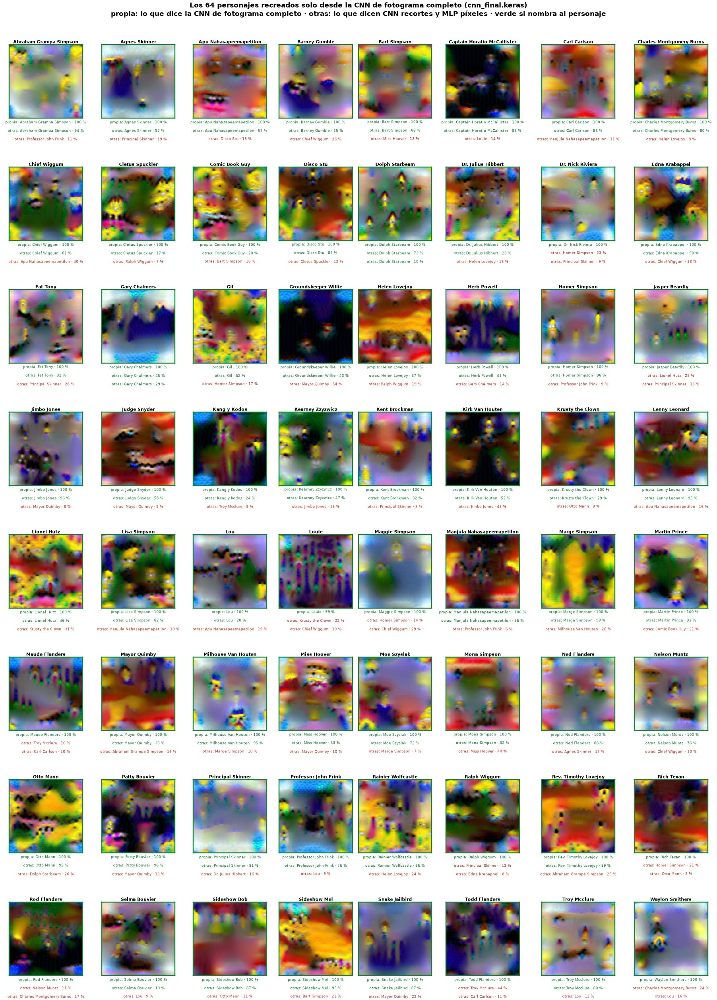

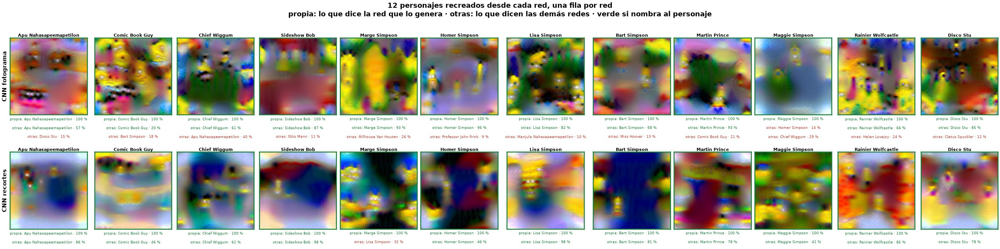

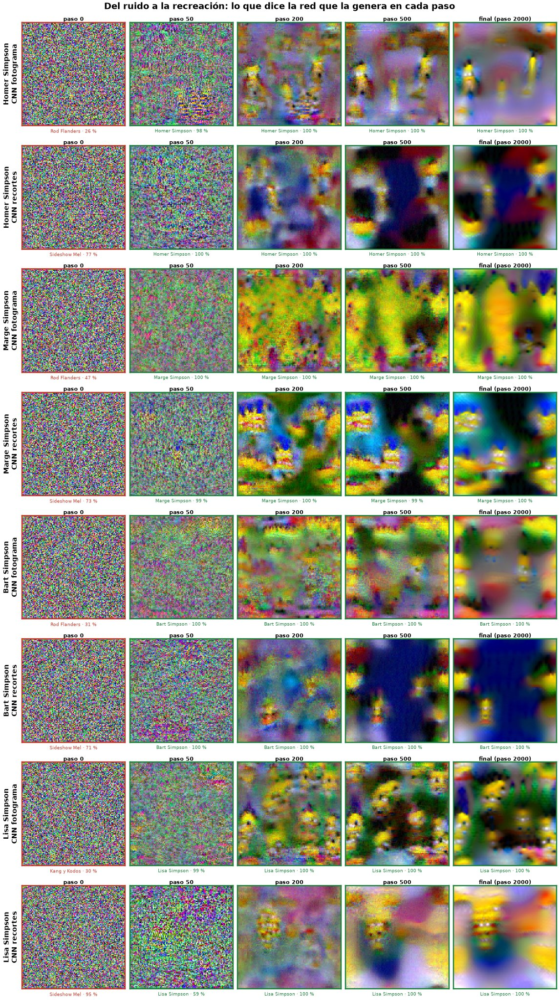

In [78]:
# Recreación de cada personaje solo desde los modelos guardados (DeepInversion), sin leer el dataset y sin
# reentrenar nada. Celda autocontenida: no usa variables del notebook y se puede ejecutar sola.
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RAIZ_REPOSITORIO = next(
    (
        carpeta for carpeta in (Path.cwd(), *Path.cwd().parents)
        if (carpeta / "scripts" / "newDataset" / "recrear_personajes.py").is_file()
    ),
    None,
)
# La recreación necesita el repositorio completo (en Colab puede no estar) y un modelo con BatchNormalization:
# DeepInversion iguala las estadísticas que guardan esas capas
ruta_metadatos_recreacion = Path("../models_gpu/newDataset/cnn_final.json")
con_batchnorm = (
    json.loads(ruta_metadatos_recreacion.read_text(encoding="utf-8")).get("normalizacion", True)
    if ruta_metadatos_recreacion.is_file()
    else True
)
if RAIZ_REPOSITORIO is None:
    print("No se encontró scripts/newDataset/recrear_personajes.py en esta carpeta ni en sus padres: se omite la recreación.")
elif not con_batchnorm:
    print("El modelo final no tiene capas BatchNormalization: DeepInversion no tiene estadísticas que igualar.")
else:
    if str(RAIZ_REPOSITORIO / "scripts" / "newDataset") not in sys.path:
        sys.path.insert(0, str(RAIZ_REPOSITORIO / "scripts" / "newDataset"))
    import recrear_personajes

    # Solo las dos CNN generan imágenes: este notebook no recrea con el modelo del MLP, que tiene su propia sección en
    # el notebook del MLP. El MLP de píxeles, si está en disco, solo juzga lo que generaron las CNN. Avisa de los
    # modelos que falten. Con la semilla fija, cada recreación sale de la caché si ya se calculó con todo igual
    recreacion = recrear_personajes.main(["--generadores", "cnn,cnn_recortes", "--semilla", "42"])

    nombres_redes = {red["id"]: red["nombre"] for red in recreacion["redes"]}
    matriz_recreacion = pd.DataFrame(
        [
            {
                "genera": nombres_redes[generador],
                "juzga": nombres_redes[juez],
                "prueba": "propia" if generador == juez else "cruzada",
                "top-1": f"{fila['top1']} de {fila['n']}",
                "top-3": f"{fila['top3']} de {fila['n']}",
                "probabilidad media del personaje": fila["confianza"],
            }
            for generador, jueces in recreacion["matriz"].items()
            for juez, fila in jueces.items()
        ]
    )
    display(matriz_recreacion)
    print(f"Al azar: top-1 de 1 en {round(1 / recreacion['azar'])} ({recreacion['azar']:.1%}).")
    for par in recreacion["correlaciones"]:
        print(
            f"Correlación de pesos entre {nombres_redes[par['a']]} y {nombres_redes[par['b']]}: {par['correlacion']:.3f}"
            + (" -> redes independientes" if par["independientes"]
               else " -> una salió de la otra: la prueba cruzada entre ellas no es independiente")
        )

    # Del ruido a la recreación: cuántas reconoce como su personaje la red que las genera en cada instantánea
    avance_recreacion = pd.DataFrame(
        [
            {
                "red": nombres_redes[generador],
                "paso": fila["paso"],
                "reconocidas": f"{fila['top1']} de {fila['n']}",
                "probabilidad media del personaje": fila["confianza"],
                "confianza media de su respuesta": fila["confianza_prediccion"],
                "personaje que más nombra": (
                    f"{fila['mas_nombrado']} ({fila['veces_mas_nombrado']} de {fila['n']})"
                    if fila["veces_mas_nombrado"] > 1 else "ninguno se repite"
                ),
            }
            for generador, filas in recreacion["instantaneas"].items()
            for fila in filas
        ]
    )
    display(avance_recreacion)



    def mostrar(ruta):
        """Muestra una figura del script en JPEG, a su resolución: el notebook pesa un tercio que con el PNG, que
        queda intacto en la carpeta de resultados."""
        import io

        from PIL import Image as ImagenPIL

        memoria = io.BytesIO()
        with ImagenPIL.open(ruta) as figura:
            figura.convert("RGB").save(memoria, "JPEG", quality=85, optimize=True)
        display(Image(data=memoria.getvalue(), format="jpeg"))


    # Las tres figuras son solo de las CNN y quedan en CNN/resultados/newDataset/recreaciones/
    mostrar(recreacion["salidas"]["cnn"]["lamina"])
    mostrar(recreacion["comparacion"])
    mostrar(recreacion["evolucion"])

**Lectura.** La red reconoce todo lo que generó, como era de esperar: 64 de 64, con una probabilidad media de
0,998 para el personaje. Lo interesante es cómo llega ahí, qué dibuja y qué dicen las otras redes.

- **Del ruido al personaje.** Con ruido puro (paso 0) la CNN responde con poca seguridad: a 44 de las 64 imágenes de
  ruido las llama Rod Flanders, con una confianza media de 0,34. A los 50 pasos ya nombra al personaje correcto en
  las 64, con 0,964, aunque a la vista la imagen sigue siendo ruido: la confianza sola no prueba que una imagen se
  parezca al personaje. Las formas aparecen después, cuando pesan los términos de BatchNorm y de suavidad.
- **Qué aprendió.** No aparecen caras completas ni el dibujo de un fotograma, sino dos cosas. La primera son
  **rasgos del personaje**: figuritas amarillas con ojos oscuros que se repiten por toda la imagen, lo que coincide
  con Grad-CAM, que muestra a la red apoyada sobre todo en la cabeza. La segunda es **un color de fondo** propio de
  cada uno: oscuro en Willie y en el capitán McCallister, rojo en el juez Snyder y en el Rico Texano. La red se
  entrenó con el fotograma completo y aprovecha también el escenario en que suele aparecer cada personaje.
- **Los rasgos se repiten.** Con pooling global, la cabeza densa recibe el promedio de cada filtro en todo el
  encuadre: la evidencia vale lo mismo en cualquier lugar, y la imagen que más la aumenta la repite varias veces.
- **La prueba cruzada entre las dos CNN es independiente, y la superan.** Los pesos de esta red y los de la CNN de
  recortes tienen una correlación de 0,136: la de recortes se afinó a partir del modelo final de la corrida del
  19-10-2026, y el de esta corrida se entrenó desde cero sobre el dataset ampliado. Aun así, la CNN de recortes
  nombra al personaje correcto en 54 de las 64 recreaciones de esta red (59 en el top-3, con una probabilidad media
  de 0,55), y esta, en 52 de las 64 de aquella (62 en el top-3): lo que una red dibuja de un personaje lo reconoce
  otra que nunca vio sus gradientes. Entre las que la CNN de recortes no reconoce están Rod y Todd Flanders, Louie y
  el Rico Texano, que también están entre los de peor F1 en test. El MLP de píxeles (R1), que no comparte ni la
  arquitectura y solo juzga, reconoce 2 de 64 (4 en el top-3, con una probabilidad media de 0,02), apenas por encima
  del azar: lo que la CNN aprendió de cada personaje no es lo que usa el MLP, que reconoce paletas de color en
  posiciones fijas.

## Anexo: corrida del 13-11-2026 frente a la del 19-10-2026

La CNN se ejecutó completa dos veces en la GPU a 128 × 128, en el mismo equipo (Intel Core i7-13620H y NVIDIA
GeForce RTX 4060 Laptop, conectado a la corriente) y con la imagen completa. Entre una y otra cambiaron cuatro cosas:
**el dataset**, ampliado de 40.123 a 56.676 originales (los fotogramas de episodio pasan del 44,7 % al 60,9 % de las
imágenes de trabajo y el desbalance baja de 33:1 a 21:1); **el criterio de acierto**, que en la del 19-10-2026
aceptaba además nombrar a otro personaje presente en la escena y ahora solo acepta el de la carpeta; **el
entrenamiento**, que ya no usa etiquetas de escena, por lo que desaparece el experimento S2; y **la experimentación**,
que suma cuatro experimentos de regularización (G1 a G4). Las cifras comparables entre las dos son las del criterio
de la carpeta. Las de la corrida anterior salen de la versión del 19-10-2026 de
`resultados/newDataset/GPU/rendimiento_gpu_128x128.json`, que queda en el historial de Git.

| | 19-10-2026 | 13-11-2026 |
|---|---:|---:|
| Imágenes originales | 40.123 | 56.676 |
| Imágenes de entrenamiento / validación / test | 35.023 / 10.080 / 5.063 | 49.625 / 14.172 / 7.058 |
| Pares de gemelas entre personajes | 3.326 | 6.222 |
| Configuraciones entrenadas | 12 | 16 |
| Configuración final | Base | G4 - aumento de datos en línea |
| Modelo base: épocas / mejor época | 60 / 53 | 52 / 40 |
| Modelo base: accuracy de entrenamiento / validación | 0,959 / 0,797 | 0,927 / 0,729 |
| F1 macro de validación del modelo final | 0,734 | 0,724 |
| Accuracy en test, criterio de la carpeta | 0,797 | 0,747 |
| F1 macro en test, criterio de la carpeta | 0,738 | 0,731 |
| Top-3 en test | 0,937 | 0,891 |
| ROC-AUC macro en test | no medida | 0,986 |
| Accuracy tolerante (19-10) / por escena (13-11) | 0,847 | 0,824 |
| Errores con confianza > 0,80 (criterio de cada corrida) | 41 | 104 |
| Personajes con F1 ≥ 0,60 / < 0,30 (criterio de cada corrida) | 62 / 0 | 51 / 0 |
| Correlación entre imágenes de entrenamiento y F1 | 0,39 | 0,21 |
| Carga de imágenes (min) | 10,5 | 11,5 |
| Entrenamiento total (min) | 290,5 | 522,2 |
| Segundos por época (benchmark) | 37,06 | 52,11 |
| Utilización media de la GPU | 98,8 % | 99,3 % |
| Duración de la corrida | 5 h 08 min 56 s | 9 h 11 min 40 s |

**Conclusiones**

1. **Un test más exigente, casi el mismo F1.** Con el criterio de la carpeta, la accuracy de test baja 5,0 puntos y
   el F1 macro solo 0,7. El test nuevo tiene más fotogramas de episodio, en los que el personaje comparte el plano
   con otros —en las imágenes con otro personaje presente la accuracy es de 0,507, frente a 0,822 en el resto—, y
   personajes secundarios con muchas más imágenes. El aumento en línea recupera buena parte de lo que se pierde: el
   modelo final de una corrida anterior sobre el mismo dataset, sin él, llegaba a 0,726 de accuracy y 0,706 de F1. El
   MLP, que se volvió a entrenar sobre el dataset ampliado, no baja: pasa de 0,539 a 0,544 de accuracy y de 0,490 a
   0,551 de F1 macro, así que la ventaja de la CNN se reduce de 26 a 20 puntos de accuracy y de 25 a 18 de F1 macro.
2. **El desbalance deja de ser el problema.** Con 21:1 en lugar de 33:1, los personajes más pequeños rinden bien
   (Maggie 0,90, Disco Stu 0,92) y la correlación entre imágenes de entrenamiento y F1 baja de 0,39 a 0,21. Los que
   más fallan ahora son los que se parecen a otro o salen siempre con él.
3. **La GPU sigue trabajando de verdad.** La tarjeta está ocupada el 99,3 % del tiempo, con unos 73 W, y el tiempo
   por imagen es el mismo de la corrida anterior (952 imágenes por segundo en el benchmark, frente a 945): la
   corrida dura 4 h más porque hay un 42 % más de imágenes y cinco configuraciones más.

## Referencias

**Dataset**

- Alfaro, A. (s. f.). *Los Simpson* [conjunto de datos]. Kaggle.
  https://www.kaggle.com/datasets/alfaro96/los-simpson. Es la base del dataset de este
  notebook, que el equipo amplió a 64 personajes.

**Artículos**

- LeCun, Y., Bottou, L., Bengio, Y. y Haffner, P. (1998). Gradient-based learning applied to document
  recognition. *Proceedings of the IEEE, 86*(11), 2278-2324. Las redes convolucionales con pesos compartidos
  y pooling.
- Ioffe, S. y Szegedy, C. (2015). Batch Normalization: Accelerating deep network training by reducing internal
  covariate shift. *ICML 2015*. https://arxiv.org/abs/1502.03167
- Simonyan, K. y Zisserman, A. (2015). Very deep convolutional networks for large-scale image recognition.
  *ICLR 2015*. https://arxiv.org/abs/1409.1556. Los bloques de convoluciones de 3 × 3 (experimento E2).
- Lin, M., Chen, Q. y Yan, S. (2014). Network in network. *ICLR 2014*. https://arxiv.org/abs/1312.4400. El
  pooling global como entrada de la cabeza clasificadora.
- Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D. y Batra, D. (2017). Grad-CAM: Visual
  explanations from deep networks via gradient-based localization. *ICCV 2017*. https://arxiv.org/abs/1610.02391
- Simonyan, K., Vedaldi, A. y Zisserman, A. (2014). Deep inside convolutional networks: Visualising image
  classification models and saliency maps. *ICLR 2014, Workshop Track*. https://arxiv.org/abs/1312.6034. Las
  imágenes que maximizan una clase y los mapas de saliencia.
- Yin, H., Molchanov, P., Alvarez, J. M., Li, Z., Mallya, A., Hoiem, D., Jha, N. K. y Kautz, J. (2020). Dreaming
  to distill: Data-free knowledge transfer via DeepInversion. *CVPR 2020*. https://arxiv.org/abs/1912.08795. La
  recreación de cada personaje desde las estadísticas de BatchNorm del modelo.

**Documentación de las librerías utilizadas**

- Keras — *Keras API reference*. https://keras.io/api/
- Keras — *Conv2D layer*. https://keras.io/api/layers/convolution_layers/convolution2d/
- Keras — *MaxPooling2D* y *GlobalAveragePooling2D*. https://keras.io/api/layers/pooling_layers/
- Keras — *BatchNormalization layer*. https://keras.io/api/layers/normalization_layers/batch_normalization/
- PyTorch — *Automatic differentiation package* (`torch.autograd`). https://pytorch.org/docs/stable/autograd.html
- scikit-learn — *Metrics and scoring*. https://scikit-learn.org/stable/modules/model_evaluation.html
- scikit-learn — `train_test_split`. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- scikit-learn — `compute_class_weight`. https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html
- SciPy — `scipy.signal.correlate2d`. https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.correlate2d.html
- NumPy — *NumPy documentation*. https://numpy.org/doc/stable/
- pandas — *pandas documentation*. https://pandas.pydata.org/docs/
- Matplotlib — *Matplotlib documentation*. https://matplotlib.org/stable/index.html
- seaborn — *seaborn documentation*. https://seaborn.pydata.org/
- Pillow — *Pillow (PIL Fork) documentation*. https://pillow.readthedocs.io/en/stable/
- joblib — *Embarrassingly parallel for loops*. https://joblib.readthedocs.io/en/stable/parallel.html

**Material del curso**

- Jerez Salazar, F. J. *1.1.1 El Perceptrón*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.2.1 Redes Fully Connected*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.2.2 Backpropagation*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.3.1 Descenso del Gradiente*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.3.2 Optimizadores*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.4.1 Diseño y Evaluación de Modelos*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.4.2 Implementación con Keras*. Machine Learning, TLY1102.